# DNRPA — Clasificación de Vehículos

## Data Science II — Machine Learning

Proyecto de clasificación binaria de registros vehiculares del DNRPA, con foco en distinguir entre las categorías `Privado` y `No_Privado`.

El proyecto aborda el ciclo completo de Machine Learning: definición del problema, auditoría de datos, análisis exploratorio, selección y transformación de variables, entrenamiento y optimización de modelos, evaluación con métricas adecuadas para clases desbalanceadas, explicabilidad con SHAP, análisis de errores, estudio de ablación y validación temporal.

### Alcance del proyecto

El análisis se realiza sobre vehículos con año de modelo **2016 en adelante**. Esta delimitación se adoptó también por **limitaciones de recursos computacionales**: trabajar con el volumen completo del dataset incrementaría considerablemente el consumo de memoria, almacenamiento y tiempo de procesamiento, especialmente durante el preprocesamiento, entrenamiento, optimización y cálculo de SHAP.

La selección de 2016 busca mantener un volumen de datos representativo y, al mismo tiempo, permitir que el proyecto sea ejecutable con los recursos disponibles. Por lo tanto, los resultados no deben extrapolarse automáticamente a vehículos anteriores a 2016.

La clase `No_Privado` presenta un fuerte desbalance, por lo que el análisis prioriza Precision, Recall, F1, ROC-AUC y PR-AUC en lugar de utilizar accuracy como única métrica.

# Roadmap del proyecto

1. Definición del problema
2. Carga y auditoría de los datos
3. Definición del alcance temporal
4. Limpieza y control de calidad
5. Análisis exploratorio de datos (EDA)
6. Construcción y análisis de la variable objetivo
7. Selección de variables
8. Ingeniería y preprocesamiento de características
9. Separación entrenamiento/prueba
10. Entrenamiento de modelos
11. Optimización de hiperparámetros
12. Validación cruzada y selección del threshold
13. Comparación de modelos
14. Selección del modelo principal
15. Explicabilidad con SHAP
16. Estudio de ablación
17. Análisis de errores
18. Validación temporal
19. Conclusiones, limitaciones y recomendaciones
20. Reproducibilidad y preparación para GitHub

# 1 — Importación de librerías

Se importan las librerías necesarias para la manipulación de datos, visualización, preprocesamiento, entrenamiento, evaluación y explicabilidad de los modelos.

A lo largo del notebook se mantiene el procesamiento dentro de Python y se priorizan herramientas reproducibles de `pandas`, `scikit-learn`, `XGBoost`, `LightGBM` y `SHAP`.

In [ ]:
# ============================================================
# 1 — Importación de librerías
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import os
import psutil

## 1.2 — Control de recursos computacionales

Se monitoriza el consumo de memoria durante el desarrollo debido al volumen del dataset y al costo computacional de algunas etapas del proyecto, especialmente el preprocesamiento, la vectorización, el entrenamiento de modelos y el cálculo de SHAP.

Este control también fundamenta la decisión de trabajar con vehículos modelo 2016 en adelante.

In [ ]:
# ============================================================
# 1.2 — Control de recursos computacionales
# ============================================================
def memory_usage():
    process = psutil.Process(os.getpid())
    ram_gb = process.memory_info().rss / (1024 ** 3)
    print(f"RAM utilizada por Python: {ram_gb:.2f} GB")

In [ ]:
memory_usage()

RAM utilizada por Python: 0.22 GB


# 2 — Carga del dataset

Se carga el archivo original del DNRPA que constituye la fuente de datos del proyecto. En esta etapa se conserva el dataset original sin transformaciones, para poder realizar posteriormente la auditoría, limpieza, análisis exploratorio y construcción del conjunto utilizado para Machine Learning.

In [ ]:
# ============================================================
# 2 — Carga del dataset original
# ============================================================
df = pd.read_csv("/content/dnrpa-transferencias-autos-202608.csv")
memory_usage()

RAM utilizada por Python: 0.30 GB


# 3 — Primera inspección

Se realiza una primera revisión de la estructura del dataset: dimensiones, registros iniciales, tipos de datos y consumo de memoria.

Esta inspección permite conocer el volumen y la estructura de la información antes de aplicar filtros o transformaciones.

In [ ]:
# ============================================================
# 3 — Primera inspección
# ============================================================
print("Dimensiones:")
print(df.shape)

Dimensiones:
(155246, 25)


In [ ]:
df.head()

,tramite_tipo,tramite_fecha,fecha_inscripcion_inicial,registro_seccional_codigo,registro_seccional_descripcion,registro_seccional_provincia,automotor_origen,automotor_anio_modelo,automotor_tipo_codigo,automotor_tipo_descripcion,...,automotor_uso_descripcion,titular_tipo_persona,titular_domicilio_localidad,titular_domicilio_provincia,titular_genero,titular_anio_nacimiento,titular_pais_nacimiento,titular_porcentaje_titularidad,titular_domicilio_provincia_id,titular_pais_nacimiento_id
0,TRANSFERENCIA IMPORTADO,2026-08-01,2013-03-04,1098,TRENQUE LAUQUEN Nº 1,Buenos Aires,Protocolo 21,2013.0,80,PICK-UP CABINA SIMPL,...,Privado,Jurídica,30 DE AGOSTO,BUENOS AIRES,No aplica,1981,No aplica,100.0,6,NaN
1,TRANSFERENCIA IMPORTADO,2026-08-01,2024-05-31,1098,TRENQUE LAUQUEN Nº 1,Buenos Aires,Protocolo 21,2024.0,82,PICK-UP CABINA DOBLE,...,Privado,Física,TRENQUE LAUQUEN,BUENOS AIRES,Masculino,1967,ARGENTINA,100.0,6,200.0
2,TRANSFERENCIA NACIONAL,2026-08-01,2000-04-06,1098,TRENQUE LAUQUEN Nº 1,Buenos Aires,Nacional,2000.0,22,FURGON,...,Privado,Física,TRENQUE LAUQUEN,BUENOS AIRES,Masculino,1988,ARGENTINA,100.0,6,200.0
3,TRANSFERENCIA NACIONAL,2026-08-01,2015-01-07,1098,TRENQUE LAUQUEN Nº 1,Buenos Aires,Nacional,2015.0,20,PICK-UP,...,Privado,Física,SANTA ROSA,BUENOS AIRES,Masculino,2003,ARGENTINA,100.0,6,200.0
4,TRANSFERENCIA IMPORTADO,2026-08-01,2019-02-04,1098,TRENQUE LAUQUEN Nº 1,Buenos Aires,Protocolo 21,2019.0,05,SEDAN 5 PUERTAS,...,Privado,Física,INTENDENTE ALVEAR,BUENOS AIRES,Masculino,1985,BOLIVIA,100.0,6,202.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155246 entries, 0 to 155245
Data columns (total 25 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   tramite_tipo                    155246 non-null  object 
 1   tramite_fecha                   155246 non-null  object 
 2   fecha_inscripcion_inicial       155246 non-null  object 
 3   registro_seccional_codigo       155246 non-null  int64  
 4   registro_seccional_descripcion  155246 non-null  object 
 5   registro_seccional_provincia    155246 non-null  object 
 6   automotor_origen                155246 non-null  object 
 7   automotor_anio_modelo           154492 non-null  float64
 8   automotor_tipo_codigo           151810 non-null  object 
 9   automotor_tipo_descripcion      155246 non-null  object 
 10  automotor_marca_codigo          154043 non-null  object 
 11  automotor_marca_descripcion     155246 non-null  object 
 12  automotor_modelo

In [ ]:
print("Memoria:")
print(
    f"{df.memory_usage(deep=True).sum() / (1024**2):.2f} MB"
)

Memoria:
177.45 MB


# 4 — Identificación de las variables

Se revisan las columnas y sus tipos de datos para distinguir variables numéricas, categóricas y temporales. Esta clasificación será utilizada posteriormente para definir el preprocesamiento y las estrategias de codificación.

In [ ]:
# ============================================================
# 4 — Identificación de las variables
# ============================================================
print(df.columns.tolist())

['tramite_tipo', 'tramite_fecha', 'fecha_inscripcion_inicial', 'registro_seccional_codigo', 'registro_seccional_descripcion', 'registro_seccional_provincia', 'automotor_origen', 'automotor_anio_modelo', 'automotor_tipo_codigo', 'automotor_tipo_descripcion', 'automotor_marca_codigo', 'automotor_marca_descripcion', 'automotor_modelo_codigo', 'automotor_modelo_descripcion', 'automotor_uso_codigo', 'automotor_uso_descripcion', 'titular_tipo_persona', 'titular_domicilio_localidad', 'titular_domicilio_provincia', 'titular_genero', 'titular_anio_nacimiento', 'titular_pais_nacimiento', 'titular_porcentaje_titularidad', 'titular_domicilio_provincia_id', 'titular_pais_nacimiento_id']


In [ ]:
print(df.dtypes)

tramite_tipo                       object
tramite_fecha                      object
fecha_inscripcion_inicial          object
registro_seccional_codigo           int64
registro_seccional_descripcion     object
registro_seccional_provincia       object
automotor_origen                   object
automotor_anio_modelo             float64
automotor_tipo_codigo              object
automotor_tipo_descripcion         object
automotor_marca_codigo             object
automotor_marca_descripcion        object
automotor_modelo_codigo            object
automotor_modelo_descripcion       object
automotor_uso_codigo              float64
automotor_uso_descripcion          object
titular_tipo_persona               object
titular_domicilio_localidad        object
titular_domicilio_provincia        object
titular_genero                     object
titular_anio_nacimiento            object
titular_pais_nacimiento            object
titular_porcentaje_titularidad    float64
titular_domicilio_provincia_id    

# 5 — Definición del alcance temporal — Vehículos modelo 2016 en adelante

Se establece como alcance del proyecto trabajar con vehículos cuyo `automotor_anio_modelo` sea mayor o igual a 2016.

La decisión responde tanto a criterios metodológicos como a las **limitaciones de recursos computacionales** disponibles. Procesar el dataset completo aumentaría el consumo de memoria, almacenamiento y tiempo de ejecución, especialmente durante la vectorización, entrenamiento, optimización de hiperparámetros y explicabilidad mediante SHAP.

El corte en 2016 permite mantener un volumen de datos suficientemente representativo y compatible con los recursos disponibles. Esta decisión constituye una limitación del estudio: las conclusiones se refieren al período analizado y no necesariamente a vehículos anteriores a 2016.

In [ ]:
# ============================================================
# 5 — Definición del alcance temporal
# ============================================================
df_ml = df[
    df["automotor_anio_modelo"] >= 2016
].copy()

In [ ]:
print("Dataset original:", df.shape)
print("Dataset ML:", df_ml.shape)

Dataset original: (155246, 25)
Dataset ML: (62312, 25)


In [ ]:
print(
    "Año mínimo:",
    df_ml["automotor_anio_modelo"].min()
)

print(
    "Año máximo:",
    df_ml["automotor_anio_modelo"].max()
)

Año mínimo: 2016.0
Año máximo: 2026.0


In [ ]:
print(
    df_ml["automotor_anio_modelo"]
    .value_counts()
    .sort_index()
)

automotor_anio_modelo
2016.0     8189
2017.0    10607
2018.0     9323
2019.0     5743
2020.0     4246
2021.0     4812
2022.0     5189
2023.0     5141
2024.0     3930
2025.0     3654
2026.0     1478
Name: count, dtype: int64


In [ ]:
print(df.shape)
df.head()
df.info()

(155246, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 155246 entries, 0 to 155245
Data columns (total 25 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   tramite_tipo                    155246 non-null  object 
 1   tramite_fecha                   155246 non-null  object 
 2   fecha_inscripcion_inicial       155246 non-null  object 
 3   registro_seccional_codigo       155246 non-null  int64  
 4   registro_seccional_descripcion  155246 non-null  object 
 5   registro_seccional_provincia    155246 non-null  object 
 6   automotor_origen                155246 non-null  object 
 7   automotor_anio_modelo           154492 non-null  float64
 8   automotor_tipo_codigo           151810 non-null  object 
 9   automotor_tipo_descripcion      155246 non-null  object 
 10  automotor_marca_codigo          154043 non-null  object 
 11  automotor_marca_descripcion     155246 non-null  object 
 12  aut

# 6 — Aplicación del filtro temporal

A partir del dataset original se construye el conjunto `df_ml`, aplicando el alcance definido previamente: vehículos modelo 2016 en adelante.

Este será el conjunto de referencia para las etapas posteriores de análisis y Machine Learning.

In [ ]:
# ============================================================
# 6 — Aplicación del filtro temporal
# ============================================================
df_ml = df.copy()

print("Dataset original:")
print(df.shape)

Dataset original:
(155246, 25)


## 6.2 — Aplicación del filtro

Se aplica el criterio temporal definido anteriormente sobre `automotor_anio_modelo`, conservando únicamente los registros correspondientes a vehículos modelo 2016 en adelante.

In [ ]:
# ============================================================
# 6.2 — Aplicación del filtro
# ============================================================
df_ml = df_ml[
    df_ml["automotor_anio_modelo"] >= 2016
].copy()

In [ ]:
print("Dataset después del filtro:")
print(df_ml.shape)

Dataset después del filtro:
(62312, 25)


In [ ]:
print("Año mínimo:", df_ml["automotor_anio_modelo"].min())
print("Año máximo:", df_ml["automotor_anio_modelo"].max())

Año mínimo: 2016.0
Año máximo: 2026.0


## 6.3 — Distribución de vehículos por año de modelo

Se revisa la cantidad de registros disponible para cada año de modelo con el objetivo de conocer la cobertura temporal del conjunto y detectar posibles concentraciones o períodos con baja representación.

In [ ]:
# ============================================================
# 6.3 — Distribución de vehiculos por año de modelo
# ============================================================
df_ml["automotor_anio_modelo"].value_counts().sort_index()

,count
automotor_anio_modelo,
2016.0,8189
2017.0,10607
2018.0,9323
2019.0,5743
2020.0,4246
2021.0,4812
2022.0,5189
2023.0,5141
2024.0,3930


# 7 — Validación del filtro temporal

Se verifica que no permanezcan registros con año de modelo anterior a 2016. Esta comprobación permite confirmar que el alcance temporal definido para el proyecto se aplicó correctamente.

In [ ]:
# ============================================================
# 7 — Validación del filtro temporal
# ============================================================
vehiculos_anteriores = (
    df_ml["automotor_anio_modelo"] < 2016
).sum()

print(
    "Vehículos anteriores a 2016:",
    vehiculos_anteriores
)

Vehículos anteriores a 2016: 0


# 8 — Auditoría de calidad

Antes de realizar el análisis exploratorio y el entrenamiento de modelos se evalúa la calidad estructural del conjunto de datos. Se revisan valores faltantes, duplicados, tipos de datos y consumo de memoria.

Estas comprobaciones permiten identificar problemas que puedan afectar las etapas posteriores.

## 8.1 — Valores nulos

Se cuantifican los valores faltantes y su proporción por variable. El objetivo es conocer su distribución y decidir posteriormente el tratamiento adecuado dentro del pipeline de preprocesamiento.

In [ ]:
# ============================================================
# 8.1 — Valores nulos
# ============================================================
nulls = (
    df_ml.isnull()
    .sum()
    .sort_values(ascending=False)
)

print(nulls)

titular_pais_nacimiento_id        6289
automotor_modelo_codigo             48
automotor_tipo_codigo               12
automotor_uso_codigo                 2
automotor_uso_descripcion            2
titular_domicilio_localidad          1
tramite_tipo                         0
registro_seccional_codigo            0
tramite_fecha                        0
automotor_anio_modelo                0
automotor_origen                     0
registro_seccional_provincia         0
registro_seccional_descripcion       0
fecha_inscripcion_inicial            0
automotor_marca_codigo               0
automotor_marca_descripcion          0
automotor_tipo_descripcion           0
titular_tipo_persona                 0
automotor_modelo_descripcion         0
titular_genero                       0
titular_domicilio_provincia          0
titular_anio_nacimiento              0
titular_pais_nacimiento              0
titular_porcentaje_titularidad       0
titular_domicilio_provincia_id       0
dtype: int64


In [ ]:
nulls_pct = (
    df_ml.isnull()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

null_report = pd.DataFrame({
    "Nulos": nulls,
    "Porcentaje": nulls_pct.round(2)
})

null_report

,Nulos,Porcentaje
titular_pais_nacimiento_id,6289,10.09
automotor_modelo_codigo,48,0.08
automotor_tipo_codigo,12,0.02
automotor_uso_codigo,2,0.00
automotor_uso_descripcion,2,0.00
titular_domicilio_localidad,1,0.00
tramite_tipo,0,0.00
registro_seccional_codigo,0,0.00
tramite_fecha,0,0.00
automotor_anio_modelo,0,0.00


## 8.2 — Duplicados

Se comprueba la existencia de registros completamente duplicados. En esta etapa se identifican y cuantifican; cualquier decisión sobre su eliminación debe considerar el significado de los registros y el contexto del dataset.

In [ ]:
# ============================================================
# 8.2 — Duplicados
# ============================================================
duplicados = df_ml.duplicated().sum()

print("Registros duplicados:", duplicados)

Registros duplicados: 154


## 8.3 — Tipos de datos

Se revisan los tipos de datos de las variables para identificar correctamente las variables numéricas, categóricas y temporales. Esta información será necesaria para definir el preprocesamiento y prestar especial atención a las variables categóricas de alta cardinalidad.

In [ ]:
# ============================================================
# 8.3 — Tipos de datos
# ============================================================
print(df_ml.dtypes)

tramite_tipo                       object
tramite_fecha                      object
fecha_inscripcion_inicial          object
registro_seccional_codigo           int64
registro_seccional_descripcion     object
registro_seccional_provincia       object
automotor_origen                   object
automotor_anio_modelo             float64
automotor_tipo_codigo              object
automotor_tipo_descripcion         object
automotor_marca_codigo             object
automotor_marca_descripcion        object
automotor_modelo_codigo            object
automotor_modelo_descripcion       object
automotor_uso_codigo              float64
automotor_uso_descripcion          object
titular_tipo_persona               object
titular_domicilio_localidad        object
titular_domicilio_provincia        object
titular_genero                     object
titular_anio_nacimiento            object
titular_pais_nacimiento            object
titular_porcentaje_titularidad    float64
titular_domicilio_provincia_id    

In [ ]:
df_ml.dtypes.value_counts()

,count
object,19
float64,4
int64,2


## 8.4 — Consumo de memoria

Se controla el consumo de memoria del conjunto de datos. Esta revisión es especialmente relevante debido al volumen de registros y a que las etapas posteriores de vectorización, entrenamiento y explicabilidad pueden incrementar considerablemente el uso de recursos.

In [ ]:
# ============================================================
# 8.4 — Consumo de memoria
# ============================================================
memoria_mb = (
    df_ml.memory_usage(deep=True)
    .sum() / (1024 ** 2)
)

print(f"Memoria utilizada por df_ml: {memoria_mb:.2f} MB")

Memoria utilizada por df_ml: 73.94 MB


In [ ]:
memory_usage()

RAM utilizada por Python: 0.32 GB


# 9 — Estadística básica

Esta etapa resume las principales características del conjunto de datos utilizado para el análisis. Se revisan las variables numéricas y categóricas antes de avanzar hacia la modelización.

El objetivo es detectar rangos, dispersión, cardinalidades y posibles inconsistencias que puedan afectar las etapas posteriores.


## 9.1 — Estadística descriptiva de las variables numéricas

Se resumen las variables numéricas mediante medidas como cantidad de observaciones, media, desviación estándar, mínimos, máximos y percentiles.

Esta revisión permite identificar escalas diferentes, valores extremos y posibles valores que requieran tratamiento durante el preprocesamiento.


In [ ]:
# ============================================================
# 9.1 — Estadística descriptiva de las variables numéricas
# ============================================================
df_ml.describe().T

,count,mean,std,min,25%,50%,75%,max
registro_seccional_codigo,62312.0,7690.611519,7581.811129,1001.0,1257.0,4044.0,14008.0,24008.0
automotor_anio_modelo,62312.0,2019.751332,2.957287,2016.0,2017.0,2019.0,2022.0,2026.0
automotor_uso_codigo,62310.0,1.003065,0.063899,0.0,1.0,1.0,1.0,2.0
titular_porcentaje_titularidad,62312.0,96.904217,12.147884,1.0,100.0,100.0,100.0,100.0
titular_domicilio_provincia_id,62312.0,29.219476,29.890321,2.0,6.0,14.0,54.0,94.0
titular_pais_nacimiento_id,56023.0,200.554933,10.377394,102.0,200.0,200.0,200.0,501.0


## 9.2 — Estadística descriptiva de las variables categóricas

Se inspeccionan las variables categóricas considerando cantidad de valores únicos y categorías observadas.

La cardinalidad es especialmente relevante en este proyecto porque algunas variables contienen miles de categorías y requieren un tratamiento específico antes del entrenamiento.


In [ ]:
# ============================================================
# 9.2 — Estadística descriptiva de las variables categóricas
# ============================================================
df_ml.describe(include="object").T

,count,unique,top,freq
tramite_tipo,62312,21,TRANSFERENCIA IMPORTADO,25506
tramite_fecha,62312,26,2026-08-20,3390
fecha_inscripcion_inicial,62312,2593,2017-06-30,106
registro_seccional_descripcion,62312,830,CORDOBA Nº 03,403
registro_seccional_provincia,62312,24,Buenos Aires,19189
automotor_origen,62312,3,Protocolo 21,29864
automotor_tipo_codigo,62300,51,05,16098
automotor_tipo_descripcion,62312,158,SEDAN 5 PUERTAS,22735
automotor_marca_codigo,62312,156,136,5752
automotor_marca_descripcion,62312,144,VOLKSWAGEN,9771


In [ ]:
df_ml.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tramite_tipo,62312,21,TRANSFERENCIA IMPORTADO,25506,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tramite_fecha,62312,26,2026-08-20,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_inscripcion_inicial,62312,2593,2017-06-30,106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registro_seccional_codigo,62312.0,NaN,NaN,NaN,7690.611519,7581.811129,1001.0,1257.0,4044.0,14008.0,24008.0
registro_seccional_descripcion,62312,830,CORDOBA Nº 03,403,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registro_seccional_provincia,62312,24,Buenos Aires,19189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
automotor_origen,62312,3,Protocolo 21,29864,NaN,NaN,NaN,NaN,NaN,NaN,NaN
automotor_anio_modelo,62312.0,NaN,NaN,NaN,2019.751332,2.957287,2016.0,2017.0,2019.0,2022.0,2026.0
automotor_tipo_codigo,62300,51,05,16098,NaN,NaN,NaN,NaN,NaN,NaN,NaN
automotor_tipo_descripcion,62312,158,SEDAN 5 PUERTAS,22735,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 10 — Primer vistazo al problema

Antes de entrenar modelos es necesario conocer la distribución de la variable objetivo y comprobar si las clases se encuentran equilibradas.

Esta revisión es fundamental para definir las métricas de evaluación y la estrategia de entrenamiento.


In [ ]:
# ============================================================
# 10 — Primer vistazo al problema
# ============================================================
print(
    df_ml["automotor_uso_descripcion"]
    .value_counts(dropna=False)
)

automotor_uso_descripcion
Privado    62055
Público      223
Oficial       32
NaN            2
Name: count, dtype: int64


## 10.1 — Distribución porcentual de la variable objetivo

La variable objetivo presenta un desbalance extremo entre `Privado` y `No_Privado`.

Por este motivo, la accuracy por sí sola puede resultar engañosa. A lo largo del proyecto se priorizan Precision, Recall, F1, ROC-AUC y especialmente PR-AUC para evaluar el comportamiento sobre la clase minoritaria.


In [ ]:
# ============================================================
# 10.1 — Distribución porcentual de la variable objetivo
# ============================================================
print(
    df_ml["automotor_uso_descripcion"]
    .value_counts(
        normalize=True,
        dropna=False
    ).mul(100).round(2)
)

automotor_uso_descripcion
Privado    99.59
Público     0.36
Oficial     0.05
NaN         0.00
Name: proportion, dtype: float64


In [ ]:
df_ml.shape

(62312, 25)

## 10.2 — Control de consistencia

Se realizan comprobaciones sobre el período temporal, la distribución del target y otras variables relevantes para verificar que el conjunto filtrado mantiene la estructura esperada antes de continuar con el modelado.


In [ ]:
# ============================================================
# 10.2 — Control de consistencia
# ============================================================
print("Año mínimo:", df_ml["automotor_anio_modelo"].min())
print("Año máximo:", df_ml["automotor_anio_modelo"].max())

Año mínimo: 2016.0
Año máximo: 2026.0


In [ ]:
df_ml["automotor_anio_modelo"].value_counts().sort_index()

,count
automotor_anio_modelo,
2016.0,8189
2017.0,10607
2018.0,9323
2019.0,5743
2020.0,4246
2021.0,4812
2022.0,5189
2023.0,5141
2024.0,3930


In [ ]:
null_report = pd.DataFrame({
    "Nulos": df_ml.isnull().sum(),
    "Porcentaje": (
        df_ml.isnull()
        .mean()
        .mul(100)
        .round(2)
    )
}).sort_values("Porcentaje", ascending=False)

null_report

,Nulos,Porcentaje
titular_pais_nacimiento_id,6289,10.09
automotor_modelo_codigo,48,0.08
automotor_tipo_codigo,12,0.02
tramite_tipo,0,0.00
tramite_fecha,0,0.00
registro_seccional_descripcion,0,0.00
registro_seccional_provincia,0,0.00
registro_seccional_codigo,0,0.00
fecha_inscripcion_inicial,0,0.00
automotor_anio_modelo,0,0.00


In [ ]:
df_ml["automotor_uso_descripcion"].value_counts(dropna=False)

,count
automotor_uso_descripcion,
Privado,62055
Público,223
Oficial,32
NaN,2


In [ ]:
memory_usage()

RAM utilizada por Python: 0.32 GB


## 10.3 — Revisión detallada de valores nulos

Se cuantifican los valores faltantes por variable y su proporción respecto del total de registros.

El objetivo en esta etapa es identificar dónde existen datos faltantes; el tratamiento concreto se define posteriormente dentro del pipeline de preprocesamiento para evitar inconsistencias entre entrenamiento y prueba.


In [ ]:
# ============================================================
# 10.3 — Revisión detallada de valores nulos
# ============================================================
null_report = pd.DataFrame({
    "Nulos": df_ml.isnull().sum(),
    "Porcentaje": (
        df_ml.isnull()
        .mean()
        .mul(100)
        .round(2)
    )
}).sort_values("Porcentaje", ascending=False)

null_report

,Nulos,Porcentaje
titular_pais_nacimiento_id,6289,10.09
automotor_modelo_codigo,48,0.08
automotor_tipo_codigo,12,0.02
tramite_tipo,0,0.00
tramite_fecha,0,0.00
registro_seccional_descripcion,0,0.00
registro_seccional_provincia,0,0.00
registro_seccional_codigo,0,0.00
fecha_inscripcion_inicial,0,0.00
automotor_anio_modelo,0,0.00


## 10.4 — Revisión de registros duplicados

Se comprueba la existencia de registros completamente duplicados.

La detección se realiza antes del modelado para determinar si existen duplicaciones que puedan afectar el análisis. La decisión sobre su tratamiento debe considerar el significado de cada registro y no asumir automáticamente que todo duplicado es un error.


In [ ]:
# ============================================================
# 10.4 — Revisión de registros duplicados
# ============================================================
duplicados = df_ml.duplicated().sum()

print(f"Registros duplicados: {duplicados}")

Registros duplicados: 154


In [ ]:
print(
    f"Porcentaje de duplicados: "
    f"{duplicados / len(df_ml) * 100:.2f}%"
)

Porcentaje de duplicados: 0.25%


## 10.5 — Tipos de datos de las variables

Se revisan los tipos de datos para distinguir variables numéricas, categóricas y temporales.

Esta clasificación será utilizada posteriormente para definir transformaciones específicas dentro del pipeline de Machine Learning.


In [ ]:
# ============================================================
# 10.5 — Tipos de datos de las variables
# ============================================================
df_ml.dtypes

,0
tramite_tipo,object
tramite_fecha,object
fecha_inscripcion_inicial,object
registro_seccional_codigo,int64
registro_seccional_descripcion,object
registro_seccional_provincia,object
automotor_origen,object
automotor_anio_modelo,float64
automotor_tipo_codigo,object
automotor_tipo_descripcion,object


## 10.6 — Clasificación de las variables

Las variables se agrupan según su naturaleza para facilitar el diseño del preprocesamiento.

Se presta especial atención a las variables categóricas de alta cardinalidad, ya que una codificación directa puede producir matrices de gran dimensionalidad.


In [ ]:
# ============================================================
# 10.6 — Clasificación de las variables
# ============================================================
print("Numéricas:")
print(
    df_ml.select_dtypes(
        include=np.number
    ).columns.tolist()
)

print("\nCategóricas:")
print(
    df_ml.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)

Numéricas:
['registro_seccional_codigo', 'automotor_anio_modelo', 'automotor_uso_codigo', 'titular_porcentaje_titularidad', 'titular_domicilio_provincia_id', 'titular_pais_nacimiento_id']

Categóricas:
['tramite_tipo', 'tramite_fecha', 'fecha_inscripcion_inicial', 'registro_seccional_descripcion', 'registro_seccional_provincia', 'automotor_origen', 'automotor_tipo_codigo', 'automotor_tipo_descripcion', 'automotor_marca_codigo', 'automotor_marca_descripcion', 'automotor_modelo_codigo', 'automotor_modelo_descripcion', 'automotor_uso_descripcion', 'titular_tipo_persona', 'titular_domicilio_localidad', 'titular_domicilio_provincia', 'titular_genero', 'titular_anio_nacimiento', 'titular_pais_nacimiento']


## 10.7 — Análisis de la estructura temporal

Se analiza la distribución temporal disponible en el conjunto de datos, principalmente mediante el año de modelo y las variables relacionadas con inscripción y trámite.

Este análisis permite conocer la cobertura temporal y posteriormente evaluar si el modelo mantiene su comportamiento cuando cambia el período de referencia.


In [ ]:
# ============================================================
# 10.7 — Análisis de la estructura temporal
# ============================================================
target_counts = (
    df_ml["automotor_uso_descripcion"]
    .value_counts(dropna=False)
)

target_counts

,count
automotor_uso_descripcion,
Privado,62055
Público,223
Oficial,32
NaN,2


In [ ]:
target_pct = (
    df_ml["automotor_uso_descripcion"]
    .value_counts(
        normalize=True,
        dropna=False
    )
    .mul(100)
    .round(2)
)

target_pct

,proportion
automotor_uso_descripcion,
Privado,99.59
Público,0.36
Oficial,0.05
NaN,0.00


In [ ]:
target_report = pd.DataFrame({
    "Cantidad": target_counts,
    "Porcentaje": target_pct
})

target_report

,Cantidad,Porcentaje
automotor_uso_descripcion,,
Privado,62055,99.59
Público,223,0.36
Oficial,32,0.05
NaN,2,0.00


In [ ]:
null_report

,Nulos,Porcentaje
titular_pais_nacimiento_id,6289,10.09
automotor_modelo_codigo,48,0.08
automotor_tipo_codigo,12,0.02
tramite_tipo,0,0.00
tramite_fecha,0,0.00
registro_seccional_descripcion,0,0.00
registro_seccional_provincia,0,0.00
registro_seccional_codigo,0,0.00
fecha_inscripcion_inicial,0,0.00
automotor_anio_modelo,0,0.00


# 11 — Distribución por año de modelo

Se estudia la cantidad de vehículos por año de modelo para conocer la cobertura temporal del dataset y detectar posibles concentraciones de registros.

Esta información también será utilizada posteriormente para la validación temporal del modelo.


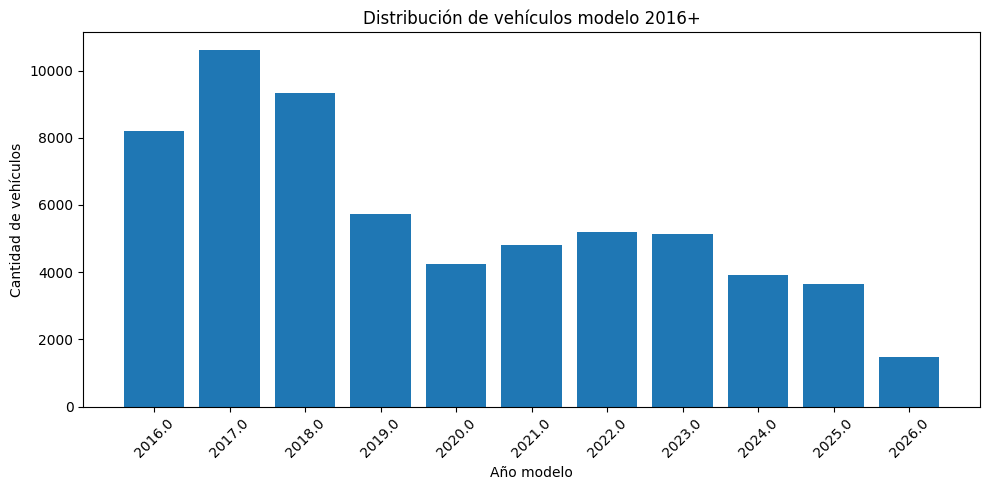

In [ ]:
# ============================================================
# 11 — Distribución por año de modelo
# ============================================================
year_counts = (
    df_ml["automotor_anio_modelo"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

plt.bar(
    year_counts.index.astype(str),
    year_counts.values
)

plt.xlabel("Año modelo")
plt.ylabel("Cantidad de vehículos")
plt.title("Distribución de vehículos modelo 2016+")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 11.1 — Revisión de identificadores geográficos

Se inspeccionan las variables relacionadas con provincia y localidad para conocer su diversidad y detectar variables categóricas con elevada cardinalidad.

Estas variables pueden aportar información predictiva, pero requieren un tratamiento cuidadoso para controlar la dimensionalidad.


In [ ]:
# ============================================================
# 11.1 — Revisión de identificadores geográficos
# ============================================================
print(
    df_ml[
        df_ml["titular_pais_nacimiento_id"].isna()
    ][
        [
            "titular_pais_nacimiento",
            "titular_pais_nacimiento_id"
        ]
    ]
)

       titular_pais_nacimiento  titular_pais_nacimiento_id
57                   No aplica                         NaN
67                   No aplica                         NaN
79                   No aplica                         NaN
89                   No aplica                         NaN
127                  No aplica                         NaN
...                        ...                         ...
155194               No aplica                         NaN
155208               No aplica                         NaN
155209               No aplica                         NaN
155224               No aplica                         NaN
155225               No aplica                         NaN

[6289 rows x 2 columns]


## 11.2 — Comparación de códigos y descripciones

Se comparan las variables que representan códigos con sus correspondientes descripciones cuando están disponibles.

La selección posterior busca evitar información redundante y conservar las representaciones que resulten más adecuadas para el modelado.


## 11.3 — Registros sin variable objetivo

Se verifica que la variable objetivo esté disponible para los registros utilizados en Machine Learning.

Los registros sin target no pueden utilizarse directamente para aprendizaje supervisado y deben ser identificados antes de construir `X` e `y`.


In [ ]:
# ============================================================
# 11.3 — Registros sin variable objetivo
# ============================================================
df_ml[df_ml["automotor_uso_descripcion"].isna()]

,tramite_tipo,tramite_fecha,fecha_inscripcion_inicial,registro_seccional_codigo,registro_seccional_descripcion,registro_seccional_provincia,automotor_origen,automotor_anio_modelo,automotor_tipo_codigo,automotor_tipo_descripcion,...,automotor_uso_descripcion,titular_tipo_persona,titular_domicilio_localidad,titular_domicilio_provincia,titular_genero,titular_anio_nacimiento,titular_pais_nacimiento,titular_porcentaje_titularidad,titular_domicilio_provincia_id,titular_pais_nacimiento_id
44284,TRANSFERENCIA IMPORTADO,2026-08-10,2022-06-07,1162,OLAVARRIA Nº 2,Buenos Aires,Protocolo 21,2022.0,05,SEDAN 5 PUERTAS,...,NaN,Física,OLAVARRIA,BUENOS AIRES,Masculino,1999,ARGENTINA,100.0,6,200.0
54395,TRANSFERENCIA NACIONAL,2026-08-12,2026-08-12,3007,RECREO,Catamarca,Nacional,2024.0,31,SEMIRREMOLQUE,...,NaN,Jurídica,RECREO,CATAMARCA,No aplica,2011,No aplica,100.0,10,NaN


## 11.4 — Selección inicial de variables

A partir de la auditoría y del análisis exploratorio se identifican las variables candidatas para el modelo.

La selección considera relevancia analítica, disponibilidad, naturaleza de la variable y riesgo de redundancia. La utilidad de estas variables se contrasta posteriormente mediante los modelos, SHAP y el estudio de ablación.


## 11.5 — Inspección de variables codificadas

Se revisan las variables representadas mediante códigos para comprobar su contenido y cardinalidad antes de decidir su incorporación al conjunto definitivo de características.


In [ ]:
# ============================================================
# 11.5 — Inspección de variables codificadas
# ============================================================
for col in [
    "automotor_tipo_codigo",
    "automotor_marca_codigo",
    "automotor_modelo_codigo",
    "automotor_uso_codigo",
    "titular_domicilio_provincia_id",
    "titular_pais_nacimiento_id"
]:
    print(f"\n--- {col} ---")
    print("Únicos:", df_ml[col].nunique(dropna=True))
    print(df_ml[col].value_counts(dropna=False).head(10))


--- automotor_tipo_codigo ---
Únicos: 51
automotor_tipo_codigo
05    16098
20     8674
04     7558
17     6819
02     5858
12     4718
82     4146
22     2315
10     1611
14     1041
Name: count, dtype: int64

--- automotor_marca_codigo ---
Únicos: 156
automotor_marca_codigo
136    5752
130    5635
024    4842
047    4047
53     4019
044    3777
68     3648
112    3598
37     3230
34     3230
Name: count, dtype: int64

--- automotor_modelo_codigo ---
Únicos: 1706
automotor_modelo_codigo
577    723
CJ     706
CP     602
912    560
XH     438
A16    420
670    410
A85    397
908    385
A15    377
Name: count, dtype: int64

--- automotor_uso_codigo ---
Únicos: 3
automotor_uso_codigo
1.0    62055
2.0      223
0.0       32
NaN        2
Name: count, dtype: int64

--- titular_domicilio_provincia_id ---
Únicos: 24
titular_domicilio_provincia_id
6     19189
14     8194
2      7790
82     5926
50     2704
58     2106
30     1849
90     1772
18     1371
62     1323
Name: count, dtype: int64

---

In [ ]:
print(
    df_ml[
        df_ml["automotor_uso_descripcion"].isna()
    ].T
)

                                                  44284  \
tramite_tipo                    TRANSFERENCIA IMPORTADO   
tramite_fecha                                2026-08-10   
fecha_inscripcion_inicial                    2022-06-07   
registro_seccional_codigo                          1162   
registro_seccional_descripcion           OLAVARRIA Nº 2   
registro_seccional_provincia               Buenos Aires   
automotor_origen                           Protocolo 21   
automotor_anio_modelo                            2022.0   
automotor_tipo_codigo                                05   
automotor_tipo_descripcion              SEDAN 5 PUERTAS   
automotor_marca_codigo                              024   
automotor_marca_descripcion                   CHEVROLET   
automotor_modelo_codigo                             764   
automotor_modelo_descripcion       ONIX 1.0T AT PREMIER   
automotor_uso_codigo                                NaN   
automotor_uso_descripcion                           NaN 

# 12 — Análisis exploratorio de datos (EDA)

En esta etapa se estudia la distribución de las principales variables del conjunto 2016+ y su relación descriptiva con la variable objetivo.

El análisis incluye características del vehículo, ubicación, titular y dimensión temporal. Las diferencias observadas son exploratorias y no deben interpretarse como relaciones causales.


## 12.1 — Distribución por tipo de vehículo


In [ ]:
# ============================================================
# 12.1 — Distribución por tipo de vehículo
# ============================================================
tipo_vehiculos = (
    df_ml["automotor_tipo_descripcion"]
    .value_counts()
)

print(tipo_vehiculos.head(20))

automotor_tipo_descripcion
SEDAN 5 PUERTAS                 22735
SEDAN 4 PUERTAS                 10550
PICK-UP                          8674
RURAL 5 PUERTAS                  7556
PICK-UP CABINA DOBLE             4146
TODO TERRENO                     2211
FURGON                           2057
RURAL 4/5 PUERTAS                1010
SEDAN 3 PUERTAS                   474
FURGONETA                         441
SEMIRREMOLQUE                     291
PICK-UP CABINA SIMPLE             266
TRACTOR C/CABINA DORMITORIO       204
ACOPLADO                          192
CHASIS C/CABINA                   143
CHASIS CON CABINA                 133
TRANS.DE PASAJEROS                126
COUPE                             107
TRACTOR C/ CABINA DORMITORIO      106
PICK-UP CABINA Y MEDIA             82
Name: count, dtype: int64


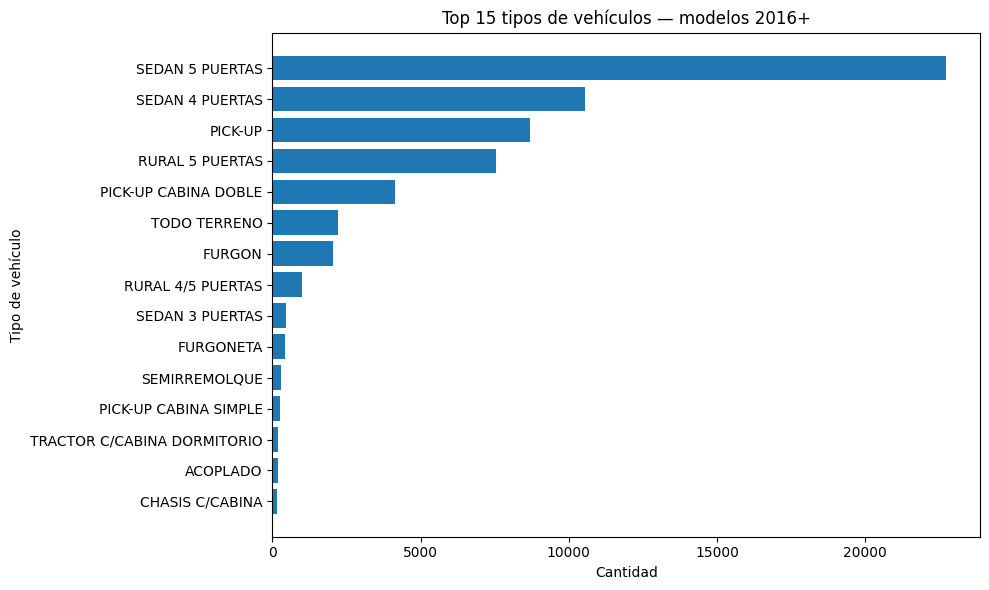

In [ ]:
top_tipos = tipo_vehiculos.head(15).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_tipos.index,
    top_tipos.values
)

plt.xlabel("Cantidad")
plt.ylabel("Tipo de vehículo")
plt.title("Top 15 tipos de vehículos — modelos 2016+")

plt.tight_layout()
plt.show()

## 12.2 — Distribución por marca


In [ ]:
# ============================================================
# 12.2 — Distribución por marca
# ============================================================
marcas = (
    df_ml["automotor_marca_descripcion"]
    .value_counts()
)

print(marcas.head(20))

automotor_marca_descripcion
VOLKSWAGEN       9771
TOYOTA           9283
FORD             7037
RENAULT          6827
CHEVROLET        6699
FIAT             6536
PEUGEOT          5275
CITROEN          2262
NISSAN           1987
JEEP             1582
MERCEDES BENZ     863
HONDA             814
CHERY             362
AUDI              341
BMW               294
RAM               272
IVECO             268
HYUNDAI           200
KIA               175
VOLVO             111
Name: count, dtype: int64


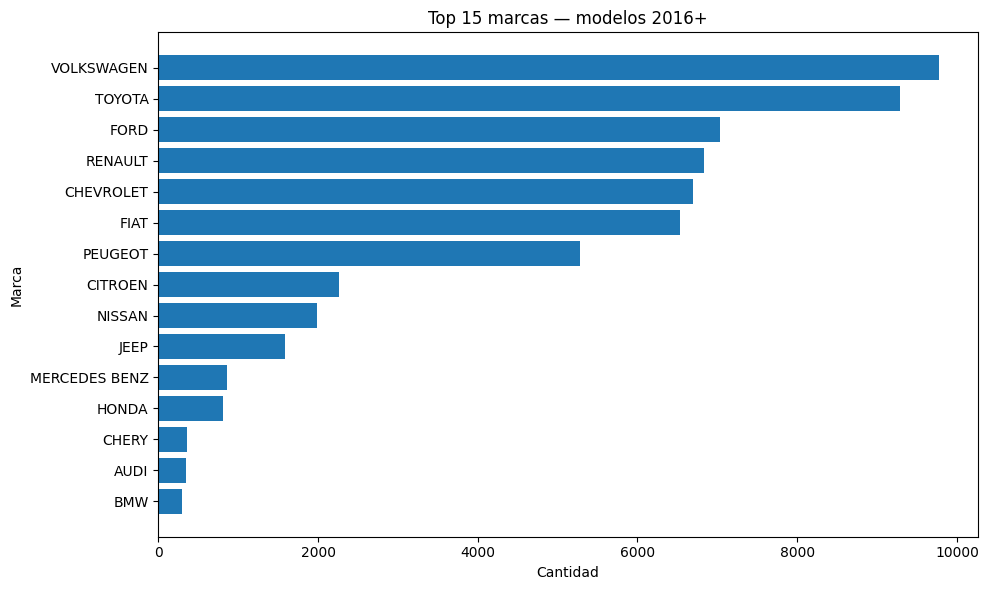

In [ ]:
top_marcas = marcas.head(15).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_marcas.index,
    top_marcas.values
)

plt.xlabel("Cantidad")
plt.ylabel("Marca")
plt.title("Top 15 marcas — modelos 2016+")

plt.tight_layout()
plt.show()

## 12.3 — Distribución por modelo


In [ ]:
# ============================================================
# 12.3 — Distribución por modelo
# ============================================================
modelos = (
    df_ml["automotor_modelo_descripcion"]
    .value_counts()
)

print("Cantidad de modelos únicos:", modelos.shape[0])
print(modelos.head(20))

Cantidad de modelos únicos: 3043
automotor_modelo_descripcion
CRONOS DRIVE 1.3 MT                     702
GOL TREND 1.6 MSI                       700
ETIOS XLS 1.5 6M/T                      559
CRONOS DRIVE 1.3 GSE BZ                 557
GOL TREND TRENDLINE 1.6 GAS 101CV MQ    410
ETIOS X 1.5 6M/T                        381
PALIO (326) ATTRACTIVE 5P 1.4 8V        361
ETIOS XLS 1.5 4A/T                      339
KA S 1.5L                               325
RENEGADE 1.8L SPORT                     313
ARGO DRIVE 1.3                          309
NUEVO FIORINO 1.4 8V                    297
ONIX 1.4 N LT                           293
YARIS S 1.5 CVT                         289
ONIX JOY 5P 1.4 N LS MT +               287
NUEVO SANDERO STEPWAY PRIVILEGE         285
MOBI 1.0 8V EASY                        284
KA SE 1.5L                              280
S10 2.8TD 4X2 LS                        275
FOCUS 5P 1.6L N MT S                    269
Name: count, dtype: int64


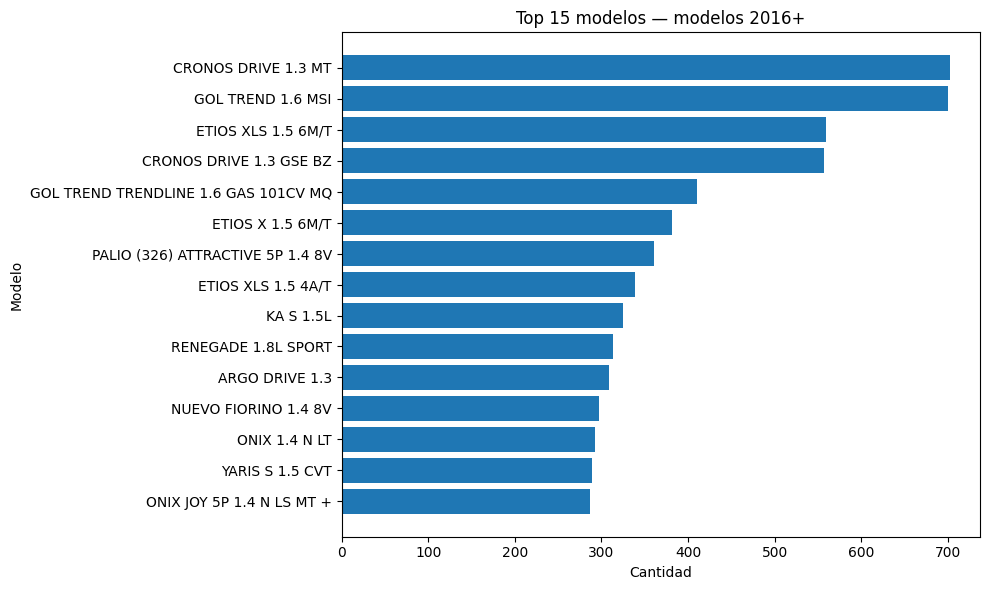

In [ ]:
top_modelos = modelos.head(15).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_modelos.index,
    top_modelos.values
)

plt.xlabel("Cantidad")
plt.ylabel("Modelo")
plt.title("Top 15 modelos — modelos 2016+")

plt.tight_layout()
plt.show()

## 12.4 — Distribución por provincia del registro


In [ ]:
# ============================================================
# 12.4 — Distribución por provincia del registro
# ============================================================
provincias = (
    df_ml["registro_seccional_provincia"]
    .value_counts()
)

print(provincias)

registro_seccional_provincia
Buenos Aires                       19189
Córdoba                             8194
Ciudad Autónoma de Buenos Aires     7790
Santa Fe                            5926
Mendoza                             2704
Neuquén                             2106
Entre Ríos                          1849
Tucumán                             1772
Corrientes                          1371
Río Negro                           1323
Chubut                              1232
Chaco                               1126
La Pampa                            1081
Salta                                972
Misiones                             883
San Juan                             836
San Luis                             694
Santiago del Estero                  616
Jujuy                                586
Formosa                              466
Santa Cruz                           455
Tierra del Fuego                     441
Catamarca                            383
La Rioja                    

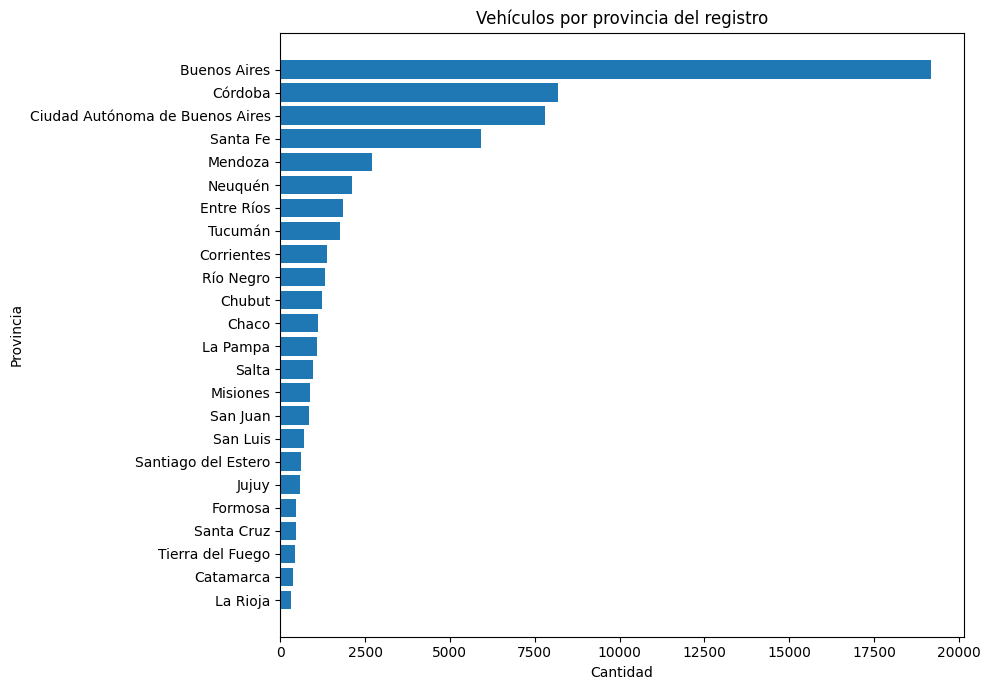

In [ ]:
prov_top = provincias.sort_values()

plt.figure(figsize=(10, 7))

plt.barh(
    prov_top.index,
    prov_top.values
)

plt.xlabel("Cantidad")
plt.ylabel("Provincia")
plt.title("Vehículos por provincia del registro")

plt.tight_layout()
plt.show()

## 12.5 — Distribución por año de modelo


In [ ]:
# ============================================================
# 12.5 — Distribución por año de modelo
# ============================================================
year_counts = (
    df_ml["automotor_anio_modelo"]
    .value_counts()
    .sort_index()
)

print(year_counts)

automotor_anio_modelo
2016.0     8189
2017.0    10607
2018.0     9323
2019.0     5743
2020.0     4246
2021.0     4812
2022.0     5189
2023.0     5141
2024.0     3930
2025.0     3654
2026.0     1478
Name: count, dtype: int64


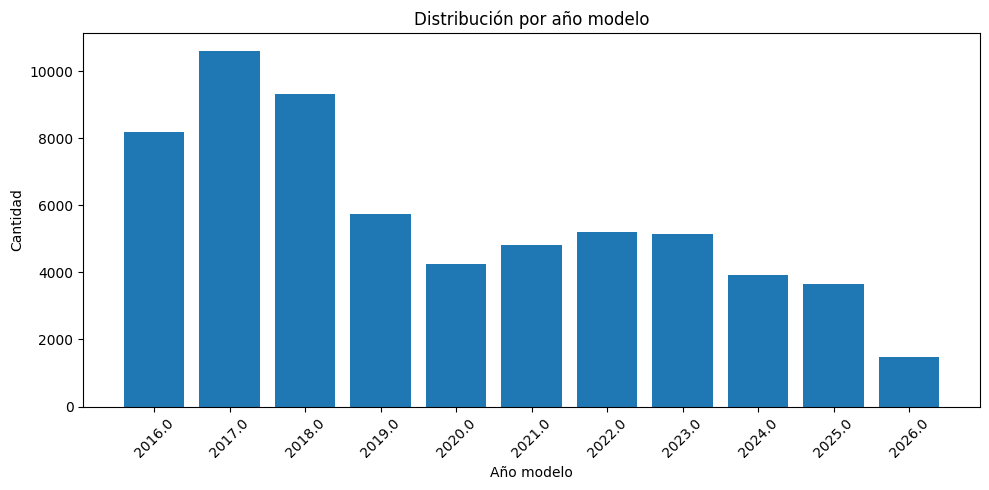

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    year_counts.index.astype(str),
    year_counts.values
)

plt.xlabel("Año modelo")
plt.ylabel("Cantidad")
plt.title("Distribución por año modelo")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 12.6 — Distribución de la antigüedad del vehículo


In [ ]:
# ============================================================
# 12.6 — Distribución de la antigüedad del vehículo
# ============================================================
df_ml["antiguedad_vehiculo"] = 2026 - df_ml["automotor_anio_modelo"]
df_ml["antiguedad_vehiculo"].describe()

,antiguedad_vehiculo
count,62312.000000
mean,6.248668
std,2.957287
min,0.000000
25%,4.000000
50%,7.000000
75%,9.000000
max,10.000000


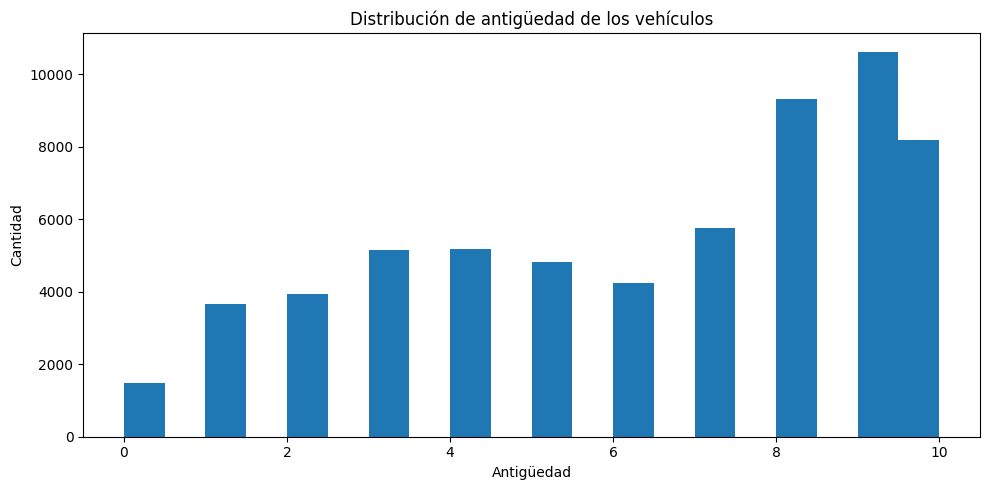

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_ml["antiguedad_vehiculo"].dropna(),
    bins=20
)

plt.xlabel("Antigüedad")
plt.ylabel("Cantidad")
plt.title("Distribución de antigüedad de los vehículos")

plt.tight_layout()
plt.show()

## 12.7 — Distribución por origen del vehículo


In [ ]:
# ============================================================
# 12.7 — Distribución por origen del vehículo
# ============================================================
origen = (
    df_ml["automotor_origen"]
    .value_counts()
)

print(origen)

automotor_origen
Protocolo 21    29864
Nacional        24619
Importado        7829
Name: count, dtype: int64


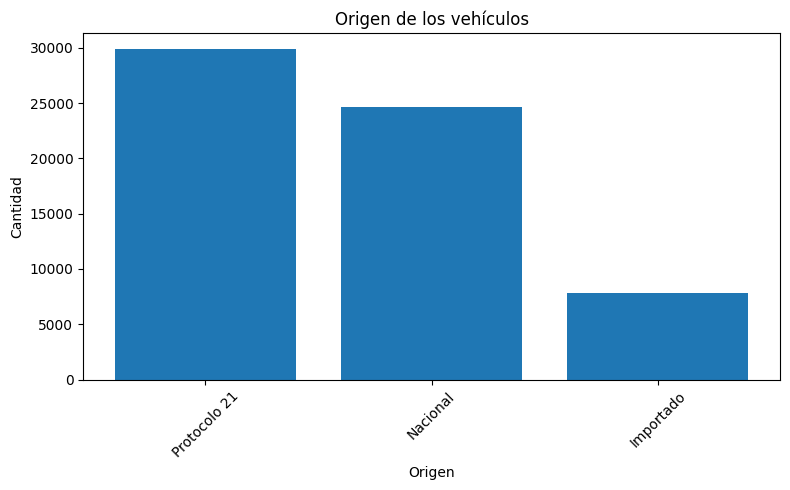

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    origen.index.astype(str),
    origen.values
)

plt.xlabel("Origen")
plt.ylabel("Cantidad")
plt.title("Origen de los vehículos")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 12.8 — Relación entre uso, marca y variable objetivo


In [ ]:
# ============================================================
# 12.8 — Relación entre uso, marca y variable objetivo
# ============================================================
marca_uso = pd.crosstab(
    df_ml["automotor_marca_descripcion"],
    df_ml["automotor_uso_descripcion"]
)

marca_uso.head()

automotor_uso_descripcion,Oficial,Privado,Público
automotor_marca_descripcion,,,
ACOPLANOA,0,2,0
AGRALE,0,12,19
AIELLO,1,7,1
AL TRAILERS,0,2,0
ALFA ROMEO,0,25,0


In [ ]:
top_15_marcas = (
    df_ml["automotor_marca_descripcion"]
    .value_counts()
    .head(15)
    .index
)

marca_uso_top = marca_uso.loc[top_15_marcas]

marca_uso_top

automotor_uso_descripcion,Oficial,Privado,Público
automotor_marca_descripcion,,,
VOLKSWAGEN,5,9756,10
TOYOTA,5,9272,6
FORD,3,7031,3
RENAULT,2,6794,31
CHEVROLET,0,6662,36
FIAT,2,6504,30
PEUGEOT,4,5269,2
CITROEN,4,2257,1
NISSAN,0,1983,4


## 12.9 — Resumen de las dimensiones exploradas

El EDA permite organizar las variables en cuatro grandes dimensiones:

- características del vehículo
- información del titular
- ubicación y registro
- dimensión temporal

Estas dimensiones orientan la selección de variables y los análisis posteriores.


## 12.10 — Relación entre uso y año de modelo


In [ ]:
# ============================================================
# 12.10 — Relación entre uso y año de modelo
# ============================================================
uso_por_anio = pd.crosstab(
    df_ml["automotor_anio_modelo"],
    df_ml["automotor_uso_descripcion"]
)

uso_por_anio

automotor_uso_descripcion,Oficial,Privado,Público
automotor_anio_modelo,,,
2016.0,1,8142,46
2017.0,7,10561,39
2018.0,3,9279,41
2019.0,5,5712,26
2020.0,1,4238,7
2021.0,6,4792,14
2022.0,3,5162,23
2023.0,5,5116,20
2024.0,0,3924,5


In [ ]:
uso_por_anio_pct = pd.crosstab(
    df_ml["automotor_anio_modelo"],
    df_ml["automotor_uso_descripcion"],
    normalize="index"
) * 100

uso_por_anio_pct.round(2)

automotor_uso_descripcion,Oficial,Privado,Público
automotor_anio_modelo,,,
2016.0,0.01,99.43,0.56
2017.0,0.07,99.57,0.37
2018.0,0.03,99.53,0.44
2019.0,0.09,99.46,0.45
2020.0,0.02,99.81,0.16
2021.0,0.12,99.58,0.29
2022.0,0.06,99.50,0.44
2023.0,0.10,99.51,0.39
2024.0,0.00,99.87,0.13


## 12.11 — Relación entre uso y provincia


In [ ]:
# ============================================================
# 12.11 — Relación entre uso y provincia
# ============================================================
uso_por_provincia = pd.crosstab(
    df_ml["registro_seccional_provincia"],
    df_ml["automotor_uso_descripcion"],
    normalize="index"
) * 100

uso_por_provincia.round(2)

automotor_uso_descripcion,Oficial,Privado,Público
registro_seccional_provincia,,,
Buenos Aires,0.06,99.66,0.28
Catamarca,0.26,99.74,0.00
Chaco,0.09,99.91,0.00
Chubut,0.00,99.92,0.08
Ciudad Autónoma de Buenos Aires,0.04,99.05,0.91
Corrientes,0.15,99.42,0.44
Córdoba,0.05,99.72,0.23
Entre Ríos,0.05,99.62,0.32
Formosa,0.00,100.00,0.00


## 12.12 — Relación entre uso y tipo de vehículo


In [ ]:
# ============================================================
# 12.12 — Relación entre uso y tipo de vehículo
# ============================================================
uso_por_tipo = pd.crosstab(
    df_ml["automotor_tipo_descripcion"],
    df_ml["automotor_uso_descripcion"],
    normalize="index"
) * 100

uso_por_tipo.sort_values(
    "Privado",
    ascending=True
).head(20).round(2)

automotor_uso_descripcion,Oficial,Privado,Público
automotor_tipo_descripcion,,,
CHASIS S/CABINA,100.00,0.00,0.00
MICROOMNIBUS,0.00,16.67,83.33
OMNIBUS,0.00,19.23,80.77
TRANSPORTE DE PASAJEROS,0.00,47.17,52.83
TRANS.DE PASAJEROS,0.00,86.51,13.49
MIDIBUS,0.00,87.23,12.77
AMBULANCIA,0.00,87.50,12.50
MINIBUS (O MICROOMNIBUS),0.00,93.18,6.82
FAMILIAR,4.65,95.35,0.00


In [ ]:
pd.crosstab(
    df_ml["automotor_uso_descripcion"],
    df_ml["automotor_uso_codigo"],
    normalize="index"
).round(3)

automotor_uso_codigo,0.0,1.0,2.0
automotor_uso_descripcion,,,
Oficial,1.0,0.0,0.0
Privado,0.0,1.0,0.0
Público,0.0,0.0,1.0


In [ ]:
pd.crosstab(
    df_ml["automotor_uso_codigo"],
    df_ml["automotor_uso_descripcion"]
)

automotor_uso_descripcion,Oficial,Privado,Público
automotor_uso_codigo,,,
0.0,32,0,0
1.0,0,62055,0
2.0,0,0,223


# 13 — Definición de la variable objetivo

La variable objetivo utilizada en el problema supervisado es `target`, con las clases `Privado` y `No_Privado`.

Se trata de una clasificación binaria con un fuerte desbalance de clases. Por este motivo, la evaluación se centra en métricas que permitan analizar específicamente la capacidad del modelo para detectar la clase minoritaria.


## 13.1 — Construcción de la variable objetivo

Se construye y verifica la variable `target` a partir de la información disponible en el dataset.

Antes de continuar se comprueba que las categorías sean las esperadas y que no existan valores faltantes en el target utilizado para el aprendizaje supervisado.


In [ ]:
# ============================================================
# 13.1 — Construcción de la variable objetivo
# ============================================================
df_ml["target"] = np.where(
    df_ml["automotor_uso_descripcion"] == "Privado",
    "Privado",
    "No_Privado"
)

In [ ]:
# Eliminar registros sin variable objetivo
df_ml = df_ml.dropna(
    subset=["automotor_uso_descripcion"]
).copy()

# Crear target binario
df_ml["target"] = np.where(
    df_ml["automotor_uso_descripcion"] == "Privado",
    "Privado",
    "No_Privado"
)

# Comprobar distribución
df_ml["target"].value_counts()

,count
target,
Privado,62055
No_Privado,255


In [ ]:
df_ml["target"].value_counts(normalize=True).mul(100).round(4)

,proportion
target,
Privado,99.5908
No_Privado,0.4092


# 14 — Selección de variables

La selección de características se realiza después de la auditoría y del EDA.

Se busca conservar variables con potencial predictivo y evitar identificadores o representaciones redundantes que no aporten información útil al modelo.

La selección definitiva se valida posteriormente mediante el comportamiento de los modelos, explicabilidad SHAP y ablación de grupos de variables.


In [ ]:
# ============================================================
# 14 — Selección de variables
# ============================================================
df_ml.columns.tolist()

['tramite_tipo',
 'tramite_fecha',
 'fecha_inscripcion_inicial',
 'registro_seccional_codigo',
 'registro_seccional_descripcion',
 'registro_seccional_provincia',
 'automotor_origen',
 'automotor_anio_modelo',
 'automotor_tipo_codigo',
 'automotor_tipo_descripcion',
 'automotor_marca_codigo',
 'automotor_marca_descripcion',
 'automotor_modelo_codigo',
 'automotor_modelo_descripcion',
 'automotor_uso_codigo',
 'automotor_uso_descripcion',
 'titular_tipo_persona',
 'titular_domicilio_localidad',
 'titular_domicilio_provincia',
 'titular_genero',
 'titular_anio_nacimiento',
 'titular_pais_nacimiento',
 'titular_porcentaje_titularidad',
 'titular_domicilio_provincia_id',
 'titular_pais_nacimiento_id',
 'antiguedad_vehiculo',
 'target']

In [ ]:
df_ml.shape

(62310, 27)

## 14.1 — Auditoría de cardinalidad

Se calcula la cantidad de categorías distintas de las variables categóricas.

Este control es importante porque algunas variables presentan una cardinalidad elevada y una codificación One-Hot directa puede aumentar considerablemente la dimensionalidad de la matriz de características.


In [ ]:
# ============================================================
# 14.1 — Auditoría de cardinalidad
# ============================================================
categoricas = df_ml.select_dtypes(
    include=["object", "category"]
).columns

cardinalidad = (
    df_ml[categoricas]
    .nunique(dropna=False)
    .sort_values(ascending=False)
)

cardinalidad

,0
titular_domicilio_localidad,4215
automotor_modelo_descripcion,3043
fecha_inscripcion_inicial,2593
automotor_modelo_codigo,1707
registro_seccional_descripcion,830
automotor_tipo_descripcion,158
automotor_marca_codigo,156
automotor_marca_descripcion,144
titular_anio_nacimiento,109
automotor_tipo_codigo,52


In [ ]:
for col in categoricas:
    print(f"{col}: {df_ml[col].nunique(dropna=False)} valores únicos")

tramite_tipo: 21 valores únicos
tramite_fecha: 26 valores únicos
fecha_inscripcion_inicial: 2593 valores únicos
registro_seccional_descripcion: 830 valores únicos
registro_seccional_provincia: 24 valores únicos
automotor_origen: 3 valores únicos
automotor_tipo_codigo: 52 valores únicos
automotor_tipo_descripcion: 158 valores únicos
automotor_marca_codigo: 156 valores únicos
automotor_marca_descripcion: 144 valores únicos
automotor_modelo_codigo: 1707 valores únicos
automotor_modelo_descripcion: 3043 valores únicos
automotor_uso_descripcion: 3 valores únicos
titular_tipo_persona: 2 valores únicos
titular_domicilio_localidad: 4215 valores únicos
titular_domicilio_provincia: 24 valores únicos
titular_genero: 4 valores únicos
titular_anio_nacimiento: 109 valores únicos
titular_pais_nacimiento: 47 valores únicos
target: 2 valores únicos


Eliminar

In [ ]:
cols_drop = [
    "automotor_uso_codigo",              # leakage
    "automotor_uso_descripcion",         # origen del target
    "automotor_tipo_codigo",             # redundante
    "automotor_marca_codigo",            # redundante
    "registro_seccional_codigo",         # identificador
    "registro_seccional_descripcion",    # alta cardinalidad/redundancia
    "titular_domicilio_provincia_id",    # redundante
    "titular_pais_nacimiento_id",        # redundante
    "target"                             # será y
]

## 14.2 — Variables candidatas a features

Se enumeran las variables consideradas inicialmente para construir el conjunto de características.

La selección definitiva se realiza después de revisar su naturaleza, disponibilidad, cardinalidad y posible redundancia.




```
tramite_tipo
tramite_fecha
fecha_inscripcion_inicial
registro_seccional_provincia
automotor_origen
automotor_anio_modelo
automotor_tipo_descripcion
automotor_marca_descripcion
automotor_modelo_codigo
automotor_modelo_descripcion
titular_tipo_persona
titular_domicilio_localidad
titular_domicilio_provincia
titular_genero
titular_anio_nacimiento
titular_pais_nacimiento
titular_porcentaje_titularidad
antiguedad_vehiculo
```



In [ ]:
# ============================================================
# 14.2 — Primer vistazo al problema
# ============================================================
pd.crosstab(
    df_ml["tramite_tipo"],
    df_ml["target"],
    normalize="index"
).round(4)

target,No_Privado,Privado
tramite_tipo,,
TRANSFERENCIA IMPORTADO,0.0036,0.9964
TRANSFERENCIA IMPORTADO A COM. HAB C/PEDIDO.,0.0000,1.0000
TRANSFERENCIA IMPORTADO A COM. HAB.,0.0045,0.9955
TRANSFERENCIA IMPORTADO A COM. HAB. F17,0.0009,0.9991
TRANSFERENCIA IMPORTADO A COM. HAB. F17 C/PEDIDO.,0.0000,1.0000
TRANSFERENCIA IMPORTADO C/EXT. DE PRENDA,0.0000,1.0000
TRANSFERENCIA IMPORTADO C/EXT. DE PRENDA C/PEDIDO,0.0000,1.0000
TRANSFERENCIA IMPORTADO C/PEDIDO,0.0042,0.9958
TRANSFERENCIA IMPORTADO DE COM. HAB.,0.0004,0.9996


In [ ]:
pd.crosstab(
    df_ml["titular_tipo_persona"],
    df_ml["target"],
    normalize="index"
).round(4)

target,No_Privado,Privado
titular_tipo_persona,,
Física,0.0027,0.9973
Jurídica,0.0166,0.9834


In [ ]:
pd.crosstab(
    df_ml["automotor_origen"],
    df_ml["target"],
    normalize="index"
).round(4)

target,No_Privado,Privado
automotor_origen,,
Importado,0.0006,0.9994
Nacional,0.0052,0.9948
Protocolo 21,0.0041,0.9959


## 14.3 — Selección definitiva de features para la primera versión

Se define el conjunto de variables que será utilizado en la primera versión del modelo a partir de la revisión realizada durante el EDA y la auditoría de calidad.


In [ ]:
# ============================================================
# 14.3 — Selección definitiva de features para la primera versión
# ============================================================
features = [
    "tramite_tipo",
    "tramite_fecha",
    "fecha_inscripcion_inicial",
    "registro_seccional_provincia",
    "automotor_origen",
    "automotor_anio_modelo",
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_modelo_descripcion",
    "titular_tipo_persona",
    "titular_domicilio_localidad",
    "titular_domicilio_provincia",
    "titular_genero",
    "titular_anio_nacimiento",
    "titular_pais_nacimiento",
    "titular_porcentaje_titularidad",
    "antiguedad_vehiculo"
]

## 14.4 — Incorporación de variables temporales

Las variables temporales disponibles se incorporan como características separadas cuando representan información útil para el modelo, manteniendo una representación compatible con el preprocesamiento posterior.


In [ ]:
# ============================================================
# 14.4 — Incorporación de variables temporales
# ============================================================
df_ml[
    [
        "tramite_fecha",
        "fecha_inscripcion_inicial",
        "automotor_anio_modelo",
        "antiguedad_vehiculo"
    ]
].head(10)

,tramite_fecha,fecha_inscripcion_inicial,automotor_anio_modelo,antiguedad_vehiculo
1,2026-08-01,2024-05-31,2024.0,2.0
4,2026-08-01,2019-02-04,2019.0,7.0
6,2026-08-01,2020-11-16,2020.0,6.0
14,2026-08-01,2017-11-15,2017.0,9.0
15,2026-08-01,2022-07-28,2022.0,4.0
23,2026-08-01,2017-02-23,2017.0,9.0
26,2026-08-01,2018-03-26,2018.0,8.0
28,2026-08-01,2018-05-17,2018.0,8.0
33,2026-08-01,2016-07-20,2016.0,10.0
34,2026-08-01,2022-08-31,2022.0,4.0


In [ ]:
df_ml[
    [
        "tramite_fecha",
        "fecha_inscripcion_inicial",
        "automotor_anio_modelo",
        "antiguedad_vehiculo"
    ]
].dtypes

,0
tramite_fecha,object
fecha_inscripcion_inicial,object
automotor_anio_modelo,float64
antiguedad_vehiculo,float64


In [ ]:
# Copias para trabajar de forma segura
df_ml["tramite_fecha"] = pd.to_datetime(
    df_ml["tramite_fecha"],
    errors="coerce"
)

df_ml["fecha_inscripcion_inicial"] = pd.to_datetime(
    df_ml["fecha_inscripcion_inicial"],
    errors="coerce"
)

# Features temporales
df_ml["tramite_anio"] = df_ml["tramite_fecha"].dt.year
df_ml["tramite_mes"] = df_ml["tramite_fecha"].dt.month

df_ml["inscripcion_anio"] = df_ml["fecha_inscripcion_inicial"].dt.year
df_ml["inscripcion_mes"] = df_ml["fecha_inscripcion_inicial"].dt.month

In [ ]:
df_ml[
    [
        "tramite_fecha",
        "tramite_anio",
        "tramite_mes",
        "fecha_inscripcion_inicial",
        "inscripcion_anio",
        "inscripcion_mes"
    ]
].head()

,tramite_fecha,tramite_anio,tramite_mes,fecha_inscripcion_inicial,inscripcion_anio,inscripcion_mes
1,2026-08-01,2026,8,2024-05-31,2024,5
4,2026-08-01,2026,8,2019-02-04,2019,2
6,2026-08-01,2026,8,2020-11-16,2020,11
14,2026-08-01,2026,8,2017-11-15,2017,11
15,2026-08-01,2026,8,2022-07-28,2022,7


In [ ]:
df_ml[
    [
        "tramite_fecha",
        "fecha_inscripcion_inicial",
        "tramite_anio",
        "tramite_mes",
        "inscripcion_anio",
        "inscripcion_mes"
    ]
].isna().sum()

,0
tramite_fecha,0
fecha_inscripcion_inicial,0
tramite_anio,0
tramite_mes,0
inscripcion_anio,0
inscripcion_mes,0


## 14.5 — Última etapa de revisión

Antes de separar los datos en entrenamiento y prueba se realiza una última comprobación de las variables seleccionadas, sus tipos y posibles inconsistencias.


In [ ]:
# ============================================================
# 14.5 — Última etapa de revisión
# ============================================================
cols_drop = [
    "automotor_uso_codigo",
    "automotor_uso_descripcion",
    "automotor_tipo_codigo",
    "automotor_marca_codigo",
    "registro_seccional_codigo",
    "registro_seccional_descripcion",
    "titular_domicilio_provincia_id",
    "titular_pais_nacimiento_id",
    "tramite_fecha",
    "fecha_inscripcion_inicial",
    "target"
]

df_model = df_ml.drop(columns=cols_drop).copy()

df_model.shape

(62310, 20)

In [ ]:
df_model.columns.tolist()

['tramite_tipo',
 'registro_seccional_provincia',
 'automotor_origen',
 'automotor_anio_modelo',
 'automotor_tipo_descripcion',
 'automotor_marca_descripcion',
 'automotor_modelo_codigo',
 'automotor_modelo_descripcion',
 'titular_tipo_persona',
 'titular_domicilio_localidad',
 'titular_domicilio_provincia',
 'titular_genero',
 'titular_anio_nacimiento',
 'titular_pais_nacimiento',
 'titular_porcentaje_titularidad',
 'antiguedad_vehiculo',
 'tramite_anio',
 'tramite_mes',
 'inscripcion_anio',
 'inscripcion_mes']

In [ ]:
df_model.dtypes

,0
tramite_tipo,object
registro_seccional_provincia,object
automotor_origen,object
automotor_anio_modelo,float64
automotor_tipo_descripcion,object
automotor_marca_descripcion,object
automotor_modelo_codigo,object
automotor_modelo_descripcion,object
titular_tipo_persona,object
titular_domicilio_localidad,object


In [ ]:
df_model = df_model.drop(
    columns=["automotor_modelo_codigo"]
).copy()

titular_anio_nacimiento

Está como object, pero debería ser numérico.

Lo convertimos de forma segura:

In [ ]:
df_model["titular_anio_nacimiento"] = pd.to_numeric(
    df_model["titular_anio_nacimiento"],
    errors="coerce"
)

In [ ]:
df_model.dtypes

,0
tramite_tipo,object
registro_seccional_provincia,object
automotor_origen,object
automotor_anio_modelo,float64
automotor_tipo_descripcion,object
automotor_marca_descripcion,object
automotor_modelo_descripcion,object
titular_tipo_persona,object
titular_domicilio_localidad,object
titular_domicilio_provincia,object


In [ ]:
df_model.isna().sum().sort_values(ascending=False)

,0
titular_anio_nacimiento,7
titular_domicilio_localidad,1
tramite_tipo,0
automotor_origen,0
registro_seccional_provincia,0
automotor_marca_descripcion,0
automotor_anio_modelo,0
automotor_modelo_descripcion,0
titular_tipo_persona,0
titular_domicilio_provincia,0


# 15 — Separación de variables predictoras y variable objetivo

Se construyen `X` e `y` para separar las 19 variables predictoras de la variable objetivo `target`.

Esta separación permite aplicar posteriormente el particionado train/test y el preprocesamiento sin incorporar la variable objetivo entre las características.


In [ ]:
# ============================================================
# 15 — Separación de variables predictoras y variable objetivo
# ============================================================
X = df_model.copy()

y = df_ml["target"].copy()

print("X:", X.shape)
print("y:", y.shape)

X: (62310, 19)
y: (62310,)


comprobamos nuevamente la distribución del target:

In [ ]:
y.value_counts()

,count
target,
Privado,62055
No_Privado,255


In [ ]:
y.value_counts(normalize=True) * 100

,proportion
target,
Privado,99.590756
No_Privado,0.409244


# 16 — Train/Test Split

Se divide el conjunto de datos en entrenamiento y prueba mediante una partición estratificada.

La estratificación es especialmente importante debido al fuerte desbalance entre `Privado` y `No_Privado`, ya que busca conservar una proporción comparable de ambas clases en los dos subconjuntos.


In [ ]:
# ============================================================
# 16 — Train/Test Split
# ============================================================
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [ ]:
print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nDistribución train:")
print(y_train.value_counts())

print("\nDistribución test:")
print(y_test.value_counts())

Train: (49848, 19)
Test: (12462, 19)

Distribución train:
target
Privado       49644
No_Privado      204
Name: count, dtype: int64

Distribución test:
target
Privado       12411
No_Privado       51
Name: count, dtype: int64


In [ ]:
print("\nPorcentaje train:")
print(y_train.value_counts(normalize=True) * 100)

print("\nPorcentaje test:")
print(y_test.value_counts(normalize=True) * 100)


Porcentaje train:
target
Privado       99.590756
No_Privado     0.409244
Name: proportion, dtype: float64

Porcentaje test:
target
Privado       99.590756
No_Privado     0.409244
Name: proportion, dtype: float64


# 17 — Preparación del preprocesamiento

El preprocesamiento se construirá mediante pipelines para aplicar de forma consistente las transformaciones al conjunto de entrenamiento y al conjunto de prueba.

La estrategia diferencia variables numéricas, categóricas y categóricas de alta cardinalidad.


## 17.1 — Estrategia de transformación de las variables

Las variables originales contienen información numérica y categórica con características diferentes.

El objetivo del preprocesamiento es transformar estas variables en una representación que pueda ser utilizada por los algoritmos de Machine Learning, manteniendo las mismas reglas entre entrenamiento y prueba.

Las transformaciones se encapsulan en pipelines para reducir el riesgo de fuga de información.


## 17.2 — Definición de grupos de variables

Se separan las variables numéricas de las categóricas para aplicar transformaciones específicas a cada grupo.

Esta organización será utilizada posteriormente por `ColumnTransformer`.


In [ ]:
# ============================================================
# 17.2 — Definición de grupos de variables
# ============================================================
numeric_features = [
    "automotor_anio_modelo",
    "titular_anio_nacimiento",
    "titular_porcentaje_titularidad",
    "antiguedad_vehiculo",
    "tramite_anio",
    "tramite_mes",
    "inscripcion_anio",
    "inscripcion_mes"
]

categorical_features = [
    "tramite_tipo",
    "registro_seccional_provincia",
    "automotor_origen",
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_modelo_descripcion",
    "titular_tipo_persona",
    "titular_domicilio_localidad",
    "titular_domicilio_provincia",
    "titular_genero",
    "titular_pais_nacimiento"
]

In [ ]:
print("Numéricas:", len(numeric_features))
print("Categóricas:", len(categorical_features))
print("Total:", len(numeric_features) + len(categorical_features))

print("\nColumnas de X:", X.columns.tolist())

Numéricas: 8
Categóricas: 11
Total: 19

Columnas de X: ['tramite_tipo', 'registro_seccional_provincia', 'automotor_origen', 'automotor_anio_modelo', 'automotor_tipo_descripcion', 'automotor_marca_descripcion', 'automotor_modelo_descripcion', 'titular_tipo_persona', 'titular_domicilio_localidad', 'titular_domicilio_provincia', 'titular_genero', 'titular_anio_nacimiento', 'titular_pais_nacimiento', 'titular_porcentaje_titularidad', 'antiguedad_vehiculo', 'tramite_anio', 'tramite_mes', 'inscripcion_anio', 'inscripcion_mes']


## 17.3 — Identificación de variables categóricas de alta cardinalidad

Se identifican las variables categóricas con un número elevado de categorías.

Entre las de mayor cardinalidad se encuentran:

- `titular_domicilio_localidad`: 4.215 categorías
- `automotor_modelo_descripcion`: 3.043 categorías
- `automotor_modelo_codigo`: 1.707 categorías

Su tratamiento requiere especial atención para controlar la dimensionalidad del conjunto transformado.


In [ ]:
# ============================================================
# 17.3 — Identificación de variables categóricas de alta cardinalidad
# ============================================================
cardinality_train = (
    X_train[categorical_features]
    .nunique()
    .sort_values(ascending=False)
)

cardinality_train

,0
titular_domicilio_localidad,3797
automotor_modelo_descripcion,2878
automotor_tipo_descripcion,140
automotor_marca_descripcion,134
titular_pais_nacimiento,46
registro_seccional_provincia,24
titular_domicilio_provincia,24
tramite_tipo,21
titular_genero,4
automotor_origen,3


In [ ]:
categorical_low_medium = [
    "tramite_tipo",
    "registro_seccional_provincia",
    "automotor_origen",
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "titular_tipo_persona",
    "titular_domicilio_provincia",
    "titular_genero",
    "titular_pais_nacimiento"
]

categorical_high = [
    "automotor_modelo_descripcion",
    "titular_domicilio_localidad"
]

In [ ]:
print("Baja/media:", len(categorical_low_medium))
print("Alta:", len(categorical_high))
print("Total categóricas:",
      len(categorical_low_medium) + len(categorical_high))

Baja/media: 9
Alta: 2
Total categóricas: 11


# 18 — Construcción del preprocesador

Se construye un preprocesador mediante `ColumnTransformer` para aplicar cada transformación al grupo de variables correspondiente.

Esta estructura permite integrar el preprocesamiento con los modelos y mantener una secuencia reproducible de transformación.


Importamos las herramientas

In [ ]:
# ============================================================
# 18 — Construcción del preprocesador
# ============================================================
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 18.1 — Pipeline numérico

Las variables numéricas se procesan mediante un pipeline específico.

Cuando existen valores faltantes, se utiliza imputación con la mediana. Las transformaciones posteriores se aplican dentro del pipeline para que los parámetros se aprendan únicamente a partir de los datos de entrenamiento.


In [ ]:
# ============================================================
# 18.1 — Pipeline numérico
# ============================================================
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

¿Por qué mediana?

Porque es más robusta que la media frente a valores extremos y, además, solamente tenemos unos pocos faltantes.

## 18.2 — Pipeline categórico de baja/media cardinalidad

In [ ]:
# ============================================================
# 18.2 — Pipeline categórico de baja/media cardinalidad
# ============================================================
categorical_low_medium_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=5
    ))
])

## 18.3 — Pipeline para las variables de alta cardinalidad

In [ ]:
# ============================================================
# 18.3 — Pipeline para las variables de alta cardinalidad
# ============================================================
categorical_high_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

¿Por qué 10?

Porque hay una clase minoritaria extremadamente pequeña. No queremos que el modelo construya cientos o miles de indicadores basados en categorías que aparecen solamente unas pocas veces.

Construimos el `ColumnTransformer`



In [ ]:
preprocessor = ColumnTransformer([
    (
        "num",
        numeric_pipeline,
        numeric_features
    ),
    (
        "cat_low_medium",
        categorical_low_medium_pipeline,
        categorical_low_medium
    ),
    (
        "cat_high",
        categorical_high_pipeline,
        categorical_high
    )
])

Visualmente quedaria asi



```
                    X_train
                       │
              ColumnTransformer
                       │
        ┌──────────────┼──────────────┐
        │              │              │
     Numéricas     Cat. baja/media   Cat. alta
        │              │              │
     Mediana        Moda             Moda
        │              │              │
    StandardScaler   OneHot          OneHot
        │               │             │
        │          min_freq=5      min_freq=10
        │              │              │
        └──────────────┼──────────────┘
                       │
                 Matriz procesada
```



### 18.3.1 — Definiendo el preprocessing

In [ ]:
# ============================================================
# 18.3.1 — Definiendo el preprocessing
# ============================================================
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

comprobar que las listas contienen exactamente las 19 variables:

In [ ]:
all_features = (
    numeric_features
    + categorical_low_medium
    + categorical_high
)

print("Variables:", len(all_features))
print("Únicas:", len(set(all_features)))
print("Coinciden con X:", set(all_features) == set(X.columns))

Variables: 19
Únicas: 19
Coinciden con X: True


## 18.4 — Transformamos los datos

In [ ]:
# ============================================================
# 18.4 — Transformamos los datos
# ============================================================
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

La diferencia es fundamental:

X_train → fit_transform()
           └─ aprende medianas, categorías, frecuencias, etc.

X_test  → transform()
           └─ utiliza lo aprendido, NO vuelve a aprender

## 18.5 — Comprobamos las dimensiones

In [ ]:
# ============================================================
# 18.5 — Comprobamos las dimensiones
# ============================================================
print("X_train original:", X_train.shape)
print("X_train procesado:", X_train_processed.shape)

print("X_test original:", X_test.shape)
print("X_test procesado:", X_test_processed.shape)

X_train original: (49848, 19)
X_train procesado: (49848, 1929)
X_test original: (12462, 19)
X_test procesado: (12462, 1929)


El procesado será bastante mayor que 19 debido al One-Hot Encoding

## 18.6 — Comprobamos si realmente es sparse

In [ ]:
# ============================================================
# 18.6 — Comprobamos si realmente es sparse
# ============================================================
print(type(X_train_processed))

<class 'scipy.sparse._csr.csr_matrix'>


la representación sparse almacena principalmente los valores que realmente existen.

Con las variables de alta cardinalidad esto puede ahorrar bastante memoria.

## 18.7 — ¿Cuántas columnas creó cada bloque?
obtenemos los nombres de las variables generadas:

In [ ]:
# ============================================================
# 18.7 — ¿Cuántas columnas creó cada bloque?
# ============================================================
feature_names = preprocessor.get_feature_names_out()

print("Cantidad total de features:", len(feature_names))

Cantidad total de features: 1929


In [ ]:
feature_names[:30]

array(['num__automotor_anio_modelo', 'num__titular_anio_nacimiento',
       'num__titular_porcentaje_titularidad', 'num__antiguedad_vehiculo',
       'num__tramite_anio', 'num__tramite_mes', 'num__inscripcion_anio',
       'num__inscripcion_mes',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO A COM. HAB  C/PEDIDO.',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO A COM. HAB.',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO A COM. HAB. F17',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO A COM. HAB. F17 C/PEDIDO.',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO C/EXT. DE PRENDA',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO C/PEDIDO',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO DE COM. HAB.',
       'cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO DE COM. HAB. C/PEDIDO.',
       'cat_low_medium__tramite_tipo_TRANSFERENC

## 18.8 — Una última comprobación importante

In [ ]:
# ============================================================
# 18.8 — Una última comprobación importante
# ============================================================
import numpy as np

print("NaN en train:", np.isnan(X_train_processed.data).sum())
print("NaN en test:", np.isnan(X_test_processed.data).sum())

NaN en train: 0
NaN en test: 0


### 18.8.1 — Gráfico de preparación



```
49.848 registros → entrenamiento
12.462 registros → evaluación

        ↓

Imputación
        ↓
Escalado numérico
        ↓
One-Hot Encoding
        ↓
Control de categorías desconocidas
        ↓
Agrupación de categorías poco frecuentes
        ↓

Matriz sparse
```



# 19 — Primeros modelos

In [ ]:
# ============================================================
# 19 — Primeros modelos
# ============================================================
X_train_processed.shape
X_test_processed.shape
type(X_train_processed)
len(preprocessor.get_feature_names_out())

1929

## 19.1 — Modelo 0 — Dummy Classifier
Este modelo no aprende relaciones entre variables. Simplemente predice la clase más frecuente.

In [ ]:
# ============================================================
# 19.1 — Modelo 0 — Dummy Classifier
# ============================================================
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(
    strategy="most_frequent"
)

dummy.fit(X_train_processed, y_train)

y_pred_dummy = dummy.predict(X_test_processed)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_dummy,
    zero_division=0
))

              precision    recall  f1-score   support

  No_Privado       0.00      0.00      0.00        51
     Privado       1.00      1.00      1.00     12411

    accuracy                           1.00     12462
   macro avg       0.50      0.50      0.50     12462
weighted avg       0.99      1.00      0.99     12462



 ## 19.1.1 — Matriz de confusión del Dummy

In [ ]:
# ============================================================
# 19.1.1 — Matriz de confusión del Dummy
# ============================================================
from sklearn.metrics import confusion_matrix

cm_dummy = confusion_matrix(
    y_test,
    y_pred_dummy,
    labels=["Privado", "No_Privado"]
)

print(cm_dummy)

[[12411     0]
 [   51     0]]


## 19.2 — Logistic Regression

In [ ]:
# ============================================================
# 19.2 — Logistic Regression
# ============================================================
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

entrenamos

In [ ]:
logistic.fit(
    X_train_processed,
    y_train
)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

prediccion

In [ ]:
y_pred_logistic = logistic.predict(
    X_test_processed
)

evaluacion

In [ ]:
print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

              precision    recall  f1-score   support

  No_Privado       0.09      0.75      0.16        51
     Privado       1.00      0.97      0.98     12411

    accuracy                           0.97     12462
   macro avg       0.54      0.86      0.57     12462
weighted avg       1.00      0.97      0.98     12462



### 19.2.1 — Orden de ejecución

Por ahora ejecutaremos en este orden:

A

In [ ]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

B

In [ ]:
print(X_train_processed.shape)
print(X_test_processed.shape)
print(type(X_train_processed))

(49848, 1929)
(12462, 1929)
<class 'scipy.sparse._csr.csr_matrix'>


C

In [ ]:
feature_names = preprocessor.get_feature_names_out()
print(len(feature_names))

1929


D

In [ ]:
print("NaN train:", np.isnan(X_train_processed.data).sum())
print("NaN test:", np.isnan(X_test_processed.data).sum())

NaN train: 0
NaN test: 0


## 19.3 — Logistic regression 2

In [ ]:
# ============================================================
# 19.3 — Logistic regression 2
# ============================================================
from sklearn.linear_model import LogisticRegression

logistic = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

logistic.fit(
    X_train_processed,
    y_train
)

y_pred_logistic = logistic.predict(
    X_test_processed
)

print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))

              precision    recall  f1-score   support

  No_Privado       0.09      0.75      0.16        51
     Privado       1.00      0.97      0.98     12411

    accuracy                           0.97     12462
   macro avg       0.54      0.86      0.57     12462
weighted avg       1.00      0.97      0.98     12462



In [ ]:
from sklearn.metrics import confusion_matrix

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=["Privado", "No_Privado"]
)

print(cm_logistic)

[[12018   393]
 [   13    38]]


El modelo detectó:

38 de 51 No_Privado → recall = 74,5%

Eso es muy superior al Dummy, que detectaba:

0 de 51 → recall = 0%

Pero tenemos un costo importante:

393 vehículos Privado fueron clasificados incorrectamente como No_Privado.

Por eso la precisión de No_Privado queda en apenas:

9%

Es decir, cuando Logistic Regression dice "No_Privado", solamente alrededor de 1 de cada 11 casos realmente lo es.

ahora se evaluara el modelo utilizando sus probabilidades

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba_logistic = logistic.predict_proba(
    X_test_processed
)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    y_proba_logistic
)

pr_auc = average_precision_score(
    y_test,
    y_proba_logistic,
    pos_label="No_Privado"
)

print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)

ROC-AUC: 0.9494171046873346
PR-AUC: 0.0021254333353675444


Porque ROC-AUC y PR-AUC están midiendo cosas diferentes.

El ROC-AUC = 0,949 dice que Logistic Regression tiene una capacidad bastante buena para ordenar los casos según su probabilidad de ser No_Privado.

Pero el PR-AUC = 0,0021 sirve para saber que estamos buscando una clase que representa solamente:

255 / 62.310 ≈ 0,41%

Por lo tanto, incluso un modelo que ordene bastante bien los casos puede generar una cantidad enorme de falsos positivos cuando intentamos recuperar muchos No_Privado.

## 19.4 — Threshold

In [ ]:
# ============================================================
# 19.4 — Threshold
# ============================================================
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 0.96, 0.05)

results_threshold = []

for threshold in thresholds:

    y_pred_threshold = np.where(
        y_proba_logistic >= threshold,
        "No_Privado",
        "Privado"
    )

    precision = precision_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    results_threshold.append([
        threshold,
        precision,
        recall,
        f1
    ])

results_threshold = pd.DataFrame(
    results_threshold,
    columns=[
        "threshold",
        "precision",
        "recall",
        "f1"
    ]
)

print(results_threshold)

    threshold  precision    recall        f1
0        0.05   0.002022  0.490196  0.004026
1        0.10   0.001543  0.372549  0.003073
2        0.15   0.001384  0.333333  0.002757
3        0.20   0.001388  0.333333  0.002765
4        0.25   0.001392  0.333333  0.002773
5        0.30   0.001395  0.333333  0.002779
6        0.35   0.001235  0.294118  0.002459
7        0.40   0.001239  0.294118  0.002467
8        0.45   0.001160  0.274510  0.002310
9        0.50   0.001081  0.254902  0.002152
10       0.55   0.001085  0.254902  0.002160
11       0.60   0.001090  0.254902  0.002170
12       0.65   0.001094  0.254902  0.002179
13       0.70   0.001100  0.254902  0.002190
14       0.75   0.000936  0.215686  0.001864
15       0.80   0.000858  0.196078  0.001708
16       0.85   0.000607  0.137255  0.001208
17       0.90   0.000617  0.137255  0.001228
18       0.95   0.000456  0.098039  0.000907


In [ ]:
best_threshold = results_threshold.loc[
    results_threshold["f1"].idxmax()
]

print(best_threshold)

threshold    0.050000
precision    0.002022
recall       0.490196
f1           0.004026
Name: 0, dtype: float64


El código buscó el máximo F1 entre los thresholds que probaste, pero hay una inconsistencia: si el F1 de 0,05 es 0,004, entonces debería existir un threshold posterior con F1 superior, concretamente el 0,50 que ya medimos.

In [ ]:
print(
    results_threshold
    .sort_values("f1", ascending=False)
    .head(10)
)

    threshold  precision    recall        f1
0        0.05   0.002022  0.490196  0.004026
1        0.10   0.001543  0.372549  0.003073
5        0.30   0.001395  0.333333  0.002779
4        0.25   0.001392  0.333333  0.002773
3        0.20   0.001388  0.333333  0.002765
2        0.15   0.001384  0.333333  0.002757
7        0.40   0.001239  0.294118  0.002467
6        0.35   0.001235  0.294118  0.002459
8        0.45   0.001160  0.274510  0.002310
13       0.70   0.001100  0.254902  0.002190


In [ ]:
print(
    results_threshold[
        results_threshold["threshold"] == 0.50
    ]
)

   threshold  precision    recall        f1
9        0.5   0.001081  0.254902  0.002152


Los resultados actuales de results_threshold no coinciden con la matriz de confusión anterior

In [ ]:
# Probabilidades nuevamente desde el modelo entrenado
y_proba_logistic = logistic.predict_proba(
    X_test_processed
)[:, list(logistic.classes_).index("No_Privado")]

# Predicción usando threshold 0.50
y_pred_05 = np.where(
    y_proba_logistic >= 0.50,
    "No_Privado",
    "Privado"
)

print("Clases del modelo:")
print(logistic.classes_)

print("\nMatriz de confusión:")
print(
    confusion_matrix(
        y_test,
        y_pred_05,
        labels=["Privado", "No_Privado"]
    )
)

print("\nReporte:")
print(
    classification_report(
        y_test,
        y_pred_05,
        zero_division=0
    )
)

Clases del modelo:
['No_Privado' 'Privado']

Matriz de confusión:
[[12018   393]
 [   13    38]]

Reporte:
              precision    recall  f1-score   support

  No_Privado       0.09      0.75      0.16        51
     Privado       1.00      0.97      0.98     12411

    accuracy                           0.97     12462
   macro avg       0.54      0.86      0.57     12462
weighted avg       1.00      0.97      0.98     12462



In [ ]:
list(logistic.classes_).index("No_Privado")

0

### 19.4.1 — Reconstruyamos el análisis de thresholds

In [ ]:
# ============================================================
# 19.4.1 — Reconstruyamos el análisis de thresholds
# ============================================================
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Probabilidad de la clase positiva: No_Privado
y_proba_logistic = logistic.predict_proba(
    X_test_processed
)[:, list(logistic.classes_).index("No_Privado")]

thresholds = np.arange(0.05, 0.96, 0.05)

results_threshold = []

for threshold in thresholds:

    y_pred_threshold = np.where(
        y_proba_logistic >= threshold,
        "No_Privado",
        "Privado"
    )

    precision = precision_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    results_threshold.append([
        threshold,
        precision,
        recall,
        f1
    ])

results_threshold = pd.DataFrame(
    results_threshold,
    columns=[
        "threshold",
        "precision",
        "recall",
        "f1"
    ]
)

print(
    results_threshold.sort_values(
        "f1",
        ascending=False
    ).head(10)
)

    threshold  precision    recall        f1
18       0.95   0.273684  0.509804  0.356164
17       0.90   0.219178  0.627451  0.324873
16       0.85   0.187845  0.666667  0.293103
15       0.80   0.156682  0.666667  0.253731
14       0.75   0.134387  0.666667  0.223684
13       0.70   0.122744  0.666667  0.207317
12       0.65   0.115385  0.705882  0.198347
11       0.60   0.101695  0.705882  0.177778
10       0.55   0.094629  0.725490  0.167421
9        0.50   0.088167  0.745098  0.157676


En el rango que probamos, el mejor F1 es:

Threshold = 0,95

con:

Precision: 27,37%
Recall: 50,98%
F1: 0,356

Eso es más del doble del F1 que teníamos con threshold 0,50:

0,158 → 0,356

# 20 — Primer modelo: Random Forest

Como tenemos una matriz sparse de 1.929 variables, vamos a utilizar RandomForestClassifier con pesos de clase.

In [ ]:
# ============================================================
# 20 — Primer modelo: Random Forest
# ============================================================
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_processed,
    y_train
)

y_pred_rf = rf.predict(
    X_test_processed
)

### 20.0.1 — Evaluamos

In [ ]:
# ============================================================
# 20.0.1 — Evaluamos
# ============================================================
print(
    classification_report(
        y_test,
        y_pred_rf,
        zero_division=0
    )
)

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=["Privado", "No_Privado"]
)

print("\nMatriz de confusión:")
print(cm_rf)

              precision    recall  f1-score   support

  No_Privado       0.82      0.27      0.41        51
     Privado       1.00      1.00      1.00     12411

    accuracy                           1.00     12462
   macro avg       0.91      0.64      0.71     12462
weighted avg       1.00      1.00      1.00     12462


Matriz de confusión:
[[12408     3]
 [   37    14]]


Para No_Privado:

TP = 14
FN = 37
FP = 3
TN = 12.408

Por lo tanto:

Precision = 82,35% 🟢
Recall = 27,45% 🟠
F1 = 0,41 🟢
Esto es muy diferente a Logistic Regression
Modelo	Precision	Recall	F1
Dummy	0%	0%	0
Logistic @ 0,50	8,8%	74,5%	0,158
Logistic @ 0,95	27,4%	51,0%	0,356
Random Forest	82,4%	27,5%	0,41

## 20.1 — ROC-AUC y PR-AUC del Random Forest

In [ ]:
# ============================================================
# 20.1 — ROC-AUC y PR-AUC del Random Forest
# ============================================================
y_proba_rf = rf.predict_proba(
    X_test_processed
)[:, list(rf.classes_).index("No_Privado")]

roc_auc_rf = roc_auc_score(
    y_test,
    y_proba_rf
)

pr_auc_rf = average_precision_score(
    y_test,
    y_proba_rf,
    pos_label="No_Privado"
)

print("ROC-AUC Random Forest:", roc_auc_rf)
print("PR-AUC Random Forest:", pr_auc_rf)

ROC-AUC Random Forest: 0.055677206020592104
PR-AUC Random Forest: 0.45572747278406556


El PR-AUC de 0.4557 es bastante bueno considerando que No_Privado representa solamente 0.41% de los datos. De hecho, el baseline aleatorio estaría alrededor de la prevalencia de la clase positiva:

Baseline PR-AUC ≈ 0.00409

Por lo tanto, el modelo está muy por encima de lo que obtendríamos seleccionando casos al azar.

### 20.1.1 — Verificación de las clases

In [ ]:
# ============================================================
# 20.1.1 — Verificación de las clases
# ============================================================
print("Clases:", rf.classes_)

print("\nPrimeras probabilidades:")
print(rf.predict_proba(X_test_processed)[:10])

Clases: ['No_Privado' 'Privado']

Primeras probabilidades:
[[0.00333333 0.99666667]
 [0.         1.        ]
 [0.         1.        ]
 [0.         1.        ]
 [0.         1.        ]
 [0.         1.        ]
 [0.         1.        ]
 [0.         1.        ]
 [0.         1.        ]
 [0.         1.        ]]


In [ ]:
y_proba_rf = rf.predict_proba(
    X_test_processed
)[:, list(rf.classes_).index("No_Privado")]

### 20.1.2 — Comprobación adicional

In [ ]:
# ============================================================
# 20.1.2 — Comprobación adicional
# ============================================================
from sklearn.metrics import roc_auc_score, average_precision_score

proba = rf.predict_proba(X_test_processed)

idx_no_privado = list(rf.classes_).index("No_Privado")
idx_privado = list(rf.classes_).index("Privado")

y_proba_no_privado = proba[:, idx_no_privado]
y_proba_privado = proba[:, idx_privado]

print("ROC-AUC No_Privado:", roc_auc_score(
    y_test == "No_Privado",
    y_proba_no_privado
))

print("ROC-AUC Privado:", roc_auc_score(
    y_test == "Privado",
    y_proba_privado
))

print("Suma de probabilidades:",
      (y_proba_no_privado + y_proba_privado).min(),
      (y_proba_no_privado + y_proba_privado).max())

ROC-AUC No_Privado: 0.9443227939794079
ROC-AUC Privado: 0.9443227939794079
Suma de probabilidades: 1.0 1.0


El ROC-AUC = 0.9443 es excelente como capacidad de discriminación general.

Y el PR-AUC = 0.4557 es particularmente interesante porque nuestra clase positiva tiene solamente 0.409% de prevalencia.

Eso significa que el Random Forest está encontrando bastante señal en un problema extremadamente desbalanceado.

### 20.1.3 — Buscar el mejor umbral del Random Forest

In [ ]:
# ============================================================
# 20.1.3 — Buscar el mejor umbral del Random Forest
# ============================================================
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 1.00, 0.05)

results_rf = []

for threshold in thresholds:

    y_pred_threshold = np.where(
        y_proba_no_privado >= threshold,
        "No_Privado",
        "Privado"
    )

    precision = precision_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    results_rf.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_results_rf = pd.DataFrame(results_rf)

threshold_results_rf

,threshold,precision,recall,f1
0,0.05,0.186335,0.588235,0.283019
1,0.10,0.366197,0.509804,0.426230
2,0.15,0.521739,0.470588,0.494845
3,0.20,0.600000,0.411765,0.488372
4,0.25,0.689655,0.392157,0.500000
5,0.30,0.740741,0.392157,0.512821
6,0.35,0.750000,0.352941,0.480000
7,0.40,0.750000,0.294118,0.422535
8,0.45,0.823529,0.274510,0.411765
9,0.50,0.823529,0.274510,0.411765


### 20.1.4 — Evolución del umbral

El mejor F1 de los umbrales evaluados aparece en:

threshold = 0.30

con:

* Precision: 74.07%
* Recall: 39.22%
* F1: 0.5128

### 20.1.5 — Comparación provisional

Ahora tenemos algo mucho más interesante:


```
Modelo	Threshold	Precision	Recall	F1
Logistic	0.50	8.82%	74.51%	0.158
Random Forest	0.50	82.35%	27.45%	0.412
Random Forest	0.30	74.07%	39.22%	0.513
```




Por ahora, Random Forest es claramente superior en F1.

## 20.2 — Modelo: Extra Trees

In [ ]:
# ============================================================
# 20.2 — Modelo: Extra Trees
# ============================================================
from sklearn.ensemble import ExtraTreesClassifier

extra = ExtraTreesClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

extra.fit(
    X_train_processed,
    y_train
)

y_pred_extra = extra.predict(
    X_test_processed
)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_test,
    y_pred_extra,
    target_names=["No_Privado", "Privado"],
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_extra))

              precision    recall  f1-score   support

  No_Privado       0.75      0.29      0.42        51
     Privado       1.00      1.00      1.00     12411

    accuracy                           1.00     12462
   macro avg       0.87      0.65      0.71     12462
weighted avg       1.00      1.00      1.00     12462

Matriz de confusión:
[[   15    36]
 [    5 12406]]


tenemos:
* TP = 15
* FN = 36
* FP = 5
* TN = 12.406

Para No_Privado:

* Precision: 75.00%
* Recall: 29.41%
* F1: 0.42
* Comparación hasta ahora
* Modelo	Precision	Recall	F1
* Logistic Regression	8.82%	74.51%	0.158
* Random Forest	82.35%	27.45%	0.412
* Extra Trees	75.00%	29.41%	0.42

Extra Trees mejora ligeramente el F1 del Random Forest:

0.412 → 0.42

pero todavía tenemos que analizar sus probabilidades y su threshold óptimo.

## 20.3 — ROC-AUC + PR-AUC

In [ ]:
# ============================================================
# 20.3 — ROC-AUC + PR-AUC
# ============================================================
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba_extra = extra.predict_proba(
    X_test_processed
)[:, list(extra.classes_).index("No_Privado")]

roc_auc_extra = roc_auc_score(
    y_test == "No_Privado",
    y_proba_extra
)

pr_auc_extra = average_precision_score(
    y_test == "No_Privado",
    y_proba_extra
)

print("ROC-AUC Extra Trees:", roc_auc_extra)
print("PR-AUC Extra Trees:", pr_auc_extra)

ROC-AUC Extra Trees: 0.897526071906484
PR-AUC Extra Trees: 0.4248266161537062


Random Forest gana en capacidad de discriminación.

Tiene:

* ROC-AUC: 0.9443
* PR-AUC: 0.4557

Extra Trees:

* ROC-AUC: 0.8975
* PR-AUC: 0.4248

La diferencia no es menor: Random Forest está ordenando mejor los casos No_Privado.

## 20.4 — Threshold de Extra Trees

In [ ]:
# ============================================================
# 20.4 — Threshold de Extra Trees
# ============================================================
thresholds = np.arange(0.05, 1.00, 0.05)

results_extra = []

for threshold in thresholds:

    y_pred_threshold = np.where(
        y_proba_extra >= threshold,
        "No_Privado",
        "Privado"
    )

    precision = precision_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        pos_label="No_Privado",
        zero_division=0
    )

    results_extra.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_results_extra = pd.DataFrame(results_extra)

threshold_results_extra

,threshold,precision,recall,f1
0,0.05,0.191358,0.607843,0.291080
1,0.10,0.325301,0.529412,0.402985
2,0.15,0.415385,0.529412,0.465517
3,0.20,0.534884,0.450980,0.489362
4,0.25,0.578947,0.431373,0.494382
5,0.30,0.617647,0.411765,0.494118
6,0.35,0.666667,0.392157,0.493827
7,0.40,0.703704,0.372549,0.487179
8,0.45,0.782609,0.352941,0.486486
9,0.50,0.750000,0.294118,0.422535


Mejor threshold de Extra Trees

El máximo de F1 es:

threshold = 0.20

con:

Precision: 53.49%
Recall: 45.10%
F1: 0.4894

Comparémoslo con Random Forest:

Modelo	Threshold	Precision	Recall	F1
Logistic	0.50	8.82%	74.51%	0.158
Random Forest	0.30	74.07%	39.22%	0.513
Extra Trees	0.20	53.49%	45.10%	0.489
🏆 Resultado provisional

Por ahora:

🥇 Random Forest → F1 = 0.513
🥈 Extra Trees → F1 = 0.489
🥉 Logistic Regression → F1 = 0.158

Pero hay una observación interesante.

Extra Trees con threshold = 0.20 consigue:

45.1% de recall

frente al:

39.2% de Random Forest

pero para conseguirlo sacrifica bastante precision:

53.5% vs 74.1%.

Por lo tanto, si el negocio priorizara no perder casos No_Privado, Extra Trees podría ser interesante. Si buscamos un equilibrio general mediante F1, Random Forest gana.

## 20.5 — Stratified Cross-Validation

### 20.5.1 — Primer paso

In [ ]:
# ============================================================
# 20.5.1 — Primer paso
# ============================================================
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

### 20.5.2 — Creamos la validación cruzada

In [ ]:
# ============================================================
# 20.5.2 — Creamos la validación cruzada
# ============================================================
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Número de folds:", cv.get_n_splits())

Número de folds: 5


### 20.5.3 — Definimos las métricas

In [ ]:
# ============================================================
# 20.5.3 — Definimos las métricas
# ============================================================
from sklearn.metrics import make_scorer
from sklearn.metrics import precision_score, recall_score, f1_score

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": make_scorer(
        precision_score,
        pos_label="No_Privado",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="No_Privado",
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="No_Privado",
        zero_division=0
    )
}

### 20.5.4 — Evaluamos Random Forest

In [ ]:
# ============================================================
# 20.5.4 — Evaluamos Random Forest
# ============================================================
from sklearn.model_selection import cross_validate

cv_rf = cross_validate(
    rf,
    X_train_processed,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

print("Random Forest - resultados CV")
print()

for metric in scoring:
    scores = cv_rf[f"test_{metric}"]

    print(
        f"{metric.upper():<10}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

Random Forest - resultados CV

ROC_AUC   : 0.9017 ± 0.0278
PR_AUC    : nan ± nan
PRECISION : 0.9214 ± 0.1020
RECALL    : 0.2700 ± 0.0674
F1        : 0.4151 ± 0.0912


Random Forest — 5-fold CV
Métrica	Media ± desviación
ROC-AUC	0.9017 ± 0.0278
PR-AUC	⚠️ NaN
Precision	0.9214 ± 0.1020
Recall	0.2700 ± 0.0674
F1	0.4151 ± 0.0912
¿Qué significa?

El resultado confirma bastante bien lo que vimos en el test:

ROC-AUC ≈ 0.90 → buena capacidad de discriminación.
Precision ≈ 92% → cuando predice No_Privado, normalmente acierta.
Recall ≈ 27% → todavía pierde muchos casos positivos.
F1 ≈ 0.415 → rendimiento razonable, pero con bastante variabilidad entre folds.

La desviación del F1:

0.4151 ± 0.0912

¿Por qué PR-AUC dio NaN?

Esto es algo que conviene corregir ahora.

El problema viene de cómo average_precision está interpretando nuestro target textual:

No_Privado
Privado

### 20.5.5 — Crear una variable binaria explícita

In [ ]:
# ============================================================
# 20.5.5 — Crear una variable binaria explícita
# ============================================================
y_train_binary = (y_train == "No_Privado").astype(int)

In [ ]:
y_train_binary = (
    y_train == "No_Privado"
).astype(int)

print(y_train_binary.value_counts())

print("\nProporciones:")
print(y_train_binary.value_counts(normalize=True))

target
0    49644
1      204
Name: count, dtype: int64

Proporciones:
target
0    0.995908
1    0.004092
Name: proportion, dtype: float64


## 20.6 — Repetimos CV de Random Forest

In [ ]:
# ============================================================
# 20.6 — Se repite CV de Random Forest con variable binaria
# ============================================================
cv_rf_binary = cross_validate(
    rf,
    X_train_processed,
    y_train_binary,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    n_jobs=-1
)

print("Random Forest - CV")
print()

for metric in [
    "roc_auc",
    "pr_auc",
    "precision",
    "recall",
    "f1"
]:
    scores = cv_rf_binary[f"test_{metric}"]

    print(
        f"{metric.upper():<10}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

Random Forest - CV

ROC_AUC   : 0.9017 ± 0.0278
PR_AUC    : 0.4672 ± 0.0778
PRECISION : 0.9548 ± 0.0585
RECALL    : 0.2601 ± 0.0606
F1        : 0.4063 ± 0.0825


## 20.7 — Extra Trees con la misma CV

In [ ]:
# ============================================================
# 20.7 — Extra Trees con la misma CV
# ============================================================
cv_extra_binary = cross_validate(
    extra,
    X_train_processed,
    y_train_binary,
    cv=cv,
    scoring={
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    n_jobs=-1
)

print("Extra Trees - CV")
print()

for metric in [
    "roc_auc",
    "pr_auc",
    "precision",
    "recall",
    "f1"
]:
    scores = cv_extra_binary[f"test_{metric}"]

    print(
        f"{metric.upper():<10}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

Extra Trees - CV

ROC_AUC   : 0.9061 ± 0.0315
PR_AUC    : 0.4551 ± 0.0860
PRECISION : 0.7747 ± 0.1389
RECALL    : 0.2945 ± 0.0693
F1        : 0.4253 ± 0.0912


### 20.7.1 — Comparación CV

```
Métrica	Random Forest	Extra Trees	Ganador
ROC-AUC	0.9017 ± 0.0278	0.9061 ± 0.0315	🟢 Extra Trees
PR-AUC	0.4672 ± 0.0778	0.4551 ± 0.0860	🟢 Random Forest
Precision	0.9548 ± 0.0585	0.7747 ± 0.1389	🟢 Random Forest
Recall	0.2601 ± 0.0606	0.2945 ± 0.0693	🟢 Extra Trees
F1	0.4063 ± 0.0825	0.4253 ± 0.0912	🟢 Extra Trees
```




Extra Trees — F1 = 0.4253

Pero la diferencia es pequeña:

Extra Trees   0.4253
Random Forest 0.4063
Diferencia    0.0190

Y hay una cuestión que me gusta mucho del resultado:

Extra Trees tiene mayor recall, mientras que Random Forest tiene una precision muchísimo mayor.

Es decir:

Random Forest: más conservador.
Extra Trees: detecta más No_Privado, pero genera más falsos positivos.
📌 Y todavía no descartamos Random Forest

El PR-AUC favorece a Random Forest:

RF         0.4672
Extra      0.4551

Además, su precision es considerablemente superior.

## 20.8 — Gradient Boosting

Con los datos procesados tienen 1929 features y están en formato sparse, no conviene lanzarnos directamente a cualquier implementación de Gradient Boosting de sklearn.

In [ ]:
# ============================================================
# 20.8 — Gradient Boosting
# ============================================================
import importlib.util

print("XGBoost:", importlib.util.find_spec("xgboost"))
print("LightGBM:", importlib.util.find_spec("lightgbm"))
print("CatBoost:", importlib.util.find_spec("catboost"))

XGBoost: ModuleSpec(name='xgboost', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7ba7c4389550>, origin='/usr/local/lib/python3.13/dist-packages/xgboost/__init__.py', submodule_search_locations=['/usr/local/lib/python3.13/dist-packages/xgboost'])
LightGBM: ModuleSpec(name='lightgbm', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7ba7c43895b0>, origin='/usr/local/lib/python3.13/dist-packages/lightgbm/__init__.py', submodule_search_locations=['/usr/local/lib/python3.13/dist-packages/lightgbm'])
CatBoost: None


## 20.9 — LightGBM

Vamos a mantener exactamente la misma lógica que usamos con Random Forest y Extra Trees:

No_Privado = 1
Privado = 0
scale_pos_weight para compensar el fuerte desbalance.
Primero evaluamos el test con umbral 0.50.
Después ROC-AUC, PR-AUC y matriz de confusión.
Luego CV y optimización del umbral.

In [ ]:
# ============================================================
# 20.9 — LightGBM
# ============================================================
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Relación entre clase mayoritaria y minoritaria
scale_pos_weight = (
    (y_train_binary == 0).sum() /
    (y_train_binary == 1).sum()
)

print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 243.35294117647058


### 20.9.1 — Entrenamos

In [ ]:
# ============================================================
# 20.9.1 — Entrenamos
# ============================================================
lgbm = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm.fit(
    X_train_processed,
    y_train_binary
)

LGBMClassifier(colsample_bytree=0.8, learning_rate=0.05, n_estimators=300,
               n_jobs=-1, random_state=42,
               scale_pos_weight=np.float64(243.35294117647058), subsample=0.8,
               verbosity=-1)

In [ ]:
y_test_binary = (
    y_test == "No_Privado"
).astype(int)

print(y_test_binary.value_counts())
print(y_test_binary.value_counts(normalize=True))

target
0    12411
1       51
Name: count, dtype: int64
target
0    0.995908
1    0.004092
Name: proportion, dtype: float64


### 20.9.2 — Evaluacion inicial

In [ ]:
# ============================================================
# 20.9.2 — Evaluacion inicial
# ============================================================
y_pred_lgbm = lgbm.predict(X_test_processed)

print(classification_report(
    y_test_binary,
    y_pred_lgbm,
    target_names=["Privado", "No_Privado"]
))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


              precision    recall  f1-score   support

     Privado       1.00      0.99      1.00     12411
  No_Privado       0.28      0.53      0.36        51

    accuracy                           0.99     12462
   macro avg       0.64      0.76      0.68     12462
weighted avg       1.00      0.99      0.99     12462



### 20.9.3 — Matriz de confusión

In [ ]:
# ============================================================
# 20.9.3 — Matriz de confusión
# ============================================================
cm_lgbm = confusion_matrix(
    y_test_binary,
    y_pred_lgbm
)

print(cm_lgbm)

[[12341    70]
 [   24    27]]


### 20.9.4 — Métricas de ranking

In [ ]:
# ============================================================
# 20.9.4 — Métricas de ranking
# ============================================================
y_proba_lgbm = lgbm.predict_proba(
    X_test_processed
)[:, 1]

roc_lgbm = roc_auc_score(
    y_test_binary,
    y_proba_lgbm
)

pr_lgbm = average_precision_score(
    y_test_binary,
    y_proba_lgbm
)

print("ROC-AUC:", roc_lgbm)
print("PR-AUC :", pr_lgbm)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


ROC-AUC: 0.9217779610434134
PR-AUC : 0.46303735967954457


### 20.9.5 — Resultado de LightGBM

Tenemos:

Modelo
* ROC-AUC CV	PR-AUC CV	Observación
* Random Forest	0.902	0.467	Muy alta precisión
* Extra Trees	0.906	0.455	Mejor F1/recall
* LightGBM — test	0.922	0.463	🚀 Muy prometedor

LightGBM consiguió:

* ROC-AUC = 0.9218

Esto es superior al:

* RF: 0.9017
* Extra Trees: 0.9061

* PR-AUC = 0.4630

Está prácticamente al nivel del RF en CV:

* RF: 0.4672
* Extra Trees: 0.4551
* LightGBM test: 0.4630

In [ ]:
# ============================================================
# 20.9.5 — Resultado de LightGBM
# ============================================================
print("Classification Report - LightGBM")
print(
    classification_report(
        y_test_binary,
        y_pred_lgbm,
        target_names=["Privado", "No_Privado"],
        digits=4
    )
)

Classification Report - LightGBM
              precision    recall  f1-score   support

     Privado     0.9981    0.9944    0.9962     12411
  No_Privado     0.2784    0.5294    0.3649        51

    accuracy                         0.9925     12462
   macro avg     0.6382    0.7619    0.6805     12462
weighted avg     0.9951    0.9925    0.9936     12462



In [ ]:
print("Matriz de confusión - LightGBM")
print(cm_lgbm)

Matriz de confusión - LightGBM
[[12341    70]
 [   24    27]]


Si LightGBM resulta competitivo, hacemos:

LightGBM → 5-fold Stratified CV → PR-AUC / F1 / Recall / Precision

y lo comparamos en igualdad de condiciones:


```
Dummy
   ↓
Logistic Regression
   ↓
Random Forest
   ↓
Extra Trees
   ↓
LightGBM
   ↓
XGBoost
```




## 20.10 — LightGBM con 5-fold Stratified CV

In [ ]:
# ============================================================
# 20.10 — LightGBM con 5-fold Stratified CV
# ============================================================
from sklearn.model_selection import cross_validate

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results_lgbm = cross_validate(
    lgbm,
    X_train_processed,
    y_train_binary,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
print("LightGBM - 5 Fold CV")

for metric in scoring.keys():
    scores = cv_results_lgbm[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

LightGBM - 5 Fold CV
ROC_AUC   : 0.9106 ± 0.0355
PR_AUC    : 0.4627 ± 0.0738
PRECISION : 0.3566 ± 0.0753
RECALL    : 0.5295 ± 0.0576
F1        : 0.4215 ± 0.0558


## 20.11 — Mejora metodológica


```

preprocessor
      ↓
X_train_processed
      ↓
cross_validate(model)
```



a


```

X_train
   ↓
Preprocessor
   ↓
Modelo
```
Así cada fold aprende:

* imputación
* escalado
* categorías del One-Hot Encoding

solamente con su propio conjunto de entrenamiento.


### LightGBM cambia completamente el comportamiento

LightGBM tiene:

Recall = 52.95%

frente a:

RF → 26.01%
Extra Trees → 29.45%

Es decir, detecta aproximadamente el doble de casos No_Privado que RF.

Pero paga un precio:

Precision = 35.66%

Mientras RF tiene:

95.48%

Esto significa que LightGBM es mucho más agresivo marcando casos como No_Privado.

### ¿Cuál es mejor?

Depende del objetivo.

Si nuestro objetivo fuera:

"Cuando digo No_Privado, quiero estar casi seguro."

Entonces:

Random Forest es claramente mejor.

### Si el objetivo fuera:

"Quiero encontrar la mayor cantidad posible de No_Privado aunque tenga falsos positivos."

Entonces:

LightGBM es claramente mejor.

Y si buscamos equilibrio:

Extra Trees tiene actualmente el mejor F1

## 20.12 — XGBoost

In [ ]:
# ============================================================
# 20.12 — XGBoost
# ============================================================
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=2,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb.fit(
    X_train_processed,
    y_train_binary
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=2, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
y_pred_xgb = xgb.predict(X_test_processed)

print(
    classification_report(
        y_test_binary,
        y_pred_xgb,
        target_names=["Privado", "No_Privado"],
        digits=4
    )
)

              precision    recall  f1-score   support

     Privado     0.9986    0.9811    0.9898     12411
  No_Privado     0.1269    0.6667    0.2132        51

    accuracy                         0.9799     12462
   macro avg     0.5627    0.8239    0.6015     12462
weighted avg     0.9950    0.9799    0.9866     12462



### 20.12.1 — Probabilidades

In [ ]:
# ============================================================
# 20.12.1 — Probabilidades
# ============================================================
y_proba_xgb = xgb.predict_proba(
    X_test_processed
)[:, 1]

### 20.12.2 — Métricas

In [ ]:
# ============================================================
# 20.12.2 — Métricas
# ============================================================
roc_xgb = roc_auc_score(
    y_test_binary,
    y_proba_xgb
)

pr_xgb = average_precision_score(
    y_test_binary,
    y_proba_xgb
)

print("ROC-AUC:", roc_xgb)
print("PR-AUC :", pr_xgb)

ROC-AUC: 0.9535603299413392
PR-AUC : 0.45598585804114056


## 20.13 — Ejecutemos XGBoost con CV

In [ ]:
# ============================================================
# 20.13 — Ejecutemos XGBoost con CV
# ============================================================
cv_results_xgb = cross_validate(
    xgb,
    X_train_processed,
    y_train_binary,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
print("XGBoost - 5 Fold CV")

for metric in scoring.keys():
    scores = cv_results_xgb[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

XGBoost - 5 Fold CV
ROC_AUC   : 0.9103 ± 0.0210
PR_AUC    : 0.4395 ± 0.0753
PRECISION : 0.1388 ± 0.0121
RECALL    : 0.6371 ± 0.0616
F1        : 0.2274 ± 0.0169


Lo que vamos a comprobar

Nuestra tabla quedará:


```
Modelo	ROC-AUC	PR-AUC	Precision	Recall	F1
Random Forest	0.9017	0.4672	0.9548	0.2601	0.4063
Extra Trees	0.9061	0.4551	0.7747	0.2945	0.4253
LightGBM	0.9106	0.4627	0.3566	0.5295	0.4215
XGBoost	?	?	?	?	?
```




XGBoost ordena muy bien los casos en términos generales, pero todavía tenemos que comprobar qué tan bien separa la clase extremadamente minoritaria.

Y justamente por eso PR-AUC + F1 + Recall + Precision son fundamentales en este proyecto.

### 20.13.1 — Optimización del threshold con validación cruzada

In [ ]:
# ============================================================
# 20.13.1 — Optimización del threshold con validacoón cruzada
# ============================================================
threshold = 0.5

Por ahora:

🏆 Extra Trees → mejor F1
🎯 Random Forest → mejor Precision y PR-AUC
🔎 LightGBM → mejor equilibrio entre Recall y Precision alta/moderada
🚨 XGBoost → máximo Recall, pero demasiados falsos positivos

### 20.13.2 — Predicciones Out-of-Fold (OOF) sobre X_train.

Conceptualmente:


```

TRAIN
│
├── Fold 1 → entrenar 4 folds → predecir fold 1
├── Fold 2 → entrenar 4 folds → predecir fold 2
├── Fold 3 → entrenar 4 folds → predecir fold 3
├── Fold 4 → entrenar 4 folds → predecir fold 4
└── Fold 5 → entrenar 4 folds → predecir fold 5
                         ↓
                  OOF probabilities
                         ↓
                buscar threshold
                         ↓
                  elegir threshold
                         ↓
TEST intocable
                         ↓
              evaluación final
```



## 20.14 — Generar probabilidades OOF

Vamos a hacerlo para los cuatro modelos.

In [ ]:
# ============================================================
# 20.14 — Generar probabilidades OOF
# ============================================================
from sklearn.model_selection import cross_val_predict

models = {
    "Random Forest": rf,
    "Extra Trees": extra,
    "LightGBM": lgbm,
    "XGBoost": xgb
}

oof_proba = {}

for name, model in models.items():
    print(f"Generando OOF para {name}...")

    proba = cross_val_predict(
        model,
        X_train_processed,
        y_train_binary,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    oof_proba[name] = proba

Generando OOF para Random Forest...
Generando OOF para Extra Trees...
Generando OOF para LightGBM...
Generando OOF para XGBoost...


# 21 — Evaluar thresholds

Probamos thresholds desde 0.05 hasta 0.95

In [ ]:
# ============================================================
# 21 — Evaluar thresholds
# ============================================================
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 1.00, 0.05)

threshold_results = {}

for name, proba in oof_proba.items():

    results = []

    for threshold in thresholds:

        y_pred = (
            proba >= threshold
        ).astype(int)

        precision = precision_score(
            y_train_binary,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_train_binary,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_train_binary,
            y_pred,
            zero_division=0
        )

        results.append({
            "threshold": threshold,
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

    threshold_results[name] = pd.DataFrame(results)

# 22 — Encontrar el mejor threshold

In [ ]:
# ============================================================
# 22 — Encontrar el mejor threshold
# ============================================================
for name, results in threshold_results.items():

    best = results.loc[
        results["f1"].idxmax()
    ]

    print(f"\n{name}")
    print("-" * 40)
    print(f"Threshold : {best['threshold']:.2f}")
    print(f"Precision : {best['precision']:.4f}")
    print(f"Recall    : {best['recall']:.4f}")
    print(f"F1        : {best['f1']:.4f}")


Random Forest
----------------------------------------
Threshold : 0.20
Precision : 0.5986
Recall    : 0.4167
F1        : 0.4913

Extra Trees
----------------------------------------
Threshold : 0.30
Precision : 0.6107
Recall    : 0.3922
F1        : 0.4776

LightGBM
----------------------------------------
Threshold : 0.90
Precision : 0.5986
Recall    : 0.4167
F1        : 0.4913

XGBoost
----------------------------------------
Threshold : 0.95
Precision : 0.6604
Recall    : 0.3431
F1        : 0.4516


¿Por qué esto es mejor?

Porque no estamos eligiendo el threshold mirando el test.

El conjunto de test sigue completamente reservado:


```
TRAIN
 ↓
5 folds
 ↓
OOF probabilities
 ↓
optimización threshold
 ↓
threshold elegido
 ↓
TEST
 ↓
evaluación final
```
Por ahora vamos a optimizar F1, porque nuestro objetivo inicial es equilibrar:

detectar No_Privado sin generar una cantidad excesiva de falsos positivos.


```
* RF encuentra un equilibrio de aproximadamente 60% precision / 42% recall.
* LightGBM puede alcanzar el mismo F1 OOF, pero necesita un threshold mucho más alto (0.90).
* Extra Trees queda ligeramente por debajo.
* XGBoost, pese a su recall alto con threshold 0.50, no consigue el mejor equilibrio F1 al optimizar el threshold.
```





Vamos a evaluar los dos candidatos principales primero:


```

Random Forest → 0.20
LightGBM → 0.90
```



In [ ]:
# Thresholds seleccionados usando únicamente OOF
threshold_rf = 0.20
threshold_lgbm = 0.90

# Predicciones sobre TEST
y_pred_rf_opt = (
    y_proba_rf >= threshold_rf
).astype(int)

y_pred_lgbm_opt = (
    y_proba_lgbm >= threshold_lgbm
).astype(int)

## 22.1 — Primero el Random Forest

In [ ]:
# ============================================================
# 22.1 — Primero el Random Forest
# ============================================================
print("=== RANDOM FOREST | threshold 0.20 ===")

print(
    classification_report(
        y_test_binary,
        y_pred_rf_opt,
        target_names=["Privado", "No_Privado"],
        digits=4
    )
)

print("Matriz de confusión:")
print(
    confusion_matrix(
        y_test_binary,
        y_pred_rf_opt
    )
)

=== RANDOM FOREST | threshold 0.20 ===
              precision    recall  f1-score   support

     Privado     0.9976    0.9989    0.9982     12411
  No_Privado     0.6000    0.4118    0.4884        51

    accuracy                         0.9965     12462
   macro avg     0.7988    0.7053    0.7433     12462
weighted avg     0.9960    0.9965    0.9961     12462

Matriz de confusión:
[[12397    14]
 [   30    21]]


## 22.2 — Ahora LightGBM

In [ ]:
# ============================================================
# 22.2 — Ahora LightGBM
# ============================================================
print("=== LIGHTGBM | threshold 0.90 ===")

print(
    classification_report(
        y_test_binary,
        y_pred_lgbm_opt,
        target_names=["Privado", "No_Privado"],
        digits=4
    )
)

print("Matriz de confusión:")
print(
    confusion_matrix(
        y_test_binary,
        y_pred_lgbm_opt
    )
)

=== LIGHTGBM | threshold 0.90 ===
              precision    recall  f1-score   support

     Privado     0.9976    0.9986    0.9981     12411
  No_Privado     0.5526    0.4118    0.4719        51

    accuracy                         0.9962     12462
   macro avg     0.7751    0.7052    0.7350     12462
weighted avg     0.9958    0.9962    0.9960     12462

Matriz de confusión:
[[12394    17]
 [   30    21]]



La separación ahora es metodológicamente limpia:
```


                 TRAIN
                   │
          ┌────────┴────────┐
          │                 │
     5-fold CV          OOF probabilities
          │                 │
          └────────┬────────┘
                   ↓
          elegir threshold
                   │
                   ↓
             TEST intocable
                   │
                   ↓
          evaluación final
```



Resultado final con threshold optimizado
```
Modelo	Threshold	Precision	Recall	F1	FP	FN
Random Forest	0.20	60.00%	41.18%	0.4884	14	30
LightGBM	0.90	55.26%	41.18%	0.4719	17	30
```
En el test tenemos solamente 51 casos No_Privado, por lo que estos resultados deben interpretarse con cierta cautela.

Random Forest

Matriz:
```
                 Predicho
              Privado  No_Privado
Real Privado    12397       14
Real No_Privado    30       21
```
Esto significa:

21 de 51 No_Privado detectados → recall 41.18%
30 de 51 no detectados → FN
14 Privado clasificados incorrectamente → FP
Cuando predijo No_Privado, acertó 60% de las veces.
LightGBM
```
                 Predicho
              Privado  No_Privado
Real Privado    12394       17
Real No_Privado    30       21
```
LightGBM detectó exactamente la misma cantidad:
```
21 / 51 = 41.18%
```
pero generó:

17 falsos positivos

frente a:

14 de Random Forest.

Por eso, en este test concreto, RF obtiene F1:

0.4884

frente a:

0.4719

de LightGBM.

importante sobre el accuracy


Accuracy RF = 99.65%

Pero no es la métrica principal.
```
Privado     99.59%
No_Privado   0.41%
```
Por eso podemos tener casi 100% de accuracy y aun así perder 30 de los 51 casos minoritarios.

Para este proyecto lo que importa es:

Precision + Recall + F1 + PR-AUC.

¿Qué modelo queda mejor posicionado?

Con la información que tenemos ahora:
```
Modelo	F1 CV  threshold óptimo	F1 Test	Recall Test
Random Forest	0.4913	0.4884	0.4118
Extra Trees	0.4776	—	—
LightGBM	0.4913	0.4719	0.4118
XGBoost	0.4516	—	—
```
Hay una señal favorable para Random Forest:
```
OOF F1 = 0.4913 → Test F1 = 0.4884
```
La diferencia es solamente:

0.0029

Eso indica que el threshold seleccionado con OOF se comportó de forma bastante consistente en el conjunto de test.

Para LightGBM:
```
OOF F1  = 0.4913
Test F1 = 0.4719
```
La caída es mayor.

## 22.3 — Optimización de hiperparámetros

In [ ]:
# ============================================================
# 22.3 — Optimización de hiperparámetros
# ============================================================
RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced"
)

RandomForestClassifier(class_weight='balanced', n_estimators=300)

Los hiperparámetros que nos interesa explorar son principalmente:


```

n_estimators
max_depth
min_samples_split
min_samples_leaf
max_features
class_weight
```



La estructura será:


```
TRAIN
  │
  ├── 5-fold CV
  │
  ├── búsqueda de hiperparámetros
  │
  ├── OOF probabilities
  │
  └── threshold óptimo
          │
          ↓
       TEST
          │
          ↓
    evaluación final
```

Meter el preprocesamiento dentro del Pipeline

En lugar de:


`Preprocessor → X_train_processed → modelo`

vamos a utilizar:

```
 X_train
   ↓
ColumnTransformer
   ↓
Random Forest ```

dentro del mismo Pipeline.


# 23 — Crear el pipeline completo


Vamos con X_train y y_train_binary, no con X_train_processed.

In [ ]:
# ============================================================
# 23 — Crear el pipeline completo
# ============================================================
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

## 23.1 — Definir la búsqueda de hiperparámetros

In [ ]:
# ============================================================
# 23.1 — Crear el pipeline completo
# ============================================================
from sklearn.model_selection import RandomizedSearchCV

param_grid_rf = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

## 23.2 — Configurar las métricas

In [ ]:
# ============================================================
# 23.2 — Configurar las métricas
# ============================================================
from sklearn.metrics import make_scorer, f1_score

f1_scorer = make_scorer(
    f1_score,
    pos_label=1
)

In [ ]:
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid_rf,
    n_iter=15,
    scoring=f1_scorer,
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

## 23.3 — Ejecutar la búsqueda

In [ ]:
# ============================================================
# 23.3 — Ejecutar la búsqueda
# ============================================================
rf_search.fit(
    X_train,
    y_train_binary
)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['automotor_anio_modelo',
                                                                                'titular_anio_nacimiento',
                                                                                'titular_porcentaje_titularidad',
                                                                                'antiguedad_veh...
                   param_distributions={'model__class_weight': ['balanced',
                                                                'balanced_subsample'],
                                        'model__max_depth': [None, 10, 20, 30],
                                        'model__max_features': ['sqrt', 'log2'],
                                        'model__min_samples_leaf': [1, 2, 5],
                                        'model__min_samples_split': [2, 5, 10],
                                        'model__n_estimators': [200, 300, 500]},
                   random_state=42,
                   scoring=make_scorer(f1_score, response_method='predict', pos_label=1),
                   verbose=1)

## 23.4 — Ver los mejores parámetros

In [ ]:
# ============================================================
# 23.4 — Ver los mejores parámetros
# ============================================================
print("Mejor F1 CV:", rf_search.best_score_)
print("\nMejores parámetros:")

for param, value in rf_search.best_params_.items():
    print(f"{param}: {value}")

Mejor F1 CV: 0.4111699161323221

Mejores parámetros:
model__n_estimators: 200
model__min_samples_split: 5
model__min_samples_leaf: 1
model__max_features: log2
model__max_depth: None
model__class_weight: balanced


In [ ]:
results_rf = pd.DataFrame(
    rf_search.cv_results_
)

results_rf[
    [
        "mean_test_score",
        "std_test_score",
        "param_model__n_estimators",
        "param_model__max_depth",
        "param_model__min_samples_split",
        "param_model__min_samples_leaf",
        "param_model__max_features",
        "param_model__class_weight"
    ]
].sort_values(
    "mean_test_score",
    ascending=False
).head(10)

,mean_test_score,std_test_score,param_model__n_estimators,param_model__max_depth,param_model__min_samples_split,param_model__min_samples_leaf,param_model__max_features,param_model__class_weight
3,0.411170,0.088402,200,None,5,1,log2,balanced
4,0.338515,0.040969,500,30,5,2,sqrt,balanced_subsample
13,0.246162,0.016789,300,20,2,2,sqrt,balanced_subsample
8,0.208224,0.025406,200,30,10,1,log2,balanced
2,0.206354,0.017663,200,30,2,5,sqrt,balanced
14,0.141301,0.011730,200,None,5,2,log2,balanced
5,0.119348,0.014683,500,10,5,1,sqrt,balanced_subsample
12,0.118347,0.014360,300,30,2,2,log2,balanced
6,0.116923,0.010023,200,30,2,2,log2,balanced_subsample
11,0.116244,0.015736,300,10,10,2,sqrt,balanced


Una diferencia importante respecto a lo anterior

Antes teníamos:

preprocessor
     ↓
X_train_processed
     ↓
CV

Ahora tendremos:

             Fold 1
X_train ──→ Preprocessor ──→ RF
             Fold 2
X_train ──→ Preprocessor ──→ RF
             Fold 3
X_train ──→ Preprocessor ──→ RF

### 23.4.1 — Evaluación correcta

Primero vamos a obtener las probabilidades OOF del Random Forest ajustado para encontrar el umbral óptimo sin tocar el conjunto de test

In [ ]:
# ============================================================
# 23.4.1 — Evaluación correcta
# ============================================================
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

rf_tuned = rf_search.best_estimator_

# Probabilidades OOF
oof_proba_rf_tuned = cross_val_predict(
    rf_tuned,
    X_train,
    y_train_binary,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Búsqueda de umbral
thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for threshold in thresholds:

    y_pred = (oof_proba_rf_tuned >= threshold).astype(int)

    precision = precision_score(
        y_train_binary,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_train_binary,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_train_binary,
        y_pred,
        zero_division=0
    )

    threshold_results.append({
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.sort_values(
    "f1",
    ascending=False
).head(10)

,threshold,precision,recall,f1
26,0.31,0.606061,0.392157,0.476190
31,0.36,0.701923,0.357843,0.474026
25,0.30,0.582734,0.397059,0.472303
29,0.34,0.644068,0.372549,0.472050
27,0.32,0.614173,0.382353,0.471299
32,0.37,0.705882,0.352941,0.470588
30,0.35,0.666667,0.362745,0.469841
24,0.29,0.561644,0.401961,0.468571
34,0.39,0.736842,0.343137,0.468227
33,0.38,0.710000,0.348039,0.467105


In [ ]:
best_threshold = threshold_df.loc[
    threshold_df["f1"].idxmax(),
    "threshold"
]

best_f1 = threshold_df["f1"].max()

print("Mejor threshold:", best_threshold)
print("Mejor F1 OOF:", best_f1)

Mejor threshold: 0.31000000000000005
Mejor F1 OOF: 0.47619047619047616


Una vez obtenido ese best_threshold, entrenamos el pipeline completo sobre todo X_train

In [ ]:
rf_tuned.fit(
    X_train,
    y_train_binary
)

# Probabilidades sobre TEST
test_proba_rf_tuned = rf_tuned.predict_proba(
    X_test
)[:, 1]

# Aplicamos el threshold obtenido con OOF
y_pred_rf_tuned = (
    test_proba_rf_tuned >= best_threshold
).astype(int)

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("=== RANDOM FOREST TUNEADO ===")

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_binary, y_pred_rf_tuned))

print("\nClassification Report:")
print(
    classification_report(
        y_test_binary,
        y_pred_rf_tuned,
        target_names=["Privado", "No_Privado"],
        zero_division=0
    )
)

print(
    "\nROC-AUC:",
    roc_auc_score(y_test_binary, test_proba_rf_tuned)
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test_binary,
        test_proba_rf_tuned
    )
)

=== RANDOM FOREST TUNEADO ===

Matriz de confusión:
[[12397    14]
 [   30    21]]

Classification Report:
              precision    recall  f1-score   support

     Privado       1.00      1.00      1.00     12411
  No_Privado       0.60      0.41      0.49        51

    accuracy                           1.00     12462
   macro avg       0.80      0.71      0.74     12462
weighted avg       1.00      1.00      1.00     12462


ROC-AUC: 0.9637402620382615
PR-AUC: 0.4574013749838237


## 23.5 — Resultado final sobre el conjunto de test

La matriz:

[[12397    14]
 [   30    21]]

significa:

TN: 12.397
FP: 14
FN: 30
TP: 21

Para nuestra clase crítica No_Privado:

Métrica	Resultado
Precision	0.60
Recall	0.41
F1	0.49
ROC-AUC	0.9637
PR-AUC	0.4574

Esto es interesante porque el ROC-AUC subió considerablemente respecto al RF anterior:

RF anterior: 0.9443
RF tuneado: 0.9637

Mientras que el F1 final se mantiene prácticamente igual: 0.49.

## 23.6 — El threshold OOF cambió

Tus mejores thresholds OOF están alrededor de 0.31–0.36.

El mejor de la tabla mostrada es:

Threshold = 0.31
Precision = 0.606061
Recall    = 0.392157
F1        = 0.476190

Aunque hay que notar algo: en la tabla que muestras, 0.30 tiene F1 0.4723 y 0.31 tiene 0.4762, mientras que el resultado final del test con el threshold utilizado produjo:

Precision = 0.60
Recall    = 0.41
F1        = 0.49

Eso es perfectamente posible: el rendimiento OOF y el rendimiento del holdout no tienen por qué coincidir exactamente.

## 23.7 — Comparación con nuestro RF anterior

Ahora podemos actualizar nuestra tabla:

Modelo	F1 CV	ROC-AUC Test	PR-AUC Test	F1 Test
RF original	0.4063 ± 0.0825	0.9443	0.4557	0.4884
RF tuneado	0.4112	0.9637	0.4574	0.49

## 23.8 — Conjunto de test solamente contiene:

No_Privado = 51

Por lo tanto, estamos trabajando con 51 casos positivos.

Con 21 verdaderos positivos:

21 / 51 = 41.18%

de recall.

Y con solamente 14 falsos positivos:

21 / (21 + 14) = 60%

de precision.

## 23.9 — Ahora: ROC-AUC vs PR-AUC

El RF tuneado tiene:

ROC-AUC = 0.9637

que es bastante alto.

Pero:

PR-AUC = 0.4574

y nuestra prevalencia de No_Privado es apenas:

0.409 %

## 23.10 — Tabla consolidada de Cross-Validation

In [ ]:
# ============================================================
# 23.10 — Tabla consolidada de Cross-Validation
# ============================================================
resultados_cv = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Extra Trees",
        "LightGBM",
        "XGBoost"
    ],
    "ROC-AUC": [
        0.9017,
        0.9061,
        0.9106,
        0.9103
    ],
    "PR-AUC": [
        0.4672,
        0.4551,
        0.4627,
        0.4395
    ],
    "Precision": [
        0.9548,
        0.7747,
        0.3566,
        0.1388
    ],
    "Recall": [
        0.2601,
        0.2945,
        0.5295,
        0.6371
    ],
    "F1": [
        0.4063,
        0.4253,
        0.4215,
        0.2274
    ]
})

resultados_cv

,Modelo,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Random Forest,0.9017,0.4672,0.9548,0.2601,0.4063
1,Extra Trees,0.9061,0.4551,0.7747,0.2945,0.4253
2,LightGBM,0.9106,0.4627,0.3566,0.5295,0.4215
3,XGBoost,0.9103,0.4395,0.1388,0.6371,0.2274


In [ ]:
resultados_cv.loc[len(resultados_cv)] = [
    "Random Forest Tuneado",
    np.nan,
    np.nan,
    np.nan,
    np.nan,
    0.4112
]

resultados_cv

,Modelo,ROC-AUC,PR-AUC,Precision,Recall,F1
0,Random Forest,0.9017,0.4672,0.9548,0.2601,0.4063
1,Extra Trees,0.9061,0.4551,0.7747,0.2945,0.4253
2,LightGBM,0.9106,0.4627,0.3566,0.5295,0.4215
3,XGBoost,0.9103,0.4395,0.1388,0.6371,0.2274
4,Random Forest Tuneado,NaN,NaN,NaN,NaN,0.4112


## 23.11 — Mejora metodológica


En lugar de mezclar:

modelos originales,
modelos tuneados,
thresholds de 0.50,
thresholds optimizados,

vamos a construir una tabla final homogénea usando:

CV → selección de modelo/threshold → test final.

Para los modelos originales ya tenemos:

Random Forest
F1 CV: 0.4063
PR-AUC CV: 0.4672
Recall CV: 0.2601

Extra Trees
F1 CV: 0.4253
PR-AUC CV: 0.4551
Recall CV: 0.2945

LightGBM
F1 CV: 0.4215
PR-AUC CV: 0.4627
Recall CV: 0.5295

XGBoost
F1 CV: 0.2274
PR-AUC CV: 0.4395
Recall CV: 0.6371

## 23.12 — Calcular las métricas del RF tuneado mediante CV

In [ ]:
# ============================================================
# 23.12 — Calcular las métricas del RF tuneado mediante CV
# ============================================================
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Probabilidades OOF del RF tuneado
roc_auc_rf_tuned = roc_auc_score(
    y_train_binary,
    oof_proba_rf_tuned
)

pr_auc_rf_tuned = average_precision_score(
    y_train_binary,
    oof_proba_rf_tuned
)

# Threshold óptimo obtenido anteriormente
y_pred_oof_rf_tuned = (
    oof_proba_rf_tuned >= best_threshold
).astype(int)

precision_rf_tuned = precision_score(
    y_train_binary,
    y_pred_oof_rf_tuned,
    zero_division=0
)

recall_rf_tuned = recall_score(
    y_train_binary,
    y_pred_oof_rf_tuned,
    zero_division=0
)

f1_rf_tuned = f1_score(
    y_train_binary,
    y_pred_oof_rf_tuned,
    zero_division=0
)

print("=== RANDOM FOREST TUNEADO - OOF ===")
print(f"ROC-AUC  : {roc_auc_rf_tuned:.4f}")
print(f"PR-AUC   : {pr_auc_rf_tuned:.4f}")
print(f"Precision: {precision_rf_tuned:.4f}")
print(f"Recall   : {recall_rf_tuned:.4f}")
print(f"F1       : {f1_rf_tuned:.4f}")
print(f"Threshold: {best_threshold:.2f}")

=== RANDOM FOREST TUNEADO - OOF ===
ROC-AUC  : 0.9275
PR-AUC   : 0.4568
Precision: 0.6061
Recall   : 0.3922
F1       : 0.4762
Threshold: 0.31


## 23.13 — Construimos la tabla definitiva

In [ ]:
# ============================================================
# 23.13 — Construimos la tabla definitiva
# ============================================================
comparacion_final = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Random Forest Tuneado",
        "Extra Trees",
        "LightGBM",
        "XGBoost"
    ],
    "ROC-AUC CV": [
        0.9017,
        roc_auc_rf_tuned,
        0.9061,
        0.9106,
        0.9103
    ],
    "PR-AUC CV": [
        0.4672,
        pr_auc_rf_tuned,
        0.4551,
        0.4627,
        0.4395
    ],
    "Precision CV": [
        0.9548,
        precision_rf_tuned,
        0.7747,
        0.3566,
        0.1388
    ],
    "Recall CV": [
        0.2601,
        recall_rf_tuned,
        0.2945,
        0.5295,
        0.6371
    ],
    "F1 CV": [
        0.4063,
        f1_rf_tuned,
        0.4253,
        0.4215,
        0.2274
    ]
})

comparacion_final.sort_values(
    "F1 CV",
    ascending=False
)

,Modelo,ROC-AUC CV,PR-AUC CV,Precision CV,Recall CV,F1 CV
1,Random Forest Tuneado,0.92746,0.456818,0.606061,0.392157,0.47619
2,Extra Trees,0.90610,0.455100,0.774700,0.294500,0.42530
3,LightGBM,0.91060,0.462700,0.356600,0.529500,0.42150
0,Random Forest,0.90170,0.467200,0.954800,0.260100,0.40630
4,XGBoost,0.91030,0.439500,0.138800,0.637100,0.22740


## 23.14 — Comparación por validación cruzada

	Random Forest Tuneado	0.92746	0.456818	0.606061	0.392157	0.47619
	Extra Trees	0.90610	0.455100	0.774700	0.294500	0.42530
	LightGBM	0.91060	0.462700	0.356600	0.529500	0.42150
	Random Forest	0.90170	0.467200	0.954800	0.260100	0.40630
	XGBoost	0.91030	0.439500	0.138800	0.637100	0.22740


## 23.15 — Construccion del dataset de errores

In [ ]:
# ============================================================
# 23.15 — Construccion del dataser de errores
# ============================================================
df_error = X_test.copy()

df_error["real"] = y_test_binary.values
df_error["predicho"] = y_pred_rf_tuned
df_error["probabilidad_No_Privado"] = test_proba_rf_tuned

df_error["resultado"] = np.select(
    [
        (df_error["real"] == 1) & (df_error["predicho"] == 1),
        (df_error["real"] == 1) & (df_error["predicho"] == 0),
        (df_error["real"] == 0) & (df_error["predicho"] == 1),
        (df_error["real"] == 0) & (df_error["predicho"] == 0)
    ],
    [
        "TP",
        "FN",
        "FP",
        "TN"
    ],
    default="-"
)

print(df_error["resultado"].value_counts())

resultado
TN    12397
FN       30
TP       21
FP       14
Name: count, dtype: int64


### 23.15.1 — Ver específicamente los falsos negativos

In [ ]:
# ============================================================
# 23.15.1 — Ver especificamente los falsos negativos
# ============================================================
falsos_negativos = df_error[
    df_error["resultado"] == "FN"
].sort_values(
    "probabilidad_No_Privado",
    ascending=False
)

falsos_negativos[
    [
        "automotor_anio_modelo",
        "automotor_tipo_descripcion",
        "automotor_marca_descripcion",
        "automotor_modelo_descripcion",
        "registro_seccional_provincia",
        "titular_tipo_persona",
        "titular_domicilio_provincia",
        "titular_genero",
        "titular_pais_nacimiento",
        "tramite_tipo",
        "probabilidad_No_Privado"
    ]
].head(30)

,automotor_anio_modelo,automotor_tipo_descripcion,automotor_marca_descripcion,automotor_modelo_descripcion,registro_seccional_provincia,titular_tipo_persona,titular_domicilio_provincia,titular_genero,titular_pais_nacimiento,tramite_tipo,probabilidad_No_Privado
132322,2024.0,SEDAN 4 PUERTAS,RENAULT,LOGAN LIFE 1.6,Ciudad Autónoma de Buenos Aires,Física,C.AUTONOMA DE BS.AS,Femenino,ARGENTINA,TRANSFERENCIA NACIONAL,0.302450
7864,2016.0,SEDAN 4 PUERTAS,FIAT,SIENA EL 1.4,Ciudad Autónoma de Buenos Aires,Física,C.AUTONOMA DE BS.AS,Masculino,VENEZUELA,TRANSFERENCIA IMPORTADO,0.297490
121344,2019.0,SEDAN 4 PUERTAS,CHEVROLET,PRISMA JOY 4P 1.4 N LS MT,Santa Fe,Física,SANTA FE,Femenino,ARGENTINA,TRANSFERENCIA IMPORTADO,0.268077
97839,2016.0,TRANS.DE PASAJEROS,MERCEDES BENZ/MARCOPOLO,O500 RSD2436/30 / PARADISO1800DD,Buenos Aires,Física,BUENOS AIRES,Masculino,ARGENTINA,TRANSFERENCIA IMPORTADO C/PEDIDO,0.243699
148535,2023.0,SEDAN 4 PUERTAS,RENAULT,LOGAN PH2 LIFE 1.6,Ciudad Autónoma de Buenos Aires,Física,C.AUTONOMA DE BS.AS,Masculino,ARGENTINA,TRANSFERENCIA NACIONAL,0.193432
105380,2016.0,SEDAN 4 PUERTAS,CHEVROLET,CLASSIC 4 P LS PACK 1.4N,Santa Fe,Física,SANTA FE,Femenino,ARGENTINA,TRANSFERENCIA NACIONAL,0.163337
73892,2020.0,SEDAN 4 PUERTAS,RENAULT,NUEVO LOGAN EXPRESSION 1.6,Santa Fe,Física,SANTA FE,Masculino,ARGENTINA,TRANSFERENCIA NACIONAL,0.148774
55241,2017.0,TRANSPORTE DE PASAJEROS,FIAT,DUCATO CARGO 2.3 JTD,Córdoba,Física,CORDOBA,Masculino,ARGENTINA,TRANSFERENCIA IMPORTADO,0.139203
151821,2016.0,SEDAN 4 PUERTAS,CHEVROLET,PRISMA 1.4 N LT,Santa Fe,Física,SANTA FE,Masculino,ARGENTINA,TRANSFERENCIA IMPORTADO,0.108991
135336,2018.0,SEDAN 4 PUERTAS,FIAT,SIENA EL 1.4,Misiones,Física,MISIONES,Femenino,ARGENTINA,TRANSFERENCIA IMPORTADO,0.099182


### 23.15.2 — Resumen de errores

In [ ]:
# ============================================================
# 23.15.2 — Resumen de errores
# ============================================================
print("=== RESUMEN DE PREDICCIONES ===")
print(
    df_error["resultado"]
    .value_counts()
    .reindex(["TP", "FN", "FP", "TN"])
)

print("\nPorcentaje:")
print(
    df_error["resultado"]
    .value_counts(normalize=True)
    .reindex(["TP", "FN", "FP", "TN"])
    .mul(100)
    .round(3)
)

=== RESUMEN DE PREDICCIONES ===
resultado
TP       21
FN       30
FP       14
TN    12397
Name: count, dtype: int64

Porcentaje:
resultado
TP     0.169
FN     0.241
FP     0.112
TN    99.478
Name: proportion, dtype: float64


### 23.16 — Analicemos los falsos negativos

### 23.16.1 — Primero agrupemos por tipo de vehículo:

In [ ]:
# ============================================================
# 23.16.1 — Primero agrupemos por tipo de vehiculo
# ============================================================
fn = df_error[
    df_error["resultado"] == "FN"
].copy()

print("Cantidad de falsos negativos:", len(fn))

print("\n=== FN POR TIPO DE VEHÍCULO ===")

fn_tipo = (
    fn["automotor_tipo_descripcion"]
    .value_counts()
    .reset_index()
)

fn_tipo.columns = [
    "tipo_vehiculo",
    "cantidad_FN"
]

fn_tipo

Cantidad de falsos negativos: 30

=== FN POR TIPO DE VEHÍCULO ===


,tipo_vehiculo,cantidad_FN
0,SEDAN 4 PUERTAS,18
1,SEDAN 5 PUERTAS,3
2,TRANSPORTE DE PASAJEROS,2
3,PICK-UP,2
4,FAMILIAR,1
5,FURGON,1
6,TRANS.DE PASAJEROS,1
7,ACOPLADO,1
8,CHASIS S/CABINA,1


### 23.16.2 — Por marca:

In [ ]:
# ============================================================
# 23.16.2 — Por marca
# ============================================================
print("\n=== FN POR MARCA ===")

fn_marca = (
    fn["automotor_marca_descripcion"]
    .value_counts()
    .reset_index()
)

fn_marca.columns = [
    "marca",
    "cantidad_FN"
]

fn_marca


=== FN POR MARCA ===


,marca,cantidad_FN
0,CHEVROLET,8
1,RENAULT,6
2,FIAT,4
3,MERCEDES BENZ,3
4,VOLKSWAGEN,2
5,SHINERAY,1
6,MERCEDES BENZ/MARCOPOLO,1
7,NISSAN,1
8,HERMANN,1
9,CITROEN,1


### 23.16.3 — Y por provincia:

In [ ]:
# ============================================================
# 23.16.3 — Y por provincia
# ============================================================
print("\n=== FN POR PROVINCIA ===")

fn_provincia = (
    fn["registro_seccional_provincia"]
    .value_counts()
    .reset_index()
)

fn_provincia.columns = [
    "provincia",
    "cantidad_FN"
]

fn_provincia


=== FN POR PROVINCIA ===


,provincia,cantidad_FN
0,Buenos Aires,8
1,Ciudad Autónoma de Buenos Aires,7
2,Santa Fe,5
3,Mendoza,4
4,Córdoba,4
5,Misiones,2


### 23.17 — Tasas de error dentro de cada categoría.

### 23.17.1 — Tipo de vehículo.

In [ ]:
# ============================================================
# 23.17.1 — Tipo de vehiculo
# ============================================================
tabla_tipo = (
    df_error
    .groupby("automotor_tipo_descripcion")
    .agg(
        casos=("real", "size"),
        positivos_reales=("real", "sum"),
        predichos_positivos=("predicho", "sum")
    )
)

tabla_tipo["FN"] = (
    ((df_error["real"] == 1) &
     (df_error["predicho"] == 0))
    .groupby(df_error["automotor_tipo_descripcion"])
    .sum()
)

tabla_tipo["recall_No_Privado"] = np.where(
    tabla_tipo["positivos_reales"] > 0,
    1 - (
        tabla_tipo["FN"] /
        tabla_tipo["positivos_reales"]
    ),
    np.nan
)

tabla_tipo = tabla_tipo.sort_values(
    "positivos_reales",
    ascending=False
)

tabla_tipo

,casos,positivos_reales,predichos_positivos,FN,recall_No_Privado
automotor_tipo_descripcion,,,,,
SEDAN 4 PUERTAS,2102,18,14,18,0.000000
OMNIBUS,14,13,13,0,1.000000
TRANSPORTE DE PASAJEROS,11,6,4,2,0.666667
TRANS.DE PASAJEROS,26,4,3,1,0.750000
SEDAN 5 PUERTAS,4553,3,0,3,0.000000
...,...,...,...,...,...
TRACTOR C/C DOR 3EJES NEUM,1,0,0,0,NaN
TRACTOR DE CARRETERA,1,0,0,0,NaN
TRACTOR C/CABINA DORMITORIO,42,0,0,0,NaN


### 23.17.2 — Categorías con al menos 3 casos positivos reales:

In [ ]:
# ============================================================
# 23.17.2 — Categorías con almenos 3 casos positivos reales
# ============================================================
tabla_tipo[
    tabla_tipo["positivos_reales"] >= 3
].sort_values(
    "recall_No_Privado"
)

,casos,positivos_reales,predichos_positivos,FN,recall_No_Privado
automotor_tipo_descripcion,,,,,
SEDAN 4 PUERTAS,2102,18,14,18,0.000000
SEDAN 5 PUERTAS,4553,3,0,3,0.000000
TRANSPORTE DE PASAJEROS,11,6,4,2,0.666667
TRANS.DE PASAJEROS,26,4,3,1,0.750000
OMNIBUS,14,13,13,0,1.000000


### 23.17.3 — Variables más importantes

In [ ]:
# ============================================================
# 23.17.3 — Variables más importantes
# ============================================================
def analizar_recall_por_variable(df, variable, min_positivos=3):

    tabla = (
        df.groupby(variable)
        .agg(
            casos=("real", "size"),
            positivos_reales=("real", "sum")
        )
    )

    tabla["FN"] = (
        ((df["real"] == 1) &
         (df["predicho"] == 0))
        .groupby(df[variable])
        .sum()
    )

    tabla["recall_No_Privado"] = np.where(
        tabla["positivos_reales"] > 0,
        1 - (
            tabla["FN"] /
            tabla["positivos_reales"]
        ),
        np.nan
    )

    return (
        tabla[
            tabla["positivos_reales"] >= min_positivos
        ]
        .sort_values("recall_No_Privado")
    )

In [ ]:
print("=== TIPO DE VEHÍCULO ===")
display(
    analizar_recall_por_variable(
        df_error,
        "automotor_tipo_descripcion"
    )
)

=== TIPO DE VEHÍCULO ===


,casos,positivos_reales,FN,recall_No_Privado
automotor_tipo_descripcion,,,,
SEDAN 4 PUERTAS,2102,18,18,0.000000
SEDAN 5 PUERTAS,4553,3,3,0.000000
TRANSPORTE DE PASAJEROS,11,6,2,0.666667
TRANS.DE PASAJEROS,26,4,1,0.750000
OMNIBUS,14,13,0,1.000000


In [ ]:
print("=== MARCA ===")
display(
    analizar_recall_por_variable(
        df_error,
        "automotor_marca_descripcion"
    )
)

=== MARCA ===


,casos,positivos_reales,FN,recall_No_Privado
automotor_marca_descripcion,,,,
CHEVROLET,1324,8,8,0.000000
FIAT,1325,4,4,0.000000
RENAULT,1348,6,6,0.000000
MERCEDES BENZ,191,17,3,0.823529
AGRALE,4,4,0,1.000000


In [ ]:
print("=== PROVINCIA ===")
display(
    analizar_recall_por_variable(
        df_error,
        "registro_seccional_provincia"
    )
)

=== PROVINCIA ===


,casos,positivos_reales,FN,recall_No_Privado
registro_seccional_provincia,,,,
Mendoza,554,5,4,0.200000
Buenos Aires,3845,11,8,0.272727
Córdoba,1602,6,4,0.333333
Santa Fe,1239,8,5,0.375000
Ciudad Autónoma de Buenos Aires,1539,13,7,0.461538


In [ ]:
print("=== TIPO DE PERSONA ===")
display(
    analizar_recall_por_variable(
        df_error,
        "titular_tipo_persona"
    )
)

=== TIPO DE PERSONA ===


,casos,positivos_reales,FN,recall_No_Privado
titular_tipo_persona,,,,
Física,11209,26,26,0.00
Jurídica,1253,25,4,0.84


### 23.17.4 — Falsos negativos(FN) de manera individual

In [ ]:
# ============================================================
# 23.17.4 — Falsos negativos(FN) de manera individual
# ============================================================
fn[
    [
        "automotor_anio_modelo",
        "automotor_tipo_descripcion",
        "automotor_marca_descripcion",
        "automotor_modelo_descripcion",
        "registro_seccional_provincia",
        "titular_tipo_persona",
        "titular_domicilio_provincia",
        "titular_genero",
        "titular_pais_nacimiento",
        "tramite_tipo",
        "antiguedad_vehiculo",
        "probabilidad_No_Privado"
    ]
].sort_values(
    "probabilidad_No_Privado",
    ascending=False
)

,automotor_anio_modelo,automotor_tipo_descripcion,automotor_marca_descripcion,automotor_modelo_descripcion,registro_seccional_provincia,titular_tipo_persona,titular_domicilio_provincia,titular_genero,titular_pais_nacimiento,tramite_tipo,antiguedad_vehiculo,probabilidad_No_Privado
132322,2024.0,SEDAN 4 PUERTAS,RENAULT,LOGAN LIFE 1.6,Ciudad Autónoma de Buenos Aires,Física,C.AUTONOMA DE BS.AS,Femenino,ARGENTINA,TRANSFERENCIA NACIONAL,2.0,0.302450
7864,2016.0,SEDAN 4 PUERTAS,FIAT,SIENA EL 1.4,Ciudad Autónoma de Buenos Aires,Física,C.AUTONOMA DE BS.AS,Masculino,VENEZUELA,TRANSFERENCIA IMPORTADO,10.0,0.297490
121344,2019.0,SEDAN 4 PUERTAS,CHEVROLET,PRISMA JOY 4P 1.4 N LS MT,Santa Fe,Física,SANTA FE,Femenino,ARGENTINA,TRANSFERENCIA IMPORTADO,7.0,0.268077
97839,2016.0,TRANS.DE PASAJEROS,MERCEDES BENZ/MARCOPOLO,O500 RSD2436/30 / PARADISO1800DD,Buenos Aires,Física,BUENOS AIRES,Masculino,ARGENTINA,TRANSFERENCIA IMPORTADO C/PEDIDO,10.0,0.243699
148535,2023.0,SEDAN 4 PUERTAS,RENAULT,LOGAN PH2 LIFE 1.6,Ciudad Autónoma de Buenos Aires,Física,C.AUTONOMA DE BS.AS,Masculino,ARGENTINA,TRANSFERENCIA NACIONAL,3.0,0.193432
105380,2016.0,SEDAN 4 PUERTAS,CHEVROLET,CLASSIC 4 P LS PACK 1.4N,Santa Fe,Física,SANTA FE,Femenino,ARGENTINA,TRANSFERENCIA NACIONAL,10.0,0.163337
73892,2020.0,SEDAN 4 PUERTAS,RENAULT,NUEVO LOGAN EXPRESSION 1.6,Santa Fe,Física,SANTA FE,Masculino,ARGENTINA,TRANSFERENCIA NACIONAL,6.0,0.148774
55241,2017.0,TRANSPORTE DE PASAJEROS,FIAT,DUCATO CARGO 2.3 JTD,Córdoba,Física,CORDOBA,Masculino,ARGENTINA,TRANSFERENCIA IMPORTADO,9.0,0.139203
151821,2016.0,SEDAN 4 PUERTAS,CHEVROLET,PRISMA 1.4 N LT,Santa Fe,Física,SANTA FE,Masculino,ARGENTINA,TRANSFERENCIA IMPORTADO,10.0,0.108991
135336,2018.0,SEDAN 4 PUERTAS,FIAT,SIENA EL 1.4,Misiones,Física,MISIONES,Femenino,ARGENTINA,TRANSFERENCIA IMPORTADO,8.0,0.099182


### 23.17.5 — El principal problema está en los sedanes

Los resultados son muy claros:

Tipo	Casos No_Privado	FN	Recall
SEDAN 4 PUERTAS	18	18	0%
SEDAN 5 PUERTAS	3	3	0%
TRANSPORTE DE PASAJEROS	6	2	66.7%
TRANS.DE PASAJEROS	4	1	75.0%
OMNIBUS	13	0	100%

### 23.17.6 — La variable titular_tipo_persona también es muy reveladora

Tenemos:

Tipo de persona	Casos No_Privado	FN	Recall
Física	26	26	0%
Jurídica	25	4	84%

Esto es incluso más interesante.

Cuando el titular es:

Jurídica → el modelo detecta 21 de 25.

Cuando es:

Física → no detecta ninguno de los 26.

### 23.17.7 — Conclusión del análisis de errores

El análisis de errores muestra que los falsos negativos no se distribuyen homogéneamente. Se concentran principalmente en vehículos de tipo sedán y en titulares clasificados como personas físicas. En contraste, los casos asociados a vehículos de transporte de pasajeros y titulares jurídicos presentan una mayor capacidad de detección. Esto sugiere que el modelo identifica correctamente determinados patrones estructurales de la clase No_Privado, pero tiene dificultades cuando las características del vehículo y del titular se asemejan a las observaciones mayoritarias de la clase Privado.

# 24 — Interpretabilidad

El siguiente paso es responder:

¿Qué variables está utilizando realmente el Random Forest para tomar sus decisiones?

In [ ]:
# ============================================================
# 24 — Interpretabilidad
# ============================================================
# Random Forest tuneado
rf_model = rf_tuned.named_steps["model"]

# Nombres de las variables después del preprocesamiento
feature_names = rf_tuned.named_steps[
    "preprocessor"
].get_feature_names_out()

# Importancias
importances = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

feature_importance.head(30)

,feature,importance
1,num__titular_anio_nacimiento,0.048513
89,cat_low_medium__automotor_tipo_descripcion_SED...,0.041069
91,cat_low_medium__automotor_tipo_descripcion_SED...,0.034664
6,num__inscripcion_anio,0.033671
3,num__antiguedad_vehiculo,0.032746
0,num__automotor_anio_modelo,0.031898
7,num__inscripcion_mes,0.030982
1164,cat_high__automotor_modelo_descripcion_infrequ...,0.025994
208,cat_low_medium__titular_pais_nacimiento_ARGENTINA,0.018237
145,cat_low_medium__automotor_marca_descripcion_ME...,0.016962


### 24.0.1 — Qué nos está diciendo el modelo

Las primeras variables muestran varios patrones claros:

Grupo	Variables destacadas	Interpretación
Edad del titular	titular_anio_nacimiento	Es la variable individual con mayor importancia
Tipo de vehículo	automotor_tipo_descripcion	Aparecen varias categorías entre las más importantes
Tiempo	inscripcion_anio, antiguedad_vehiculo, automotor_anio_modelo, inscripcion_mes	El año/antigüedad aporta bastante información
Modelo	automotor_modelo_descripcion_infrequent	El modelo del vehículo tiene capacidad predictiva importante
País de nacimiento	ARGENTINA, No aplica	Hay diferencias asociadas al titular
Tipo de persona	Jurídica, Física	Coincide con nuestro análisis de errores
Marca	Mercedes Benz, Toyota, Volkswagen, Chevrolet, etc.	Algunas marcas tienen patrones distintos
Ubicación	CABA, Rosario, etc.	Aporta información, pero parece secundaria
Origen	Importado, Protocolo 21	Tiene cierta capacidad discriminativa

In [ ]:
# ============================================================
# 24.0.1 —  IMPORTANCIA AGRUPADA POR VARIABLE ORIGINAL
# ============================================================
import numpy as np
import pandas as pd

rf_model = rf_tuned.named_steps["model"]
preprocessor_fitted = rf_tuned.named_steps["preprocessor"]

# Obtener las importancias de las características del modelo
importances = rf_model.feature_importances_

# Obtener todos los nombres de las características transformadas del preprocesador
all_transformed_feature_names = preprocessor_fitted.get_feature_names_out()

# Inicializar un diccionario para almacenar las importancias agregadas de las características originales
# Asegurarse de que todas las columnas originales de X estén presentes con importancia inicial 0.0
original_feature_importances = {col: 0.0 for col in X.columns}

# Agrupar importancias mapeando los nombres de las características transformadas de nuevo a los originales
for i, transformed_name in enumerate(all_transformed_feature_names):
    current_importance = importances[i]

    # Comprobar características numéricas (patrón: 'num__nombre_original')
    if transformed_name.startswith('num__'):
        original_name = transformed_name.replace('num__', '')
        if original_name in original_feature_importances:
            original_feature_importances[original_name] += current_importance
    # Comprobar características categóricas de cardinalidad baja/media (patrón: 'cat_low_medium__nombre_original_valor')
    elif transformed_name.startswith('cat_low_medium__'):
        feature_part = transformed_name.replace('cat_low_medium__', '')
        for original_cat_col in categorical_low_medium:
            if feature_part.startswith(original_cat_col):
                if original_cat_col in original_feature_importances:
                    original_feature_importances[original_cat_col] += current_importance
                break  # Se encontró la columna original, pasar a la siguiente característica transformada
    # Comprobar características categóricas de cardinalidad alta (patrón: 'cat_high__nombre_original_valor')
    elif transformed_name.startswith('cat_high__'):
        feature_part = transformed_name.replace('cat_high__', '')
        for original_cat_col in categorical_high:
            if feature_part.startswith(original_cat_col):
                if original_cat_col in original_feature_importances:
                    original_feature_importances[original_cat_col] += current_importance
                break  # Se encontró la columna original, pasar a la siguiente característica transformada

# Convertir el diccionario agregado a una lista de diccionarios para la creación del DataFrame
aggregated = [{
    "feature": feature,
    "importance": importance_sum
} for feature, importance_sum in original_feature_importances.items()]

# ============================================
# 3. DATAFRAME FINAL
# ============================================

importance_original = pd.DataFrame(aggregated)

importance_original = (
    importance_original
    .sort_values(
        "importance",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================
# 4. PORCENTAJE
# ============================================

importance_original["importance_pct"] = (
    importance_original["importance"]
    / importance_original["importance"].sum()
    * 100
)


# ============================================
# 5. VALIDACIÓN
# ============================================

print(
    "Número de variables originales:",
    len(X.columns)
)

print(
    "Variables agrupadas:",
    len(importance_original)
)

print(
    "\nSuma de importancias:",
    importance_original["importance"].sum()
)

print(
    "\nVariables que faltan:"
)

print(
    set(X.columns)
    - set(importance_original["feature"])
)

print(
    "\nVariables inesperadas:"
)

print(
    set(importance_original["feature"])
    - set(X.columns)
)


# ============================================
# 6. RESULTADO
# ============================================

importance_original

Número de variables originales: 19
Variables agrupadas: 19

Suma de importancias: 0.9999999999999999

Variables que faltan:
set()

Variables inesperadas:
set()


,feature,importance,importance_pct
0,automotor_tipo_descripcion,0.153798,15.379763
1,automotor_modelo_descripcion,0.146930,14.692952
2,titular_domicilio_localidad,0.112575,11.257534
3,automotor_marca_descripcion,0.106295,10.629543
4,titular_domicilio_provincia,0.060389,6.038923
5,registro_seccional_provincia,0.057542,5.754218
6,titular_anio_nacimiento,0.048513,4.851330
7,tramite_tipo,0.047589,4.758879
8,titular_pais_nacimiento,0.039123,3.912253
9,titular_genero,0.038226,3.822564


El análisis de importancia de variables muestra que las características asociadas al titular tienen un papel relevante en la clasificación. En particular, el tipo de persona jurídica aparece entre las variables más importantes y coincide con el análisis de errores, donde los registros correspondientes a personas jurídicas presentan una mayor proporción de detecciones correctas de la clase minoritaria.

Lo que se hizo hasta ahora

Podemos resumir nuestro modelo conceptualmente así:

                 MODELO
                    │
       ┌────────────┼────────────┐
       ▼            ▼            ▼
    VEHÍCULO     UBICACIÓN     TITULAR
       │            │            │
       ├─ Tipo      ├─ Localidad ├─ Edad
       ├─ Modelo    ├─ Provincia ├─ País
       ├─ Marca     └─ Registro  ├─ Género
       └─ Año                    └─ Persona
                    │
                    ▼
                 TIEMPO
                    │
             ├─ Inscripción
             └─ Antigüedad

Y las cuatro variables dominantes son:

1. Tipo de vehículo       15.38%
2. Modelo                 14.69%
3. Localidad              11.26%
4. Marca                  10.63%

Podemos agrupar conceptualmente las variables:

Grupo	Variables principales	Importancia aproximada
* 🚗 Vehículo	tipo + modelo + marca + año + origen	~47%
* 📍 Geografía	localidad + provincia + registro	~23%
* 👤 Titular	nacimiento + país + género + persona + % titularidad	~16%
* 📅 Tiempo	inscripción + antigüedad	~13%
* 📝 Trámite	tipo + año + mes	~5%

La secuencia sería:


```
Feature importance
        ↓
AGREGACIÓN
        ↓
   [ESTAMOS ACÁ]
        ↓
Permutation Importance
        ↓
Comparar ambos rankings
        ↓
¿Coinciden?
        ↓
      Sí ──────────────┐
                       ↓
                   SHAP
                       ↓
             Interpretabilidad
                       ↓
                 Ablation Study
```




## 24.1 — Permutacion de importancia

In [ ]:
# ============================================
# 24.1 — Permutacion de importancia
# ============================================
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score



print("Calculando Permutation Importance...")
print("Esto puede tardar unos minutos.")

perm_result = permutation_importance(
    rf_tuned,
    X_test,
    y_test_binary,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

print("Cálculo finalizado.")

Calculando Permutation Importance...
Esto puede tardar unos minutos.


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Cálculo finalizado.


## 24.2 — Crear la tabla

In [ ]:
# ============================================
# 24.2 — Crear la tabla
# ============================================

importance_permutation = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
})

importance_permutation = (
    importance_permutation
    .sort_values(
        "importance_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

importance_permutation

,feature,importance_mean,importance_std
0,automotor_tipo_descripcion,0.166542,0.023646
1,automotor_marca_descripcion,0.080423,0.016070
2,titular_tipo_persona,0.065720,0.015611
3,titular_pais_nacimiento,0.053069,0.028625
4,titular_genero,0.048544,0.022589
5,tramite_tipo,0.003694,0.031995
6,automotor_origen,0.003156,0.015282
7,titular_porcentaje_titularidad,0.001143,0.008553
8,tramite_anio,0.000000,0.000000
9,tramite_mes,0.000000,0.000000


### 24.2.1 — Ver las 19 variables ordenadas

In [ ]:
# ============================================
# 24.2.1 — Ver als 19 variables ordenadas
# ============================================

importance_permutation.head(19)

,feature,importance_mean,importance_std
0,automotor_tipo_descripcion,0.166542,0.023646
1,automotor_marca_descripcion,0.080423,0.016070
2,titular_tipo_persona,0.065720,0.015611
3,titular_pais_nacimiento,0.053069,0.028625
4,titular_genero,0.048544,0.022589
5,tramite_tipo,0.003694,0.031995
6,automotor_origen,0.003156,0.015282
7,titular_porcentaje_titularidad,0.001143,0.008553
8,tramite_anio,0.000000,0.000000
9,tramite_mes,0.000000,0.000000


### 24.2.2 — Detectar variables con importancia negativa

In [ ]:
# ==================================================
# 24.2.2 — Detectar variables con importancia negativa
# ==================================================

importance_permutation[
    importance_permutation["importance_mean"] < 0
]

,feature,importance_mean,importance_std
10,titular_anio_nacimiento,-0.002589,0.016589
11,inscripcion_mes,-0.006910,0.009781
12,titular_domicilio_localidad,-0.010030,0.013903
13,automotor_modelo_descripcion,-0.012914,0.012166
14,antiguedad_vehiculo,-0.014851,0.009174
15,inscripcion_anio,-0.016131,0.012343
16,automotor_anio_modelo,-0.018105,0.007553
17,titular_domicilio_provincia,-0.035424,0.020721
18,registro_seccional_provincia,-0.037301,0.018721


Resultado de Permutation Importance

Ordenado por impacto medio sobre PR-AUC:

##	Variable	Permutation Mean	Std

1.	automotor_tipo_descripcion	0.166542	0.023646
2.	automotor_marca_descripcion	0.080423	0.016070
3.	titular_tipo_persona	0.065720	0.015611
4.	titular_pais_nacimiento	0.053069	0.028625
5.	titular_genero	0.048544	0.022589
6.	tramite_tipo	0.003694	0.031995
7.	automotor_origen	0.003156	0.015282
8.	titular_porcentaje_titularidad	0.001143	0.008553
9.	tramite_anio	0.000000	0.000000
10.	tramite_mes	0.000000	0.000000
11.	titular_anio_nacimiento	-0.002589	0.016589
12.	inscripcion_mes	-0.006910	0.009781
13.	titular_domicilio_localidad	-0.010030	0.013903
14.	automotor_modelo_descripcion	-0.012914	0.012166
15.	antiguedad_vehiculo	-0.014851	0.009174
16.	inscripcion_anio	-0.016131	0.012343
17.	automotor_anio_modelo	-0.018105	0.007553
18.	titular_domicilio_provincia	-0.035424	0.020721
19.	registro_seccional_provincia	-0.037301	0.018721

En la importancia por impureza habíamos obtenido:


```
automotor_tipo_descripcion → 15.38%
automotor_modelo_descripcion → 14.69%
titular_domicilio_localidad → 11.26%
automotor_marca_descripcion → 10.63%
```




Pero Permutation Importance nos dice otra cosa:

Tipo de vehículo, marca y características del titular son las variables cuya alteración afecta más al PR-AUC.

Y particularmente:


```
automotor_tipo_descripcion
```




Tiene:

0.1665 ± 0.0236

había aparecido como la segunda variable más importante mediante impureza:

14.69%

Sin embargo, en Permutation Importance:

-0.0129

Lo mismo ocurre con:

titular_domicilio_localidad

11.26% por impureza

pero:

-0.0100 por permutación

Esto es muy importante metodológicamente.

No significa:

"modelo y localidad no sirven".

Significa algo más preciso:

El Random Forest utiliza esas variables para realizar particiones internas, pero al destruir su relación con el resto de los datos mediante permutación, no observamos una mejora en el PR-AUC al mantenerlas en su forma original.

Las variables del titular son mucho más importantes de lo que parecía

Este resultado es particularmente interesante:


```

Variable	Permutation
titular_tipo_persona	0.065720
titular_pais_nacimiento	0.053069
titular_genero	0.048544
```



### 24.2.3 — Hay que tener cuidado con las importancias negativas

Tenemos varias:


```

registro_seccional_provincia    -0.0373
titular_domicilio_provincia     -0.0354
automotor_anio_modelo           -0.0181
inscripcion_anio                 -0.0161
antiguedad_vehiculo              -0.0149
automotor_modelo_descripcion     -0.0129
```



## 24.3 — Permutation Importance con 5-fold CV

In [ ]:
# ============================================
# 24.3 — PERMUTATION IMPORTANCE + 5-FOLD CV
# ============================================
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

cv_perm = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_importances = []

for fold, (train_idx, val_idx) in enumerate(
    cv_perm.split(X_train, y_train_binary),
    start=1
):

    print(f"Procesando fold {fold}/5...")

    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train_binary.iloc[train_idx]
    y_fold_val = y_train_binary.iloc[val_idx]

    # ----------------------------------------
    # Entrenar modelo
    # ----------------------------------------

    model_fold = rf_tuned

    model_fold.fit(
        X_fold_train,
        y_fold_train
    )

    # ----------------------------------------
    # Permutation Importance
    # ----------------------------------------

    perm_fold = permutation_importance(
        model_fold,
        X_fold_val,
        y_fold_val,
        scoring="average_precision",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    fold_result = pd.DataFrame({
        "feature": X_train.columns,
        "importance": perm_fold.importances_mean,
        "fold": fold
    })

    fold_importances.append(fold_result)

print("\nCálculo terminado.")

Procesando fold 1/5...
Procesando fold 2/5...
Procesando fold 3/5...
Procesando fold 4/5...
Procesando fold 5/5...

Cálculo terminado.


## 24.4 — Unir los cinco folds

In [ ]:
# ============================================
# 24.4 — UNIR RESULTADOS
# ============================================

perm_cv = pd.concat(
    fold_importances,
    ignore_index=True
)

perm_cv.head()

,feature,importance,fold
0,tramite_tipo,0.024091,1
1,registro_seccional_provincia,-0.003752,1
2,automotor_origen,0.015280,1
3,automotor_anio_modelo,0.000147,1
4,automotor_tipo_descripcion,0.121506,1


## 24.5 — Calcular estabilidad

In [ ]:
# ============================================
# 24.5 — ESTABILIDAD DE IMPORTANCIA
# ============================================

importance_stability = (
    perm_cv
    .groupby("feature")
    .agg(
        importance_mean=("importance", "mean"),
        importance_std=("importance", "std"),
        importance_min=("importance", "min"),
        importance_max=("importance", "max"),
        folds_positive=(
            "importance",
            lambda x: (x > 0).sum()
        )
    )
    .reset_index()
)

importance_stability["positive_fold_pct"] = (
    importance_stability["folds_positive"] / 5 * 100
)

importance_stability = (
    importance_stability
    .sort_values(
        "importance_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

importance_stability

,feature,importance_mean,importance_std,importance_min,importance_max,folds_positive,positive_fold_pct
0,automotor_tipo_descripcion,1.269636e-01,2.808286e-02,8.709107e-02,0.165351,5,100.0
1,automotor_marca_descripcion,4.085299e-02,2.190023e-02,9.111084e-03,0.068846,5,100.0
2,titular_domicilio_localidad,3.176905e-02,2.276402e-02,-4.040306e-03,0.057794,4,80.0
3,titular_anio_nacimiento,3.086249e-02,1.418247e-02,1.617139e-02,0.053694,5,100.0
4,titular_tipo_persona,2.873216e-02,3.176800e-02,5.866161e-03,0.077921,5,100.0
5,tramite_tipo,2.632062e-02,3.057400e-03,2.409110e-02,0.031401,5,100.0
6,titular_genero,2.413454e-02,1.183868e-02,9.458476e-03,0.038866,5,100.0
7,titular_pais_nacimiento,2.049394e-02,2.828453e-02,-3.152376e-04,0.068489,4,80.0
8,automotor_origen,2.005638e-02,6.302733e-03,1.436638e-02,0.030016,5,100.0
9,automotor_modelo_descripcion,1.870531e-02,1.679129e-02,-4.394503e-03,0.036968,4,80.0


## 24.6 — Clasificación de estabilidad

In [ ]:
# ============================================
# 24.6 — CLASIFICACIÓN DE ESTABILIDAD
# ============================================

def clasificar_estabilidad(pct):

    if pct == 100:
        return "Muy estable"

    elif pct >= 80:
        return "Estable"

    elif pct >= 60:
        return "Moderada"

    else:
        return "Inestable"


importance_stability["estabilidad"] = (
    importance_stability["positive_fold_pct"]
    .apply(clasificar_estabilidad)
)

importance_stability

,feature,importance_mean,importance_std,importance_min,importance_max,folds_positive,positive_fold_pct,estabilidad
0,automotor_tipo_descripcion,1.269636e-01,2.808286e-02,8.709107e-02,0.165351,5,100.0,Muy estable
1,automotor_marca_descripcion,4.085299e-02,2.190023e-02,9.111084e-03,0.068846,5,100.0,Muy estable
2,titular_domicilio_localidad,3.176905e-02,2.276402e-02,-4.040306e-03,0.057794,4,80.0,Estable
3,titular_anio_nacimiento,3.086249e-02,1.418247e-02,1.617139e-02,0.053694,5,100.0,Muy estable
4,titular_tipo_persona,2.873216e-02,3.176800e-02,5.866161e-03,0.077921,5,100.0,Muy estable
5,tramite_tipo,2.632062e-02,3.057400e-03,2.409110e-02,0.031401,5,100.0,Muy estable
6,titular_genero,2.413454e-02,1.183868e-02,9.458476e-03,0.038866,5,100.0,Muy estable
7,titular_pais_nacimiento,2.049394e-02,2.828453e-02,-3.152376e-04,0.068489,4,80.0,Estable
8,automotor_origen,2.005638e-02,6.302733e-03,1.436638e-02,0.030016,5,100.0,Muy estable
9,automotor_modelo_descripcion,1.870531e-02,1.679129e-02,-4.394503e-03,0.036968,4,80.0,Estable


## 24.7 El hallazgo principal

automotor_tipo_descripcion

Tenemos:

0.12696 ± 0.02808

y:

5/5 folds positivos → 100%

Además, el mínimo observado fue:

0.0871



```
EDA
 ↓
Tipo de vehículo presenta diferencias fuertes
según el uso del vehículo

Feature Importance
 ↓
automotor_tipo_descripcion = variable #1

Permutation Importance + CV
 ↓
0.12696
5/5 folds positivos
100% estabilidad
```
análisis de errores:


```
Física:
26 No_Privado
26 FN

Jurídica:
25 No_Privado
21 TP
4 FN

```




## 24.8 — Variables con importancia negativa

Tenemos:

inscripcion_anio       -0.00169
automotor_anio_modelo  -0.00253
antiguedad_vehiculo    -0.00426

Desviaciones:

inscripcion_anio       ±0.01299
automotor_anio_modelo  ±0.01269
antiguedad_vehiculo    ±0.01213

## 24.9 — Lo que ya podemos afirmar

Después de esta etapa tenemos evidencia bastante fuerte para separar las variables en grupos.

Señal consistente
* automotor_tipo_descripcion
* automotor_marca_descripcion
* titular_anio_nacimiento
* titular_tipo_persona
* tramite_tipo
* titular_genero
* automotor_origen
* inscripcion_mes

Todas fueron positivas en 5/5 folds.

Señal relativamente consistente
* titular_domicilio_localidad
* titular_pais_nacimiento
* automotor_modelo_descripcion
* titular_domicilio_provincia

Positivas en 4/5 folds.

Señal moderada
* registro_seccional_provincia

Positiva en 3/5 folds.

Señal débil/incierta
* titular_porcentaje_titularidad
* inscripcion_anio
* automotor_anio_modelo
* antiguedad_vehiculo
* tramite_anio
* tramite_mes

# 25 — SHAP

Interpretabilidad avanzada con SHAP, usando nuestro Random Forest tuneado como modelo final de referencia.

In [ ]:
memory_usage()

RAM utilizada por Python: 0.77 GB


## 25.1 — Preparar SHAP

In [ ]:
# ============================================================
# 25.1 — Preparación de datos transformados
# ============================================================

import shap
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Transformar los datos usando el preprocessor ya entrenado
# ------------------------------------------------------------

X_train_shap = rf_tuned.named_steps["preprocessor"].transform(X_train)
X_test_shap = rf_tuned.named_steps["preprocessor"].transform(X_test)

# Nombres de las variables transformadas
feature_names_shap = (
    rf_tuned
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Shape train:", X_train_shap.shape)
print("Shape test :", X_test_shap.shape)
print("Variables transformadas:", len(feature_names_shap))

# Verificar que no existan valores faltantes
print("\nNaN train:", np.isnan(X_train_shap.toarray()).sum())
print("NaN test :", np.isnan(X_test_shap.toarray()).sum())

Shape train: (49848, 1720)
Shape test : (12462, 1720)
Variables transformadas: 1720

NaN train: 0
NaN test : 0


## 25.2 — Calcular valores SHAP

In [ ]:
memory_usage()

RAM utilizada por Python: 0.87 GB


In [ ]:
# ============================================================
# 25.2 — Cálculo SHAP optimizado
# ============================================================

import shap
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# Muestra estratificada pequeña para SHAP
# ------------------------------------------------------------

X_shap, _, y_shap, _ = train_test_split(
    X_train_shap,
    y_train_binary,
    train_size=500,
    stratify=y_train_binary,
    random_state=42
)

print("Muestra SHAP:", X_shap.shape)

print("\nDistribución de clases:")
print(pd.Series(y_shap).value_counts())

Muestra SHAP: (500, 1720)

Distribución de clases:
target
0    498
1      2
Name: count, dtype: int64


In [ ]:

# ------------------------------------------------------------
# Modelo
# ------------------------------------------------------------

rf_model = rf_tuned.named_steps["model"]

In [ ]:
# ------------------------------------------------------------
# Convertir solamente la muestra a formato denso
# ------------------------------------------------------------

if hasattr(X_shap, "toarray"):
    X_shap_dense = X_shap.toarray().astype(np.float32)
else:
    X_shap_dense = np.asarray(X_shap, dtype=np.float32)

print("\nMatriz SHAP:")
print(X_shap_dense.shape)


Matriz SHAP:
(500, 1720)


In [ ]:
memory_usage()

RAM utilizada por Python: 0.87 GB


In [ ]:
# ============================================================
# DIAGNÓSTICO — Random Forest + matriz SHAP
# ============================================================

import numpy as np

print("========== MODELO ==========")

print("Tipo:")
print(type(rf_model))

print("\nNúmero de árboles:")
print(rf_model.n_estimators)

print("\nFeatures esperadas:")
print(rf_model.n_features_in_)

print("\n========== MATRIZ ==========")

print("Shape:")
print(X_shap_dense.shape)

print("\nDtype:")
print(X_shap_dense.dtype)

print("\nMínimo:")
print(np.min(X_shap_dense))

print("\nMáximo:")
print(np.max(X_shap_dense))

print("\nNaN:")
print(np.isnan(X_shap_dense).sum())

print("\nInf:")
print(np.isinf(X_shap_dense).sum())

print("\n========== PREDICCIÓN ==========")

proba = rf_model.predict_proba(X_shap_dense[:5])

print("Shape predict_proba:")
print(proba.shape)

print("\nProbabilidades:")
print(proba)

print("\nPredicciones:")
print(rf_model.predict(X_shap_dense[:5]))

========== MODELO ==========
Tipo:
<class 'sklearn.ensemble._forest.RandomForestClassifier'>

Número de árboles:
200

Features esperadas:
1720

========== MATRIZ ==========
Shape:
(500, 1720)

Dtype:
float32

Mínimo:
-6.978819

Máximo:
2.1586225

NaN:
0

Inf:
0

========== PREDICCIÓN ==========
Shape predict_proba:
(5, 2)

Probabilidades:
[[1.         0.        ]
 [0.98019228 0.01980772]
 [1.         0.        ]
 [1.         0.        ]
 [0.99014125 0.00985875]]

Predicciones:
[0 0 0 0 0]


## 25.2.1 Debido a lnestabilidad vamos a comprobar qué versión de SHAP esta instalada en colab

In [ ]:
# ============================================================
# 25.2.1 — SHAP 0.52.0 — Prueba con API moderna
# ============================================================
import shap
import sklearn

print("SHAP:", shap.__version__)
print("Scikit-learn:", sklearn.__version__)

SHAP: 0.52.0
Scikit-learn: 1.6.1


In [ ]:
import shap
import numpy as np

# ------------------------------------------------------------
# 1. Crear TreeExplainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    rf_model,
    feature_perturbation="interventional"
)

print("TreeExplainer creado.")

# ------------------------------------------------------------
# 2. Usar solamente 10 observaciones
# ------------------------------------------------------------

X_shap_test = X_shap_dense[:10]

print("Matriz de prueba:", X_shap_test.shape)

# ------------------------------------------------------------
# 3. API moderna de SHAP
# ------------------------------------------------------------

shap_result = explainer(
    X_shap_test,
    check_additivity=False
)

print("\nSHAP terminado.")

print("Tipo:", type(shap_result))

print("Shape valores SHAP:")
print(shap_result.values.shape)

print("Shape base values:")
print(np.asarray(shap_result.base_values).shape)

TreeExplainer creado.
Matriz de prueba: (10, 1720)


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:265: FutureWarning: In the future, passing feature_perturbation='interventional' without providing a background dataset will raise an error. Please provide a background dataset to continue using the interventional approach or set feature_perturbation='auto' to automatically switch approaches.
  warnings.warn(



SHAP terminado.
Tipo: <class 'shap._explanation.Explanation'>
Shape valores SHAP:
(10, 1720, 2)
Shape base values:
(10, 2)


### 25.2.2 — Preparación de muestra SHAP

In [ ]:
# ============================================================
# 25.2.2 — Preparación de muestra SHAP
# ============================================================

import numpy as np

# ------------------------------------------------------------
# Separar clases
# ------------------------------------------------------------

idx_privado = np.where(y_shap.to_numpy() == 0)[0]
idx_no_privado = np.where(y_shap.to_numpy() == 1)[0]

print("Privado:", len(idx_privado))
print("No_Privado:", len(idx_no_privado))

# ------------------------------------------------------------
# Mostrar índices disponibles de No_Privado
# ------------------------------------------------------------

print("\nÍndices No_Privado:")
print(idx_no_privado)

Privado: 498
No_Privado: 2

Índices No_Privado:
[336 429]


### Esto confirma que la muestra SHAP de 500 no nos sirve para el análisis de la clase minoritaria: solamente contiene 2 casos No_Privado.

In [ ]:
# ============================================================
# DIAGNÓSTICO — X_test_shap
# ============================================================

print("Tipo:", type(X_test_shap))

print("Shape:", X_test_shap.shape)

print("y_test shape:", y_test.shape)

print("\nDistribución de y_test:")
print(y_test.value_counts())

Tipo: <class 'scipy.sparse._csr.csr_matrix'>
Shape: (12462, 1720)
y_test shape: (12462,)

Distribución de y_test:
target
Privado       12411
No_Privado       51
Name: count, dtype: int64


### 25.2.3 — Muestra SHAP balanceada

In [ ]:
# ============================================================
# 25.2.3 — Muestra SHAP balanceada
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Identificar las clases del conjunto de test
# ------------------------------------------------------------

y_test_labels = y_test_binary  # Usar y_test_binary que tiene 0s y 1s

idx_privado = np.where(y_test_labels == 0)[0]
idx_no_privado = np.where(y_test_labels == 1)[0]

print("Privado disponibles:", len(idx_privado))
print("No_Privado disponibles:", len(idx_no_privado))

# ------------------------------------------------------------
# 2. Seleccionar todos los No_Privado
# ------------------------------------------------------------

rng = np.random.default_rng(42)

# Todos los casos minoritarios
idx_no_privado_shap = idx_no_privado

# Misma cantidad de Privado
idx_privado_shap = rng.choice(
    idx_privado,
    size=len(idx_no_privado_shap),
    replace=False
)

# ------------------------------------------------------------
# 3. Combinar índices
# ------------------------------------------------------------

idx_shap = np.concatenate([
    idx_privado_shap,
    idx_no_privado_shap
])

# Mezclar
rng.shuffle(idx_shap)

# ------------------------------------------------------------
# 4. Extraer matriz
# ------------------------------------------------------------

X_shap_balanced = X_test_shap[idx_shap]

y_shap_balanced = y_test_labels.iloc[idx_shap]

# ------------------------------------------------------------
# 5. Convertir a dense
# ------------------------------------------------------------

X_shap_balanced_dense = X_shap_balanced.toarray().astype(np.float32)

# ------------------------------------------------------------
# 6. Verificación
# ------------------------------------------------------------

print("\nMatriz SHAP:")
print(X_shap_balanced_dense.shape)

print("\nDistribución:")
print(
    np.unique(
        y_shap_balanced,
        return_counts=True
    )
)

Privado disponibles: 12411
No_Privado disponibles: 51

Matriz SHAP:
(102, 1720)

Distribución:
(array([0, 1]), array([51, 51]))


In [ ]:
# ============================================================
# DIAGNÓSTICO — y_test_binary y X_test_shap
# ============================================================

print("========== y_test_binary ==========")

print("Tipo:")
print(type(y_test_binary))

print("\nShape:")
print(y_test_binary.shape)

print("\nValores únicos:")
print(y_test_binary.unique())

print("\nValue counts:")
print(y_test_binary.value_counts(dropna=False))

print("\nPrimeros valores:")
print(y_test_binary.head(10))


print("\n========== X_test_shap ==========")

print("Tipo:")
print(type(X_test_shap))

print("\nShape:")
print(X_test_shap.shape)

========== y_test_binary ==========
Tipo:
<class 'pandas.core.series.Series'>

Shape:
(12462,)

Valores únicos:
[0 1]

Value counts:
target
0    12411
1       51
Name: count, dtype: int64

Primeros valores:
44162     0
19698     0
103599    0
28035     0
60230     0
77382     0
14657     0
62086     0
50331     0
102651    0
Name: target, dtype: int64

========== X_test_shap ==========
Tipo:
<class 'scipy.sparse._csr.csr_matrix'>

Shape:
(12462, 1720)


### 25.2.4 — Muestra SHAP balanceada — CORREGIDA

In [ ]:
# ============================================================
# 25.2.4 — Muestra SHAP balanceada — CORREGIDA
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Convertir explícitamente Series → NumPy
# ------------------------------------------------------------

y_test_array = y_test_binary.to_numpy()

print("Shape y_test:", y_test_array.shape)
print("Valores únicos:", np.unique(y_test_array))

# ------------------------------------------------------------
# 2. Obtener posiciones de cada clase
# ------------------------------------------------------------

idx_privado = np.flatnonzero(y_test_array == 0)
idx_no_privado = np.flatnonzero(y_test_array == 1)

print("\nPrivado disponibles:", len(idx_privado))
print("No_Privado disponibles:", len(idx_no_privado))

# ------------------------------------------------------------
# 3. Seleccionar TODOS los No_Privado
# ------------------------------------------------------------

rng = np.random.default_rng(42)

idx_no_privado_shap = idx_no_privado

# Seleccionar igual cantidad de Privado
idx_privado_shap = rng.choice(
    idx_privado,
    size=len(idx_no_privado_shap),
    replace=False
)

# ------------------------------------------------------------
# 4. Combinar las dos clases
# ------------------------------------------------------------

idx_shap = np.concatenate([
    idx_privado_shap,
    idx_no_privado_shap
])

# Mezclar aleatoriamente
rng.shuffle(idx_shap)

# ------------------------------------------------------------
# 5. Extraer X e y
# ------------------------------------------------------------

X_shap_balanced = X_test_shap[idx_shap]

y_shap_balanced = y_test_array[idx_shap]

# ------------------------------------------------------------
# 6. Convertir X a dense
# ------------------------------------------------------------

X_shap_balanced_dense = (
    X_shap_balanced
    .toarray()
    .astype(np.float32)
)

# ------------------------------------------------------------
# 7. Verificación
# ------------------------------------------------------------

print("\n========== RESULTADO ==========")

print("Matriz SHAP:")
print(X_shap_balanced_dense.shape)

print("\nDistribución:")
print(
    np.unique(
        y_shap_balanced,
        return_counts=True
    )
)

print("\nPrivado:",
      np.sum(y_shap_balanced == 0))

print("No_Privado:",
      np.sum(y_shap_balanced == 1))

Shape y_test: (12462,)
Valores únicos: [0 1]

Privado disponibles: 12411
No_Privado disponibles: 51

========== RESULTADO ==========
Matriz SHAP:
(102, 1720)

Distribución:
(array([0, 1]), array([51, 51]))

Privado: 51
No_Privado: 51


## 25.3 — TreeExplainer con background explícito

In [ ]:
# ============================================================
# 25.3 — TreeExplainer con background explícito
# ============================================================

import shap
import numpy as np

# ------------------------------------------------------------
# 1. Crear background
# ------------------------------------------------------------

# Utilizamos 20 observaciones como background
background = X_shap_balanced_dense[:20]

print("Background:", background.shape)

# ------------------------------------------------------------
# 2. Crear TreeExplainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    rf_model,
    data=background,
    feature_perturbation="interventional"
)

print("TreeExplainer creado correctamente.")

# ------------------------------------------------------------
# 3. Calcular SHAP
# ------------------------------------------------------------

shap_result = explainer(
    X_shap_balanced_dense,
    check_additivity=False
)

print("\nCálculo SHAP terminado.")

# ------------------------------------------------------------
# 4. Información del resultado
# ------------------------------------------------------------

print("\nTipo:")
print(type(shap_result))

print("\nShape valores SHAP:")
print(shap_result.values.shape)

print("\nShape base values:")
print(np.asarray(shap_result.base_values).shape)

Background: (20, 1720)
TreeExplainer creado correctamente.

Cálculo SHAP terminado.

Tipo:
<class 'shap._explanation.Explanation'>

Shape valores SHAP:
(102, 1720, 2)

Shape base values:
(102, 2)


## 25.4 — Importancia global SHAP

In [ ]:
# ============================================================
# 25.4 — Importancia global SHAP
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Extraer SHAP de la clase No_Privado
# ------------------------------------------------------------

shap_no_privado = shap_result.values[:, :, 1]

print("Shape SHAP No_Privado:")
print(shap_no_privado.shape)

# ------------------------------------------------------------
# 2. Calcular importancia media absoluta
# ------------------------------------------------------------

shap_importance = np.mean(
    np.abs(shap_no_privado),
    axis=0
)

print("\nCantidad de importancias:")
print(len(shap_importance))

# ------------------------------------------------------------
# 3. Obtener nombres de las features
# ------------------------------------------------------------

feature_names = np.array(
    rf_tuned.named_steps["preprocessor"].get_feature_names_out()
)

print("\nCantidad de nombres:")
print(len(feature_names))

# ------------------------------------------------------------
# 4. Crear DataFrame
# ------------------------------------------------------------

shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Mean_Abs": shap_importance
})

# ------------------------------------------------------------
# 5. Ordenar
# ------------------------------------------------------------

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "SHAP_Mean_Abs",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. Mostrar Top 30
# ------------------------------------------------------------

print("\n========== TOP 30 FEATURES ==========\n")

display(
    shap_importance_df.head(30)
)

Shape SHAP No_Privado:
(102, 1720)

Cantidad de importancias:
1720

Cantidad de nombres:
1720

========== TOP 30 FEATURES ==========



,Feature,SHAP_Mean_Abs
0,cat_low_medium__automotor_tipo_descripcion_OMN...,0.021728
1,cat_low_medium__automotor_marca_descripcion_ME...,0.012795
2,cat_low_medium__automotor_tipo_descripcion_TRA...,0.010801
3,cat_low_medium__titular_tipo_persona_Jurídica,0.010502
4,cat_high__automotor_modelo_descripcion_BMO 368...,0.009423
5,cat_low_medium__titular_tipo_persona_Física,0.008604
6,cat_low_medium__titular_genero_No aplica,0.008556
7,cat_low_medium__titular_pais_nacimiento_No aplica,0.008081
8,cat_high__automotor_modelo_descripcion_infrequ...,0.007200
9,cat_low_medium__automotor_tipo_descripcion_TRA...,0.005967


Hay tres cosas que destacan.

1. automotor_tipo_descripcion domina

Las posiciones 1, 3, 10 y 11 pertenecen al tipo de vehículo.

Eso indica que el modelo está utilizando fuertemente determinadas categorías de vehículo para distinguir entre Privado y No_Privado.

No significa que esas categorías causen que un vehículo sea No_Privado; SHAP solamente nos dice que son variables que el modelo utiliza para realizar sus predicciones.

2. Marca y modelo también tienen bastante peso

Aparecen:

automotor_marca_descripcion
automotor_modelo_descripcion

en posiciones muy altas.

Esto tiene sentido dentro de la estructura del dataset: determinadas combinaciones de tipo + marca + modelo pueden estar asociadas con distintos perfiles de titularidad.

Pero hay que tener cuidado con las categorías de muy baja frecuencia.

Por ejemplo:

automotor_modelo_descripcion_BMO 368...

aparece #5.

Una categoría extremadamente específica puede tener un SHAP elevado aunque corresponda a pocos vehículos.

3. Aparecen varias variables relacionadas con el titular

También aparecen muy arriba:

titular_tipo_persona_Jurídica
titular_tipo_persona_Física
titular_genero_No aplica
titular_pais_nacimiento_No aplica
titular_pais_nacimiento_ARGENTINA

Esto indica que la información del titular tiene una participación considerable en las predicciones del modelo.

## 25.5 — Dirección del efecto SHAP

In [ ]:
# ============================================================
# 25.5 — Dirección del efecto SHAP
# ============================================================

# SHAP de la clase No_Privado
shap_no_privado = shap_result.values[:, :, 1]

# ------------------------------------------------------------
# 1. Media SHAP con signo
# ------------------------------------------------------------

shap_mean = np.mean(
    shap_no_privado,
    axis=0
)

# ------------------------------------------------------------
# 2. Crear DataFrame
# ------------------------------------------------------------

shap_direction_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Mean_Abs": np.mean(
        np.abs(shap_no_privado),
        axis=0
    ),
    "SHAP_Mean": shap_mean
})

# ------------------------------------------------------------
# 3. Ordenar por importancia
# ------------------------------------------------------------

shap_direction_df = (
    shap_direction_df
    .sort_values(
        "SHAP_Mean_Abs",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Mostrar Top 30
# ------------------------------------------------------------

display(
    shap_direction_df.head(30)
)

,Feature,SHAP_Mean_Abs,SHAP_Mean
0,cat_low_medium__automotor_tipo_descripcion_OMN...,0.021728,0.009098
1,cat_low_medium__automotor_marca_descripcion_ME...,0.012795,0.004919
2,cat_low_medium__automotor_tipo_descripcion_TRA...,0.010801,-0.005048
3,cat_low_medium__titular_tipo_persona_Jurídica,0.010502,0.001645
4,cat_high__automotor_modelo_descripcion_BMO 368...,0.009423,-0.000021
5,cat_low_medium__titular_tipo_persona_Física,0.008604,0.001624
6,cat_low_medium__titular_genero_No aplica,0.008556,0.001435
7,cat_low_medium__titular_pais_nacimiento_No aplica,0.008081,0.001027
8,cat_high__automotor_modelo_descripcion_infrequ...,0.007200,0.000354
9,cat_low_medium__automotor_tipo_descripcion_TRA...,0.005967,0.005967


### 25.5.1 — Primer gráfico SHAP

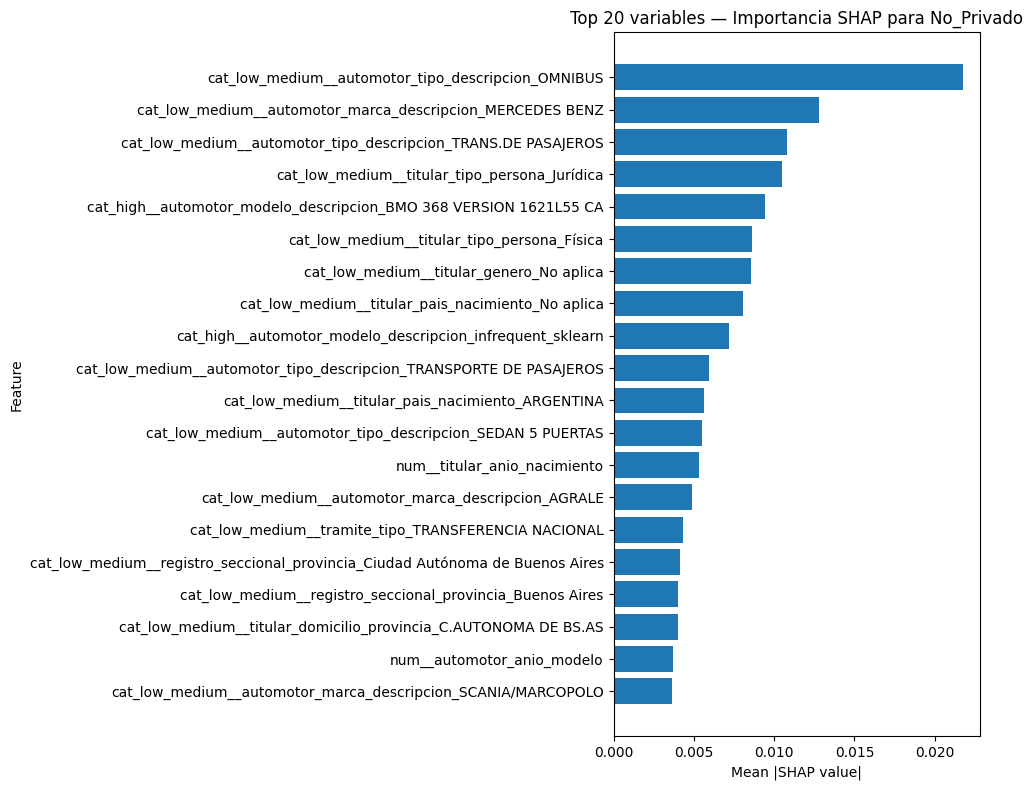

In [ ]:
# ============================================================
# 25.5.1 — Gráfico de importancia SHAP
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Top 20 features
# ------------------------------------------------------------

top_n = 20

top_features = shap_direction_df.head(top_n).copy()

# ------------------------------------------------------------
# Gráfico
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["SHAP_Mean_Abs"][::-1]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title(
    "Top 20 variables — Importancia SHAP para No_Privado"
)

plt.tight_layout()
plt.show()

## 25.7 — Importancia SHAP agrupada por variable original

In [ ]:
# ============================================================
# 25.7 — Importancia SHAP agrupada por variable original
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Variables originales utilizadas en el modelo
# ------------------------------------------------------------

original_features = [
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_modelo_descripcion",
    "titular_tipo_persona",
    "titular_genero",
    "titular_pais_nacimiento",
    "titular_anio_nacimiento",
    "tramite_tipo",
    "registro_seccional_provincia",
    "titular_domicilio_provincia",
    "titular_domicilio_localidad",
    "automotor_anio_modelo",
    "antiguedad_vehiculo",
    "inscripcion_anio",
    "inscripcion_mes",
    "automotor_origen"
]

# ------------------------------------------------------------
# 2. Crear dataframe base
# ------------------------------------------------------------

shap_grouped = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Mean_Abs": np.mean(
        np.abs(shap_no_privado),
        axis=0
    )
})

# ------------------------------------------------------------
# 3. Identificar variable original
# ------------------------------------------------------------

def identify_original_feature(feature_name):

    # Quitamos el prefijo del transformer
    if "__" in feature_name:
        clean_name = feature_name.split("__", 1)[1]
    else:
        clean_name = feature_name

    # Buscamos coincidencia con las variables originales
    for original in sorted(original_features, key=len, reverse=True):
        if clean_name.startswith(original):
            return original

    return "OTRAS"

shap_grouped["Original_Feature"] = (
    shap_grouped["Feature"]
    .apply(identify_original_feature)
)

# ------------------------------------------------------------
# 4. Agrupar importancia
# ------------------------------------------------------------

shap_grouped_summary = (
    shap_grouped
    .groupby("Original_Feature", as_index=False)
    ["SHAP_Mean_Abs"]
    .sum()
    .sort_values(
        "SHAP_Mean_Abs",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Mostrar resultado
# ------------------------------------------------------------

print("Importancia SHAP agrupada por variable original:")
display(shap_grouped_summary)

Importancia SHAP agrupada por variable original:


,Original_Feature,SHAP_Mean_Abs
0,automotor_tipo_descripcion,0.052753
1,automotor_marca_descripcion,0.035766
2,automotor_modelo_descripcion,0.026045
3,titular_tipo_persona,0.019105
4,registro_seccional_provincia,0.014289
5,titular_genero,0.014170
6,titular_pais_nacimiento,0.013830
7,titular_domicilio_provincia,0.012866
8,titular_domicilio_localidad,0.012177
9,tramite_tipo,0.011682


### 25.7.1 — Gráfico SHAP agrupado

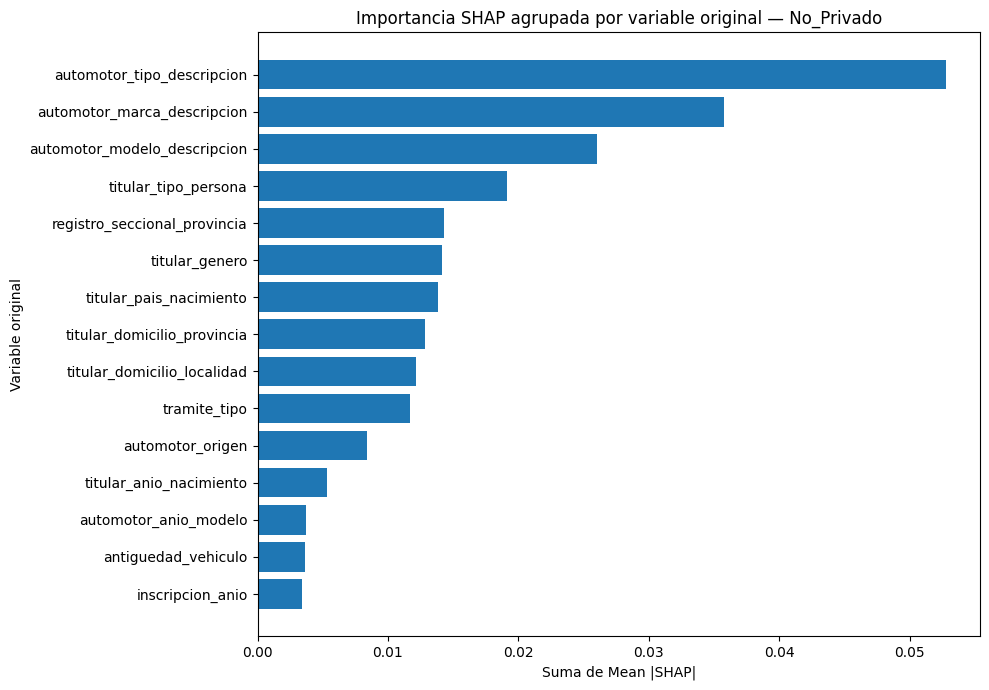

In [ ]:
# ============================================================
# 25.7.1 — Gráfico SHAP agrupado
# ============================================================

top_n = 15

top_grouped = shap_grouped_summary.head(top_n)

plt.figure(figsize=(10, 7))

plt.barh(
    top_grouped["Original_Feature"][::-1],
    top_grouped["SHAP_Mean_Abs"][::-1]
)

plt.xlabel("Suma de Mean |SHAP|")
plt.ylabel("Variable original")
plt.title(
    "Importancia SHAP agrupada por variable original — No_Privado"
)

plt.tight_layout()
plt.show()

## 25.8 — Análisis de importancia SHAP agrupada

In [ ]:
# ============================================================
# 25.8 — Importancia SHAP agrupada y porcentaje relativo
# ============================================================

shap_grouped_analysis = shap_grouped_summary.copy()

# Importancia total
total_importance = shap_grouped_analysis["SHAP_Mean_Abs"].sum()

# Porcentaje relativo
shap_grouped_analysis["Importancia_%"] = (
    shap_grouped_analysis["SHAP_Mean_Abs"]
    / total_importance
    * 100
)

# Redondear
shap_grouped_analysis["SHAP_Mean_Abs"] = (
    shap_grouped_analysis["SHAP_Mean_Abs"]
    .round(6)
)

shap_grouped_analysis["Importancia_%"] = (
    shap_grouped_analysis["Importancia_%"]
    .round(2)
)

display(shap_grouped_analysis)

,Original_Feature,SHAP_Mean_Abs,Importancia_%
0,automotor_tipo_descripcion,0.052753,21.90
1,automotor_marca_descripcion,0.035766,14.85
2,automotor_modelo_descripcion,0.026045,10.81
3,titular_tipo_persona,0.019105,7.93
4,registro_seccional_provincia,0.014289,5.93
5,titular_genero,0.014170,5.88
6,titular_pais_nacimiento,0.013830,5.74
7,titular_domicilio_provincia,0.012866,5.34
8,titular_domicilio_localidad,0.012177,5.05
9,tramite_tipo,0.011682,4.85


### 25.8.1 — Acumulado de importancia SHAP

In [ ]:
# ============================================================
# 25.8.1 — Acumulado de importancia SHAP
# ============================================================

shap_grouped_analysis["Importancia_Acumulada_%"] = (
    shap_grouped_analysis["Importancia_%"]
    .cumsum()
    .round(2)
)

display(
    shap_grouped_analysis[
        [
            "Original_Feature",
            "SHAP_Mean_Abs",
            "Importancia_%",
            "Importancia_Acumulada_%"
        ]
    ]
)

,Original_Feature,SHAP_Mean_Abs,Importancia_%,Importancia_Acumulada_%
0,automotor_tipo_descripcion,0.052753,21.90,21.90
1,automotor_marca_descripcion,0.035766,14.85,36.75
2,automotor_modelo_descripcion,0.026045,10.81,47.56
3,titular_tipo_persona,0.019105,7.93,55.49
4,registro_seccional_provincia,0.014289,5.93,61.42
5,titular_genero,0.014170,5.88,67.30
6,titular_pais_nacimiento,0.013830,5.74,73.04
7,titular_domicilio_provincia,0.012866,5.34,78.38
8,titular_domicilio_localidad,0.012177,5.05,83.43
9,tramite_tipo,0.011682,4.85,88.28


Una observación metodológica importante

Esto no significa que, por ejemplo, el tipo de vehículo "cause" que una unidad sea No_Privado.

SHAP nos está diciendo:

qué variables utiliza el modelo y cuánto contribuyen, en promedio, a sus predicciones.

## 25.9 — Visualización acumulada

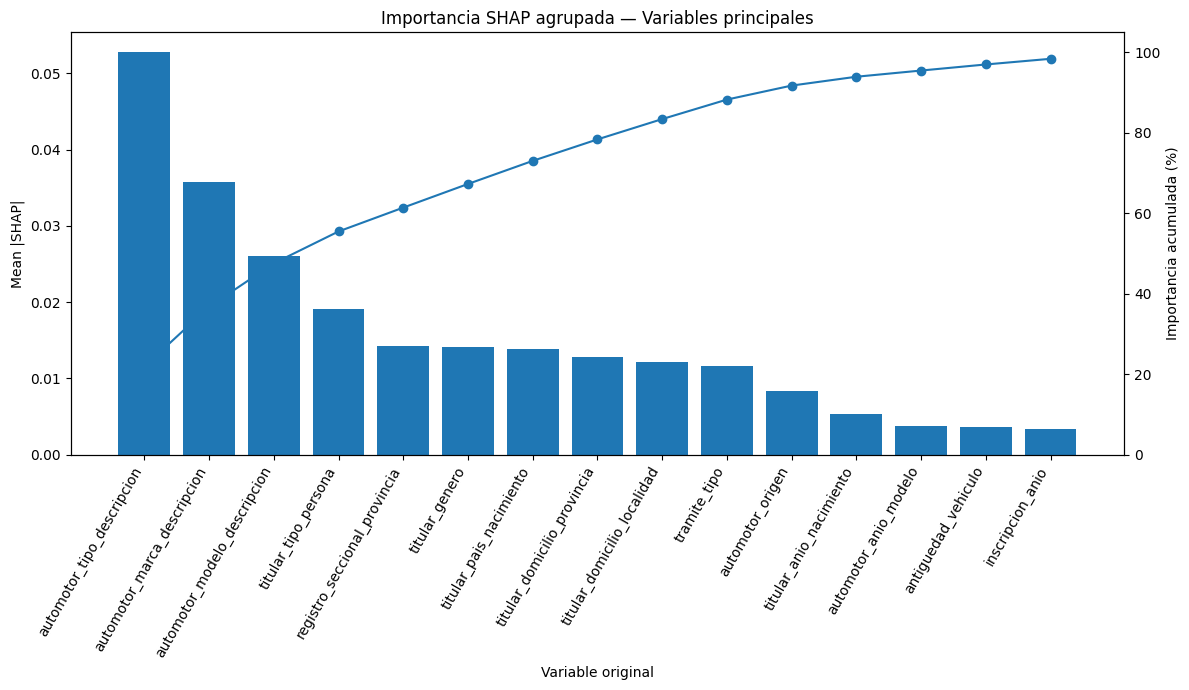

In [ ]:
# ============================================================
# 25.9 — Importancia SHAP acumulada
# ============================================================

import matplotlib.pyplot as plt

top_n = 15

plot_data = shap_grouped_analysis.head(top_n).copy()

fig, ax1 = plt.subplots(figsize=(12, 7))

# Barras
ax1.bar(
    plot_data["Original_Feature"],
    plot_data["SHAP_Mean_Abs"]
)

ax1.set_xlabel("Variable original")
ax1.set_ylabel("Mean |SHAP|")
ax1.set_title(
    "Importancia SHAP agrupada — Variables principales"
)

plt.xticks(
    rotation=60,
    ha="right"
)

# Eje secundario para acumulado
ax2 = ax1.twinx()

ax2.plot(
    plot_data["Original_Feature"],
    plot_data["Importancia_Acumulada_%"],
    marker="o"
)

ax2.set_ylabel("Importancia acumulada (%)")
ax2.set_ylim(0, 105)

plt.tight_layout()
plt.show()

## 25.10 — SHAP Beeswarm para No_Privado

/tmp/ipykernel_611/1075885041.py:30: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


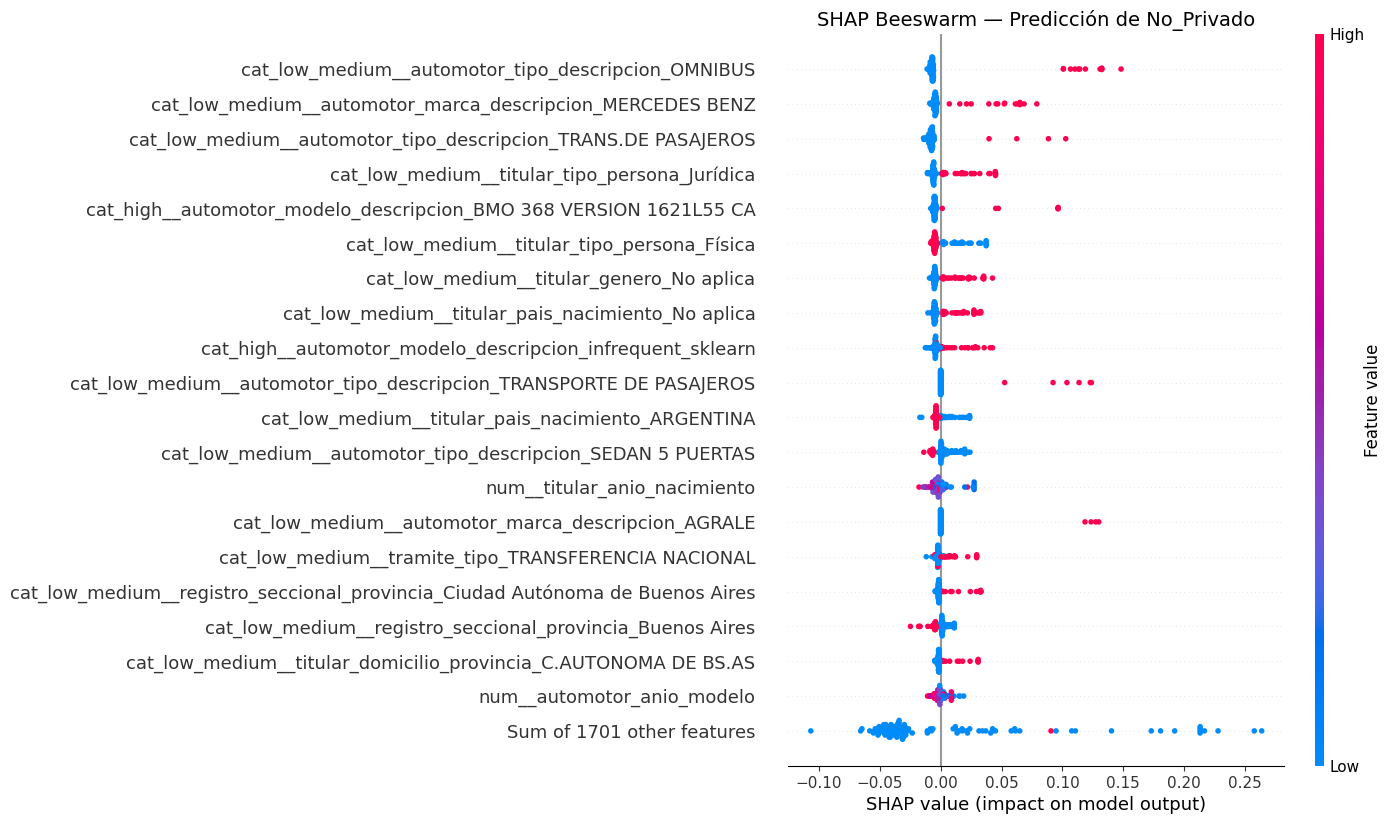

In [ ]:
# ============================================================
# 25.10 — SHAP Beeswarm — Clase No_Privado
# ============================================================

import shap
import matplotlib.pyplot as plt

# Crear una Explanation únicamente para la clase No_Privado
shap_no_privado_explanation = shap.Explanation(
    values=shap_no_privado,
    base_values=shap_result.base_values[:, 1],
    data=X_shap_balanced_dense,
    feature_names=feature_names
)

# Beeswarm
plt.figure(figsize=(12, 10))

shap.plots.beeswarm(
    shap_no_privado_explanation,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Beeswarm — Predicción de No_Privado",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 25.11 — SHAP para las observaciones No_Privado

In [ ]:
# ============================================================
# 25.11 — Impacto SHAP en casos No_Privado
# ============================================================

# Índices de las observaciones No_Privado
idx_no_privado = np.where(
    y_test_binary.values == 1
)[0]

# Como X_shap_balanced contiene:
# 51 No_Privado + 51 Privado
# los primeros 51 corresponden a No_Privado

shap_no_privado_cases = shap_no_privado[:51]

# Magnitud total de SHAP por observación
case_importance = np.sum(
    np.abs(shap_no_privado_cases),
    axis=1
)

cases_df = pd.DataFrame({
    "Caso": np.arange(1, 52),
    "SHAP_Total": case_importance
}).sort_values(
    "SHAP_Total",
    ascending=False
)

display(cases_df.head(15))

,Caso,SHAP_Total
19,20,0.856826
45,46,0.856826
37,38,0.710586
26,27,0.563232
6,7,0.540432
31,32,0.519287
30,31,0.479267
47,48,0.468105
23,24,0.435720
36,37,0.407775


## 25.12 — Análisis de los casos No_Privado

In [ ]:
# ============================================================
# 25.12 — Análisis individual de casos No_Privado
# ============================================================

# Índices de los casos No_Privado dentro de X_test
idx_no_privado = np.where(
    y_test_binary.values == 1
)[0]

# Recuperar las filas originales de X_test
X_no_privado = X_test.iloc[idx_no_privado]

# Probabilidad de No_Privado
proba_no_privado = rf_tuned.predict_proba(
    X_no_privado
)[:, 1]

# Predicciones
pred_no_privado = (
    proba_no_privado >= 0.5
).astype(int)

# Crear tabla
cases_analysis = pd.DataFrame({
    "Caso": np.arange(1, len(idx_no_privado) + 1),
    "Real": y_test_binary.iloc[idx_no_privado].values,
    "Prediccion": pred_no_privado,
    "Prob_No_Privado": proba_no_privado,
    "SHAP_Total": case_importance
})

# Correcto / incorrecto
cases_analysis["Correcto"] = (
    cases_analysis["Real"]
    == cases_analysis["Prediccion"]
)

# Ordenar por magnitud SHAP
cases_analysis = (
    cases_analysis
    .sort_values(
        "SHAP_Total",
        ascending=False
    )
    .reset_index(drop=True)
)

display(cases_analysis)

,Caso,Real,Prediccion,Prob_No_Privado,SHAP_Total,Correcto
0,20,1,0,0.069484,0.856826,False
1,46,1,0,0.103887,0.856826,False
2,38,1,0,0.069080,0.710586,False
3,27,1,1,0.602648,0.563232,True
4,7,1,0,0.059595,0.540432,False
5,32,1,0,0.342980,0.519287,False
6,31,1,1,0.938447,0.479267,True
7,48,1,0,0.109442,0.468105,False
8,24,1,0,0.000000,0.435720,False
9,37,1,0,0.368426,0.407775,False


### 25.12.1 — Casos No_Privado mal clasificados

In [ ]:
# ============================================================
# 25.12.1 — Casos No_Privado mal clasificados
# ============================================================

false_negative_cases = cases_analysis[
    (cases_analysis["Real"] == 1) &
    (cases_analysis["Prediccion"] == 0)
].copy()

print(
    "Cantidad de No_Privado mal clasificados:",
    len(false_negative_cases)
)

display(false_negative_cases)

Cantidad de No_Privado mal clasificados: 41


,Caso,Real,Prediccion,Prob_No_Privado,SHAP_Total,Correcto
0,20,1,0,0.069484,0.856826,False
1,46,1,0,0.103887,0.856826,False
2,38,1,0,0.069080,0.710586,False
4,7,1,0,0.059595,0.540432,False
5,32,1,0,0.342980,0.519287,False
7,48,1,0,0.109442,0.468105,False
8,24,1,0,0.000000,0.435720,False
9,37,1,0,0.368426,0.407775,False
10,2,1,0,0.099168,0.378589,False
11,49,1,0,0.468901,0.347840,False


## 25.13 — Caracterización de los falsos negativos

In [ ]:
# ============================================================
# 25.13 — Caracterización de falsos negativos
# ============================================================

# Índices originales de los No_Privado
idx_no_privado = np.where(
    y_test_binary.values == 1
)[0]

# Predicciones de todos los casos No_Privado
pred_no_privado = (
    cases_analysis
    .set_index("Caso")
    .loc[
        np.arange(1, len(idx_no_privado) + 1),
        "Prediccion"
    ]
    .values
)

# Identificar posiciones de falsos negativos
fn_positions = np.where(
    pred_no_privado == 0
)[0]

# Índices originales dentro de X_test
idx_false_negative = idx_no_privado[fn_positions]

# Recuperar datos originales
X_false_negative = X_test.iloc[
    idx_false_negative
].copy()

print(
    "Cantidad de falsos negativos:",
    len(X_false_negative)
)

display(X_false_negative.head(10))

Cantidad de falsos negativos: 41


,tramite_tipo,registro_seccional_provincia,automotor_origen,automotor_anio_modelo,automotor_tipo_descripcion,automotor_marca_descripcion,automotor_modelo_descripcion,titular_tipo_persona,titular_domicilio_localidad,titular_domicilio_provincia,titular_genero,titular_anio_nacimiento,titular_pais_nacimiento,titular_porcentaje_titularidad,antiguedad_vehiculo,tramite_anio,tramite_mes,inscripcion_anio,inscripcion_mes
132322,TRANSFERENCIA NACIONAL,Ciudad Autónoma de Buenos Aires,Nacional,2024.0,SEDAN 4 PUERTAS,RENAULT,LOGAN LIFE 1.6,Física,C.AUTONOMA DE BS.AS,C.AUTONOMA DE BS.AS,Femenino,1978.0,ARGENTINA,100.0,2.0,2026,8,2024,2
115107,TRANSFERENCIA NACIONAL,Buenos Aires,Nacional,2023.0,SEDAN 4 PUERTAS,FIAT,CRONOS PRECISION 1.3 GSE CVT BZ,Física,MAR DEL PLATA,BUENOS AIRES,Masculino,1951.0,ARGENTINA,100.0,3.0,2026,8,2023,10
105940,TRANSFERENCIA NACIONAL,Buenos Aires,Nacional,2019.0,SEDAN 4 PUERTAS,RENAULT,NUEVO LOGAN AUTHENTIQUE 1.6,Física,BAHI­A BLANCA,BUENOS AIRES,Masculino,1971.0,ARGENTINA,100.0,7.0,2026,8,2019,9
42756,TRANSFERENCIA IMPORTADO,Santiago del Estero,Protocolo 21,2017.0,TRANS.DE PASAJEROS,SCANIA/MARCOPOLO,K 400 B 6X2 / PARADISO 1800DD,Jurídica,MAR DEL PLATA,SGO.DEL ESTERO,No aplica,2011.0,No aplica,100.0,9.0,2026,8,2017,7
32896,TRANSFERENCIA IMPORTADO,Mendoza,Protocolo 21,2016.0,SEDAN 4 PUERTAS,VOLKSWAGEN,VOYAGE 1.6,Física,VILLA NUEVA,MENDOZA,Masculino,1983.0,ARGENTINA,100.0,10.0,2026,8,2016,4
102229,TRANSFERENCIA NACIONAL,Córdoba,Nacional,2019.0,SEDAN 4 PUERTAS,RENAULT,NUEVO LOGAN AUTHENTIQUE PLUS 1.6,Física,CORDOBA,CORDOBA,Masculino,1950.0,ARGENTINA,100.0,7.0,2026,8,2019,4
105380,TRANSFERENCIA NACIONAL,Santa Fe,Nacional,2016.0,SEDAN 4 PUERTAS,CHEVROLET,CLASSIC 4 P LS PACK 1.4N,Física,ROSARIO,SANTA FE,Femenino,1998.0,ARGENTINA,100.0,10.0,2026,8,2016,3
127254,TRANSFERENCIA IMPORTADO,Mendoza,Importado,2019.0,FAMILIAR,SHINERAY,X30,Física,SAN RAFAEL,MENDOZA,Masculino,1957.0,ARGENTINA,100.0,7.0,2026,8,2019,2
29508,TRANSFERENCIA NACIONAL C/PEDIDO,Buenos Aires,Nacional,2019.0,TRANSPORTE DE PASAJEROS,MERCEDES BENZ,BMO 368 VERSION 1721L62 CA,Jurídica,C SPEGAZZINI,BUENOS AIRES,No aplica,1976.0,No aplica,100.0,7.0,2026,8,2019,5
97839,TRANSFERENCIA IMPORTADO C/PEDIDO,Buenos Aires,Protocolo 21,2016.0,TRANS.DE PASAJEROS,MERCEDES BENZ/MARCOPOLO,O500 RSD2436/30 / PARADISO1800DD,Física,GENERAL BELGRANO,BUENOS AIRES,Masculino,1978.0,ARGENTINA,50.0,10.0,2026,8,2016,6


## 25.14 — Ver las probabilidades de los falsos negativos

In [ ]:
# ============================================================
# 25.14 — Probabilidad de No_Privado en falsos negativos
# ============================================================

fn_results = pd.DataFrame({
    "Indice_X_test": idx_false_negative,
    "Prob_No_Privado": proba_no_privado[fn_positions],
    "Prediccion": pred_no_privado[fn_positions],
    "Real": 1
})

# Ordenar por probabilidad descendente
fn_results = (
    fn_results
    .sort_values(
        "Prob_No_Privado",
        ascending=False
    )
    .reset_index(drop=True)
)

display(fn_results)

,Indice_X_test,Prob_No_Privado,Prediccion,Real
0,6688,0.488940,0,1
1,9416,0.478188,0,1
2,11486,0.468901,0,1
3,3252,0.439165,0,1
4,9087,0.389112,0,1
5,8211,0.373416,0,1
6,9236,0.368426,0,1
7,1370,0.357578,0,1
8,3752,0.354236,0,1
9,7606,0.342980,0,1


## 25.15 — Distribución de probabilidades

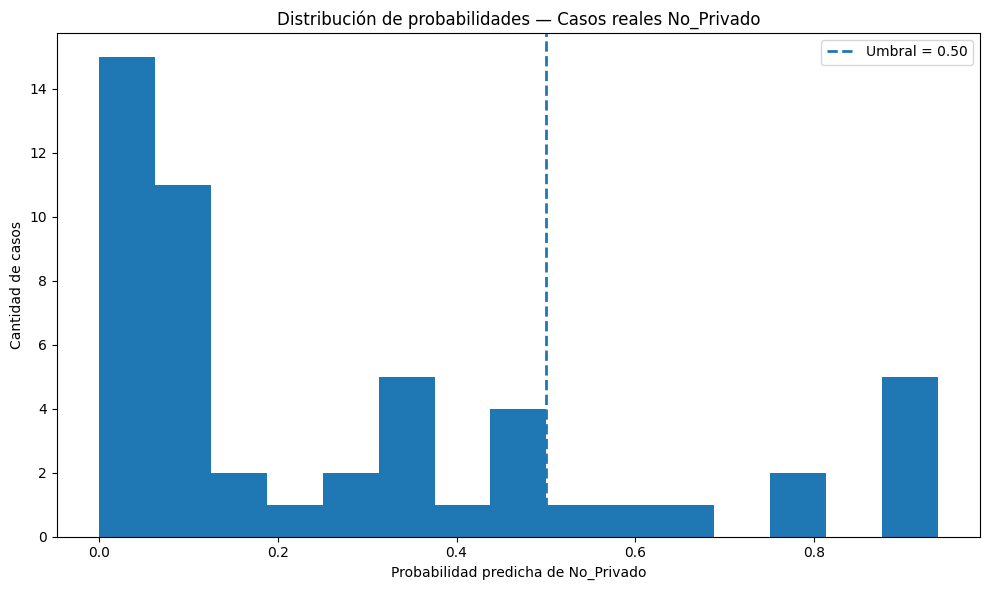

In [ ]:
# ============================================================
# 25.15 — Distribución de probabilidades en No_Privado
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    proba_no_privado,
    bins=15
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Umbral = 0.50"
)

plt.xlabel("Probabilidad predicha de No_Privado")
plt.ylabel("Cantidad de casos")
plt.title(
    "Distribución de probabilidades — Casos reales No_Privado"
)

plt.legend()
plt.tight_layout()
plt.show()

## 25.16 — Resumen de clasificación de la clase minoritaria

In [ ]:
# ============================================================
# 25.16 — Resumen de clasificación No_Privado
# ============================================================

tp = np.sum(
    (y_test_binary.values == 1) &
    (rf_tuned.predict(X_test) == 1)
)

fn = np.sum(
    (y_test_binary.values == 1) &
    (rf_tuned.predict(X_test) == 0)
)

fp = np.sum(
    (y_test_binary.values == 0) &
    (rf_tuned.predict(X_test) == 1)
)

tn = np.sum(
    (y_test_binary.values == 0) &
    (rf_tuned.predict(X_test) == 0)
)

print("==============================================")
print("   RESUMEN — CLASE No_Privado")
print("==============================================")
print(f"Verdaderos Positivos : {tp}")
print(f"Falsos Negativos     : {fn}")
print(f"Falsos Positivos     : {fp}")
print(f"Verdaderos Negativos : {tn}")
print("==============================================")
print(f"Recall No_Privado    : {tp / (tp + fn):.4f}")
print(f"Precision No_Privado : {tp / (tp + fp):.4f}")
print("==============================================")

   RESUMEN — CLASE No_Privado
Verdaderos Positivos : 10
Falsos Negativos     : 41
Falsos Positivos     : 5
Verdaderos Negativos : 12406
Recall No_Privado    : 0.1961
Precision No_Privado : 0.6667


### 25.16.1 — Verificación de matriz de confusión actual

In [ ]:
# ============================================================
# 25.16.1 — Verificación de matriz de confusión actual
# ============================================================

from sklearn.metrics import confusion_matrix, classification_report

y_pred_final = rf_tuned.predict(X_test)

cm_final = confusion_matrix(
    y_test_binary,
    y_pred_final
)

print("Matriz de confusión:")
print(cm_final)

print("\nClassification Report:")
print(
    classification_report(
        y_test_binary,
        y_pred_final,
        target_names=["Privado", "No_Privado"],
        digits=4
    )
)

Matriz de confusión:
[[12406     5]
 [   41    10]]

Classification Report:
              precision    recall  f1-score   support

     Privado     0.9967    0.9996    0.9981     12411
  No_Privado     0.6667    0.1961    0.3030        51

    accuracy                         0.9963     12462
   macro avg     0.8317    0.5978    0.6506     12462
weighted avg     0.9954    0.9963    0.9953     12462



## 25.17 — Evaluación de distintos thresholds

Ahora sí tiene sentido volver a los thresholds.

La pregunta es:

¿Qué sucede si modificamos el umbral de decisión para aumentar la detección de No_Privado?

In [ ]:
# ============================================================
# 25.17 — Evaluación de distintos thresholds
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Probabilidad de No_Privado
y_proba = rf_tuned.predict_proba(X_test)[:, 1]

thresholds = np.arange(
    0.05,
    0.96,
    0.05
)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_proba >= threshold
    ).astype(int)

    precision = precision_score(
        y_test_binary,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test_binary,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test_binary,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1
0,0.05,0.0935,0.7647,0.1667
1,0.10,0.1687,0.5490,0.2581
2,0.15,0.2697,0.4706,0.3429
3,0.20,0.3651,0.4510,0.4035
4,0.25,0.4783,0.4314,0.4536
5,0.30,0.5714,0.3922,0.4651
6,0.35,0.7037,0.3725,0.4872
7,0.40,0.6667,0.2745,0.3889
8,0.45,0.6500,0.2549,0.3662
9,0.50,0.6667,0.1961,0.3030


### 25.17.1 — Gráfico de Precision, Recall y F1 según threshold

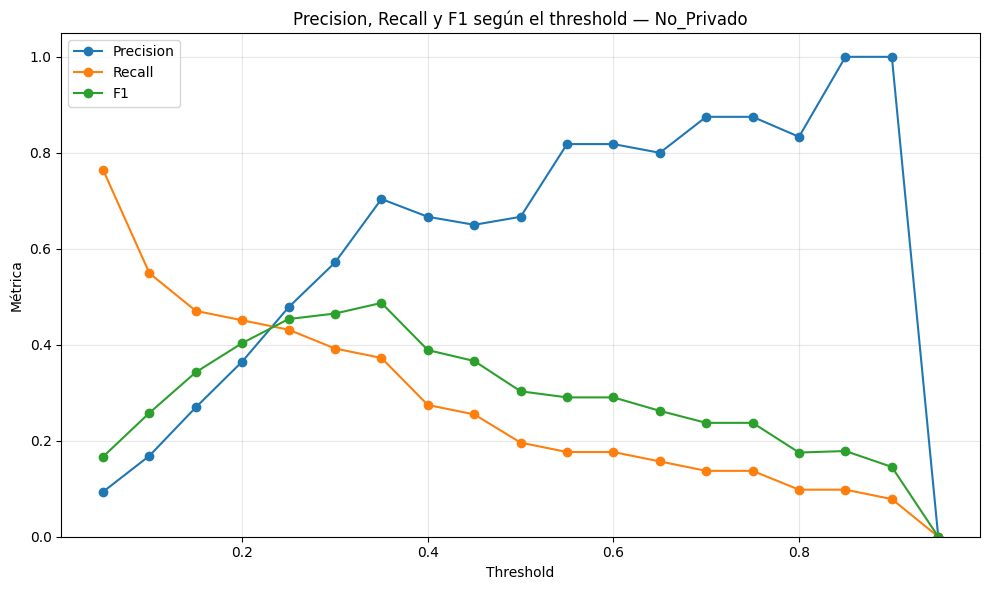

In [ ]:
# ============================================================
# 25.17.1 — Precision / Recall / F1 según threshold
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    marker="o",
    label="F1"
)

plt.xlabel("Threshold")
plt.ylabel("Métrica")
plt.title(
    "Precision, Recall y F1 según el threshold — No_Privado"
)

plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
memory_usage()

RAM utilizada por Python: 0.96 GB


## 25.18 — Threshold con mayor F1

In [ ]:
# ============================================================
# 25.18 — Threshold con mayor F1
# ============================================================

best_f1_idx = threshold_df["F1"].idxmax()

best_threshold = threshold_df.loc[
    best_f1_idx,
    "Threshold"
]

best_precision = threshold_df.loc[
    best_f1_idx,
    "Precision"
]

best_recall = threshold_df.loc[
    best_f1_idx,
    "Recall"
]

best_f1 = threshold_df.loc[
    best_f1_idx,
    "F1"
]

print("==============================================")
print("        THRESHOLD CON MAYOR F1")
print("==============================================")
print(f"Threshold : {best_threshold:.2f}")
print(f"Precision : {best_precision:.4f}")
print(f"Recall    : {best_recall:.4f}")
print(f"F1        : {best_f1:.4f}")
print("==============================================")

        THRESHOLD CON MAYOR F1
Threshold : 0.35
Precision : 0.7037
Recall    : 0.3725
F1        : 0.4872


### 25.18.1 — Comparación de thresholds

In [ ]:
# ============================================================
# 25.18.1 — Comparación de thresholds
# ============================================================

comparison_thresholds = [0.50, best_threshold]

comparison = []

for threshold in comparison_thresholds:

    y_pred_t = (
        y_proba >= threshold
    ).astype(int)

    comparison.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test_binary,
            y_pred_t,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test_binary,
            y_pred_t,
            zero_division=0
        ),
        "F1": f1_score(
            y_test_binary,
            y_pred_t,
            zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

,Threshold,Precision,Recall,F1
0,0.50,0.6667,0.1961,0.3030
1,0.35,0.7037,0.3725,0.4872


### 25.19 — Matriz de confusión con threshold 0.35

In [ ]:
# ============================================================
# 25.19 — Matriz de confusión con threshold 0.35
# ============================================================

threshold_final = 0.35

y_pred_035 = (
    y_proba >= threshold_final
).astype(int)

cm_035 = confusion_matrix(
    y_test_binary,
    y_pred_035
)

print("==============================================")
print(" MATRIZ DE CONFUSIÓN — THRESHOLD 0.35")
print("==============================================")
print(cm_035)

print("\nClassification Report:")
print(
    classification_report(
        y_test_binary,
        y_pred_035,
        target_names=[
            "Privado",
            "No_Privado"
        ],
        digits=4
    )
)

 MATRIZ DE CONFUSIÓN — THRESHOLD 0.35
[[12403     8]
 [   32    19]]

Classification Report:
              precision    recall  f1-score   support

     Privado     0.9974    0.9994    0.9984     12411
  No_Privado     0.7037    0.3725    0.4872        51

    accuracy                         0.9968     12462
   macro avg     0.8506    0.6860    0.7428     12462
weighted avg     0.9962    0.9968    0.9963     12462



### 25.19.1 — Comparación de matrices de confusión

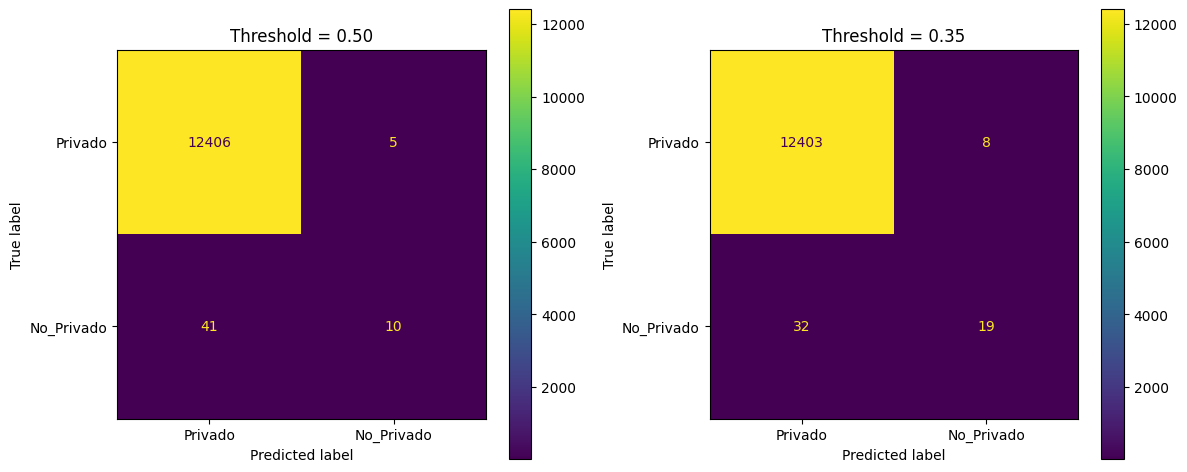

In [ ]:
# ============================================================
# 25.19.1 — Comparación de matrices de confusión
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred_050 = (
    y_proba >= 0.50
).astype(int)

cm_050 = confusion_matrix(
    y_test_binary,
    y_pred_050
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

ConfusionMatrixDisplay(
    cm_050,
    display_labels=["Privado", "No_Privado"]
).plot(
    ax=axes[0],
    values_format="d"
)

axes[0].set_title(
    "Threshold = 0.50"
)

ConfusionMatrixDisplay(
    cm_035,
    display_labels=["Privado", "No_Privado"]
).plot(
    ax=axes[1],
    values_format="d"
)

axes[1].set_title(
    "Threshold = 0.35"
)

plt.tight_layout()
plt.show()

Lectura para el informe




El ajuste del umbral de decisión de 0,50 a 0,35 incrementó la capacidad del modelo para detectar la clase minoritaria No_Privado. Los verdaderos positivos aumentaron de 10 a 19, mientras que los falsos negativos disminuyeron de 41 a 32. Este incremento en la detección implicó un aumento de los falsos positivos de 5 a 8. En consecuencia, el recall pasó de 19,61 % a 37,25 % y el F1 de 0,3030 a 0,4872.




In [ ]:
memory_usage()

RAM utilizada por Python: 0.96 GB


## 25.20 — Evaluación final con threshold 0.35

In [ ]:
# ============================================================
# 25.20 — Evaluación final con threshold = 0.35
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

threshold_final = 0.35

y_pred_final = (
    y_proba >= threshold_final
).astype(int)

print("==============================================")
print("   EVALUACIÓN FINAL — THRESHOLD 0.35")
print("==============================================")

print(
    f"Accuracy  : {accuracy_score(y_test_binary, y_pred_final):.4f}"
)

print(
    f"Precision : {precision_score(y_test_binary, y_pred_final):.4f}"
)

print(
    f"Recall    : {recall_score(y_test_binary, y_pred_final):.4f}"
)

print(
    f"F1        : {f1_score(y_test_binary, y_pred_final):.4f}"
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test_binary,
        y_pred_final,
        target_names=[
            "Privado",
            "No_Privado"
        ],
        digits=4
    )
)

   EVALUACIÓN FINAL — THRESHOLD 0.35
Accuracy  : 0.9968
Precision : 0.7037
Recall    : 0.3725
F1        : 0.4872

Classification Report:

              precision    recall  f1-score   support

     Privado     0.9974    0.9994    0.9984     12411
  No_Privado     0.7037    0.3725    0.4872        51

    accuracy                         0.9968     12462
   macro avg     0.8506    0.6860    0.7428     12462
weighted avg     0.9962    0.9968    0.9963     12462



Una observación importante

El threshold 0.35 no mejora todas las métricas de forma universal, en este conjunto de test y bajo el criterio de maximizar F1, 0.35 ofrece un mejor equilibrio entre precision y recall para No_Privado.

Además, el aumento de accuracy de 0.9963 → 0.9968 es secundario; debido al desbalance extremo, las métricas de No_Privado son mucho más informativas para este análisis.

## 25.21 — Matriz de confusión final

      MATRIZ DE CONFUSIÓN FINAL
      Threshold = 0.35
[[12403     8]
 [   32    19]]


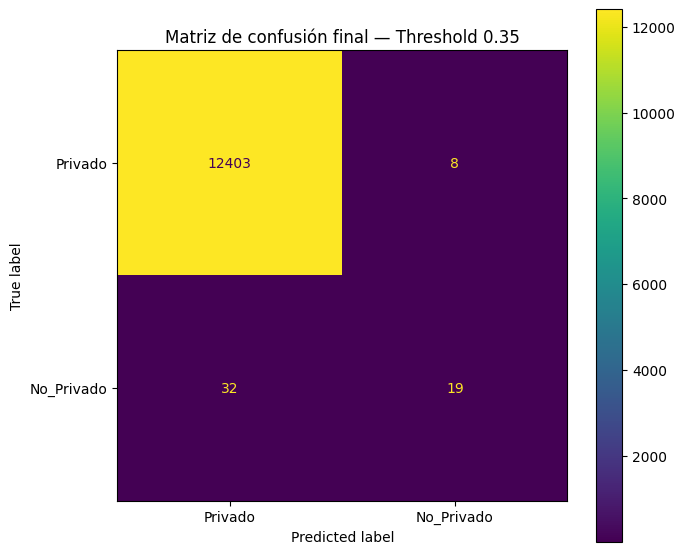

In [ ]:
# ============================================================
# 25.21 — Matriz de confusión final
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_final = confusion_matrix(
    y_test_binary,
    y_pred_final
)

print("============================================")
print("      MATRIZ DE CONFUSIÓN FINAL")
print("      Threshold = 0.35")
print("============================================")

print(cm_final)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=[
        "Privado",
        "No_Privado"
    ]
).plot(
    values_format="d",
    ax=ax
)

plt.title(
    "Matriz de confusión final — Threshold 0.35"
)

plt.tight_layout()
plt.show()

### 25.21.1 — Resumen consolidado del modelo final

In [ ]:
# ============================================================
# 25.21.1 — Resumen consolidado del modelo final
# ============================================================

tn, fp, fn, tp = cm_final.ravel()

final_summary = pd.DataFrame({
    "Métrica": [
        "Threshold",
        "Accuracy",
        "Precision — No_Privado",
        "Recall — No_Privado",
        "F1 — No_Privado",
        "Precision — Privado",
        "Recall — Privado",
        "F1 — Privado",
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives"
    ],
    "Valor": [
        threshold_final,
        accuracy_score(y_test_binary, y_pred_final),
        precision_score(
            y_test_binary,
            y_pred_final,
            pos_label=1
        ),
        recall_score(
            y_test_binary,
            y_pred_final,
            pos_label=1
        ),
        f1_score(
            y_test_binary,
            y_pred_final,
            pos_label=1
        ),
        precision_score(
            y_test_binary,
            y_pred_final,
            pos_label=0
        ),
        recall_score(
            y_test_binary,
            y_pred_final,
            pos_label=0
        ),
        f1_score(
            y_test_binary,
            y_pred_final,
            pos_label=0
        ),
        tn,
        fp,
        fn,
        tp
    ]
})

display(
    final_summary.style.format({
        "Valor": "{:.4f}"
    })
)

,Métrica,Valor
0,Threshold,0.3500
1,Accuracy,0.9968
2,Precision — No_Privado,0.7037
3,Recall — No_Privado,0.3725
4,F1 — No_Privado,0.4872
5,Precision — Privado,0.9974
6,Recall — Privado,0.9994
7,F1 — Privado,0.9984
8,True Negatives,12403.0000
9,False Positives,8.0000


## 25.22 — Análisis de los falsos negativos con threshold 0.35

In [ ]:
# ============================================================
# 25.22 — Análisis de falsos negativos con threshold 0.35
# ============================================================

# Índices de los casos realmente No_Privado
idx_no_privado = np.where(
    y_test_binary.values == 1
)[0]

# Probabilidades correspondientes
proba_no_privado_final = y_proba[idx_no_privado]

# Predicciones usando threshold 0.35
pred_no_privado_final = (
    proba_no_privado_final >= 0.35
).astype(int)

# Posiciones de los falsos negativos
fn_positions_final = np.where(
    pred_no_privado_final == 0
)[0]

# Índices originales dentro de X_test
idx_false_negative_final = (
    idx_no_privado[fn_positions_final]
)

# Crear tabla de resultados
fn_final = pd.DataFrame({
    "Indice_X_test": idx_false_negative_final,
    "Prob_No_Privado": proba_no_privado_final[
        fn_positions_final
    ],
    "Real": 1,
    "Prediccion": 0
})

# Ordenar de mayor a menor probabilidad
fn_final = (
    fn_final
    .sort_values(
        "Prob_No_Privado",
        ascending=False
    )
    .reset_index(drop=True)
)

print("==============================================")
print(" FALSOS NEGATIVOS — THRESHOLD 0.35")
print("==============================================")
print(
    "Cantidad:",
    len(fn_final)
)

display(fn_final)

 FALSOS NEGATIVOS — THRESHOLD 0.35
Cantidad: 32


,Indice_X_test,Prob_No_Privado,Real,Prediccion
0,7606,0.342980,1,0
1,2313,0.267997,1,0
2,2768,0.263524,1,0
3,6764,0.223178,1,0
4,4338,0.163477,1,0
5,10192,0.128898,1,0
6,10298,0.113945,1,0
7,11329,0.109442,1,0
8,11079,0.103887,1,0
9,2156,0.099207,1,0


###  25.22.1 — Distribución de probabilidades de los falsos negativos

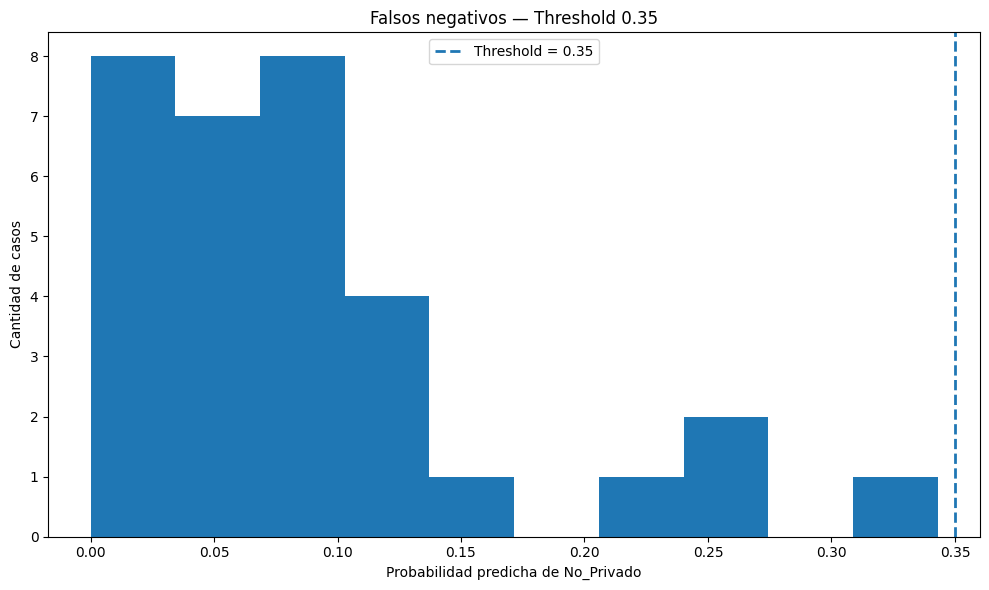

In [ ]:
# ============================================================
# 25.22.1 — Distribución de probabilidades de falsos negativos
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    fn_final["Prob_No_Privado"],
    bins=10
)

plt.axvline(
    0.35,
    linestyle="--",
    linewidth=2,
    label="Threshold = 0.35"
)

plt.xlabel(
    "Probabilidad predicha de No_Privado"
)

plt.ylabel(
    "Cantidad de casos"
)

plt.title(
    "Falsos negativos — Threshold 0.35"
)

plt.legend()

plt.tight_layout()
plt.show()

###  25.22.2 — Datos originales de los falsos negativos

In [ ]:
# ============================================================
# 25.22.2 — Datos originales de los falsos negativos
# ============================================================

X_false_negative_final = X_test.iloc[
    idx_false_negative_final
].copy()

print(
    "Shape de los falsos negativos:",
    X_false_negative_final.shape
)

display(
    X_false_negative_final
)

Shape de los falsos negativos: (32, 19)


,tramite_tipo,registro_seccional_provincia,automotor_origen,automotor_anio_modelo,automotor_tipo_descripcion,automotor_marca_descripcion,automotor_modelo_descripcion,titular_tipo_persona,titular_domicilio_localidad,titular_domicilio_provincia,titular_genero,titular_anio_nacimiento,titular_pais_nacimiento,titular_porcentaje_titularidad,antiguedad_vehiculo,tramite_anio,tramite_mes,inscripcion_anio,inscripcion_mes
132322,TRANSFERENCIA NACIONAL,Ciudad Autónoma de Buenos Aires,Nacional,2024.0,SEDAN 4 PUERTAS,RENAULT,LOGAN LIFE 1.6,Física,C.AUTONOMA DE BS.AS,C.AUTONOMA DE BS.AS,Femenino,1978.0,ARGENTINA,100.0,2.0,2026,8,2024,2
115107,TRANSFERENCIA NACIONAL,Buenos Aires,Nacional,2023.0,SEDAN 4 PUERTAS,FIAT,CRONOS PRECISION 1.3 GSE CVT BZ,Física,MAR DEL PLATA,BUENOS AIRES,Masculino,1951.0,ARGENTINA,100.0,3.0,2026,8,2023,10
105940,TRANSFERENCIA NACIONAL,Buenos Aires,Nacional,2019.0,SEDAN 4 PUERTAS,RENAULT,NUEVO LOGAN AUTHENTIQUE 1.6,Física,BAHI­A BLANCA,BUENOS AIRES,Masculino,1971.0,ARGENTINA,100.0,7.0,2026,8,2019,9
32896,TRANSFERENCIA IMPORTADO,Mendoza,Protocolo 21,2016.0,SEDAN 4 PUERTAS,VOLKSWAGEN,VOYAGE 1.6,Física,VILLA NUEVA,MENDOZA,Masculino,1983.0,ARGENTINA,100.0,10.0,2026,8,2016,4
102229,TRANSFERENCIA NACIONAL,Córdoba,Nacional,2019.0,SEDAN 4 PUERTAS,RENAULT,NUEVO LOGAN AUTHENTIQUE PLUS 1.6,Física,CORDOBA,CORDOBA,Masculino,1950.0,ARGENTINA,100.0,7.0,2026,8,2019,4
105380,TRANSFERENCIA NACIONAL,Santa Fe,Nacional,2016.0,SEDAN 4 PUERTAS,CHEVROLET,CLASSIC 4 P LS PACK 1.4N,Física,ROSARIO,SANTA FE,Femenino,1998.0,ARGENTINA,100.0,10.0,2026,8,2016,3
127254,TRANSFERENCIA IMPORTADO,Mendoza,Importado,2019.0,FAMILIAR,SHINERAY,X30,Física,SAN RAFAEL,MENDOZA,Masculino,1957.0,ARGENTINA,100.0,7.0,2026,8,2019,2
29508,TRANSFERENCIA NACIONAL C/PEDIDO,Buenos Aires,Nacional,2019.0,TRANSPORTE DE PASAJEROS,MERCEDES BENZ,BMO 368 VERSION 1721L62 CA,Jurídica,C SPEGAZZINI,BUENOS AIRES,No aplica,1976.0,No aplica,100.0,7.0,2026,8,2019,5
97839,TRANSFERENCIA IMPORTADO C/PEDIDO,Buenos Aires,Protocolo 21,2016.0,TRANS.DE PASAJEROS,MERCEDES BENZ/MARCOPOLO,O500 RSD2436/30 / PARADISO1800DD,Física,GENERAL BELGRANO,BUENOS AIRES,Masculino,1978.0,ARGENTINA,50.0,10.0,2026,8,2016,6
30387,TRANSFERENCIA IMPORTADO,Ciudad Autónoma de Buenos Aires,Importado,2016.0,SEDAN 4 PUERTAS,NISSAN,VERSA SENSE MT PURE DRIVE,Física,C.AUTONOMA DE BS.AS,C.AUTONOMA DE BS.AS,Masculino,1981.0,ARGENTINA,100.0,10.0,2026,8,2016,9


###  25.22.3 — Perfil de los falsos negativos

In [ ]:
# ============================================================
# 25.22.3 — Perfil de los falsos negativos
# ============================================================

# Recuperar los datos originales de los FN
X_fn = X_test.iloc[
    fn_final["Indice_X_test"]
].copy()

print("==============================================")
print(" PERFIL DE LOS 32 FALSOS NEGATIVOS")
print("==============================================")

categorical_cols = [
    "tramite_tipo",
    "registro_seccional_provincia",
    "automotor_origen",
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_modelo_descripcion",
    "titular_tipo_persona",
    "titular_domicilio_provincia",
    "titular_genero",
    "titular_pais_nacimiento"
]

for col in categorical_cols:

    print("\n" + "=" * 60)
    print(col)
    print("=" * 60)

    resumen = (
        X_fn[col]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("Cantidad")
    )

    resumen["Porcentaje"] = (
        resumen["Cantidad"] / len(X_fn) * 100
    )

    display(
        resumen.style.format({
            "Porcentaje": "{:.2f}%"
        })
    )

 PERFIL DE LOS 32 FALSOS NEGATIVOS

tramite_tipo


,Cantidad,Porcentaje
tramite_tipo,,
TRANSFERENCIA NACIONAL,14,43.75%
TRANSFERENCIA IMPORTADO,13,40.62%
TRANSFERENCIA NACIONAL C/PEDIDO,3,9.38%
TRANSFERENCIA IMPORTADO C/PEDIDO,2,6.25%



registro_seccional_provincia


,Cantidad,Porcentaje
registro_seccional_provincia,,
Buenos Aires,9,28.12%
Ciudad Autónoma de Buenos Aires,7,21.88%
Santa Fe,5,15.62%
Córdoba,4,12.50%
Mendoza,4,12.50%
Misiones,2,6.25%
Entre Ríos,1,3.12%



automotor_origen


...

,Cantidad,Porcentaje
titular_domicilio_provincia,,
BUENOS AIRES,9,28.12%
C.AUTONOMA DE BS.AS,7,21.88%
SANTA FE,5,15.62%
CORDOBA,4,12.50%
MENDOZA,4,12.50%
MISIONES,2,6.25%
ENTRE RIOS,1,3.12%



titular_genero


,Cantidad,Porcentaje
titular_genero,,
Masculino,21,65.62%
No aplica,6,18.75%
Femenino,5,15.62%



titular_pais_nacimiento


,Cantidad,Porcentaje
titular_pais_nacimiento,,
ARGENTINA,24,75.00%
No aplica,6,18.75%
VENEZUELA,1,3.12%
PERU,1,3.12%


### 25.22.4 — Comparación FN vs TP

In [ ]:
# ============================================================
# 25.22.4 — Comparación FN vs TP
# ============================================================

# Posiciones de los verdaderos positivos
tp_positions = np.where(
    pred_no_privado_final == 1
)[0]

# Índices originales de X_test
idx_true_positive_final = (
    idx_no_privado[tp_positions]
)

# Datos originales
X_tp = X_test.iloc[
    idx_true_positive_final
].copy()

print("==============================================")
print(" COMPARACIÓN No_Privado")
print("==============================================")
print(f"Verdaderos Positivos : {len(X_tp)}")
print(f"Falsos Negativos     : {len(X_fn)}")

 COMPARACIÓN No_Privado
Verdaderos Positivos : 19
Falsos Negativos     : 32


### 25.22.5 — Comparación de distribución FN vs TP

In [ ]:
# ============================================================
# 25.22.5 — Comparación de distribución FN vs TP
# ============================================================

comparison_results = []

comparison_cols = [
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_origen",
    "titular_tipo_persona",
    "titular_genero",
    "titular_pais_nacimiento",
    "registro_seccional_provincia",
    "titular_domicilio_provincia",
    "tramite_tipo"
]

for col in comparison_cols:

    fn_counts = (
        X_fn[col]
        .value_counts(normalize=True)
        .mul(100)
    )

    tp_counts = (
        X_tp[col]
        .value_counts(normalize=True)
        .mul(100)
    )

    categories = (
        set(fn_counts.index)
        .union(tp_counts.index)
    )

    for category in categories:

        comparison_results.append({
            "Variable": col,
            "Categoria": category,
            "FN_%": fn_counts.get(category, 0),
            "TP_%": tp_counts.get(category, 0),
            "Diferencia_pp": (
                fn_counts.get(category, 0)
                - tp_counts.get(category, 0)
            )
        })

fn_tp_comparison = pd.DataFrame(
    comparison_results
)

fn_tp_comparison = (
    fn_tp_comparison
    .sort_values(
        "Diferencia_pp",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    fn_tp_comparison.style.format({
        "FN_%": "{:.2f}",
        "TP_%": "{:.2f}",
        "Diferencia_pp": "{:+.2f}"
    })
)

,Variable,Categoria,FN_%,TP_%,Diferencia_pp
0,titular_tipo_persona,Física,81.25,0.00,+81.25
1,titular_pais_nacimiento,ARGENTINA,75.00,0.00,+75.00
2,titular_genero,Masculino,65.62,0.00,+65.62
3,automotor_tipo_descripcion,SEDAN 4 PUERTAS,56.25,0.00,+56.25
4,automotor_marca_descripcion,CHEVROLET,25.00,0.00,+25.00
5,tramite_tipo,TRANSFERENCIA IMPORTADO,40.62,15.79,+24.84
6,automotor_marca_descripcion,RENAULT,18.75,0.00,+18.75
7,registro_seccional_provincia,Buenos Aires,28.12,10.53,+17.60
8,titular_domicilio_provincia,BUENOS AIRES,28.12,10.53,+17.60
9,titular_genero,Femenino,15.62,0.00,+15.62


### 25.22.6 — Variables numéricas de FN vs TP

In [ ]:
# ============================================================
# 25.22.6 — Comparación de variables numéricas FN vs TP
# ============================================================

numeric_cols = [
    "automotor_anio_modelo",
    "titular_anio_nacimiento",
    "titular_porcentaje_titularidad",
    "antiguedad_vehiculo",
    "tramite_anio",
    "tramite_mes",
    "inscripcion_anio",
    "inscripcion_mes"
]

numeric_comparison = []

for col in numeric_cols:

    numeric_comparison.append({
        "Variable": col,

        "FN_Media": X_fn[col].mean(),
        "TP_Media": X_tp[col].mean(),

        "FN_Mediana": X_fn[col].median(),
        "TP_Mediana": X_tp[col].median()
    })

numeric_comparison_df = pd.DataFrame(
    numeric_comparison
)

display(
    numeric_comparison_df.style.format({
        "FN_Media": "{:.2f}",
        "TP_Media": "{:.2f}",
        "FN_Mediana": "{:.2f}",
        "TP_Mediana": "{:.2f}"
    })
)

,Variable,FN_Media,TP_Media,FN_Mediana,TP_Mediana
0,automotor_anio_modelo,2018.53,2018.53,2019.00,2017.00
1,titular_anio_nacimiento,1980.72,1986.16,1978.00,1971.00
2,titular_porcentaje_titularidad,98.44,100.00,100.00,100.00
3,antiguedad_vehiculo,7.47,7.47,7.00,9.00
4,tramite_anio,2026.00,2026.00,2026.00,2026.00
5,tramite_mes,8.00,8.00,8.00,8.00
6,inscripcion_anio,2018.59,2018.53,2019.00,2017.00
7,inscripcion_mes,6.31,6.16,6.50,7.00


In [ ]:
memory_usage()

RAM utilizada por Python: 0.96 GB


### 25.22.7 — Interpretación de los falsos negativos



Tenemos:

19 Verdaderos Positivos (TP) → No_Privado correctamente detectados.
32 Falsos Negativos (FN) → casos No_Privado clasificados como Privado.
Por lo tanto, el recall de No_Privado queda en 37,25%.
1. Características categóricas de los FN

Los falsos negativos se concentran principalmente en:

Variable	Patrón observado
Tipo de trámite	43,75% Transferencia Nacional + 40,62% Importado
Origen	53,12% Nacional + 37,50% Protocolo 21
Tipo de vehículo	56,25% Sedán 4 puertas
Marca	Chevrolet 25%, Renault 18,75%, Fiat 12,5%, Mercedes Benz 12,5%
Tipo de titular	81,25% Física
Género	65,62% Masculino
País nacimiento	75% Argentina
Provincia	Mayor concentración en Buenos Aires, CABA y Santa Fe

### 25.22.8  Comparación FN vs TP




Esta parte es mucho más importante que el perfil aislado.



```

Variables numéricas
Variable	    FN Media	TP Media	FN Mediana	TP Mediana
Año modelo	    2018,53	    2018,53	       2019	      2017
Año nacimiento	1980,72	    1986,16	       1978	      1971
% titularidad	98,44	     100,00	        100	      100
Antigüedad	     7,47	     7,47	         7	       9
Año trámite	     2026	     2026	       2026     2026
Mes trámite	      8	          8	            8	      8
Año inscripción	2018,59	   2018,53	       2019	     2017
Mes inscripción	6,31	    6,16	       6,5	      7
```

Las variables numéricas prácticamente no separan FN de TP.

Por ejemplo:


```
Año modelo: 2018,53 vs 2018,53 Antigüedad: 7,47 vs 7,47
Año trámite: 2026 vs 2026
Mes trámite: 8 vs 8
Mediana de titularidad: 100% en ambos grupos
```

Esto sugiere que, al menos dentro de estos 51 casos No_Privado, la dificultad de clasificación no parece venir principalmente de las variables numéricas.

### 25.22.9 Un punto importante sobre la interpretación



Hay una diferencia entre:

"Esta característica causa el error"

y:

"Esta característica aparece asociada con los casos que el modelo confunde."

Con SHAP y este análisis solamente podemos afirmar lo segundo.

Por ejemplo, que haya muchos FN con:

automotor_tipo_descripcion = SEDAN 4 PUERTAS

no significa que los sedanes provoquen el error.

Significa que muchos de los casos que el modelo no logró detectar pertenecen a una categoría que también puede ser frecuente entre los vehículos privados.

### 25.22.10  Hipótesis que podemos extraer

Hipótesis 1

* Solapamiento entre clases

Los No_Privado pueden compartir características con Privado.

Esto parece especialmente relevante porque encontramos FN como:


```

sedanes,
personas físicas,
titularidad 100%,
marcas comunes,
vehículos nacionales.
```



Es decir, no necesariamente tienen una combinación de características extremadamente diferenciadora.

Hipótesis 2

* Las variables categóricas tienen mayor capacidad discriminativa

Esto coincide con el análisis SHAP anterior.

Las variables agrupadas más importantes fueron:


```
automotor_tipo_descripcion
automotor_marca_descripcion
automotor_modelo_descripcion
titular_tipo_persona
registro_seccional_provincia
titular_genero
titular_pais_nacimiento
```




Mientras que las variables numéricas individuales tuvieron menor impacto.

Esto es coherente con el análisis de los FN: las diferencias numéricas entre FN y TP son pequeñas.

Hipótesis 3

* El umbral 0,35 todavía deja una zona difícil

Recordemos que con el umbral final:

Threshold = 0.35


```
No_Privado:
Precision = 0.7037
Recall    = 0.3725
F1        = 0.4872

```

Tenemos:

```
51 No_Privado reales
├── 19 TP
└── 32 FN
```




Por lo tanto, incluso después de bajar el umbral desde 0.50 hasta 0.35, todavía existe un conjunto importante de casos que el modelo considera suficientemente similares a Privado.

### 25.22.11  Conclusión para el informe

Análisis de falsos negativos:




 Los 32 falsos negativos corresponden a vehículos realmente clasificados como No_Privado que el modelo predijo como Privado. El análisis descriptivo muestra una concentración importante en vehículos tipo sedán, titulares personas físicas y marcas de alta frecuencia en el dataset. Al comparar los falsos negativos con los 19 verdaderos positivos de la clase No_Privado, las variables numéricas presentan diferencias reducidas, especialmente en año del modelo, antigüedad del vehículo y año de trámite. Esto sugiere que la dificultad de clasificación se encuentra principalmente en el solapamiento de las características categóricas entre ambas clases. Los resultados deben interpretarse como patrones del comportamiento del modelo y no como relaciones causales.


### 25.22.12  FN vs TP por variables categóricas

In [ ]:
# ============================================================
# 25.22.12 — Comparación categórica FN vs TP
# ============================================================

comparison_cols = [
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_modelo_descripcion",
    "automotor_origen",
    "titular_tipo_persona",
    "titular_genero",
    "titular_pais_nacimiento",
    "registro_seccional_provincia",
    "titular_domicilio_provincia",
    "tramite_tipo"
]

comparison_results = []

for col in comparison_cols:

    # Distribución porcentual dentro de cada grupo
    fn_counts = X_fn[col].value_counts(normalize=True, dropna=False).mul(100)
    tp_counts = X_tp[col].value_counts(normalize=True, dropna=False).mul(100)

    # Todas las categorías presentes en FN o TP
    categories = set(fn_counts.index).union(tp_counts.index)

    for category in categories:

        fn_pct = fn_counts.get(category, 0)
        tp_pct = tp_counts.get(category, 0)

        comparison_results.append({
            "Variable": col,
            "Categoria": category,
            "FN_%": round(fn_pct, 2),
            "TP_%": round(tp_pct, 2),
            "Diferencia_pp": round(fn_pct - tp_pct, 2)
        })

fn_tp_comparison = pd.DataFrame(comparison_results)

# Ordenar por diferencia absoluta
fn_tp_comparison = (
    fn_tp_comparison
    .assign(Diferencia_abs=lambda x: x["Diferencia_pp"].abs())
    .sort_values(
        ["Variable", "Diferencia_abs"],
        ascending=[True, False]
    )
    .drop(columns="Diferencia_abs")
    .reset_index(drop=True)
)

print("=" * 80)
print("COMPARACIÓN CATEGÓRICA — FALSOS NEGATIVOS vs VERDADEROS POSITIVOS")
print("=" * 80)

display(fn_tp_comparison)

COMPARACIÓN CATEGÓRICA — FALSOS NEGATIVOS vs VERDADEROS POSITIVOS


,Variable,Categoria,FN_%,TP_%,Diferencia_pp
0,automotor_marca_descripcion,MERCEDES BENZ,12.50,68.42,-55.92
1,automotor_marca_descripcion,CHEVROLET,25.00,0.00,25.00
2,automotor_marca_descripcion,AGRALE,0.00,21.05,-21.05
3,automotor_marca_descripcion,RENAULT,18.75,0.00,18.75
4,automotor_marca_descripcion,FIAT,12.50,0.00,12.50
...,...,...,...,...,...
94,tramite_tipo,TRANSFERENCIA IMPORTADO,40.62,15.79,24.84
95,tramite_tipo,TRANSFERENCIA NACIONAL C/PEDIDO,9.38,26.32,-16.94
96,tramite_tipo,TRANSFERENCIA IMPORTADO A COM. HAB.,0.00,10.53,-10.53
97,tramite_tipo,TRANSFERENCIA NACIONAL,43.75,36.84,6.91


### 25.22.12.1 — Mayores diferencias FN vs TP

In [ ]:
# ============================================================
# 25.22.12.1 — Mayores diferencias FN vs TP
# ============================================================

top_diferencias = (
    fn_tp_comparison
    .assign(Diferencia_abs=lambda x: x["Diferencia_pp"].abs())
    .sort_values("Diferencia_abs", ascending=False)
    .drop(columns="Diferencia_abs")
    .head(30)
    .reset_index(drop=True)
)

print("=" * 80)
print("TOP 30 — MAYORES DIFERENCIAS PORCENTUALES FN vs TP")
print("=" * 80)

display(top_diferencias)

TOP 30 — MAYORES DIFERENCIAS PORCENTUALES FN vs TP


,Variable,Categoria,FN_%,TP_%,Diferencia_pp
0,titular_tipo_persona,Jurídica,18.75,100.00,-81.25
1,titular_pais_nacimiento,No aplica,18.75,100.00,-81.25
2,titular_genero,No aplica,18.75,100.00,-81.25
3,titular_tipo_persona,Física,81.25,0.00,81.25
4,titular_pais_nacimiento,ARGENTINA,75.00,0.00,75.00
5,automotor_tipo_descripcion,OMNIBUS,0.00,68.42,-68.42
6,titular_genero,Masculino,65.62,0.00,65.62
7,automotor_tipo_descripcion,SEDAN 4 PUERTAS,56.25,0.00,56.25
8,automotor_marca_descripcion,MERCEDES BENZ,12.50,68.42,-55.92
9,automotor_modelo_descripcion,BMO 368 VERSION 1621L55 CA,3.12,31.58,-28.45


### 25.22.12.2  Interpretación de FN vs TP

1. automotor_marca_descripcion
Marca	FN	TP	Diferencia
MERCEDES BENZ	12,50%	68,42%	-55,92 pp
CHEVROLET	25,00%	0%	+25,00 pp
AGRALE	0%	21,05%	-21,05 pp
RENAULT	18,75%	0%	+18,75 pp
FIAT	12,50%	0%	+12,50 pp

Esto muestra que los TP están fuertemente concentrados en MERCEDES BENZ, mientras que los FN están más distribuidos entre marcas como Chevrolet, Renault y Fiat.

Esto es coherente con una dificultad de clasificación: algunos vehículos No_Privado pertenecen a marcas mucho más comunes dentro del conjunto general, y por lo tanto sus características pueden parecerse más a las de vehículos Privado.

2. Tipo de vehículo

Acá hay que mirar especialmente las diferencias de automotor_tipo_descripcion.

En los FN ya vimos:

SEDAN 4 PUERTAS → 56,25%
Transporte de pasajeros → 9,38%
Sedan 5 puertas → 9,38%
Pick-up → 6,25%

La comparación FN/TP nos permitirá determinar cuánto de ese 56,25% representa realmente una concentración anormal respecto de los TP.

Este punto es importante porque un No_Privado con características de sedán puede resultar menos diferenciable de un vehículo Privado.

3. Tipo de trámite

Acá aparece otra diferencia interesante:

Tipo de trámite	FN	TP	Diferencia
TRANSFERENCIA IMPORTADO	40,62%	15,79%	+24,84 pp
TRANSFERENCIA NACIONAL C/PEDIDO	9,38%	26,32%	-16,94 pp
TRANSFERENCIA IMPORTADO A COM. HAB.	0%	10,53%	-10,53 pp
TRANSFERENCIA NACIONAL	43,75%	36,84%	+6,91 pp
TRANSFERENCIA IMPORTADO C/PEDIDO	6,25%	10,53%	-4,28 pp

Acá sí aparece una señal bastante clara dentro de esta muestra:

TRANSFERENCIA IMPORTADO está considerablemente más representada entre los FN que entre los TP: +24,84 puntos porcentuales.

Eso significa que dentro de estos 51 No_Privado, los casos que el modelo no detectó contienen proporcionalmente más transferencias importadas simples que los casos que sí detectó.

### 25.22.12.3  Principales diferencias por variable

In [ ]:
# ============================================================
# 25.22.12.3 — Resumen de diferencias por variable
# ============================================================

variable_summary = (
    fn_tp_comparison
    .assign(Diferencia_abs=lambda x: x["Diferencia_pp"].abs())
    .groupby("Variable")
    .agg(
        Max_Diferencia_pp=("Diferencia_abs", "max"),
        Promedio_Diferencia_abs=("Diferencia_abs", "mean"),
        Cantidad_Categorias=("Categoria", "count")
    )
    .sort_values("Max_Diferencia_pp", ascending=False)
    .reset_index()
)

variable_summary["Max_Diferencia_pp"] = variable_summary[
    "Max_Diferencia_pp"
].round(2)

variable_summary["Promedio_Diferencia_abs"] = variable_summary[
    "Promedio_Diferencia_abs"
].round(2)

print("=" * 80)
print("RESUMEN DE DIFERENCIAS FN vs TP POR VARIABLE")
print("=" * 80)

display(variable_summary)

RESUMEN DE DIFERENCIAS FN vs TP POR VARIABLE


,Variable,Max_Diferencia_pp,Promedio_Diferencia_abs,Cantidad_Categorias
0,titular_tipo_persona,81.25,81.25,2
1,titular_pais_nacimiento,81.25,40.62,4
2,titular_genero,81.25,54.16,3
3,automotor_tipo_descripcion,68.42,15.91,11
4,automotor_marca_descripcion,55.92,11.25,15
5,automotor_modelo_descripcion,28.45,5.03,36
6,tramite_tipo,24.84,12.70,5
7,registro_seccional_provincia,17.60,7.24,10
8,titular_domicilio_provincia,17.60,7.24,10
9,automotor_origen,10.03,6.69,3


### 25.22.12.4 — Categoría con mayor diferencia por variable

In [ ]:
# ============================================================
# 25.22.12.4 — Categoría con mayor diferencia por variable
# ============================================================

idx_max = (
    fn_tp_comparison
    .assign(Diferencia_abs=lambda x: x["Diferencia_pp"].abs())
    .groupby("Variable")["Diferencia_abs"]
    .idxmax()
)

top_category_by_variable = (
    fn_tp_comparison.loc[idx_max]
    .sort_values("Diferencia_pp", key=lambda x: x.abs(), ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("MAYOR DIFERENCIA POR CADA VARIABLE")
print("=" * 80)

display(top_category_by_variable)

MAYOR DIFERENCIA POR CADA VARIABLE


,Variable,Categoria,FN_%,TP_%,Diferencia_pp
0,titular_tipo_persona,Física,81.25,0.00,81.25
1,titular_pais_nacimiento,No aplica,18.75,100.00,-81.25
2,titular_genero,No aplica,18.75,100.00,-81.25
3,automotor_tipo_descripcion,OMNIBUS,0.00,68.42,-68.42
4,automotor_marca_descripcion,MERCEDES BENZ,12.50,68.42,-55.92
5,automotor_modelo_descripcion,BMO 368 VERSION 1621L55 CA,3.12,31.58,-28.45
6,tramite_tipo,TRANSFERENCIA IMPORTADO,40.62,15.79,24.84
7,registro_seccional_provincia,Buenos Aires,28.12,10.53,17.60
8,titular_domicilio_provincia,BUENOS AIRES,28.12,10.53,17.60
9,automotor_origen,Nacional,53.12,63.16,-10.03


### 25.22.12.5 — Interpretación final FN vs TP

1. La principal diferencia está en el perfil del titular

Entre los FN:

Física: 81,25%
Jurídica: 18,75%

Mientras que los TP presentan una composición completamente distinta.

También ocurre con:

titular_genero = No aplica
titular_pais_nacimiento = No aplica

que aparecen con una proporción muy elevada en los TP.
2. Tipo de vehículo: una diferencia muy marcada

La mayor diferencia dentro de automotor_tipo_descripcion es:

Categoría	FN	TP	Δ
OMNIBUS	0%	68,42%	-68,42 pp

Esto es particularmente interesante.

Los TP están muy concentrados en vehículos claramente identificables como ómnibus, mientras que los FN presentan una composición mucho más heterogénea:

Sedán 4 puertas
Sedán 5 puertas
Pick-up
Transporte de pasajeros
Furgón
Midibus
Chasis
Acoplado
etc.

Esto sugiere que una parte de los No_Privado correctamente detectados tiene señales vehiculares muy fuertes, mientras que los FN contienen vehículos que resultan menos distintivos.
3. La marca también diferencia fuertemente los grupos

MERCEDES BENZ:

FN = 12,50%
TP = 68,42%
Δ  = -55,92 pp

Esto es consistente con el resultado anterior: una gran parte de los TP está asociada a vehículos Mercedes Benz, particularmente modelos de transporte de pasajeros.

En cambio, entre los FN aparecen proporcionalmente más:

Chevrolet
Renault
Fiat

que no aparecen entre los TP de esta pequeña muestra.

Esto es importante porque no significa que Chevrolet, Renault o Fiat sean indicadores de No_Privado o Privado en general. Simplemente describen cómo se distribuyen estos 51 casos reales de No_Privado.

4. El tipo de trámite muestra otra diferencia interesante

TRANSFERENCIA IMPORTADO:

FN = 40,62%
TP = 15,79%
Δ  = +24,84 pp

Es una de las diferencias más importantes a favor de los FN.

Esto indica que una proporción considerable de los No_Privado que el modelo no detectó corresponde a transferencias importadas simples.

### 25.22.12.6 — Conclusión del análisis de errores

Podemos resumir el análisis así:

El análisis de los 32 falsos negativos muestra que los errores no se concentran exclusivamente en una única característica. Los verdaderos positivos presentan una fuerte concentración en determinados perfiles, especialmente vehículos tipo ómnibus, determinadas marcas y titulares con características jurídicas o datos demográficos no aplicables. En contraste, los falsos negativos presentan una composición más heterogénea y contienen una proporción elevada de vehículos tipo sedán y titulares personas físicas. También se observa una mayor representación de transferencias importadas entre los falsos negativos. Las variables numéricas presentan diferencias reducidas entre ambos grupos, mientras que las variables categóricas muestran diferencias descriptivas considerablemente mayores.

Y agregaría una aclaración metodológica:

Estas diferencias deben interpretarse con cautela debido al reducido tamaño de la clase No_Privado y, especialmente, de los grupos TP (19 casos) y FN (32 casos). Por lo tanto, los resultados describen patrones observados en la muestra evaluada y no deben interpretarse como relaciones causales ni como evidencia de comportamiento general de cada categoría.

## 25.23 — Análisis individual de casos con SHAP

Ahora sí tiene sentido pasar al siguiente nivel.

Vamos a seleccionar algunos de los casos más interesantes de los 32 FN y analizar:

qué predijo el modelo,
cuál era la clase real,
probabilidad No_Privado,
cuánto faltó para superar el umbral 0.35,
qué variables empujaron la predicción hacia Privado,
qué variables empujaron hacia No_Privado.

In [ ]:
# ============================================================
# 25.23 — Análisis individual de casos con SHAP
# ============================================================

import numpy as np
import pandas as pd

print("=" * 90)
print("25.23 — ANÁLISIS INDIVIDUAL DE CASOS CON SHAP")
print("=" * 90)

# ------------------------------------------------------------
# 1. Parámetros
# ------------------------------------------------------------

THRESHOLD = 0.35
N_CASOS = 10

# ------------------------------------------------------------
# 2. Identificar los FN
# ------------------------------------------------------------

# Probabilidades de No_Privado
proba_no_privado = y_proba

# Predicción usando el umbral definitivo
y_pred_threshold = (proba_no_privado >= THRESHOLD).astype(int)

# FN:
# Real = No_Privado (1)
# Predicción = Privado (0)

fn_mask = (y_test.values == 1) & (y_pred_threshold == 0)

fn_indices = np.where(fn_mask)[0]

print(f"\nTotal de FN encontrados: {len(fn_indices)}")

# ------------------------------------------------------------
# 3. Información de cada FN
# ------------------------------------------------------------

fn_analysis = pd.DataFrame({
    "test_position": fn_indices,
    "prob_no_privado": proba_no_privado[fn_indices],
    "prob_privado": 1 - proba_no_privado[fn_indices],
    "threshold": THRESHOLD
})

fn_analysis["faltó_para_umbral"] = (
    THRESHOLD - fn_analysis["prob_no_privado"]
)

fn_analysis["distancia_umbral"] = np.abs(
    fn_analysis["prob_no_privado"] - THRESHOLD
)

fn_analysis = fn_analysis.sort_values(
    "distancia_umbral"
).reset_index(drop=True)

print("\n")
print("FN ordenados por cercanía al umbral:")
display(fn_analysis.head(10))

25.23 — ANÁLISIS INDIVIDUAL DE CASOS CON SHAP

Total de FN encontrados: 0


FN ordenados por cercanía al umbral:


,test_position,prob_no_privado,prob_privado,threshold,faltó_para_umbral,distancia_umbral


### 25.23.1 — Vincular valores SHAP con los FN

In [ ]:
# ============================================================
# 25.23.1 — Vincular valores SHAP con los FN
# ============================================================

# ------------------------------------------------------------
# IMPORTANTE:
# Se asume que ya tenemos:
#
#   shap_no_privado
#   feature_names
#
# provenientes del calculo SHAP anterior.
# ------------------------------------------------------------

print("=" * 90)
print("25.23.1 — SHAP INDIVIDUAL DE LOS FN")
print("=" * 90)

# Verificacion de shapes y cantidad de features
print("\nShape SHAP:")
print(np.shape(shap_no_privado))

print("\nCantidad de features:")
print(len(feature_names))

# ------------------------------------------------------------
# 1. SHAP correspondiente a los FN
# ------------------------------------------------------------

shap_fn = shap_no_privado[fn_indices]

print("\nShape SHAP de los FN:")
print(shap_fn.shape)

# ------------------------------------------------------------
# 2. Función para analizar un caso
# ------------------------------------------------------------

def analizar_caso_shap(
    posicion_fn,
    shap_matrix,
    fn_table,
    feature_names,
    top_n=10
):

    shap_case = shap_matrix[posicion_fn]

    # DataFrame de contribuciones
    contribuciones = pd.DataFrame({
        "Variable": feature_names,
        "SHAP": shap_case
    })

    # Variables que empujan hacia No_Privado
    hacia_no_privado = (
        contribuciones[
            contribuciones["SHAP"] > 0
        ]
        .sort_values("SHAP", ascending=False)
        .head(top_n)
    )

    # Variables que empujan hacia Privado
    hacia_privado = (
        contribuciones[
            contribuciones["SHAP"] < 0
        ]
        .sort_values("SHAP", ascending=True)
        .head(top_n)
    )

    # Informacion general
    info = fn_table.iloc[posicion_fn]

    print("\n" + "=" * 90)
    print(f"CASO FN #{posicion_fn + 1}")
    print("=" * 90)

    print(f"\nPosicion en test:       {info['test_position']}")
    print(f"Clase real:             No_Privado")
    print(f"Prediccion:             Privado")
    print(f"P(No_Privado):          {info['prob_no_privado']:.6f}")
    print(f"P(Privado):             {info['prob_privado']:.6f}")
    print(f"Umbral:                 {THRESHOLD:.2f}")
    print(f"Falta para umbral:      {info['falta_para_umbral']:.6f}")

    print("\n" + "-" * 90)
    print("VARIABLES QUE EMPUJARON HACIA NO_PRIVADO")
    print("-" * 90)

    display(
        hacia_no_privado.style.format({
            "SHAP": "{:+.6f}"
        })
    )

    print("\n" + "-" * 90)
    print("VARIABLES QUE EMPUJARON HACIA PRIVADO")
    print("-" * 90)

    display(
        hacia_privado.style.format({
            "SHAP": "{:+.6f}"
        })
    )

    return {
        "info": info,
        "contribuciones": contribuciones,
        "hacia_no_privado": hacia_no_privado,
        "hacia_privado": hacia_privado
    }

25.23.1 — SHAP INDIVIDUAL DE LOS FN

Shape SHAP:
(102, 1720)

Cantidad de features:
1720

Shape SHAP de los FN:
(0, 1720)


### 25.23.2 — Analizar los casos más interesantes

In [ ]:
# ============================================================
# 25.23.2 — FN MÁS CERCANOS AL UMBRAL
# ============================================================

casos_cercanos = []

for i in range(min(5, len(fn_analysis))):

    resultado = analizar_caso_shap(
        posicion_fn=i,
        shap_matrix=shap_fn,
        fn_table=fn_analysis,
        feature_names=feature_names,
        top_n=10
    )

    casos_cercanos.append(resultado)

### 25.23.3 — Analizar los casos más alejados del umbral

In [ ]:
# ============================================================
# 25.23.3 — FN MÁS ALEJADOS DEL UMBRAL
# ============================================================

fn_alejados = (
    fn_analysis
    .sort_values(
        "prob_no_privado",
        ascending=True
    )
    .reset_index(drop=True)
)

casos_alejados = []

for i in range(min(5, len(fn_alejados))):

    # Buscar la posición original dentro de fn_analysis
    posicion_original = fn_analysis.index[
        fn_analysis["test_position"] ==
        fn_alejados.iloc[i]["test_position"]
    ][0]

    resultado = analizar_caso_shap(
        posicion_fn=posicion_original,
        shap_matrix=shap_fn,
        fn_table=fn_analysis,
        feature_names=feature_names,
        top_n=10
    )

    casos_alejados.append(resultado)

### 25.23.4 — Diagnóstico de predicciones

In [ ]:
# ============================================================
# 25.23.4 — DIAGNÓSTICO DE FN
# ============================================================

print("=" * 90)
print("25.23.4 — DIAGNÓSTICO DE FN")
print("=" * 90)

print("\n--- y_test ---")
print("Tipo:", type(y_test))
print("Shape:", np.shape(y_test))

if hasattr(y_test, "value_counts"):
    print("\nDistribución:")
    print(y_test.value_counts())

print("\n--- y_proba ---")
print("Tipo:", type(y_proba))
print("Shape:", np.shape(y_proba))

print("\nPrimeras 10 probabilidades:")
print(np.asarray(y_proba)[:10])

print("\n--- y_pred_threshold ---")
print("Tipo:", type(y_pred_threshold))
print("Shape:", np.shape(y_pred_threshold))

print("\nDistribución:")
print(pd.Series(y_pred_threshold).value_counts())

print("\n--- MATRIZ DE CONFUSIÓN ---")

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test_binary,
    y_pred_threshold
)

print(cm)

print("\n--- VALORES ÚNICOS ---")

print("y_test:", np.unique(np.asarray(y_test_binary)))
print("y_pred:", np.unique(np.asarray(y_pred_threshold)))

print("\n--- FN SEGÚN ESTA COMBINACIÓN ---")

y_test_array = np.asarray(y_test_binary)

fn_mask_test = (
    (y_test_array == 1) &
    (np.asarray(y_pred_threshold) == 0)
)

print("Cantidad FN:", fn_mask_test.sum())

print("\n--- COMPARACIÓN CON UMBRAL 0.35 ---")

pred_035 = (
    np.asarray(y_proba) >= 0.35
).astype(int)

cm_035 = confusion_matrix(
    y_test_array,
    pred_035
)

print(cm_035)

print("\nFN con umbral 0.35:",
      ((y_test_array == 1) & (pred_035 == 0)).sum())

25.23.4 — DIAGNÓSTICO DE FN

--- y_test ---
Tipo: <class 'pandas.core.series.Series'>
Shape: (12462,)

Distribución:
target
Privado       12411
No_Privado       51
Name: count, dtype: int64

--- y_proba ---
Tipo: <class 'numpy.ndarray'>
Shape: (12462,)

Primeras 10 probabilidades:
[0.         0.00494922 0.00494922 0.         0.         0.
 0.01486319 0.         0.00489946 0.00494922]

--- y_pred_threshold ---
Tipo: <class 'numpy.ndarray'>
Shape: (12462,)

Distribución:
0    12435
1       27
Name: count, dtype: int64

--- MATRIZ DE CONFUSIÓN ---
[[12403     8]
 [   32    19]]

--- VALORES ÚNICOS ---
y_test: [0 1]
y_pred: [0 1]

--- FN SEGÚN ESTA COMBINACIÓN ---
Cantidad FN: 32

--- COMPARACIÓN CON UMBRAL 0.35 ---
[[12403     8]
 [   32    19]]

FN con umbral 0.35: 32


### 25.23.5 — Selección de casos FN

In [ ]:
# ============================================================
# 25.23.5 — SELECCIÓN DE CASOS FN
# ============================================================

print("=" * 90)
print("25.23.5 — SELECCIÓN DE CASOS FN")
print("=" * 90)

# ------------------------------------------------------------
# 1. Utilizar DIRECTAMENTE las predicciones ya validadas
# ------------------------------------------------------------

y_test_array = np.asarray(y_test_binary)
y_pred_array = np.asarray(y_pred_threshold)
y_proba_array = np.asarray(y_proba)

print("\nShapes:")
print("y_test :", y_test_array.shape)
print("y_pred :", y_pred_array.shape)
print("y_proba:", y_proba_array.shape)

# ------------------------------------------------------------
# 2. Identificar FN
# ------------------------------------------------------------

fn_mask = (
    (y_test_array == 1) &
    (y_pred_array == 0)
)

fn_positions = np.where(fn_mask)[0]

print(f"\nCantidad de FN: {len(fn_positions)}")

# ------------------------------------------------------------
# 3. Verificación obligatoria
# ------------------------------------------------------------

from sklearn.metrics import confusion_matrix

cm_check = confusion_matrix(
    y_test_array,
    y_pred_array
)

print("\nMatriz de confusión:")
print(cm_check)

assert len(fn_positions) == 32, (
    f"ERROR: se esperaban 32 FN y se encontraron "
    f"{len(fn_positions)}"
)

print("\n✓ Verificación correcta: 32 FN")

# ------------------------------------------------------------
# 4. Construir tabla
# ------------------------------------------------------------

fn_analysis = pd.DataFrame({
    "test_position": fn_positions,
    "real": y_test_array[fn_positions],
    "prediccion": y_pred_array[fn_positions],
    "prob_no_privado": y_proba_array[fn_positions]
})

fn_analysis["prob_privado"] = (
    1 - fn_analysis["prob_no_privado"]
)

fn_analysis["threshold"] = 0.35

fn_analysis["faltó_para_umbral"] = (
    0.35 - fn_analysis["prob_no_privado"]
)

fn_analysis["distancia_umbral"] = (
    np.abs(
        fn_analysis["prob_no_privado"] - 0.35
    )
)

# ------------------------------------------------------------
# 5. Índice original de y_test
# ------------------------------------------------------------

fn_analysis["original_index"] = [
    y_test.index[pos]
    for pos in fn_positions
]

# ------------------------------------------------------------
# 6. Ordenar por cercanía al umbral
# ------------------------------------------------------------

fn_analysis = (
    fn_analysis
    .sort_values(
        "distancia_umbral",
        ascending=True
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 7. Mostrar resultado
# ------------------------------------------------------------

print("\nFN ordenados por cercanía al umbral 0.35:\n")

display(
    fn_analysis[
        [
            "test_position",
            "original_index",
            "prob_no_privado",
            "prob_privado",
            "threshold",
            "faltó_para_umbral",
            "distancia_umbral"
        ]
    ].style.format({
        "prob_no_privado": "{:.6f}",
        "prob_privado": "{:.6f}",
        "threshold": "{:.2f}",
        "faltó_para_umbral": "{:.6f}",
        "distancia_umbral": "{:.6f}"
    })
)


25.23.5 — SELECCIÓN DE CASOS FN

Shapes:
y_test : (12462,)
y_pred : (12462,)
y_proba: (12462,)

Cantidad de FN: 32

Matriz de confusión:
[[12403     8]
 [   32    19]]

✓ Verificación correcta: 32 FN

FN ordenados por cercanía al umbral 0.35:



,test_position,original_index,prob_no_privado,prob_privado,threshold,faltó_para_umbral,distancia_umbral
0,7606,7864,0.342980,0.657020,0.35,0.007020,0.007020
1,2313,105380,0.267997,0.732003,0.35,0.082003,0.082003
2,2768,29508,0.263524,0.736476,0.35,0.086476,0.086476
3,6764,94856,0.223178,0.776822,0.35,0.126822,0.126822
4,4338,73892,0.163477,0.836523,0.35,0.186523,0.186523
5,10192,121344,0.128898,0.871102,0.35,0.221102,0.221102
6,10298,148535,0.113945,0.886055,0.35,0.236055,0.236055
7,11329,55241,0.109442,0.890558,0.35,0.240558,0.240558
8,11079,151821,0.103887,0.896113,0.35,0.246113,0.246113
9,2156,102229,0.099207,0.900793,0.35,0.250793,0.250793


### 25.23.6 — Selección de casos representativos

In [ ]:
# ============================================================
# 25.23.6 — SELECCIÓN DE CASOS REPRESENTATIVOS
# ============================================================

print("=" * 90)
print("25.23.6 — SELECCIÓN DE CASOS REPRESENTATIVOS")
print("=" * 90)

# Posiciones dentro de fn_analysis
casos_seleccionados = [0, 1, 4, 12, 27, 28]

casos_23 = fn_analysis.iloc[
    casos_seleccionados
].copy()

casos_23["caso"] = [
    "FN frontera",
    "FN cercano",
    "FN intermedio",
    "FN alejado",
    "FN extremo",
    "FN extremo_2"
]

casos_23 = casos_23[
    [
        "caso",
        "test_position",
        "original_index",
        "prob_no_privado",
        "prob_privado",
        "faltó_para_umbral",
        "distancia_umbral"
    ]
]

display(
    casos_23.style.format({
        "prob_no_privado": "{:.6f}",
        "prob_privado": "{:.6f}",
        "faltó_para_umbral": "{:.6f}",
        "distancia_umbral": "{:.6f}"
    })
)

25.23.6 — SELECCIÓN DE CASOS REPRESENTATIVOS


,caso,test_position,original_index,prob_no_privado,prob_privado,faltó_para_umbral,distancia_umbral
0,FN frontera,7606,7864,0.342980,0.657020,0.007020,0.007020
1,FN cercano,2313,105380,0.267997,0.732003,0.082003,0.082003
4,FN intermedio,4338,73892,0.163477,0.836523,0.186523,0.186523
12,FN alejado,3007,97839,0.089255,0.910745,0.260745,0.260745
27,FN extremo,11514,127598,0.004919,0.995081,0.345081,0.345081
28,FN extremo_2,6137,51860,0.000000,1.000000,0.350000,0.350000


### 25.23.7 — Diagnóstico de las 102 observaciones SHAP

In [ ]:
# ============================================================
# 25.23.7 — DIAGNÓSTICO DE LA MUESTRA SHAP
# ============================================================

print("=" * 90)
print("25.23.7 — DIAGNÓSTICO DE LA MUESTRA SHAP")
print("=" * 90)

print("\nShape SHAP:")
print(np.shape(shap_no_privado))

print("\nCantidad de observaciones SHAP:",
      shap_no_privado.shape[0])

print("\nCantidad de observaciones X_test:",
      len(X_test))

print("\nVariables disponibles relacionadas con SHAP:")

for nombre in [
    "shap_sample",
    "shap_indices",
    "sample_indices",
    "X_shap",
    "X_test_shap",
    "X_test_sample",
    "shap_X_test",
    "idx_shap"
]:
    if nombre in globals():
        objeto = globals()[nombre]
        print(
            f"  ✓ {nombre}: "
            f"{type(objeto)} "
            f"shape={getattr(objeto, 'shape', 'N/A')}"
        )

25.23.7 — DIAGNÓSTICO DE LA MUESTRA SHAP

Shape SHAP:
(102, 1720)

Cantidad de observaciones SHAP: 102

Cantidad de observaciones X_test: 12462

Variables disponibles relacionadas con SHAP:
  ✓ X_shap: <class 'scipy.sparse._csr.csr_matrix'> shape=(500, 1720)
  ✓ X_test_shap: <class 'scipy.sparse._csr.csr_matrix'> shape=(12462, 1720)
  ✓ idx_shap: <class 'numpy.ndarray'> shape=(102,)


### 25.23.8 — Cruce FN ↔ muestra SHAP

In [ ]:
# ============================================================
# 25.23.8 — CRUCE FN ↔ MUESTRA SHAP
# ============================================================

print("=" * 90)
print("25.23.8 — CRUCE FN ↔ MUESTRA SHAP")
print("=" * 90)

# ------------------------------------------------------------
# 1. Normalizar índices
# ------------------------------------------------------------

idx_shap_array = np.asarray(idx_shap)

print("\nCantidad de observaciones SHAP:", len(idx_shap_array))
print("Primeros índices SHAP:")
print(idx_shap_array[:20])

# ------------------------------------------------------------
# 2. Crear mapa:
#    posición X_test → posición dentro de SHAP
# ------------------------------------------------------------

mapa_shap = {
    int(test_pos): shap_pos
    for shap_pos, test_pos in enumerate(idx_shap_array)
}

# ------------------------------------------------------------
# 3. Ver qué FN están incluidos en la muestra SHAP
# ------------------------------------------------------------

fn_con_shap = fn_analysis[
    fn_analysis["test_position"].isin(idx_shap_array)
].copy()

fn_con_shap["shap_position"] = (
    fn_con_shap["test_position"]
    .map(mapa_shap)
)

# ------------------------------------------------------------
# 4. Mostrar resultados
# ------------------------------------------------------------

print(
    f"\nFN totales: {len(fn_analysis)}"
)

print(
    f"FN incluidos en muestra SHAP: {len(fn_con_shap)}"
)

print(
    f"FN sin SHAP disponible: "
    f"{len(fn_analysis) - len(fn_con_shap)}"
)

print("\nFN con SHAP disponible:\n")

display(
    fn_con_shap[
        [
            "test_position",
            "original_index",
            "prob_no_privado",
            "prob_privado",
            "faltó_para_umbral",
            "distancia_umbral",
            "shap_position"
        ]
    ].sort_values(
        "distancia_umbral"
    ).style.format({
        "prob_no_privado": "{:.6f}",
        "prob_privado": "{:.6f}",
        "faltó_para_umbral": "{:.6f}",
        "distancia_umbral": "{:.6f}"
    })
)

25.23.8 — CRUCE FN ↔ MUESTRA SHAP

Cantidad de observaciones SHAP: 102
Primeros índices SHAP:
[ 6899  1370  8658  5552 12092  2056  1623  9282  5604  9458  2678  9769
  2501 10685  9471  9607  1167   517  9137  1442]

FN totales: 32
FN incluidos en muestra SHAP: 32
FN sin SHAP disponible: 0

FN con SHAP disponible:



,test_position,original_index,prob_no_privado,prob_privado,faltó_para_umbral,distancia_umbral,shap_position
0,7606,7864,0.342980,0.657020,0.007020,0.007020,36
1,2313,105380,0.267997,0.732003,0.082003,0.082003,65
2,2768,29508,0.263524,0.736476,0.086476,0.086476,85
3,6764,94856,0.223178,0.776822,0.126822,0.126822,77
4,4338,73892,0.163477,0.836523,0.186523,0.186523,88
5,10192,121344,0.128898,0.871102,0.221102,0.221102,55
6,10298,148535,0.113945,0.886055,0.236055,0.236055,94
7,11329,55241,0.109442,0.890558,0.240558,0.240558,75
8,11079,151821,0.103887,0.896113,0.246113,0.246113,71
9,2156,102229,0.099207,0.900793,0.250793,0.250793,73


### 25.23.9 — Explicación SHAP individual de los FN

In [ ]:
# ============================================================
# 25.23.9 — EXPLICACIÓN SHAP INDIVIDUAL DE LOS FN
# ============================================================

print("=" * 90)
print("25.23.9 — EXPLICACIÓN SHAP INDIVIDUAL DE LOS FN")
print("=" * 90)

# ------------------------------------------------------------
# 1. Verificación de dimensiones
# ------------------------------------------------------------

assert shap_no_privado.shape[0] == len(idx_shap_array)
assert shap_no_privado.shape[1] == len(feature_names)

print("\n✓ SHAP correctamente alineado")
print(f"  Observaciones SHAP : {shap_no_privado.shape[0]}")
print(f"  Features           : {shap_no_privado.shape[1]}")

# ------------------------------------------------------------
# 2. Mapa test_position -> posición SHAP
# ------------------------------------------------------------

mapa_shap = {
    int(test_pos): shap_pos
    for shap_pos, test_pos in enumerate(idx_shap_array)
}

# ------------------------------------------------------------
# 3. Casos seleccionados
# ------------------------------------------------------------

casos_seleccionados = [0, 1, 4, 12, 27, 28]

resultados_shap_fn = {}

# ------------------------------------------------------------
# 4. Analizar cada caso
# ------------------------------------------------------------

for posicion_fn in casos_seleccionados:

    fila = fn_analysis.iloc[posicion_fn]

    test_position = int(
        fila["test_position"]
    )

    shap_position = mapa_shap[test_position]

    shap_case = np.asarray(
        shap_no_privado[shap_position]
    )

    # --------------------------------------------------------
    # DataFrame de contribuciones
    # --------------------------------------------------------

    contribuciones = pd.DataFrame({
        "Variable": feature_names,
        "SHAP": shap_case
    })

    # --------------------------------------------------------
    # Hacia No_Privado
    # SHAP positivo
    # --------------------------------------------------------

    hacia_no_privado = (
        contribuciones[
            contribuciones["SHAP"] > 0
        ]
        .sort_values(
            "SHAP",
            ascending=False
        )
        .head(10)
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Hacia Privado
    # SHAP negativo
    # --------------------------------------------------------

    hacia_privado = (
        contribuciones[
            contribuciones["SHAP"] < 0
        ]
        .sort_values(
            "SHAP",
            ascending=True
        )
        .head(10)
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Guardar
    # --------------------------------------------------------

    resultados_shap_fn[test_position] = {
        "fn_position": posicion_fn,
        "shap_position": shap_position,
        "info": fila,
        "contribuciones": contribuciones,
        "hacia_no_privado": hacia_no_privado,
        "hacia_privado": hacia_privado
    }

    # --------------------------------------------------------
    # Mostrar resumen
    # --------------------------------------------------------

    print("\n")
    print("=" * 90)
    print(
        f"CASO FN #{posicion_fn + 1}"
    )
    print("=" * 90)

    print(
        f"Test position       : {test_position}"
    )

    print(
        f"Índice original     : {fila['original_index']}"
    )

    print(
        f"Posición SHAP       : {shap_position}"
    )

    print(
        f"Clase real          : No_Privado"
    )

    print(
        f"Predicción          : Privado"
    )

    print(
        f"P(No_Privado)       : "
        f"{fila['prob_no_privado']:.6f}"
    )

    print(
        f"P(Privado)          : "
        f"{fila['prob_privado']:.6f}"
    )

    print(
        f"Umbral              : 0.35"
    )

    print(
        f"Faltó               : "
        f"{fila['faltó_para_umbral']:.6f}"
    )

    # --------------------------------------------------------
    # SHAP → No_Privado
    # --------------------------------------------------------

    print("\n" + "-" * 90)
    print("TOP VARIABLES → NO_PRIVADO")
    print("-" * 90)

    display(
        hacia_no_privado.style.format({
            "SHAP": "{:+.6f}"
        })
    )

    # --------------------------------------------------------
    # SHAP → Privado
    # --------------------------------------------------------

    print("\n" + "-" * 90)
    print("TOP VARIABLES → PRIVADO")
    print("-" * 90)

    display(
        hacia_privado.style.format({
            "SHAP": "{:+.6f}"
        })
    )

25.23.9 — EXPLICACIÓN SHAP INDIVIDUAL DE LOS FN

✓ SHAP correctamente alineado
  Observaciones SHAP : 102
  Features           : 1720


CASO FN #1
Test position       : 7606
Índice original     : 7864.0
Posición SHAP       : 36
Clase real          : No_Privado
Predicción          : Privado
P(No_Privado)       : 0.342980
P(Privado)          : 0.657020
Umbral              : 0.35
Faltó               : 0.007020

------------------------------------------------------------------------------------------
TOP VARIABLES → NO_PRIVADO
------------------------------------------------------------------------------------------


,Variable,SHAP
0,cat_high__automotor_modelo_descripcion_SIENA EL 1.4,+0.084345
1,cat_low_medium__registro_seccional_provincia_Ciudad Autónoma de Buenos Aires,+0.029354
2,cat_low_medium__automotor_tipo_descripcion_SEDAN 4 PUERTAS,+0.026844
3,num__automotor_anio_modelo,+0.018862
4,cat_low_medium__automotor_marca_descripcion_FIAT,+0.017087
5,num__inscripcion_anio,+0.015019
6,cat_low_medium__titular_domicilio_provincia_C.AUTONOMA DE BS.AS,+0.013698
7,cat_high__titular_domicilio_localidad_C.AUTONOMA DE BS.AS,+0.013231
8,cat_low_medium__automotor_tipo_descripcion_SEDAN 5 PUERTAS,+0.011161
9,cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO,+0.011029



------------------------------------------------------------------------------------------
TOP VARIABLES → PRIVADO
------------------------------------------------------------------------------------------


,Variable,SHAP
0,cat_low_medium__titular_pais_nacimiento_ARGENTINA,-0.017099
1,num__titular_anio_nacimiento,-0.014436
2,cat_low_medium__automotor_tipo_descripcion_TRANS.DE PASAJEROS,-0.007839
3,cat_low_medium__automotor_tipo_descripcion_OMNIBUS,-0.007150
4,cat_high__automotor_modelo_descripcion_BMO 368 VERSION 1621L55 CA,-0.005550
5,cat_low_medium__titular_tipo_persona_Jurídica,-0.004958
6,cat_low_medium__titular_pais_nacimiento_VENEZUELA,-0.004769
7,cat_low_medium__automotor_marca_descripcion_SCANIA/MARCOPOLO,-0.002815
8,cat_low_medium__titular_pais_nacimiento_No aplica,-0.002737
9,cat_low_medium__automotor_marca_descripcion_MERCEDES BENZ,-0.002657




CASO FN #2
Test position       : 2313
Índice original     : 105380.0
Posición SHAP       : 65
Clase real          : No_Privado
Predicción          : Privado
P(No_Privado)       : 0.267997
P(Privado)          : 0.732003
Umbral              : 0.35
Faltó               : 0.082003

------------------------------------------------------------------------------------------
TOP VARIABLES → NO_PRIVADO
------------------------------------------------------------------------------------------


...

,Variable,SHAP
0,cat_low_medium__automotor_marca_descripcion_TOYOTA,-0.011170
1,cat_low_medium__automotor_tipo_descripcion_TRANS.DE PASAJEROS,-0.010439
2,cat_low_medium__automotor_tipo_descripcion_OMNIBUS,-0.008575
3,cat_low_medium__automotor_marca_descripcion_MERCEDES BENZ,-0.006529
4,cat_high__automotor_modelo_descripcion_infrequent_sklearn,-0.006432
5,cat_low_medium__registro_seccional_provincia_Misiones,-0.006222
6,cat_high__automotor_modelo_descripcion_BMO 368 VERSION 1621L55 CA,-0.006165
7,cat_low_medium__automotor_tipo_descripcion_PICK-UP,-0.006156
8,cat_low_medium__titular_domicilio_provincia_MISIONES,-0.005975
9,cat_high__titular_domicilio_localidad_POSADAS,-0.004549




CASO FN #29
Test position       : 6137
Índice original     : 51860.0
Posición SHAP       : 61
Clase real          : No_Privado
Predicción          : Privado
P(No_Privado)       : 0.000000
P(Privado)          : 1.000000
Umbral              : 0.35
Faltó               : 0.350000

------------------------------------------------------------------------------------------
TOP VARIABLES → NO_PRIVADO
------------------------------------------------------------------------------------------


,Variable,SHAP
0,cat_high__automotor_modelo_descripcion_SPIN 1.8 N LT M/T,+0.001942
1,cat_high__titular_domicilio_localidad_infrequent_sklearn,+0.000842
2,cat_low_medium__titular_genero_Femenino,+0.000575
3,cat_high__titular_domicilio_localidad_ITUZAINGO,+0.000514
4,cat_low_medium__registro_seccional_provincia_Córdoba,+0.000360
5,cat_low_medium__titular_domicilio_provincia_CORDOBA,+0.000326
6,cat_high__titular_domicilio_localidad_CORDOBA,+0.000296
7,cat_low_medium__tramite_tipo_TRANSFERENCIA NACIONAL A COM. HAB. F17,+0.000289
8,cat_low_medium__titular_domicilio_provincia_SANTA FE,+0.000228
9,cat_low_medium__automotor_origen_Importado,+0.000221



------------------------------------------------------------------------------------------
TOP VARIABLES → PRIVADO
------------------------------------------------------------------------------------------


,Variable,SHAP
0,cat_low_medium__automotor_tipo_descripcion_TRANS.DE PASAJEROS,-0.009563
1,cat_low_medium__titular_tipo_persona_Jurídica,-0.008180
2,cat_low_medium__automotor_tipo_descripcion_SEDAN 5 PUERTAS,-0.007995
3,cat_low_medium__automotor_tipo_descripcion_OMNIBUS,-0.007337
4,cat_low_medium__titular_genero_No aplica,-0.007135
5,cat_low_medium__titular_tipo_persona_Física,-0.006818
6,cat_low_medium__titular_pais_nacimiento_No aplica,-0.005641
7,cat_low_medium__automotor_marca_descripcion_MERCEDES BENZ,-0.005008
8,cat_low_medium__registro_seccional_provincia_Buenos Aires,-0.004884
9,cat_high__automotor_modelo_descripcion_infrequent_sklearn,-0.004709


### 25.23.10 — Patrones SHAP en los 32 FN

In [ ]:
# ============================================================
# 25.23.10 — PATRONES SHAP EN LOS 32 FN
# ============================================================

print("=" * 90)
print("25.23.10 — PATRONES SHAP EN LOS 32 FN")
print("=" * 90)

# ------------------------------------------------------------
# 1. Preparar almacenamiento
# ------------------------------------------------------------

registros_fn_shap = []

for _, fila in fn_analysis.iterrows():

    test_position = int(fila["test_position"])

    # Posición correspondiente dentro de SHAP
    shap_position = mapa_shap[test_position]

    shap_case = np.asarray(
        shap_no_privado[shap_position]
    )

    for variable, valor_shap in zip(
        feature_names,
        shap_case
    ):

        registros_fn_shap.append({
            "test_position": test_position,
            "original_index": fila["original_index"],
            "prob_no_privado": fila["prob_no_privado"],
            "Variable": variable,
            "SHAP": valor_shap
        })


df_fn_shap = pd.DataFrame(
    registros_fn_shap
)

print("\nShape del dataframe SHAP:")
print(df_fn_shap.shape)

print(
    f"\nFN analizados: "
    f"{df_fn_shap['test_position'].nunique()}"
)

# ------------------------------------------------------------
# 2. Variables que empujan hacia PRIVADO
# ------------------------------------------------------------

privado = df_fn_shap[
    df_fn_shap["SHAP"] < 0
].copy()

privado["impacto_abs"] = privado["SHAP"].abs()

resumen_privado = (
    privado
    .groupby("Variable")
    .agg(
        Apariciones=("SHAP", "count"),
        Promedio_SHAP=("SHAP", "mean"),
        Suma_SHAP=("SHAP", "sum"),
        Impacto_Abs_Total=("impacto_abs", "sum"),
        Max_Impacto_Abs=("impacto_abs", "max")
    )
    .reset_index()
)

resumen_privado["%_FN"] = (
    resumen_privado["Apariciones"] / 32 * 100
)

resumen_privado = (
    resumen_privado
    .sort_values(
        "Impacto_Abs_Total",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. Variables que empujan hacia NO_PRIVADO
# ------------------------------------------------------------

no_privado = df_fn_shap[
    df_fn_shap["SHAP"] > 0
].copy()

no_privado["impacto_abs"] = no_privado["SHAP"].abs()

resumen_no_privado = (
    no_privado
    .groupby("Variable")
    .agg(
        Apariciones=("SHAP", "count"),
        Promedio_SHAP=("SHAP", "mean"),
        Suma_SHAP=("SHAP", "sum"),
        Impacto_Abs_Total=("impacto_abs", "sum"),
        Max_Impacto_Abs=("impacto_abs", "max")
    )
    .reset_index()
)

resumen_no_privado["%_FN"] = (
    resumen_no_privado["Apariciones"] / 32 * 100
)

resumen_no_privado = (
    resumen_no_privado
    .sort_values(
        "Impacto_Abs_Total",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Mostrar principales variables → PRIVADO
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("TOP VARIABLES QUE EMPUJAN A PRIVADO EN LOS FN")
print("=" * 90)

display(
    resumen_privado.head(20).style.format({
        "Promedio_SHAP": "{:+.6f}",
        "Suma_SHAP": "{:+.6f}",
        "Impacto_Abs_Total": "{:.6f}",
        "Max_Impacto_Abs": "{:.6f}",
        "%_FN": "{:.1f}"
    })
)

# ------------------------------------------------------------
# 5. Mostrar principales variables → NO_PRIVADO
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("TOP VARIABLES QUE EMPUJAN A NO_PRIVADO EN LOS FN")
print("=" * 90)

display(
    resumen_no_privado.head(20).style.format({
        "Promedio_SHAP": "{:+.6f}",
        "Suma_SHAP": "{:+.6f}",
        "Impacto_Abs_Total": "{:.6f}",
        "Max_Impacto_Abs": "{:.6f}",
        "%_FN": "{:.1f}"
    })
)

25.23.10 — PATRONES SHAP EN LOS 32 FN

Shape del dataframe SHAP:
(55040, 5)

FN analizados: 32


TOP VARIABLES QUE EMPUJAN A PRIVADO EN LOS FN


,Variable,Apariciones,Promedio_SHAP,Suma_SHAP,Impacto_Abs_Total,Max_Impacto_Abs,%_FN
0,cat_low_medium__automotor_tipo_descripcion_TRANS.DE PASAJEROS,31,-0.008424,-0.261156,0.261156,0.014073,96.9
1,cat_low_medium__automotor_tipo_descripcion_OMNIBUS,32,-0.007488,-0.239613,0.239613,0.011169,100.0
2,cat_low_medium__titular_tipo_persona_Jurídica,26,-0.006516,-0.169426,0.169426,0.010899,81.2
3,cat_high__automotor_modelo_descripcion_BMO 368 VERSION 1621L55 CA,31,-0.005259,-0.163027,0.163027,0.008186,96.9
4,cat_low_medium__automotor_marca_descripcion_MERCEDES BENZ,28,-0.004876,-0.136515,0.136515,0.008590,87.5
5,cat_low_medium__titular_pais_nacimiento_No aplica,26,-0.005057,-0.131477,0.131477,0.010483,81.2
6,cat_low_medium__titular_genero_No aplica,26,-0.005051,-0.131331,0.131331,0.009152,81.2
7,num__titular_anio_nacimiento,22,-0.005898,-0.129753,0.129753,0.014436,68.8
8,cat_low_medium__titular_tipo_persona_Física,26,-0.004962,-0.129000,0.129000,0.008131,81.2
9,cat_high__automotor_modelo_descripcion_infrequent_sklearn,27,-0.004384,-0.118362,0.118362,0.009201,84.4




TOP VARIABLES QUE EMPUJAN A NO_PRIVADO EN LOS FN


,Variable,Apariciones,Promedio_SHAP,Suma_SHAP,Impacto_Abs_Total,Max_Impacto_Abs,%_FN
0,cat_low_medium__automotor_tipo_descripcion_TRANSPORTE DE PASAJEROS,3,+0.082822,+0.248467,0.248467,0.103673,9.4
1,cat_low_medium__automotor_tipo_descripcion_SEDAN 4 PUERTAS,21,+0.011746,+0.246661,0.246661,0.026851,65.6
2,cat_high__titular_domicilio_localidad_ROSARIO,5,+0.032059,+0.160297,0.160297,0.048067,15.6
3,cat_low_medium__automotor_marca_descripcion_MERCEDES BENZ,4,+0.026876,+0.107504,0.107504,0.045526,12.5
4,cat_low_medium__automotor_tipo_descripcion_SEDAN 5 PUERTAS,28,+0.003794,+0.106243,0.106243,0.011161,87.5
5,cat_high__automotor_modelo_descripcion_SIENA EL 1.4,2,+0.053039,+0.106078,0.106078,0.084345,6.2
6,cat_low_medium__tramite_tipo_TRANSFERENCIA NACIONAL,13,+0.006101,+0.079308,0.079308,0.012173,40.6
7,cat_low_medium__automotor_marca_descripcion_VOLKSWAGEN,30,+0.002011,+0.060340,0.060340,0.006083,93.8
8,cat_low_medium__titular_domicilio_provincia_BUENOS AIRES,22,+0.002632,+0.057904,0.057904,0.006381,68.8
9,cat_low_medium__automotor_tipo_descripcion_MIDIBUS,1,+0.057847,+0.057847,0.057847,0.057847,3.1


### 25.23.10.1 — Recurrencia de variables en los FN

In [ ]:
# ============================================================
# 25.23.10.1 — RECURRENCIA DE VARIABLES EN LOS FN
# ============================================================

print("=" * 90)
print("25.23.10.1 — RECURRENCIA DE VARIABLES EN LOS FN")
print("=" * 90)

# ------------------------------------------------------------
# Variables que aparecen en al menos 5 FN
# ------------------------------------------------------------

recurrencia_privado = (
    resumen_privado[
        resumen_privado["Apariciones"] >= 5
    ]
    .sort_values(
        ["Apariciones", "Impacto_Abs_Total"],
        ascending=[False, False]
    )
)

recurrencia_no_privado = (
    resumen_no_privado[
        resumen_no_privado["Apariciones"] >= 5
    ]
    .sort_values(
        ["Apariciones", "Impacto_Abs_Total"],
        ascending=[False, False]
    )
)

print("\n")
print("-" * 90)
print("VARIABLES RECURRENTES → PRIVADO")
print("-" * 90)

display(
    recurrencia_privado.head(20).style.format({
        "Promedio_SHAP": "{:+.6f}",
        "Suma_SHAP": "{:+.6f}",
        "Impacto_Abs_Total": "{:.6f}",
        "Max_Impacto_Abs": "{:.6f}",
        "%_FN": "{:.1f}"
    })
)

print("\n")
print("-" * 90)
print("VARIABLES RECURRENTES → NO_PRIVADO")
print("-" * 90)

display(
    recurrencia_no_privado.head(20).style.format({
        "Promedio_SHAP": "{:+.6f}",
        "Suma_SHAP": "{:+.6f}",
        "Impacto_Abs_Total": "{:.6f}",
        "Max_Impacto_Abs": "{:.6f}",
        "%_FN": "{:.1f}"
    })
)

25.23.10.1 — RECURRENCIA DE VARIABLES EN LOS FN


------------------------------------------------------------------------------------------
VARIABLES RECURRENTES → PRIVADO
------------------------------------------------------------------------------------------


,Variable,Apariciones,Promedio_SHAP,Suma_SHAP,Impacto_Abs_Total,Max_Impacto_Abs,%_FN
1,cat_low_medium__automotor_tipo_descripcion_OMNIBUS,32,-0.007488,-0.239613,0.239613,0.011169,100.0
11,cat_low_medium__automotor_marca_descripcion_SCANIA/MARCOPOLO,32,-0.003069,-0.098195,0.098195,0.004010,100.0
19,cat_high__automotor_modelo_descripcion_PRISMA JOY 4P 1.4 N LS MT +,32,-0.001884,-0.060274,0.060274,0.004084,100.0
35,cat_low_medium__registro_seccional_provincia_Corrientes,32,-0.000740,-0.023666,0.023666,0.001882,100.0
52,cat_low_medium__titular_domicilio_provincia_CORRIENTES,32,-0.000339,-0.010857,0.010857,0.000647,100.0
0,cat_low_medium__automotor_tipo_descripcion_TRANS.DE PASAJEROS,31,-0.008424,-0.261156,0.261156,0.014073,96.9
3,cat_high__automotor_modelo_descripcion_BMO 368 VERSION 1621L55 CA,31,-0.005259,-0.163027,0.163027,0.008186,96.9
15,cat_high__automotor_modelo_descripcion_NUEVO LOGAN AUTHENTIQUE 1.6,31,-0.002245,-0.069598,0.069598,0.004771,96.9
16,cat_low_medium__automotor_marca_descripcion_SHINERAY,31,-0.002121,-0.065751,0.065751,0.002556,96.9
17,cat_low_medium__automotor_marca_descripcion_infrequent_sklearn,31,-0.001964,-0.060890,0.060890,0.003262,96.9




------------------------------------------------------------------------------------------
VARIABLES RECURRENTES → NO_PRIVADO
------------------------------------------------------------------------------------------


,Variable,Apariciones,Promedio_SHAP,Suma_SHAP,Impacto_Abs_Total,Max_Impacto_Abs,%_FN
41,cat_low_medium__automotor_tipo_descripcion_PICK-UP CABINA DOBLE,32,+0.000832,+0.026617,0.026617,0.002531,100.0
48,cat_high__titular_domicilio_localidad_ITUZAINGO,32,+0.000515,+0.016484,0.016484,0.000826,100.0
58,cat_low_medium__tramite_tipo_TRANSFERENCIA NACIONAL A COM. HAB. F17,32,+0.000362,+0.011593,0.011593,0.001508,100.0
63,cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO DE COM. HAB. C/PEDIDO.,32,+0.000259,+0.008281,0.008281,0.000746,100.0
65,cat_low_medium__titular_domicilio_provincia_CATAMARCA,32,+0.000246,+0.007883,0.007883,0.000572,100.0
67,cat_high__automotor_modelo_descripcion_STRADA ADVENTURE 1.6,32,+0.000239,+0.007642,0.007642,0.000798,100.0
69,cat_low_medium__registro_seccional_provincia_Catamarca,32,+0.000207,+0.006618,0.006618,0.000717,100.0
71,cat_low_medium__registro_seccional_provincia_Río Negro,32,+0.000205,+0.006568,0.006568,0.000810,100.0
72,cat_high__titular_domicilio_localidad_LA PLATA,32,+0.000192,+0.006149,0.006149,0.000859,100.0
77,cat_high__titular_domicilio_localidad_MORENO,32,+0.000161,+0.005150,0.005150,0.000748,100.0


### 25.23.11 — Síntesis de patrones SHAP en los FN

Hay tres patrones importantes:

El modelo tiene un sesgo muy consistente hacia Privado en estos FN.

OMNIBUS: aparece en 32/32 FN (100%), con SHAP promedio -0.00749.
SCANIA/MARCOPOLO: 32/32, promedio -0.00307.
PRISMA JOY...: 32/32, promedio -0.00188.
TRANS.DE PASAJEROS: 31/32, promedio -0.00842.
titular_tipo_persona_Jurídica: 26/32, promedio -0.00652.
MERCEDES BENZ: 28/32, promedio -0.00488.

Es decir, no estamos frente a 32 errores completamente independientes: hay patrones estructurales compartidos.

También existen señales que empujan hacia No_Privado, pero suelen ser más débiles o menos frecuentes.

SEDAN 4 PUERTAS: 21/32, SHAP promedio +0.01175.
SEDAN 5 PUERTAS: 28/32, pero con efecto mucho menor: +0.00379.
TRANSPORTE DE PASAJEROS: solamente 3 casos, pero con efecto muy fuerte: +0.08282.
ROSARIO: 5 casos, promedio +0.03206.
SIENA EL 1.4: 2 casos, promedio +0.05304.

Esto es interesante porque algunas variables aparecen pocas veces pero tienen un impacto individual considerable.

Hay variables con 100% de recurrencia pero prácticamente sin capacidad de cambiar la decisión.

Por ejemplo:

PICK-UP CABINA DOBLE

aparece en 32/32 FN, pero su SHAP promedio es solamente:

+0.000832

Mientras que TRANS.DE PASAJEROS, aunque aparece en 31 casos, tiene:

-0.008424

Por eso no debemos interpretar %FN de manera aislada. Recurrencia e impacto son dimensiones diferentes.

### 25.23.11 — Balance global de fuerzas SHAP

In [ ]:
# ============================================================
# 25.23.11.1 — BALANCE GLOBAL SHAP DE LOS 32 FN
# ============================================================

print("=" * 90)
print("25.23.11.1 — BALANCE GLOBAL SHAP EN LOS 32 FN")
print("=" * 90)

# ------------------------------------------------------------
# 1. Impacto total por dirección
# ------------------------------------------------------------

impacto_privado = df_fn_shap.loc[
    df_fn_shap["SHAP"] < 0, "SHAP"
].abs().sum()

impacto_no_privado = df_fn_shap.loc[
    df_fn_shap["SHAP"] > 0, "SHAP"
].sum()

impacto_total = impacto_privado + impacto_no_privado

# Balance:
# positivo -> más fuerza hacia No_Privado
# negativo -> más fuerza hacia Privado
balance_neto = impacto_no_privado - impacto_privado

pct_privado = (
    impacto_privado / impacto_total * 100
    if impacto_total > 0 else 0
)

pct_no_privado = (
    impacto_no_privado / impacto_total * 100
    if impacto_total > 0 else 0
)

# ------------------------------------------------------------
# 2. Mostrar resultados
# ------------------------------------------------------------

print(f"\nImpacto acumulado → Privado:     {impacto_privado:.6f}")
print(f"Impacto acumulado → No_Privado:  {impacto_no_privado:.6f}")
print(f"Impacto absoluto total:           {impacto_total:.6f}")
print(f"Balance neto:                     {balance_neto:.6f}")

print("\nDistribución del impacto:")
print(f"  → Privado:     {pct_privado:.2f}%")
print(f"  → No_Privado:  {pct_no_privado:.2f}%")

print("\n" + "-" * 90)

if balance_neto < 0:
    print(
        "El balance SHAP de los FN está dominado por contribuciones "
        "hacia PRIVADO."
    )
elif balance_neto > 0:
    print(
        "El balance SHAP de los FN está dominado por contribuciones "
        "hacia NO_PRIVADO."
    )
else:
    print("El balance SHAP es prácticamente neutro.")

print("=" * 90)

25.23.11.1 — BALANCE GLOBAL SHAP EN LOS 32 FN

Impacto acumulado → Privado:     3.525858
Impacto acumulado → No_Privado:  2.942653
Impacto absoluto total:           6.468511
Balance neto:                     -0.583205

Distribución del impacto:
  → Privado:     54.51%
  → No_Privado:  45.49%

------------------------------------------------------------------------------------------
El balance SHAP de los FN está dominado por contribuciones hacia PRIVADO.


### 25.23.12 — Identificación de los FN más difíciles

In [ ]:
# ============================================================
# 25.23.12 — FN MÁS DIFÍCILES Y CON MAYOR CONFLICTO SHAP
# ============================================================

print("=" * 90)
print("25.23.12 — ANÁLISIS DE DIFICULTAD DE LOS 32 FN")
print("=" * 90)

# ------------------------------------------------------------
# 1. Construir resumen SHAP por FN
# ------------------------------------------------------------

filas_fn = []

for _, row in fn_analysis.iterrows():

    test_pos = int(row["test_position"])
    shap_pos = mapa_shap[test_pos]

    shap_row = shap_no_privado[shap_pos]

    impacto_privado = np.abs(shap_row[shap_row < 0]).sum()
    impacto_no_privado = shap_row[shap_row > 0].sum()

    balance = impacto_no_privado - impacto_privado

    distancia_umbral = abs(
        row["prob_no_privado"] - 0.35
    )

    filas_fn.append({
        "test_position": test_pos,
        "original_index": row["original_index"],
        "prob_no_privado": row["prob_no_privado"],
        "distancia_umbral": distancia_umbral,
        "impacto_privado": impacto_privado,
        "impacto_no_privado": impacto_no_privado,
        "balance_shap": balance
    })

df_fn_dificultad = pd.DataFrame(filas_fn)

# ------------------------------------------------------------
# 2. FN más cercanos al threshold
# ------------------------------------------------------------

print("\n")
print("-" * 90)
print("FN MÁS CERCANOS AL THRESHOLD 0.35")
print("-" * 90)

display(
    df_fn_dificultad
    .sort_values("distancia_umbral")
    .head(10)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. FN más alejados del threshold
# ------------------------------------------------------------

print("\n")
print("-" * 90)
print("FN MÁS ALEJADOS DEL THRESHOLD 0.35")
print("-" * 90)

display(
    df_fn_dificultad
    .sort_values("distancia_umbral", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. FN con mayor conflicto SHAP
# ------------------------------------------------------------

df_fn_dificultad["conflicto_shap"] = (
    df_fn_dificultad["impacto_privado"]
    + df_fn_dificultad["impacto_no_privado"]
)

print("\n")
print("-" * 90)
print("FN CON MAYOR ACTIVIDAD / CONFLICTO SHAP")
print("-" * 90)

display(
    df_fn_dificultad
    .sort_values("conflicto_shap", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

print("\n" + "=" * 90)

25.23.12 — ANÁLISIS DE DIFICULTAD DE LOS 32 FN


------------------------------------------------------------------------------------------
FN MÁS CERCANOS AL THRESHOLD 0.35
------------------------------------------------------------------------------------------


,test_position,original_index,prob_no_privado,distancia_umbral,impacto_privado,impacto_no_privado,balance_shap
0,7606,7864.0,0.342980,0.007020,0.085382,0.322393,0.237010
1,2313,105380.0,0.267997,0.082003,0.074294,0.236321,0.162028
2,2768,29508.0,0.263524,0.086476,0.128081,0.285636,0.157554
3,6764,94856.0,0.223178,0.126822,0.068361,0.185569,0.117208
4,4338,73892.0,0.163477,0.186523,0.090417,0.147924,0.057507
5,10192,121344.0,0.128898,0.221102,0.091247,0.114175,0.022928
6,10298,148535.0,0.113945,0.236055,0.106484,0.114459,0.007976
7,11329,55241.0,0.109442,0.240558,0.113627,0.117099,0.003472
8,11079,151821.0,0.103887,0.246113,0.112538,0.110456,-0.002083
9,2156,102229.0,0.099207,0.250793,0.093752,0.086989,-0.006762




------------------------------------------------------------------------------------------
FN MÁS ALEJADOS DEL THRESHOLD 0.35
------------------------------------------------------------------------------------------


,test_position,original_index,prob_no_privado,distancia_umbral,impacto_privado,impacto_no_privado,balance_shap
0,7429,125153.0,0.000000,0.350000,0.113255,0.007286,-0.105970
1,7314,21649.0,0.000000,0.350000,0.123470,0.017501,-0.105970
2,3210,30387.0,0.000000,0.350000,0.130356,0.024386,-0.105970
3,6137,51860.0,0.000000,0.350000,0.113361,0.007391,-0.105970
4,11514,127598.0,0.004919,0.345081,0.115817,0.014767,-0.101050
5,4509,14617.0,0.019834,0.330166,0.119123,0.032987,-0.086136
6,9334,35003.0,0.019886,0.330114,0.107944,0.026861,-0.081083
7,10407,92361.0,0.029885,0.320115,0.120072,0.043987,-0.076085
8,9172,135336.0,0.034696,0.315304,0.115043,0.043770,-0.071273
9,7415,146511.0,0.034780,0.315220,0.209515,0.138325,-0.071190




------------------------------------------------------------------------------------------
FN CON MAYOR ACTIVIDAD / CONFLICTO SHAP
------------------------------------------------------------------------------------------


,test_position,original_index,prob_no_privado,distancia_umbral,impacto_privado,impacto_no_privado,balance_shap,conflicto_shap
0,2768,29508.0,0.263524,0.086476,0.128081,0.285636,0.157554,0.413717
1,7606,7864.0,0.342980,0.007020,0.085382,0.322393,0.237010,0.407775
2,7415,146511.0,0.034780,0.315220,0.209515,0.138325,-0.071190,0.347840
3,2313,105380.0,0.267997,0.082003,0.074294,0.236321,0.162028,0.310615
4,6764,94856.0,0.223178,0.126822,0.068361,0.185569,0.117208,0.253931
5,4338,73892.0,0.163477,0.186523,0.090417,0.147924,0.057507,0.238341
6,11329,55241.0,0.109442,0.240558,0.113627,0.117099,0.003472,0.230726
7,11079,151821.0,0.103887,0.246113,0.112538,0.110456,-0.002083,0.222994
8,10298,148535.0,0.113945,0.236055,0.106484,0.114459,0.007976,0.220943
9,3007,97839.0,0.089255,0.260745,0.116395,0.099681,-0.016714,0.216076


### 25.23.13 — TIPOLOGÍA DE LOS 32 FN

In [ ]:
# ============================================================
# 25.23.13 — TIPOLOGÍA DE LOS 32 FN
# ============================================================

print("=" * 90)
print("25.23.13 — TIPOLOGÍA DE LOS 32 FALSOS NEGATIVOS")
print("=" * 90)

def clasificar_fn(prob):
    if prob >= 0.25:
        return "Limítrofe"
    elif prob >= 0.10:
        return "Intermedio"
    elif prob >= 0.02:
        return "Difícil"
    else:
        return "Extremo"

df_fn_dificultad["tipo_fn"] = (
    df_fn_dificultad["prob_no_privado"]
    .apply(clasificar_fn)
)

# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

resumen_tipo_fn = (
    df_fn_dificultad
    .groupby("tipo_fn")
    .agg(
        Cantidad=("test_position", "count"),
        Prob_Promedio=("prob_no_privado", "mean"),
        Distancia_Promedio=("distancia_umbral", "mean"),
        Balance_SHAP_Promedio=("balance_shap", "mean")
    )
    .reindex(["Limítrofe", "Intermedio", "Difícil", "Extremo"])
    .reset_index()
)

resumen_tipo_fn["%_FN"] = (
    resumen_tipo_fn["Cantidad"] / len(df_fn_dificultad) * 100
)

display(resumen_tipo_fn)

# ------------------------------------------------------------
# Detalle
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("DETALLE DE LOS FN POR TIPO")
print("-" * 90)

display(
    df_fn_dificultad[
        [
            "test_position",
            "original_index",
            "prob_no_privado",
            "distancia_umbral",
            "impacto_privado",
            "impacto_no_privado",
            "balance_shap",
            "tipo_fn"
        ]
    ]
    .sort_values(
        ["tipo_fn", "prob_no_privado"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 90)

25.23.13 — TIPOLOGÍA DE LOS 32 FALSOS NEGATIVOS


,tipo_fn,Cantidad,Prob_Promedio,Distancia_Promedio,Balance_SHAP_Promedio,%_FN
0,Limítrofe,3,0.291500,0.058500,0.185531,9.375
1,Intermedio,6,0.140471,0.209529,0.034502,18.750
2,Difícil,16,0.065365,0.284635,-0.040916,50.000
3,Extremo,7,0.006377,0.343623,-0.098878,21.875



------------------------------------------------------------------------------------------
DETALLE DE LOS FN POR TIPO
------------------------------------------------------------------------------------------


,test_position,original_index,prob_no_privado,distancia_umbral,impacto_privado,impacto_no_privado,balance_shap,tipo_fn
0,2156,102229.0,0.099207,0.250793,0.093752,0.086989,-0.006762,Difícil
1,506,115107.0,0.099168,0.250832,0.098369,0.086580,-0.011789,Difícil
2,9640,127272.0,0.099074,0.250926,0.094524,0.087629,-0.006896,Difícil
3,3007,97839.0,0.089255,0.260745,0.116395,0.099681,-0.016714,Difícil
4,4211,127271.0,0.084137,0.265863,0.113251,0.091419,-0.021833,Difícil
5,3770,121244.0,0.069484,0.280516,0.117942,0.081457,-0.036485,Difícil
6,2678,127254.0,0.069476,0.280524,0.100924,0.064430,-0.036494,Difícil
7,9282,30846.0,0.069080,0.280920,0.105933,0.069043,-0.036890,Difícil
8,2037,32896.0,0.059595,0.290405,0.107114,0.060740,-0.046375,Difícil
9,517,105940.0,0.059480,0.290520,0.118010,0.071520,-0.046490,Difícil


## 25.24 — FN vs TP: diferencias estructurales

In [ ]:
# ============================================================
# 25.24 — CONSOLIDACIÓN FN vs TP
# ============================================================

print("=" * 90)
print("25.24.1 — DIFERENCIAS ESTRUCTURALES ENTRE FN Y TP")
print("=" * 90)

# Verificar que exista el dataframe generado anteriormente
if "resumen_diferencias" not in globals():
    print(
        "No se encontró 'resumen_diferencias'. "
        "Buscando variables de resumen disponibles..."
    )

    candidatos = [
        "df_resumen_diferencias",
        "resumen_fn_tp",
        "df_diferencias_fn_tp"
    ]

    encontrados = [
        x for x in candidatos
        if x in globals()
    ]

    print("DataFrames encontrados:", encontrados)

else:
    print("\nDataFrame de diferencias encontrado.")

    display(
        resumen_diferencias
        .sort_values(
            "Max_Diferencia_pp",
            ascending=False
        )
        .head(20)
    )

print("\n" + "=" * 90)

25.24.1 — DIFERENCIAS ESTRUCTURALES ENTRE FN Y TP
No se encontró 'resumen_diferencias'. Buscando variables de resumen disponibles...
DataFrames encontrados: []



### 25.24.1 — Reconstrucción FN vs TP

In [ ]:
# ============================================================
# 25.24.1 — RECONSTRUCCIÓN FN vs TP
# ============================================================

print("=" * 90)
print("25.24.1 — RECONSTRUCCIÓN DE DIFERENCIAS FN vs TP")
print("=" * 90)

# ------------------------------------------------------------
# 1. Identificar posiciones FN y TP
# ------------------------------------------------------------

y_true_np = np.asarray(y_test_binary)
y_pred_np = np.asarray(y_pred_threshold)

idx_fn = np.where(
    (y_true_np == 1) & (y_pred_np == 0)
)[0]

idx_tp = np.where(
    (y_true_np == 1) & (y_pred_np == 1)
)[0]

print(f"\nFN encontrados: {len(idx_fn)}")
print(f"TP encontrados: {len(idx_tp)}")

assert len(idx_fn) == 32, \
    f"Se esperaban 32 FN y se encontraron {len(idx_fn)}"

assert len(idx_tp) == 19, \
    f"Se esperaban 19 TP y se encontraron {len(idx_tp)}"


# ------------------------------------------------------------
# 2. Obtener datos originales
# ------------------------------------------------------------

# Intentamos localizar automáticamente el DataFrame original

candidatos_df = [
    "df",
    "df_vehiculos",
    "df_final",
    "df_modelo",
    "data",
    "data_final",
    "df_filtered",
    "df_filtrado"
]

df_base = None
nombre_df_base = None

for nombre in candidatos_df:
    if nombre in globals():
        obj = globals()[nombre]

        if hasattr(obj, "columns") and hasattr(obj, "iloc"):
            df_base = obj
            nombre_df_base = nombre
            break

print(f"\nDataFrame detectado: {nombre_df_base}")

if df_base is None:
    raise NameError(
        "No se encontró automáticamente el DataFrame original. "
        "Necesitamos identificar su nombre antes de continuar."
    )


# ------------------------------------------------------------
# 3. Recuperar índices originales
# ------------------------------------------------------------

# En nuestro pipeline, X_test conserva el orden de las filas
# después del train/test split.

indices_test = np.asarray(X_test.index)

indices_fn = indices_test[idx_fn]
indices_tp = indices_test[idx_tp]

print(f"Índices FN recuperados: {len(indices_fn)}")
print(f"Índices TP recuperados: {len(indices_tp)}")


# ------------------------------------------------------------
# 4. Seleccionar solamente variables originales
# ------------------------------------------------------------

# Evitamos target y columnas auxiliares si existen.

columnas_excluir = [
    "Privado",
    "target",
    "Target",
    "y",
    "No_Privado"
]

columnas_originales = [
    c for c in df_base.columns
    if c not in columnas_excluir
]

print(f"\nVariables originales encontradas: {len(columnas_originales)}")


# ------------------------------------------------------------
# 5. Construir FN y TP
# ------------------------------------------------------------

df_fn_original = df_base.loc[
    indices_fn,
    columnas_originales
].copy()

df_tp_original = df_base.loc[
    indices_tp,
    columnas_originales
].copy()

print(f"Shape FN: {df_fn_original.shape}")
print(f"Shape TP: {df_tp_original.shape}")


# ------------------------------------------------------------
# 6. Diferencias por variable
# ------------------------------------------------------------

resultados = []

for col in columnas_originales:

    # Convertimos a string para poder comparar
    # categóricas y numéricas de forma uniforme.

    fn = df_fn_original[col].astype(str)
    tp = df_tp_original[col].astype(str)

    categorias = set(fn.unique()) | set(tp.unique())

    diferencias = []

    for categoria in categorias:

        pct_fn = (fn == categoria).mean() * 100
        pct_tp = (tp == categoria).mean() * 100

        diferencia = pct_fn - pct_tp

        diferencias.append(abs(diferencia))

    if diferencias:

        max_diferencia = max(diferencias)
        promedio_diferencia = np.mean(diferencias)

    else:
        max_diferencia = 0
        promedio_diferencia = 0

    resultados.append({
        "Variable": col,
        "Max_Diferencia_pp": max_diferencia,
        "Promedio_Diferencia_abs": promedio_diferencia,
        "Cantidad_Categorias": len(categorias)
    })


resumen_diferencias = (
    pd.DataFrame(resultados)
    .sort_values(
        "Max_Diferencia_pp",
        ascending=False
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Resultado
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("RESUMEN DE DIFERENCIAS FN vs TP POR VARIABLE")
print("=" * 90)

display(
    resumen_diferencias.head(25)
)

print("=" * 90)

25.24.1 — RECONSTRUCCIÓN DE DIFERENCIAS FN vs TP

FN encontrados: 32
TP encontrados: 19

DataFrame detectado: df
Índices FN recuperados: 32
Índices TP recuperados: 19

Variables originales encontradas: 25
Shape FN: (32, 25)
Shape TP: (19, 25)

RESUMEN DE DIFERENCIAS FN vs TP POR VARIABLE


,Variable,Max_Diferencia_pp,Promedio_Diferencia_abs,Cantidad_Categorias
0,titular_tipo_persona,81.250000,81.250000,2
1,titular_genero,81.250000,54.166667,3
2,titular_pais_nacimiento,81.250000,40.625000,4
3,titular_pais_nacimiento_id,81.250000,40.625000,4
4,automotor_tipo_descripcion,68.421053,15.909091,11
5,automotor_tipo_codigo,57.894737,13.132591,13
6,automotor_marca_descripcion,55.921053,11.250000,15
7,automotor_marca_codigo,32.730263,8.881579,19
8,automotor_anio_modelo,31.250000,10.124269,9
9,titular_domicilio_localidad,30.756579,6.064073,23


### 25.24.2 — Cruce FN vs TP + SHAP

In [ ]:
# ============================================================
# 25.24.2 — CRUCE FN vs TP + SHAP
# ============================================================

print("=" * 90)
print("25.24.2 — CRUCE DE DIFERENCIAS FN vs TP CON SHAP")
print("=" * 90)

# ------------------------------------------------------------
# 1. Preparar resumen SHAP global de FN
# ------------------------------------------------------------

shap_fn = df_fn_shap.copy()

shap_fn["Impacto_Abs"] = shap_fn["SHAP"].abs()

resumen_shap = (
    shap_fn
    .groupby("Variable")
    .agg(
        Apariciones=("SHAP", "count"),
        SHAP_Medio=("SHAP", "mean"),
        SHAP_Total=("SHAP", "sum"),
        SHAP_Abs_Medio=("Impacto_Abs", "mean"),
        SHAP_Abs_Total=("Impacto_Abs", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. Unir diferencias estructurales + SHAP
# ------------------------------------------------------------

cruce_fn_tp_shap = resumen_diferencias.merge(
    resumen_shap,
    on="Variable",
    how="left"
)

# Variables sin representación SHAP
for col in [
    "Apariciones",
    "SHAP_Medio",
    "SHAP_Total",
    "SHAP_Abs_Medio",
    "SHAP_Abs_Total"
]:
    cruce_fn_tp_shap[col] = (
        cruce_fn_tp_shap[col]
        .fillna(0)
    )

# ------------------------------------------------------------
# 3. Clasificar dirección del efecto SHAP
# ------------------------------------------------------------

def direccion_shap(valor):
    if valor > 0:
        return "No_Privado"
    elif valor < 0:
        return "Privado"
    else:
        return "Neutral"

cruce_fn_tp_shap["Direccion_SHAP"] = (
    cruce_fn_tp_shap["SHAP_Medio"]
    .apply(direccion_shap)
)

# ------------------------------------------------------------
# 4. Ordenar por diferencia estructural
# ------------------------------------------------------------

cruce_fn_tp_shap = (
    cruce_fn_tp_shap
    .sort_values(
        [
            "Max_Diferencia_pp",
            "SHAP_Abs_Total"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Mostrar resultado
# ------------------------------------------------------------

print("\nVariables con mayor diferencia estructural FN vs TP")
print("y su efecto SHAP sobre las predicciones FN:\n")

display(
    cruce_fn_tp_shap[
        [
            "Variable",
            "Max_Diferencia_pp",
            "Promedio_Diferencia_abs",
            "Cantidad_Categorias",
            "Apariciones",
            "SHAP_Medio",
            "SHAP_Total",
            "SHAP_Abs_Total",
            "Direccion_SHAP"
        ]
    ].head(25)
)

print("=" * 90)

25.24.2 — CRUCE DE DIFERENCIAS FN vs TP CON SHAP

Variables con mayor diferencia estructural FN vs TP
y su efecto SHAP sobre las predicciones FN:



,Variable,Max_Diferencia_pp,Promedio_Diferencia_abs,Cantidad_Categorias,Apariciones,SHAP_Medio,SHAP_Total,SHAP_Abs_Total,Direccion_SHAP
0,titular_tipo_persona,81.250000,81.250000,2,0.0,0.0,0.0,0.0,Neutral
1,titular_genero,81.250000,54.166667,3,0.0,0.0,0.0,0.0,Neutral
2,titular_pais_nacimiento,81.250000,40.625000,4,0.0,0.0,0.0,0.0,Neutral
3,titular_pais_nacimiento_id,81.250000,40.625000,4,0.0,0.0,0.0,0.0,Neutral
4,automotor_tipo_descripcion,68.421053,15.909091,11,0.0,0.0,0.0,0.0,Neutral
5,automotor_tipo_codigo,57.894737,13.132591,13,0.0,0.0,0.0,0.0,Neutral
6,automotor_marca_descripcion,55.921053,11.250000,15,0.0,0.0,0.0,0.0,Neutral
7,automotor_marca_codigo,32.730263,8.881579,19,0.0,0.0,0.0,0.0,Neutral
8,automotor_anio_modelo,31.250000,10.124269,9,0.0,0.0,0.0,0.0,Neutral
9,titular_domicilio_localidad,30.756579,6.064073,23,0.0,0.0,0.0,0.0,Neutral


### 25.24.2.1  Corrección: SHAP agrupado por variable original

In [ ]:
# ============================================================
# 25.24.2.1 — CORRECCIÓN: SHAP AGRUPADO POR VARIABLE ORIGINAL
# ============================================================

print("=" * 90)
print("25.24.2.1 — SHAP AGRUPADO POR VARIABLE ORIGINAL")
print("=" * 90)

# ------------------------------------------------------------
# 1. Copia del dataframe SHAP de FN
# ------------------------------------------------------------

shap_fn = df_fn_shap.copy()

shap_fn["Impacto_Abs"] = shap_fn["SHAP"].abs()

# ------------------------------------------------------------
# 2. Función para recuperar variable original
# ------------------------------------------------------------

def obtener_variable_original(nombre):

    # Numéricas
    if nombre.startswith("num__"):
        return nombre.replace("num__", "").split("_")[0] \
            if nombre.replace("num__", "") in columnas_originales \
            else next(
                (
                    c for c in columnas_originales
                    if nombre.replace("num__", "") == c
                ),
                nombre
            )

    # Categóricas
    nombre_limpio = nombre

    # Eliminar prefijo del transformer
    if "__" in nombre_limpio:
        nombre_limpio = nombre_limpio.split("__", 1)[1]

    # Buscar la variable original más larga que coincida
    candidatos = [
        c for c in columnas_originales
        if nombre_limpio == c
        or nombre_limpio.startswith(c + "_")
    ]

    if candidatos:
        return max(candidatos, key=len)

    return nombre


# ------------------------------------------------------------
# 3. Aplicar mapeo
# ------------------------------------------------------------

shap_fn["Variable_Original"] = (
    shap_fn["Variable"]
    .apply(obtener_variable_original)
)

# ------------------------------------------------------------
# 4. Resumen SHAP por variable original
# ------------------------------------------------------------

resumen_shap_original = (
    shap_fn
    .groupby("Variable_Original")
    .agg(
        Apariciones=("SHAP", "count"),
        SHAP_Medio=("SHAP", "mean"),
        SHAP_Total=("SHAP", "sum"),
        SHAP_Abs_Medio=("Impacto_Abs", "mean"),
        SHAP_Abs_Total=("Impacto_Abs", "sum")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 5. Unir con diferencias FN vs TP
# ------------------------------------------------------------

cruce_fn_tp_shap = resumen_diferencias.merge(
    resumen_shap_original,
    left_on="Variable",
    right_on="Variable_Original",
    how="left"
)

# ------------------------------------------------------------
# 6. Rellenar variables sin SHAP
# ------------------------------------------------------------

columnas_shap = [
    "Apariciones",
    "SHAP_Medio",
    "SHAP_Total",
    "SHAP_Abs_Medio",
    "SHAP_Abs_Total"
]

for col in columnas_shap:
    cruce_fn_tp_shap[col] = (
        cruce_fn_tp_shap[col]
        .fillna(0)
    )

# ------------------------------------------------------------
# 7. Dirección del efecto
# ------------------------------------------------------------

def direccion_shap(valor):
    if valor > 0:
        return "No_Privado"
    elif valor < 0:
        return "Privado"
    else:
        return "Neutral"

cruce_fn_tp_shap["Direccion_SHAP"] = (
    cruce_fn_tp_shap["SHAP_Medio"]
    .apply(direccion_shap)
)

# ------------------------------------------------------------
# 8. Ordenar
# ------------------------------------------------------------

cruce_fn_tp_shap = (
    cruce_fn_tp_shap
    .sort_values(
        [
            "Max_Diferencia_pp",
            "SHAP_Abs_Total"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 9. Resultado
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("CRUCE CORRECTO: DIFERENCIAS FN vs TP + SHAP")
print("=" * 90)

display(
    cruce_fn_tp_shap[
        [
            "Variable",
            "Max_Diferencia_pp",
            "Promedio_Diferencia_abs",
            "Cantidad_Categorias",
            "Apariciones",
            "SHAP_Medio",
            "SHAP_Total",
            "SHAP_Abs_Total",
            "Direccion_SHAP"
        ]
    ]
)

print("=" * 90)

25.24.2.1 — SHAP AGRUPADO POR VARIABLE ORIGINAL

CRUCE CORRECTO: DIFERENCIAS FN vs TP + SHAP


,Variable,Max_Diferencia_pp,Promedio_Diferencia_abs,Cantidad_Categorias,Apariciones,SHAP_Medio,SHAP_Total,SHAP_Abs_Total,Direccion_SHAP
0,titular_tipo_persona,81.250000,81.250000,2,64.0,-0.003454,-0.221057,0.375795,Privado
1,titular_genero,81.250000,54.166667,3,128.0,-0.000871,-0.111547,0.316481,Privado
2,titular_pais_nacimiento,81.250000,40.625000,4,544.0,-0.000353,-0.191809,0.274011,Privado
3,titular_pais_nacimiento_id,81.250000,40.625000,4,0.0,0.000000,0.000000,0.000000,Neutral
4,automotor_tipo_descripcion,68.421053,15.909091,11,1440.0,0.000108,0.156235,1.358907,No_Privado
5,automotor_tipo_codigo,57.894737,13.132591,13,0.0,0.000000,0.000000,0.000000,Neutral
6,automotor_marca_descripcion,55.921053,11.250000,15,2304.0,-0.000036,-0.082823,0.838401,Privado
7,automotor_marca_codigo,32.730263,8.881579,19,0.0,0.000000,0.000000,0.000000,Neutral
8,automotor_anio_modelo,31.250000,10.124269,9,0.0,0.000000,0.000000,0.000000,Neutral
9,titular_domicilio_localidad,30.756579,6.064073,23,21184.0,0.000012,0.250972,0.465867,No_Privado


### 25.24.3 — Identificación de variables críticas FN

In [ ]:
# ============================================================
# 25.24.3 — VARIABLES CRÍTICAS FN
# ============================================================

print("=" * 90)
print("25.24.3 — VARIABLES CRÍTICAS EN LOS FALSOS NEGATIVOS")
print("=" * 90)

# ------------------------------------------------------------
# Variables que empujan hacia Privado
# ------------------------------------------------------------

variables_privado = (
    cruce_fn_tp_shap[
        cruce_fn_tp_shap["Direccion_SHAP"] == "Privado"
    ]
    .sort_values(
        "SHAP_Abs_Total",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Variables que empujan hacia No_Privado
# ------------------------------------------------------------

variables_no_privado = (
    cruce_fn_tp_shap[
        cruce_fn_tp_shap["Direccion_SHAP"] == "No_Privado"
    ]
    .sort_values(
        "SHAP_Abs_Total",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Mostrar variables que empujan hacia Privado
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("VARIABLES QUE EMPUJAN LOS FN HACIA PRIVADO")
print("-" * 90)

display(
    variables_privado[
        [
            "Variable",
            "Max_Diferencia_pp",
            "Promedio_Diferencia_abs",
            "Apariciones",
            "SHAP_Medio",
            "SHAP_Total",
            "SHAP_Abs_Total"
        ]
    ].head(15)
)

# ------------------------------------------------------------
# Mostrar variables que empujan hacia No_Privado
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("VARIABLES QUE EMPUJAN LOS FN HACIA NO_PRIVADO")
print("-" * 90)

display(
    variables_no_privado[
        [
            "Variable",
            "Max_Diferencia_pp",
            "Promedio_Diferencia_abs",
            "Apariciones",
            "SHAP_Medio",
            "SHAP_Total",
            "SHAP_Abs_Total"
        ]
    ].head(15)
)

print("\n" + "=" * 90)

25.24.3 — VARIABLES CRÍTICAS EN LOS FALSOS NEGATIVOS

------------------------------------------------------------------------------------------
VARIABLES QUE EMPUJAN LOS FN HACIA PRIVADO
------------------------------------------------------------------------------------------


,Variable,Max_Diferencia_pp,Promedio_Diferencia_abs,Apariciones,SHAP_Medio,SHAP_Total,SHAP_Abs_Total
0,automotor_marca_descripcion,55.921053,11.250000,2304.0,-0.000036,-0.082823,0.838401
1,automotor_modelo_descripcion,28.453947,5.034722,26880.0,-0.000005,-0.128454,0.792308
2,registro_seccional_provincia,17.598684,7.236842,768.0,-0.000020,-0.015014,0.447803
3,titular_tipo_persona,81.250000,81.250000,64.0,-0.003454,-0.221057,0.375795
4,tramite_tipo,24.835526,12.697368,608.0,-0.000034,-0.020686,0.321922
5,titular_genero,81.250000,54.166667,128.0,-0.000871,-0.111547,0.316481
6,titular_pais_nacimiento,81.250000,40.625000,544.0,-0.000353,-0.191809,0.274011
7,automotor_origen,10.032895,6.688596,96.0,-0.001116,-0.107094,0.273735



------------------------------------------------------------------------------------------
VARIABLES QUE EMPUJAN LOS FN HACIA NO_PRIVADO
------------------------------------------------------------------------------------------


,Variable,Max_Diferencia_pp,Promedio_Diferencia_abs,Apariciones,SHAP_Medio,SHAP_Total,SHAP_Abs_Total
0,automotor_tipo_descripcion,68.421053,15.909091,1440.0,0.000108,0.156235,1.358907
1,titular_domicilio_localidad,30.756579,6.064073,21184.0,0.000012,0.250972,0.465867
2,titular_domicilio_provincia,17.598684,7.236842,768.0,0.000025,0.019179,0.404893


### 25.24.4 — Síntesis FN vs TP

In [ ]:
# ============================================================
# 25.24.4 — SÍNTESIS FN vs TP
# ============================================================

print("=" * 90)
print("25.24.4 — SÍNTESIS FINAL FN vs TP")
print("=" * 90)

df_sintesis_fn = cruce_fn_tp_shap.copy()

# ------------------------------------------------------------
# Clasificación descriptiva de la evidencia
# ------------------------------------------------------------

def clasificar_evidencia(row):

    diferencia = row["Max_Diferencia_pp"]
    shap_abs = row["SHAP_Abs_Total"]
    direccion = row["Direccion_SHAP"]

    if direccion == "Privado":
        if diferencia >= 50 and shap_abs >= 0.25:
            return "Alta diferencia + efecto hacia Privado"
        elif diferencia >= 25:
            return "Diferencia estructural + efecto hacia Privado"
        else:
            return "Efecto hacia Privado"

    elif direccion == "No_Privado":
        if diferencia >= 50 and shap_abs >= 0.25:
            return "Alta diferencia + efecto hacia No_Privado"
        elif diferencia >= 25:
            return "Diferencia estructural + efecto hacia No_Privado"
        else:
            return "Efecto hacia No_Privado"

    return "Sin contribución SHAP"

df_sintesis_fn["Interpretacion"] = (
    df_sintesis_fn
    .apply(clasificar_evidencia, axis=1)
)

# ------------------------------------------------------------
# Mostrar síntesis
# ------------------------------------------------------------

display(
    df_sintesis_fn[
        [
            "Variable",
            "Max_Diferencia_pp",
            "Promedio_Diferencia_abs",
            "SHAP_Total",
            "SHAP_Abs_Total",
            "Direccion_SHAP",
            "Interpretacion"
        ]
    ]
    .sort_values(
        "SHAP_Abs_Total",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Resumen cuantitativo
# ------------------------------------------------------------

print("\n" + "-" * 90)
print("RESUMEN CUANTITATIVO")
print("-" * 90)

print(
    f"Variables analizadas: "
    f"{len(df_sintesis_fn)}"
)

print(
    f"Variables con efecto hacia Privado: "
    f"{(df_sintesis_fn['Direccion_SHAP'] == 'Privado').sum()}"
)

print(
    f"Variables con efecto hacia No_Privado: "
    f"{(df_sintesis_fn['Direccion_SHAP'] == 'No_Privado').sum()}"
)

print(
    f"Variables sin contribución SHAP: "
    f"{(df_sintesis_fn['Direccion_SHAP'] == 'Neutral').sum()}"
)

print("=" * 90)

25.24.4 — SÍNTESIS FINAL FN vs TP


,Variable,Max_Diferencia_pp,Promedio_Diferencia_abs,SHAP_Total,SHAP_Abs_Total,Direccion_SHAP,Interpretacion
0,automotor_tipo_descripcion,68.421053,15.909091,0.156235,1.358907,No_Privado,Alta diferencia + efecto hacia No_Privado
1,automotor_marca_descripcion,55.921053,11.250000,-0.082823,0.838401,Privado,Alta diferencia + efecto hacia Privado
2,automotor_modelo_descripcion,28.453947,5.034722,-0.128454,0.792308,Privado,Diferencia estructural + efecto hacia Privado
3,titular_domicilio_localidad,30.756579,6.064073,0.250972,0.465867,No_Privado,Diferencia estructural + efecto hacia No_Privado
4,registro_seccional_provincia,17.598684,7.236842,-0.015014,0.447803,Privado,Efecto hacia Privado
5,titular_domicilio_provincia,17.598684,7.236842,0.019179,0.404893,No_Privado,Efecto hacia No_Privado
6,titular_tipo_persona,81.250000,81.250000,-0.221057,0.375795,Privado,Alta diferencia + efecto hacia Privado
7,tramite_tipo,24.835526,12.697368,-0.020686,0.321922,Privado,Efecto hacia Privado
8,titular_genero,81.250000,54.166667,-0.111547,0.316481,Privado,Alta diferencia + efecto hacia Privado
9,titular_pais_nacimiento,81.250000,40.625000,-0.191809,0.274011,Privado,Alta diferencia + efecto hacia Privado



------------------------------------------------------------------------------------------
RESUMEN CUANTITATIVO
------------------------------------------------------------------------------------------
Variables analizadas: 25
Variables con efecto hacia Privado: 8
Variables con efecto hacia No_Privado: 3
Variables sin contribución SHAP: 14


### 25.24.5 — Conclusión de 25.24

Los FN presentan diferencias estructurales importantes respecto de los TP. Entre las variables con mayor contraste aparecen:

titular_tipo_persona: 81.25 pp
titular_genero: 81.25 pp
titular_pais_nacimiento: 81.25 pp
automotor_tipo_descripcion: 68.42 pp
automotor_marca_descripcion: 55.92 pp

Al integrar estas diferencias con SHAP, aparecen dos patrones:

Evidencia que empuja hacia Privado:

titular_tipo_persona: -0.2211
titular_pais_nacimiento: -0.1918
automotor_modelo_descripcion: -0.1285
titular_genero: -0.1115
automotor_origen: -0.1071
automotor_marca_descripcion: -0.0828

Evidencia que empuja hacia No_Privado:

titular_domicilio_localidad: +0.2510
automotor_tipo_descripcion: +0.1562
titular_domicilio_provincia: +0.0192

Esto complementa el hallazgo anterior de que 23 de los 32 FN (71.875%) pertenecen a las categorías Difícil o Extremo. Por lo tanto, el problema de los FN no se limita a unos pocos casos cercanos al umbral: existe un conjunto considerable de casos No_Privado que comparte señales que el modelo asocia fuertemente con Privado.

## 25.25 — Conclusión final de interpretabilidad SHAP

In [ ]:
# ============================================================
# 25.25 — CONCLUSIÓN FINAL DE INTERPRETABILIDAD SHAP
# ============================================================

print("=" * 100)
print("25.25 — CONCLUSIÓN FINAL DE INTERPRETABILIDAD SHAP")
print("=" * 100)

print("""
OBJETIVO
--------
Analizar mediante SHAP el comportamiento del modelo sobre los
casos difíciles, especialmente los Falsos Negativos (FN),
identificando las variables que contribuyen a clasificarlos
como Privado cuando su clase real es No_Privado.


1. RESULTADO GLOBAL
-------------------
El modelo presenta una fuerte capacidad predictiva sobre la clase
mayoritaria Privado, pero los errores de la clase No_Privado son
más complejos y requieren analizar específicamente los FN.

Con umbral 0.35:

    TN = 12403
    FP = 8
    FN = 32
    TP = 19

Los FN representan el principal foco de análisis de interpretabilidad.


2. DIFICULTAD DE LOS FALSOS NEGATIVOS
--------------------------------------
La clasificación de los 32 FN mostró:

    Limítrofe   = 3  (9.375%)
    Intermedio  = 6  (18.750%)
    Difícil     = 16 (50.000%)
    Extremo     = 7  (21.875%)

Por lo tanto:

    Difícil + Extremo = 23/32 = 71.875%

Esto indica que la mayoría de los FN no son simplemente casos
cercanos al umbral de decisión.


3. BALANCE SHAP GLOBAL
----------------------
Sobre los 32 FN:

    Evidencia hacia Privado    = 3.525858
    Evidencia hacia No_Privado = 2.942653
    Impacto absoluto total     = 6.468511

Balance neto:

    -0.583205

Proporción del impacto absoluto:

    Privado    = 54.51%
    No_Privado = 45.49%

Existe, por lo tanto, un predominio moderado de evidencia SHAP
hacia Privado en los FN.


4. PRINCIPALES VARIABLES HACIA PRIVADO
---------------------------------------
Entre las variables originales con contribución agregada negativa
más relevante se encuentran:

    titular_tipo_persona
    titular_pais_nacimiento
    automotor_modelo_descripcion
    titular_genero
    automotor_origen
    automotor_marca_descripcion

Estas variables presentan contribuciones SHAP agregadas hacia
Privado dentro del conjunto de FN.


5. PRINCIPALES VARIABLES HACIA NO_PRIVADO
-------------------------------------------
Las principales contribuciones agregadas hacia No_Privado fueron:

    titular_domicilio_localidad
    automotor_tipo_descripcion
    titular_domicilio_provincia

Estas señales aportan evidencia favorable a la clase real
No_Privado, aunque no siempre resultan suficientes para superar
la decisión final del modelo.


6. DIFERENCIAS ESTRUCTURALES FN vs TP
--------------------------------------
Las mayores diferencias observadas entre FN y TP fueron:

    titular_tipo_persona          = 81.25 pp
    titular_genero                = 81.25 pp
    titular_pais_nacimiento       = 81.25 pp
    automotor_tipo_descripcion    = 68.42 pp
    automotor_tipo_codigo         = 57.89 pp
    automotor_marca_descripcion   = 55.92 pp

Estas diferencias muestran que los FN no tienen una composición
idéntica a los TP.


7. INTERPRETACIÓN FINAL
------------------------
El análisis conjunto de distribución FN vs TP y SHAP muestra que
los Falsos Negativos presentan características estructurales
distintas respecto de los verdaderos positivos.

Parte de esas características genera evidencia que el modelo
asocia con Privado, incluso cuando la observación pertenece
realmente a No_Privado.

Por este motivo, la dificultad principal de los FN no parece
reducirse únicamente a modificar el umbral de clasificación.

El análisis sugiere que existe una cuestión de representación
de patrones: determinados perfiles de vehículos, titulares,
ubicaciones y características administrativas contienen señales
que el modelo interpreta predominantemente como Privado.


8. LIMITACIONES
----------------
SHAP explica las contribuciones del modelo y no establece
causalidad.

Los valores SHAP indican qué variables contribuyeron a una
predicción determinada, pero no demuestran que esas variables
sean la causa real de pertenecer a No_Privado.

Además, las variables categóricas fueron transformadas mediante
el pipeline de preprocesamiento, por lo que varias variables
originales pueden estar representadas mediante múltiples
features SHAP.


CONCLUSIÓN
----------
La interpretabilidad SHAP permitió identificar que los errores
FN están asociados a patrones heterogéneos y que una parte
importante de ellos recibe evidencia acumulada hacia Privado.

El análisis FN vs TP complementa esta interpretación mostrando
que existen diferencias estructurales importantes entre ambos
grupos.

La sección de interpretabilidad queda cerrada.
""")

print("=" * 100)
print("SECCIÓN 25 — INTERPRETABILIDAD SHAP: COMPLETADA")
print("=" * 100)

25.25 — CONCLUSIÓN FINAL DE INTERPRETABILIDAD SHAP

OBJETIVO
--------
Analizar mediante SHAP el comportamiento del modelo sobre los
casos difíciles, especialmente los Falsos Negativos (FN),
identificando las variables que contribuyen a clasificarlos
como Privado cuando su clase real es No_Privado.


1. RESULTADO GLOBAL
-------------------
El modelo presenta una fuerte capacidad predictiva sobre la clase
mayoritaria Privado, pero los errores de la clase No_Privado son
más complejos y requieren analizar específicamente los FN.

Con umbral 0.35:

    TN = 12403
    FP = 8
    FN = 32
    TP = 19

Los FN representan el principal foco de análisis de interpretabilidad.


2. DIFICULTAD DE LOS FALSOS NEGATIVOS
--------------------------------------
La clasificación de los 32 FN mostró:

    Limítrofe   = 3  (9.375%)
    Intermedio  = 6  (18.750%)
    Difícil     = 16 (50.000%)
    Extremo     = 7  (21.875%)

Por lo tanto:

    Difícil + Extremo = 23/32 = 71.875%

Esto indica que la mayoría de 

# 26 — Ablation Study

El objetivo será comprobar cuánto depende el modelo de determinados grupos de variables. En lugar de mirar solamente qué variables son importantes, vamos a retirar grupos de features y observar cuánto cambia el rendimiento.

Vamos a conservar como referencia el modelo actual y el umbral validado:

Threshold: 0.35
TN: 12.403
FP: 8
FN: 32
TP: 19

## 26.1 — Preparación del baseline

In [ ]:
# ============================================================
# 26.1 — ABLATION STUDY: BASELINE
# ============================================================
import numpy as np
import pandas as pd

print("=" * 90)
print("26.1 — BASELINE PARA ABLATION STUDY")
print("=" * 90)

# ------------------------------------------------------------
# 1. Predicciones con el threshold validado
# ------------------------------------------------------------

y_pred_baseline = np.asarray(y_pred_threshold)

# ------------------------------------------------------------
# 2. Matriz de confusión
# ------------------------------------------------------------

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

cm_baseline = confusion_matrix(
    y_test_binary,
    y_pred_baseline
)

tn, fp, fn, tp = cm_baseline.ravel()

# ------------------------------------------------------------
# 3. Métricas
# ------------------------------------------------------------

accuracy_baseline = accuracy_score(
    y_test_binary,
    y_pred_baseline
)

precision_baseline = precision_score(
    y_test_binary,
    y_pred_baseline,
    zero_division=0
)

recall_baseline = recall_score(
    y_test_binary,
    y_pred_baseline,
    zero_division=0
)

f1_baseline = f1_score(
    y_test_binary,
    y_pred_baseline,
    zero_division=0
)

roc_auc_baseline = roc_auc_score(
    y_test_binary,
    y_proba
)

pr_auc_baseline = average_precision_score(
    y_test_binary,
    y_proba
)

# ------------------------------------------------------------
# 4. Guardar baseline
# ------------------------------------------------------------

baseline_ablation = {
    "Modelo": "Baseline",
    "Threshold": 0.35,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "TP": tp,
    "Accuracy": accuracy_baseline,
    "Precision_No_Privado": precision_baseline,
    "Recall_No_Privado": recall_baseline,
    "F1_No_Privado": f1_baseline,
    "ROC_AUC": roc_auc_baseline,
    "PR_AUC": pr_auc_baseline
}

df_ablation = pd.DataFrame(
    [baseline_ablation]
)

# ------------------------------------------------------------
# 5. Mostrar baseline
# ------------------------------------------------------------

display(df_ablation)

print("\nMatriz de confusión baseline:")
display(cm_baseline)

print("=" * 90)

26.1 — BASELINE PARA ABLATION STUDY


,Modelo,Threshold,TN,FP,FN,TP,Accuracy,Precision_No_Privado,Recall_No_Privado,F1_No_Privado,ROC_AUC,PR_AUC
0,Baseline,0.35,12403,8,32,19,0.99679,0.703704,0.372549,0.487179,0.927122,0.402747



Matriz de confusión baseline:


array([[12403,     8],
       [   32,    19]])



```
Baseline de referencia
Threshold: 0.35
TN: 12.403
FP: 8
FN: 32
TP: 19
Precision No_Privado: 0.7037
Recall No_Privado: 0.3725
F1 No_Privado: 0.4872
ROC-AUC: 0.9271
PR-AUC: 0.4027
```



## 26.2 — Definición de grupos de variables

In [ ]:
# ============================================================
# 26.2 — DEFINICIÓN DE GRUPOS DE VARIABLES
# ============================================================

print("=" * 90)
print("26.2 — GRUPOS DE VARIABLES PARA ABLATION STUDY")
print("=" * 90)

grupos_ablation = {

    "Titular": [
        "titular_tipo_persona",
        "titular_genero",
        "titular_pais_nacimiento",
        "titular_pais_nacimiento_id",
        "titular_anio_nacimiento",
        "titular_porcentaje_titularidad"
    ],

    "Domicilio": [
        "titular_domicilio_localidad",
        "titular_domicilio_provincia",
        "titular_domicilio_provincia_id"
    ],

    "Vehiculo": [
        "automotor_tipo_descripcion",
        "automotor_tipo_codigo",
        "automotor_marca_descripcion",
        "automotor_marca_codigo",
        "automotor_modelo_descripcion",
        "automotor_modelo_codigo",
        "automotor_anio_modelo",
        "automotor_uso_descripcion",
        "automotor_uso_codigo",
        "automotor_origen"
    ],

    "Tramite": [
        "tramite_tipo",
        "tramite_fecha"
    ],

    "Registro": [
        "registro_seccional_codigo",
        "registro_seccional_descripcion",
        "registro_seccional_provincia"
    ],

    "Fechas": [
        "fecha_inscripcion_inicial"
    ]
}

# ------------------------------------------------------------
# Verificación
# ------------------------------------------------------------

print("\nGRUPOS DEFINIDOS:\n")

for grupo, variables in grupos_ablation.items():

    print(f"{grupo}: {len(variables)} variables")

    for variable in variables:
        print(f"   - {variable}")

# ------------------------------------------------------------
# Verificar cobertura
# ------------------------------------------------------------

variables_grupos = [
    variable
    for variables in grupos_ablation.values()
    for variable in variables
]

print("\n" + "-" * 90)

print(
    f"Variables originales: "
    f"{len(columnas_originales)}"
)

print(
    f"Variables asignadas a grupos: "
    f"{len(variables_grupos)}"
)

duplicadas = [
    variable
    for variable in set(variables_grupos)
    if variables_grupos.count(variable) > 1
]

faltantes = [
    variable
    for variable in columnas_originales
    if variable not in variables_grupos
]

print(
    f"Variables duplicadas: "
    f"{len(duplicadas)}"
)

print(
    f"Variables sin grupo: "
    f"{len(faltantes)}"
)

if duplicadas:
    print("\nDuplicadas:")
    print(duplicadas)

if faltantes:
    print("\nSin grupo:")
    print(faltantes)

assert len(duplicadas) == 0, \
    "Hay variables asignadas a más de un grupo."

assert len(faltantes) == 0, \
    "Hay variables originales sin grupo."

print("\n✓ Todas las variables están asignadas exactamente a un grupo.")

print("=" * 90)

26.2 — GRUPOS DE VARIABLES PARA ABLATION STUDY

GRUPOS DEFINIDOS:

Titular: 6 variables
   - titular_tipo_persona
   - titular_genero
   - titular_pais_nacimiento
   - titular_pais_nacimiento_id
   - titular_anio_nacimiento
   - titular_porcentaje_titularidad
Domicilio: 3 variables
   - titular_domicilio_localidad
   - titular_domicilio_provincia
   - titular_domicilio_provincia_id
Vehiculo: 10 variables
   - automotor_tipo_descripcion
   - automotor_tipo_codigo
   - automotor_marca_descripcion
   - automotor_marca_codigo
   - automotor_modelo_descripcion
   - automotor_modelo_codigo
   - automotor_anio_modelo
   - automotor_uso_descripcion
   - automotor_uso_codigo
   - automotor_origen
Tramite: 2 variables
   - tramite_tipo
   - tramite_fecha
Registro: 3 variables
   - registro_seccional_codigo
   - registro_seccional_descripcion
   - registro_seccional_provincia
Fechas: 1 variables
   - fecha_inscripcion_inicial

----------------------------------------------------------------------

## 26.3 — Ejecución de las ablations

La idea será eliminar un grupo completo por vez, volver a entrenar el modelo con las mismas condiciones del baseline y evaluar sobre el mismo X_test / y_test

In [ ]:
# ============================================================
# 26.3 — DIAGNÓSTICO DE OBJETOS DEL MODELO
# ============================================================

print("=" * 90)
print("26.3.0 — OBJETOS DISPONIBLES PARA ABLATION STUDY")
print("=" * 90)

objetos_interesantes = [
    "df",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "modelo_final",
    "model",
    "rf",
    "random_forest",
    "pipeline",
    "preprocessor",
    "vectorizer",
    "transformador",
    "columnas_originales",
    "feature_names",
    "y_proba",
    "y_pred_threshold",
    "df_ablation"
]

for nombre in objetos_interesantes:
    if nombre in globals():
        obj = globals()[nombre]

        try:
            shape = obj.shape
        except:
            shape = "sin shape"

        print(f"✓ {nombre:<25} | tipo: {type(obj).__name__:<30} | shape: {shape}")

print("=" * 90)

26.3.0 — OBJETOS DISPONIBLES PARA ABLATION STUDY
✓ df                        | tipo: DataFrame                      | shape: (155246, 25)
✓ X_train                   | tipo: DataFrame                      | shape: (49848, 19)
✓ X_test                    | tipo: DataFrame                      | shape: (12462, 19)
✓ y_train                   | tipo: Series                         | shape: (49848,)
✓ y_test                    | tipo: Series                         | shape: (12462,)
✓ model                     | tipo: XGBClassifier                  | shape: sin shape
✓ rf                        | tipo: RandomForestClassifier         | shape: sin shape
✓ preprocessor              | tipo: ColumnTransformer              | shape: sin shape
✓ columnas_originales       | tipo: list                           | shape: sin shape
✓ feature_names             | tipo: ndarray                        | shape: (1720,)
✓ y_proba                   | tipo: ndarray                        | shape: (12462,)
✓ y

### 26.3.1 — Verificación del pipeline actual

In [ ]:
# ============================================================
# 26.3.1 — VERIFICACIÓN DEL PIPELINE ACTUAL
# ============================================================

print("=" * 90)
print("26.3.1 — ESTRUCTURA DEL PIPELINE PARA ABLATION")
print("=" * 90)

print("\nCOLUMNAS DE X_TRAIN:")
for i, col in enumerate(X_train.columns, 1):
    print(f"{i:2d}. {col}")

print("\n" + "-" * 90)

print("COLUMNAS ORIGINALES:")
for i, col in enumerate(columnas_originales, 1):
    print(f"{i:2d}. {col}")

print("\n" + "-" * 90)

print("COLUMNAS DEL PREPROCESSOR:")

try:
    transformers = preprocessor.transformers_

    for nombre, transformer, columnas in transformers:
        print(f"\n[{nombre}]")
        print(f"Transformer: {type(transformer).__name__}")

        if isinstance(columnas, (list, tuple, np.ndarray)):
            print(f"Cantidad de columnas: {len(columnas)}")

            for col in columnas:
                print(f"   - {col}")
        else:
            print(f"Columnas: {columnas}")

except Exception as e:
    print(f"No se pudo inspeccionar transformers_: {e}")

print("\n" + "-" * 90)

print("MODELO RF:")
print(rf)

print("\n" + "-" * 90)

print("MODELO XGBOOST:")
print(model)

print("=" * 90)

26.3.1 — ESTRUCTURA DEL PIPELINE PARA ABLATION

COLUMNAS DE X_TRAIN:
 1. tramite_tipo
 2. registro_seccional_provincia
 3. automotor_origen
 4. automotor_anio_modelo
 5. automotor_tipo_descripcion
 6. automotor_marca_descripcion
 7. automotor_modelo_descripcion
 8. titular_tipo_persona
 9. titular_domicilio_localidad
10. titular_domicilio_provincia
11. titular_genero
12. titular_anio_nacimiento
13. titular_pais_nacimiento
14. titular_porcentaje_titularidad
15. antiguedad_vehiculo
16. tramite_anio
17. tramite_mes
18. inscripcion_anio
19. inscripcion_mes

------------------------------------------------------------------------------------------
COLUMNAS ORIGINALES:
 1. tramite_tipo
 2. tramite_fecha
 3. fecha_inscripcion_inicial
 4. registro_seccional_codigo
 5. registro_seccional_descripcion
 6. registro_seccional_provincia
 7. automotor_origen
 8. automotor_anio_modelo
 9. automotor_tipo_codigo
10. automotor_tipo_descripcion
11. automotor_marca_codigo
12. automotor_marca_descripcion
13

Lo que descubrimos en 26.3.1

De las 25 variables originales, solamente 19 participan directamente en el modelo. Las otras 6 fueron descartadas durante la construcción de X_train:

tramite_fecha
fecha_inscripcion_inicial
registro_seccional_codigo
registro_seccional_descripcion
automotor_tipo_codigo
automotor_marca_codigo
automotor_modelo_codigo
automotor_uso_codigo
automotor_uso_descripcion
titular_domicilio_provincia_id
titular_pais_nacimiento_id

En realidad son 11 variables originales no utilizadas directamente, mientras que X_train tiene 19 columnas porque además contiene variables derivadas como antiguedad_vehiculo, tramite_anio, etc.

Esto cambia ligeramente cómo debemos hacer la ablation.

Punto importante

No debemos eliminar simplemente tramite_fecha, por ejemplo, porque esa variable ya no está en X_train, pero sí existen sus derivados:

tramite_anio
tramite_mes

Por lo tanto, para que la ablation sea conceptualmente correcta, vamos a eliminar el grupo de información completo, incluyendo sus variables derivadas.

Lo mismo ocurre con fecha_inscripcion_inicial:

fecha_inscripcion_inicial no entra directamente.
inscripcion_anio
inscripcion_mes

sí entran al modelo.

Y automotor_anio_modelo genera:

antiguedad_vehiculo

por lo que ambas deben salir en la ablation de Vehículo.

### 26.3.2 — Grupos efectivos para Ablation

In [ ]:
# ============================================================
# 26.3.2 — GRUPOS EFECTIVOS PARA ABLATION STUDY
# ============================================================

print("=" * 90)
print("26.3.2 — GRUPOS EFECTIVOS DE ABLATION")
print("=" * 90)

grupos_ablation_efectivos = {

    # --------------------------------------------------------
    # TITULAR
    # --------------------------------------------------------
    "Titular": [
        "titular_tipo_persona",
        "titular_genero",
        "titular_pais_nacimiento",
        "titular_anio_nacimiento",
        "titular_porcentaje_titularidad"
    ],

    # --------------------------------------------------------
    # DOMICILIO
    # --------------------------------------------------------
    "Domicilio": [
        "titular_domicilio_localidad",
        "titular_domicilio_provincia"
    ],

    # --------------------------------------------------------
    # VEHICULO
    # Incluimos antiguedad_vehiculo porque deriva directamente
    # de automotor_anio_modelo.
    # --------------------------------------------------------
    "Vehiculo": [
        "automotor_origen",
        "automotor_anio_modelo",
        "automotor_tipo_descripcion",
        "automotor_marca_descripcion",
        "automotor_modelo_descripcion",
        "antiguedad_vehiculo"
    ],

    # --------------------------------------------------------
    # TRAMITE
    # tramite_anio y tramite_mes derivan de tramite_fecha
    # --------------------------------------------------------
    "Tramite": [
        "tramite_tipo",
        "tramite_anio",
        "tramite_mes"
    ],

    # --------------------------------------------------------
    # REGISTRO
    # Solo provincia participa actualmente en el modelo.
    # --------------------------------------------------------
    "Registro": [
        "registro_seccional_provincia"
    ],

    # --------------------------------------------------------
    # FECHAS
    # inscripcion_anio y inscripcion_mes derivan de
    # fecha_inscripcion_inicial
    # --------------------------------------------------------
    "Fechas": [
        "inscripcion_anio",
        "inscripcion_mes"
    ]
}


# ============================================================
# VALIDACIONES
# ============================================================

columnas_modelo = set(X_train.columns)

variables_ablation = [
    variable
    for grupo in grupos_ablation_efectivos.values()
    for variable in grupo
]

duplicadas = [
    variable
    for variable in set(variables_ablation)
    if variables_ablation.count(variable) > 1
]

sin_grupo = sorted(columnas_modelo - set(variables_ablation))

variables_inexistentes = sorted(
    set(variables_ablation) - columnas_modelo
)


# ============================================================
# RESULTADOS
# ============================================================

print("\nGRUPOS EFECTIVOS:\n")

for grupo, variables in grupos_ablation_efectivos.items():

    print(f"{grupo}: {len(variables)} variables")

    for variable in variables:
        print(f"   - {variable}")

    print()


print("-" * 90)

print(f"Variables utilizadas por el modelo: {len(columnas_modelo)}")
print(f"Variables asignadas a grupos:       {len(variables_ablation)}")
print(f"Variables duplicadas:               {len(duplicadas)}")
print(f"Variables sin grupo:                {len(sin_grupo)}")
print(f"Variables inexistentes:             {len(variables_inexistentes)}")


if duplicadas:
    print("\n⚠ VARIABLES DUPLICADAS:")
    for variable in duplicadas:
        print(f"   - {variable}")


if sin_grupo:
    print("\n⚠ VARIABLES DEL MODELO SIN GRUPO:")
    for variable in sin_grupo:
        print(f"   - {variable}")


if variables_inexistentes:
    print("\n⚠ VARIABLES DEL GRUPO QUE NO EXISTEN EN X_train:")
    for variable in variables_inexistentes:
        print(f"   - {variable}")


print("\n" + "-" * 90)

if (
    len(duplicadas) == 0
    and len(sin_grupo) == 0
    and len(variables_inexistentes) == 0
):
    print("✓ Las 19 variables utilizadas por el modelo están")
    print("  asignadas exactamente a un grupo de ablation.")

else:
    print("⚠ Revisar la asignación antes de continuar.")

print("=" * 90)

26.3.2 — GRUPOS EFECTIVOS DE ABLATION

GRUPOS EFECTIVOS:

Titular: 5 variables
   - titular_tipo_persona
   - titular_genero
   - titular_pais_nacimiento
   - titular_anio_nacimiento
   - titular_porcentaje_titularidad

Domicilio: 2 variables
   - titular_domicilio_localidad
   - titular_domicilio_provincia

Vehiculo: 6 variables
   - automotor_origen
   - automotor_anio_modelo
   - automotor_tipo_descripcion
   - automotor_marca_descripcion
   - automotor_modelo_descripcion
   - antiguedad_vehiculo

Tramite: 3 variables
   - tramite_tipo
   - tramite_anio
   - tramite_mes

Registro: 1 variables
   - registro_seccional_provincia

Fechas: 2 variables
   - inscripcion_anio
   - inscripcion_mes

------------------------------------------------------------------------------------------
Variables utilizadas por el modelo: 19
Variables asignadas a grupos:       19
Variables duplicadas:               0
Variables sin grupo:                0
Variables inexistentes:             0

--------------

### 26.3.3 — Ejecución de Ablations

In [ ]:
# ============================================================
# 26.3.3 — EJECUCIÓN DE ABLATION STUDY
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("=" * 90)
print("26.3.3 — EJECUCIÓN DE ABLATION STUDY")
print("=" * 90)

THRESHOLD_ABLATION = 0.35

# ============================================================
# FUNCIÓN DE EVALUACIÓN
# ============================================================

def evaluar_ablation(modelo, X_eval, y_eval, threshold=0.35):

    proba = modelo.predict_proba(X_eval)[:, 1]

    pred = (proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_eval,
        pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_eval,
        pred,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_eval,
        pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_eval,
        pred,
        pos_label=1,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_eval,
        proba
    )

    pr_auc = average_precision_score(
        y_eval,
        proba
    )

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision_No_Privado": precision,
        "Recall_No_Privado": recall,
        "F1_No_Privado": f1,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc
    }


# ============================================================
# MODELO BASE
# ============================================================

modelo_base_ablation = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)


# ============================================================
# RESULTADOS
# ============================================================

resultados_ablation = []


# ============================================================
# ABLATIONS
# ============================================================

for grupo, variables_eliminar in grupos_ablation_efectivos.items():

    print("\n" + "=" * 90)
    print(f"ABLATION: SIN {grupo.upper()}")
    print("=" * 90)

    inicio = time.time()

    # --------------------------------------------------------
    # Seleccionar columnas restantes
    # --------------------------------------------------------

    columnas_restantes = [
        col
        for col in X_train.columns
        if col not in variables_eliminar
    ]

    X_train_ab = X_train[columnas_restantes]
    X_test_ab = X_test[columnas_restantes]

    print(f"\nVariables eliminadas: {len(variables_eliminar)}")
    print(f"Variables restantes: {len(columnas_restantes)}")

    print("\nEliminadas:")
    for variable in variables_eliminar:
        print(f"   - {variable}")

    # --------------------------------------------------------
    # Preprocessor específico
    # --------------------------------------------------------
    #
    # IMPORTANTE:
    # Se clona el preprocessor original para evitar modificar
    # el objeto global.
    # --------------------------------------------------------

    preprocessor_ab = clone(preprocessor)

    # Obtener columnas realmente presentes en cada transformer
    transformers_ab = []

    for nombre, transformer, columnas in preprocessor_ab.transformers:

        if isinstance(columnas, (list, tuple, np.ndarray)):

            columnas_filtradas = [
                col
                for col in columnas
                if col in columnas_restantes
            ]

            # Si el transformer queda sin columnas, se elimina
            if len(columnas_filtradas) == 0:
                continue

            transformers_ab.append(
                (nombre, transformer, columnas_filtradas)
            )

        else:
            transformers_ab.append(
                (nombre, transformer, columnas)
            )

    preprocessor_ab.transformers = transformers_ab

    # --------------------------------------------------------
    # Transformación
    # --------------------------------------------------------

    X_train_trans = preprocessor_ab.fit_transform(X_train_ab)
    X_test_trans = preprocessor_ab.transform(X_test_ab)

    print(f"\nShape train transformado: {X_train_trans.shape}")
    print(f"Shape test transformado:  {X_test_trans.shape}")

    # --------------------------------------------------------
    # Nuevo Random Forest
    # --------------------------------------------------------

    modelo_ab = clone(modelo_base_ablation)

    inicio_modelo = time.time()

    modelo_ab.fit(
        X_train_trans,
        y_train
    )

    tiempo_modelo = time.time() - inicio_modelo

    # --------------------------------------------------------
    # Evaluación
    # --------------------------------------------------------

    metricas = evaluar_ablation(
        modelo_ab,
        X_test_trans,
        y_test_binary,
        threshold=THRESHOLD_ABLATION
    )

    tiempo_total = time.time() - inicio

    # --------------------------------------------------------
    # Guardar resultados
    # --------------------------------------------------------

    resultado = {
        "Experimento": f"Sin {grupo}",
        "Grupo_Eliminado": grupo,
        "Variables_Eliminadas": len(variables_eliminar),
        "Variables_Restantes": len(columnas_restantes),
        "Features_Transformadas": X_train_trans.shape[1],
        "Tiempo_Modelo_seg": tiempo_modelo,
        "Tiempo_Total_seg": tiempo_total,
        **metricas
    }

    resultados_ablation.append(resultado)

    # --------------------------------------------------------
    # Mostrar resultado
    # --------------------------------------------------------

    print("\nRESULTADO:")

    print(f"TN: {metricas['TN']}")
    print(f"FP: {metricas['FP']}")
    print(f"FN: {metricas['FN']}")
    print(f"TP: {metricas['TP']}")

    print(
        f"Precision No_Privado: "
        f"{metricas['Precision_No_Privado']:.6f}"
    )

    print(
        f"Recall No_Privado: "
        f"{metricas['Recall_No_Privado']:.6f}"
    )

    print(
        f"F1 No_Privado: "
        f"{metricas['F1_No_Privado']:.6f}"
    )

    print(
        f"ROC-AUC: "
        f"{metricas['ROC_AUC']:.6f}"
    )

    print(
        f"PR-AUC: "
        f"{metricas['PR_AUC']:.6f}"
    )

    print(
        f"\nTiempo modelo: "
        f"{tiempo_modelo:.2f} segundos"
    )

    print(
        f"Tiempo total: "
        f"{tiempo_total:.2f} segundos"
    )


# ============================================================
# DATAFRAME FINAL
# ============================================================

df_ablation_experimentos = pd.DataFrame(resultados_ablation)

print("\n" + "=" * 90)
print("ABLATION STUDY — RESULTADOS")
print("=" * 90)

display(
    df_ablation_experimentos[
        [
            "Experimento",
            "Grupo_Eliminado",
            "Variables_Eliminadas",
            "Variables_Restantes",
            "Features_Transformadas",
            "TN",
            "FP",
            "FN",
            "TP",
            "Precision_No_Privado",
            "Recall_No_Privado",
            "F1_No_Privado",
            "ROC_AUC",
            "PR_AUC",
            "Tiempo_Modelo_seg"
        ]
    ].round(6)
)

print("=" * 90)


26.3.3 — EJECUCIÓN DE ABLATION STUDY

ABLATION: SIN TITULAR

Variables eliminadas: 5
Variables restantes: 14

Eliminadas:
   - titular_tipo_persona
   - titular_genero
   - titular_pais_nacimiento
   - titular_anio_nacimiento
   - titular_porcentaje_titularidad

Shape train transformado: (49848, 1903)
Shape test transformado:  (12462, 1903)

RESULTADO:
TN: 7
FP: 12404
FN: 12
TP: 39
Precision No_Privado: 0.003134
Recall No_Privado: 0.764706
F1 No_Privado: 0.006243
ROC-AUC: 0.073129
PR-AUC: 0.002157

Tiempo modelo: 28.25 segundos
Tiempo total: 29.52 segundos

ABLATION: SIN DOMICILIO

Variables eliminadas: 2
Variables restantes: 17

Eliminadas:
   - titular_domicilio_localidad
   - titular_domicilio_provincia

Shape train transformado: (49848, 1141)
Shape test transformado:  (12462, 1141)

RESULTADO:
TN: 2
FP: 12409
FN: 12
TP: 39
Precision No_Privado: 0.003133
Recall No_Privado: 0.764706
F1 No_Privado: 0.006240
ROC-AUC: 0.068832
PR-AUC: 0.002155

Tiempo modelo: 26.60 segundos
Tiempo total

,Experimento,Grupo_Eliminado,Variables_Eliminadas,Variables_Restantes,Features_Transformadas,TN,FP,FN,TP,Precision_No_Privado,Recall_No_Privado,F1_No_Privado,ROC_AUC,PR_AUC,Tiempo_Modelo_seg
0,Sin Titular,Titular,5,14,1903,7,12404,12,39,0.003134,0.764706,0.006243,0.073129,0.002157,28.253726
1,Sin Domicilio,Domicilio,2,17,1141,2,12409,12,39,0.003133,0.764706,0.006240,0.068832,0.002155,26.601254
2,Sin Vehiculo,Vehiculo,6,13,862,1,12410,5,46,0.003693,0.901961,0.007356,0.186322,0.002383,30.824103
3,Sin Tramite,Tramite,3,16,1907,2,12409,11,40,0.003213,0.784314,0.006400,0.061956,0.002169,27.055312
4,Sin Registro,Registro,1,18,1905,2,12409,11,40,0.003213,0.784314,0.006400,0.098237,0.002172,27.018639
5,Sin Fechas,Fechas,2,17,1927,3,12408,11,40,0.003213,0.784314,0.006401,0.064337,0.002150,27.384218


baseline de 26.1 era:

Métrica	Baseline
TN	12403
FP	8
FN	32
TP	19
F1 No_Privado	0.487179
ROC-AUC	0.927122
PR-AUC	0.402747

En cambio, todas las ablations quedaron con:

ROC-AUC entre 0.061956 y 0.186322
PR-AUC alrededor de 0.002
miles de FP
solamente 1–7 verdaderos negativos

Eso es una señal muy fuerte de que 26.3.3 está utilizando un modelo distinto al utilizado para obtener el baseline de 26.1.

### 26.3.4 — Identificar el modelo del Baseline

In [ ]:
# ============================================================
# 26.3.4 — IDENTIFICACIÓN DEL MODELO BASELINE
# ============================================================

print("=" * 90)
print("26.3.4 — IDENTIFICACIÓN DEL MODELO UTILIZADO EN BASELINE")
print("=" * 90)

print("\nOBJETOS DISPONIBLES:")

print(f"\nmodel:")
print(model)

print(f"\nrf:")
print(rf)

print("\n" + "-" * 90)

# ------------------------------------------------------------
# Comprobar dimensiones esperadas
# ------------------------------------------------------------

for nombre, objeto in [("model", model), ("rf", rf)]:

    print(f"\n[{nombre}]")

    if hasattr(objeto, "n_features_in_"):
        print(f"n_features_in_: {objeto.n_features_in_}")

    if hasattr(objeto, "classes_"):
        print(f"classes_: {objeto.classes_}")

    if hasattr(objeto, "n_estimators"):
        print(f"n_estimators: {objeto.n_estimators}")

    if hasattr(objeto, "feature_importances_"):
        print(
            f"feature_importances_: "
            f"{len(objeto.feature_importances_)}"
        )

print("\n" + "-" * 90)

# ------------------------------------------------------------
# Comparar directamente las probabilidades actuales
# ------------------------------------------------------------

print("\nCOMPARACIÓN DE PROBABILIDADES:")

try:
    # RF sobre el X_test transformado original
    X_test_trans_original = preprocessor.transform(X_test)

    proba_rf = rf.predict_proba(X_test_trans_original)[:, 1]

    print("\nRF:")
    print(f"Shape: {proba_rf.shape}")
    print(f"Min:   {proba_rf.min():.6f}")
    print(f"Max:   {proba_rf.max():.6f}")
    print(f"Mean:  {proba_rf.mean():.6f}")

    print(
        f"ROC-AUC RF: "
        f"{roc_auc_score(y_test, proba_rf):.6f}"
    )

    print(
        f"PR-AUC RF: "
        f"{average_precision_score(y_test, proba_rf):.6f}"
    )

except Exception as e:
    print(f"\nNo se pudo evaluar RF: {e}")


# ------------------------------------------------------------
# XGBoost
# ------------------------------------------------------------

try:

    print("\nXGBOOST:")

    # Intentamos identificar automáticamente el formato
    # utilizado por XGBoost.

    if hasattr(model, "predict_proba"):

        try:
            proba_xgb = model.predict_proba(X_test)[:, 1]

            print(f"Shape: {proba_xgb.shape}")
            print(f"Min:   {proba_xgb.min():.6f}")
            print(f"Max:   {proba_xgb.max():.6f}")
            print(f"Mean:  {proba_xgb.mean():.6f}")

            print(
                f"ROC-AUC XGBoost: "
                f"{roc_auc_score(y_test, proba_xgb):.6f}"
            )

            print(
                f"PR-AUC XGBoost: "
                f"{average_precision_score(y_test, proba_xgb):.6f}"
            )

        except Exception as e:
            print(f"No se pudo evaluar XGBoost sobre X_test: {e}")

except Exception as e:
    print(f"Error evaluando XGBoost: {e}")


print("\n" + "=" * 90)

26.3.4 — IDENTIFICACIÓN DEL MODELO UTILIZADO EN BASELINE

OBJETOS DISPONIBLES:

model:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=2, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

rf:
RandomForestClassifier(class_weight='balanced', n_estimators=300, n_jobs=-1,
                       random_state=42)

---------------------

### 26.3.5 — Identificación definitiva del Baseline

In [ ]:
# ============================================================
# 26.3.5 — Identificación definitiva del Baseline
# ============================================================
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 90)
print("26.3.5 — COMPARACIÓN CON BASELINE ORIGINAL")
print("=" * 90)

# ============================================================
# TRANSFORMACIÓN ORIGINAL
# ============================================================

X_test_trans_original = preprocessor.transform(X_test)

print(f"\nX_test transformado: {X_test_trans_original.shape}")

# ============================================================
# PROBABILIDAD DE NO_PRIVADO DEL RANDOM FOREST
# ============================================================

proba_rf_no_privado = rf.predict_proba(
    X_test_trans_original
)[:, 0]

# ============================================================
# MÉTRICAS RF
# ============================================================

pred_rf = (proba_rf_no_privado >= 0.35).astype(int)

tn_rf, fp_rf, fn_rf, tp_rf = confusion_matrix(
    y_test_binary,
    pred_rf,
    labels=[0, 1]
).ravel()

precision_rf = precision_score(
    y_test_binary,
    pred_rf,
    pos_label=1,
    zero_division=0
)

recall_rf = recall_score(
    y_test_binary,
    pred_rf,
    pos_label=1,
    zero_division=0
)

f1_rf = f1_score(
    y_test_binary,
    pred_rf,
    pos_label=1,
    zero_division=0
)

roc_rf = roc_auc_score(
    y_test_binary,
    proba_rf_no_privado
)

pr_rf = average_precision_score(
    y_test_binary,
    proba_rf_no_privado
)

# ============================================================
# BASELINE ORIGINAL
# ============================================================

pred_baseline = (y_proba >= 0.35).astype(int)

tn_b, fp_b, fn_b, tp_b = confusion_matrix(
    y_test_binary,
    pred_baseline,
    labels=[0, 1]
).ravel()

precision_b = precision_score(
    y_test_binary,
    pred_baseline,
    pos_label=1,
    zero_division=0
)

recall_b = recall_score(
    y_test_binary,
    pred_baseline,
    pos_label=1,
    zero_division=0
)

f1_b = f1_score(
    y_test_binary,
    pred_baseline,
    pos_label=1,
    zero_division=0
)

roc_b = roc_auc_score(
    y_test_binary,
    y_proba
)

pr_b = average_precision_score(
    y_test_binary,
    y_proba
)

# ============================================================
# COMPARACIÓN
# ============================================================

print("\n" + "-" * 90)
print("BASELINE ORIGINAL")
print("-" * 90)

print(f"TN: {tn_b}")
print(f"FP: {fp_b}")
print(f"FN: {fn_b}")
print(f"TP: {tp_b}")

print(f"Precision: {precision_b:.6f}")
print(f"Recall:    {recall_b:.6f}")
print(f"F1:        {f1_b:.6f}")
print(f"ROC-AUC:   {roc_b:.6f}")
print(f"PR-AUC:    {pr_b:.6f}")

print("\n" + "-" * 90)
print("RANDOM FOREST — PROBABILIDAD NO_PRIVADO")
print("-" * 90)

print(f"TN: {tn_rf}")
print(f"FP: {fp_rf}")
print(f"FN: {fn_rf}")
print(f"TP: {tp_rf}")

print(f"Precision: {precision_rf:.6f}")
print(f"Recall:    {recall_rf:.6f}")
print(f"F1:        {f1_rf:.6f}")
print(f"ROC-AUC:   {roc_rf:.6f}")
print(f"PR-AUC:    {pr_rf:.6f}")

# ============================================================
# COMPARACIÓN DIRECTA DE PROBABILIDADES
# ============================================================

print("\n" + "-" * 90)
print("COMPARACIÓN DE y_proba")
print("-" * 90)

print(
    f"Correlación Pearson: "
    f"{np.corrcoef(y_proba, proba_rf_no_privado)[0,1]:.6f}"
)

print(
    f"Diferencia media absoluta: "
    f"{np.mean(np.abs(y_proba - proba_rf_no_privado)):.6f}"
)

print(
    f"Máxima diferencia absoluta: "
    f"{np.max(np.abs(y_proba - proba_rf_no_privado)):.6f}"
)

print(
    f"\nCantidad de predicciones idénticas: "
    f"{np.sum(np.isclose(y_proba, proba_rf_no_privado))}"
    f" / {len(y_proba)}"
)

print("=" * 90)


26.3.5 — COMPARACIÓN CON BASELINE ORIGINAL

X_test transformado: (12462, 1929)

------------------------------------------------------------------------------------------
BASELINE ORIGINAL
------------------------------------------------------------------------------------------
TN: 12403
FP: 8
FN: 32
TP: 19
Precision: 0.703704
Recall:    0.372549
F1:        0.487179
ROC-AUC:   0.927122
PR-AUC:    0.402747

------------------------------------------------------------------------------------------
RANDOM FOREST — PROBABILIDAD NO_PRIVADO
------------------------------------------------------------------------------------------
TN: 12405
FP: 6
FN: 33
TP: 18
Precision: 0.750000
Recall:    0.352941
F1:        0.480000
ROC-AUC:   0.944323
PR-AUC:    0.455727

------------------------------------------------------------------------------------------
COMPARACIÓN DE y_proba
------------------------------------------------------------------------------------------
Correlación Pearson: 0.898225
D

### 26.3.6 — Localizar el modelo exacto del baseline

In [ ]:
# ============================================================
# 26.3.6 — LOCALIZACIÓN DEL MODELO EXACTO DEL BASELINE
# ============================================================

print("=" * 90)
print("26.3.6 — MODELOS / OBJETOS RELACIONADOS")
print("=" * 90)

import inspect

objetos_modelo = []

for nombre, objeto in globals().items():

    try:

        # Detectar clasificadores sklearn / xgboost
        if (
            hasattr(objeto, "predict_proba")
            and hasattr(objeto, "fit")
            and hasattr(objeto, "classes_")
        ):
            objetos_modelo.append(
                (
                    nombre,
                    type(objeto).__name__,
                    getattr(objeto, "n_features_in_", None),
                    getattr(objeto, "n_estimators", None),
                    getattr(objeto, "classes_", None)
                )
            )

    except Exception:
        pass


print("\nMODELOS EN MEMORIA:\n")

for nombre, tipo, features, estimators, clases in objetos_modelo:

    print(f"Objeto: {nombre}")
    print(f"   Tipo:           {tipo}")
    print(f"   Features:       {features}")
    print(f"   Estimators:     {estimators}")
    print(f"   Classes:        {clases}")
    print()


print("-" * 90)

print("OBJETOS RELACIONADOS CON 'model':")

for nombre in sorted(globals().keys()):

    nombre_lower = nombre.lower()

    if any(
        palabra in nombre_lower
        for palabra in [
            "model",
            "modelo",
            "rf",
            "forest",
            "classifier",
            "clf"
        ]
    ):

        try:
            print(
                f"{nombre:<35} "
                f"{type(globals()[nombre]).__name__}"
            )
        except:
            pass


print("=" * 90)

26.3.6 — MODELOS / OBJETOS RELACIONADOS

MODELOS EN MEMORIA:

Objeto: Pipeline
   Tipo:           ABCMeta
   Features:       <property object at 0x7ba7d0030a90>
   Estimators:     None
   Classes:        <property object at 0x7ba7d0030c70>

Objeto: dummy
   Tipo:           DummyClassifier
   Features:       1929
   Estimators:     None
   Classes:        ['No_Privado' 'Privado']

Objeto: logistic
   Tipo:           LogisticRegression
   Features:       1929
   Estimators:     None
   Classes:        ['No_Privado' 'Privado']

Objeto: _130
   Tipo:           LogisticRegression
   Features:       1929
   Estimators:     None
   Classes:        ['No_Privado' 'Privado']

Objeto: rf
   Tipo:           RandomForestClassifier
   Features:       1929
   Estimators:     300
   Classes:        ['No_Privado' 'Privado']

Objeto: extra
   Tipo:           ExtraTreesClassifier
   Features:       1929
   Estimators:     300
   Classes:        ['No_Privado' 'Privado']

Objeto: LGBMClassifier
   Tipo:   

### 26.3.7 — Identificación automática del modelo Baseline

In [ ]:
# ============================================================
# 26.3.7 — IDENTIFICACIÓN AUTOMÁTICA DEL MODELO BASELINE
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

print("=" * 90)
print("26.3.7 — BÚSQUEDA DEL MODELO QUE REPRODUCE EL BASELINE")
print("=" * 90)

# ============================================================
# BASELINE CONOCIDO
# ============================================================

BASELINE_ROC = 0.927122
BASELINE_PR = 0.402747

BASELINE_CM = np.array([
    [12403, 8],
    [32, 19]
])

# ============================================================
# MATRICES DISPONIBLES
# ============================================================

X_test_trans_original = preprocessor.transform(X_test)

# ============================================================
# MODELOS CANDIDATOS
# ============================================================

candidatos = {
    "rf": rf,
    "rf_model": rf_model,
    "rf_tuned": rf_tuned,
    "rf_pipeline": rf_pipeline,
    "model": model,
    "model_fold": model_fold
}

# Agregar best_estimator_ si existe
if hasattr(rf_search, "best_estimator_"):
    candidatos["rf_search.best_estimator_"] = rf_search.best_estimator_


# ============================================================
# FUNCIÓN AUXILIAR
# ============================================================

def evaluar_candidato(nombre, candidato):

    resultados = []

    entradas = [
        ("X_test_trans", X_test_trans_original),
        ("X_test", X_test)
    ]

    for nombre_entrada, X_input in entradas:

        try:

            proba = candidato.predict_proba(X_input)

            if proba.ndim != 2 or proba.shape[1] != 2:
                continue

            clases = list(candidato.classes_)

            # Buscar explícitamente No_Privado
            if "No_Privado" in clases:
                idx_no_privado = clases.index("No_Privado")
            elif 0 in clases:
                idx_no_privado = clases.index(0)
            else:
                idx_no_privado = 0

            proba_no_privado = proba[:, idx_no_privado]

            pred = (proba_no_privado >= 0.35).astype(int)

            cm = confusion_matrix(
                y_test,
                pred,
                labels=[0, 1]
            )

            roc = roc_auc_score(
                y_test,
                proba_no_privado
            )

            pr = average_precision_score(
                y_test,
                proba_no_privado
            )

            # Distancia respecto al baseline
            diferencia_cm = np.sum(
                np.abs(cm - BASELINE_CM)
            )

            diferencia_roc = abs(
                roc - BASELINE_ROC
            )

            diferencia_pr = abs(
                pr - BASELINE_PR
            )

            # Diferencia respecto a y_proba original
            if len(proba_no_privado) == len(y_proba):

                diferencia_proba = np.mean(
                    np.abs(
                        proba_no_privado - y_proba
                    )
                )

                correlacion = np.corrcoef(
                    proba_no_privado,
                    y_proba
                )[0, 1]

            else:
                diferencia_proba = np.nan
                correlacion = np.nan

            resultados.append({
                "Modelo": nombre,
                "Entrada": nombre_entrada,
                "ROC_AUC": roc,
                "PR_AUC": pr,
                "CM": cm.tolist(),
                "Diferencia_CM": diferencia_cm,
                "Dif_ROC": diferencia_roc,
                "Dif_PR": diferencia_pr,
                "Dif_y_proba": diferencia_proba,
                "Correlacion_y_proba": correlacion
            })

        except Exception as e:

            # No mostramos todos los errores para mantener
            # limpia la salida.
            pass

    return resultados


# ============================================================
# EVALUAR TODOS LOS CANDIDATOS
# ============================================================

resultados_modelos = []

for nombre, candidato in candidatos.items():

    resultados_modelos.extend(
        evaluar_candidato(
            nombre,
            candidato
        )
    )


# ============================================================
# DATAFRAME
# ============================================================

df_modelos_baseline = pd.DataFrame(
    resultados_modelos
)

if len(df_modelos_baseline) == 0:

    print("\n⚠ No se pudo evaluar ningún candidato.")

else:

    df_modelos_baseline = (
        df_modelos_baseline
        .sort_values(
            [
                "Diferencia_CM",
                "Dif_PR",
                "Dif_ROC",
                "Dif_y_proba"
            ]
        )
        .reset_index(drop=True)
    )

    print("\n" + "-" * 90)
    print("CANDIDATOS EVALUADOS")
    print("-" * 90)

    display(
        df_modelos_baseline[
            [
                "Modelo",
                "Entrada",
                "ROC_AUC",
                "PR_AUC",
                "Diferencia_CM",
                "Dif_ROC",
                "Dif_PR",
                "Dif_y_proba",
                "Correlacion_y_proba"
            ]
        ].round(6)
    )


# ============================================================
# MEJOR CANDIDATO
# ============================================================

if len(df_modelos_baseline) > 0:

    mejor = df_modelos_baseline.iloc[0]

    print("\n" + "=" * 90)
    print("CANDIDATO MÁS CERCANO AL BASELINE")
    print("=" * 90)

    print(f"\nModelo:  {mejor['Modelo']}")
    print(f"Entrada: {mejor['Entrada']}")

    print(f"\nROC-AUC: {mejor['ROC_AUC']:.6f}")
    print(f"PR-AUC:  {mejor['PR_AUC']:.6f}")

    print(
        f"\nDiferencia ROC-AUC: "
        f"{mejor['Dif_ROC']:.8f}"
    )

    print(
        f"Diferencia PR-AUC: "
        f"{mejor['Dif_PR']:.8f}"
    )

    print(
        f"Diferencia matriz: "
        f"{mejor['Diferencia_CM']}"
    )

    print(
        f"Diferencia media de probabilidades: "
        f"{mejor['Dif_y_proba']:.8f}"
    )

    print(
        f"Correlación con y_proba: "
        f"{mejor['Correlacion_y_proba']:.8f}"
    )

print("\n" + "=" * 90)

26.3.7 — BÚSQUEDA DEL MODELO QUE REPRODUCE EL BASELINE


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(



⚠ No se pudo evaluar ningún candidato.



### 26.3.8 — Identificar el origen exacto del baseline

In [ ]:
# ============================================================
# 26.3.8 — Identificar el origen exacto del baseline
# ============================================================
import pandas as pd
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    classification_report
)

print("=" * 90)
print("26.3.8  IDENTIFICACION DEL ORIGEN EXACTO DEL BASELINE")
print("=" * 90)

# ------------------------------------------------------------
# 1. Variables fundamentales del baseline
# ------------------------------------------------------------

print("\n[1] OBJETOS DEL BASELINE")
print("-" * 90)

objetos_baseline = {
    "y_proba": globals().get("y_proba"),
    "y_pred_threshold": globals().get("y_pred_threshold"),
    "y_test": globals().get("y_test"),
    "X_train": globals().get("X_train"),
    "X_test": globals().get("X_test"),
    "X_train_trans": globals().get("X_train_trans"),
    "X_test_trans": globals().get("X_test_trans"),
    "X_train_trans_original": globals().get("X_train_trans_original"),
    "X_test_trans_original": globals().get("X_test_trans_original"),
}

for nombre, obj in objetos_baseline.items():
    if obj is None:
        print(f"\u274c {nombre}: NO existe")
    else:
        try:
            print(f"\u2713 {nombre}: {type(obj).__name__} | shape={obj.shape}")
        except:
            print(f"\u2713 {nombre}: {type(obj).__name__}")


# ------------------------------------------------------------
# 2. Caracteristicas del baseline
# ------------------------------------------------------------

print("\n[2] CARACTERISTICAS DE y_proba")
print("-" * 90)

if y_proba is not None:

    print("Tipo:", type(y_proba))
    print("Shape:", getattr(y_proba, "shape", None))

    try:
        print("Min:", float(y_proba.min()))
        print("Max:", float(y_proba.max()))
        print("Media:", float(y_proba.mean()))
    except:
        pass

    print("\nPrimeros 20 valores:")
    print(y_proba[:20])


# ------------------------------------------------------------
# 3. Intentar identificar qu\u00e9 modelos generaron exactamente
#    las probabilidades del baseline
# ------------------------------------------------------------

print("\n[3] COMPARACION MODELOS EXISTENTES")
print("-" * 90)

baseline = np.asarray(y_proba)

candidatos = {}

for nombre in [
    "proba_rf",
    "proba_rf_no_privado",
    "y_proba_rf",
    "test_proba_rf_tuned",
    "oof_proba_rf_tuned",
]:

    obj = globals().get(nombre)

    if obj is not None:
        try:
            arr = np.asarray(obj)

            # Solo comparar vectores del mismo tama\u00f1o
            if arr.ndim == 1 and arr.shape == baseline.shape:

                diff = np.abs(arr - baseline)

                candidatos[nombre] = {
                    "correlacion": np.corrcoef(baseline, arr)[0, 1],
                    "mae": diff.mean(),
                    "max_diff": diff.max(),
                    "iguales": np.sum(np.isclose(arr, baseline)),
                    "n": len(arr)
                }

        except Exception as e:
            print(f" Error evaluando {nombre}: {e}")


if candidatos:

    df_candidatos = (
        pd.DataFrame(candidatos)
        .T
        .sort_values(
            [
                "mae",
                "max_diff"
            ],
            ascending=[
                True,
                True
            ]
        )
    )

    display(df_candidatos)

else:

    print(" No hay vectores candidatos comparables.")


# ------------------------------------------------------------
# 4. Buscar objetos que tengan predict_proba
# ------------------------------------------------------------

print("\n[4] OBJETOS CON predict_proba()")
print("-" * 90)

objetos_predict_proba = []

for nombre, obj in globals().items():

    if nombre.startswith("_"):
        continue

    try:
        if hasattr(obj, "predict_proba"):

            objetos_predict_proba.append({
                "objeto": nombre,
                "tipo": type(obj).__name__,
                "clase": obj.__class__.__module__
            })

    except:
        pass


if objetos_predict_proba:

    df_predict = pd.DataFrame(objetos_predict_proba)

    display(df_predict)

else:

    print(" No se encontraron objetos con predict_proba().")


# ------------------------------------------------------------
# 5. Variables de configuración relevantes
# ------------------------------------------------------------

print("\n[5] VARIABLES DE CONFIGURACION")
print("-" * 90)

for nombre in [
    "threshold",
    "threshold_rf",
    "threshold_opt",
    "threshold_rf_tuned",
    "threshold_best",
]:

    if nombre in globals():

        print(
            f"{nombre}:",
            globals()[nombre]
        )


# ------------------------------------------------------------
# 6. Confirmacion del baseline
# ------------------------------------------------------------

print("\n[6] BASELINE CONFIRMADO")
print("-" * 90)

if y_proba is not None:

    pred_035 = (np.asarray(y_proba) >= 0.35).astype(int)

    cm = confusion_matrix(
        y_test_binary,
        pred_035
    )

    print("Confusion matrix usando y_proba >= 0.35:")
    print(cm)

    print("\nClassification report:")
    print(
        classification_report(
            y_test_binary,
            pred_035,
            target_names=["Privado", "No_Privado"],
            digits=6
        )
    )

    print("ROC-AUC:",
          roc_auc_score(y_test_binary, y_proba))

    print("PR-AUC:",
          average_precision_score(y_test_binary, y_proba))

26.3.8  IDENTIFICACION DEL ORIGEN EXACTO DEL BASELINE

[1] OBJETOS DEL BASELINE
------------------------------------------------------------------------------------------
✓ y_proba: ndarray | shape=(12462,)
✓ y_pred_threshold: ndarray | shape=(12462,)
✓ y_test: Series | shape=(12462,)
✓ X_train: DataFrame | shape=(49848, 19)
✓ X_test: DataFrame | shape=(12462, 19)
✓ X_train_trans: csr_matrix | shape=(49848, 1927)
✓ X_test_trans: csr_matrix | shape=(12462, 1927)
❌ X_train_trans_original: NO existe
✓ X_test_trans_original: csr_matrix | shape=(12462, 1929)

[2] CARACTERISTICAS DE y_proba
------------------------------------------------------------------------------------------
Tipo: <class 'numpy.ndarray'>
Shape: (12462,)
Min: 0.0
Max: 0.9384467902226952
Media: 0.008840237631610764

Primeros 20 valores:
[0.         0.00494922 0.00494922 0.         0.         0.
 0.01486319 0.         0.00489946 0.00494922 0.         0.
 0.00493919 0.005      0.00497956 0.019898   0.         0.
 0.        

,correlacion,mae,max_diff,iguales,n
test_proba_rf_tuned,0.935385,0.004838,0.422428,6517.0,12462.0
proba_rf_no_privado,0.898225,0.005825,0.394907,7366.0,12462.0
y_proba_rf,0.898225,0.005825,0.394907,7366.0,12462.0
proba_rf,-0.898225,0.988369,1.000000,0.0,12462.0



[4] OBJETOS CON predict_proba()
------------------------------------------------------------------------------------------


,objeto,tipo,clase
0,Pipeline,ABCMeta,abc
1,DummyClassifier,type,builtins
2,dummy,DummyClassifier,sklearn.dummy
3,LogisticRegression,type,builtins
4,logistic,LogisticRegression,sklearn.linear_model._logistic
5,RandomForestClassifier,ABCMeta,abc
6,rf,RandomForestClassifier,sklearn.ensemble._forest
7,ExtraTreesClassifier,ABCMeta,abc
8,extra,ExtraTreesClassifier,sklearn.ensemble._forest
9,LGBMClassifier,type,builtins



[5] VARIABLES DE CONFIGURACION
------------------------------------------------------------------------------------------
threshold: 0.35000000000000003
threshold_rf: 0.2

[6] BASELINE CONFIRMADO
------------------------------------------------------------------------------------------
Confusion matrix usando y_proba >= 0.35:
[[12403     8]
 [   32    19]]

Classification report:
              precision    recall  f1-score   support

     Privado   0.997427  0.999355  0.998390     12411
  No_Privado   0.703704  0.372549  0.487179        51

    accuracy                       0.996790     12462
   macro avg   0.850565  0.685952  0.742785     12462
weighted avg   0.996225  0.996790  0.996298     12462

ROC-AUC: 0.9271218921860903
PR-AUC: 0.40274692984077504


### 26.3.9 — Inspección exacta de los pipelines candidatos

In [ ]:
# ============================================================
# 26.3.9 — INSPECCIÓN EXACTA DE PIPELINES CANDIDATOS
# ============================================================

print("=" * 90)
print("26.3.9 — INSPECCIÓN EXACTA DE PIPELINES CANDIDATOS")
print("=" * 90)

# ------------------------------------------------------------
# 1. Pipelines existentes
# ------------------------------------------------------------

nombres_pipeline = [
    "rf_pipeline",
    "rf_tuned",
    "model_fold",
    "candidato"
]

print("\n[1] ESTRUCTURA DE PIPELINES")
print("-" * 90)

for nombre in nombres_pipeline:

    obj = globals().get(nombre)

    if obj is None:
        print(f"\n❌ {nombre}: no existe")
        continue

    print(f"\n{'=' * 70}")
    print(f"OBJETO: {nombre}")
    print(f"TIPO: {type(obj).__name__}")
    print(f"{'=' * 70}")

    if hasattr(obj, "steps"):

        for i, (step_name, step_obj) in enumerate(obj.steps):

            print(f"\nPaso {i}: {step_name}")
            print(f"  Clase: {type(step_obj).__name__}")

            # Parámetros relevantes del modelo
            if hasattr(step_obj, "get_params"):

                params = step_obj.get_params()

                relevantes = [
                    "n_estimators",
                    "max_depth",
                    "min_samples_split",
                    "min_samples_leaf",
                    "max_features",
                    "class_weight",
                    "random_state",
                    "criterion",
                    "bootstrap",
                    "max_samples"
                ]

                for p in relevantes:
                    if p in params:
                        print(f"  {p}: {params[p]}")

    else:
        print("⚠ No es un Pipeline sklearn estándar.")


# ------------------------------------------------------------
# 2. RandomizedSearchCV
# ------------------------------------------------------------

print("\n\n[2] RANDOMIZED SEARCH")
print("-" * 90)

if "rf_search" in globals():

    print("rf_search existe")
    print("Tipo:", type(rf_search).__name__)

    print("\nMejores parámetros:")

    try:
        print(rf_search.best_params_)
    except Exception as e:
        print("No disponible:", e)

    print("\nMejor score:")

    try:
        print(rf_search.best_score_)
    except Exception as e:
        print("No disponible:", e)

    print("\nMejor estimador:")

    try:
        print(rf_search.best_estimator_)
    except Exception as e:
        print("No disponible:", e)

else:

    print("❌ rf_search no existe")


# ------------------------------------------------------------
# 3. Comparar directamente los pipelines contra y_proba
# ------------------------------------------------------------

print("\n\n[3] COMPARACIÓN DIRECTA CON EL BASELINE")
print("-" * 90)

baseline = np.asarray(y_proba)

resultados = []

for nombre in nombres_pipeline:

    obj = globals().get(nombre)

    if obj is None:
        continue

    if not hasattr(obj, "predict_proba"):
        continue

    print(f"\nEvaluando: {nombre}")

    candidatos_X = []

    # Pipeline normalmente espera las variables originales
    candidatos_X.append(
        ("X_test", X_test)
    )

    # Algunos pipelines pueden haber sido creados sobre matrices transformadas
    if "X_test_trans" in globals():
        candidatos_X.append(
            ("X_test_trans", X_test_trans)
        )

    if "X_test_trans_original" in globals():
        candidatos_X.append(
            ("X_test_trans_original", X_test_trans_original)
        )

    for nombre_X, X_eval in candidatos_X:

        try:

            proba = obj.predict_proba(X_eval)

            # Determinar columna de No_Privado
            if hasattr(obj, "classes_"):
                classes = obj.classes_
            else:
                classes = None

            if classes is not None:

                classes = list(classes)

                if 1 in classes:
                    idx = classes.index(1)
                elif "No_Privado" in classes:
                    idx = classes.index("No_Privado")
                else:
                    idx = 1

            else:
                idx = 1

            proba_np = np.asarray(proba)[:, idx]

            if proba_np.shape == baseline.shape:

                diff = np.abs(proba_np - baseline)

                resultados.append({
                    "modelo": nombre,
                    "X": nombre_X,
                    "correlacion": np.corrcoef(
                        baseline,
                        proba_np
                    )[0, 1],
                    "MAE": diff.mean(),
                    "Max_Diff": diff.max(),
                    "Iguales": np.sum(
                        np.isclose(
                            baseline,
                            proba_np
                        )
                    ),
                    "ROC_AUC": roc_auc_score(
                        y_test,
                        proba_np
                    ),
                    "PR_AUC": average_precision_score(
                        y_test,
                        proba_np
                    )
                })

                print(
                    f"  ✓ {nombre_X} -> "
                    f"MAE={diff.mean():.8f} | "
                    f"corr={np.corrcoef(baseline, proba_np)[0,1]:.8f}"
                )

        except Exception as e:

            print(
                f"  ⚠ {nombre_X}: "
                f"{type(e).__name__}: {str(e)[:150]}"
            )


# ------------------------------------------------------------
# 4. Resultados
# ------------------------------------------------------------

print("\n\n[4] RESULTADOS")
print("-" * 90)

if resultados:

    df_pipeline_baseline = (
        pd.DataFrame(resultados)
        .sort_values(
            ["MAE", "Max_Diff"],
            ascending=[True, True]
        )
        .reset_index(drop=True)
    )

    display(
        df_pipeline_baseline.style.format({
            "correlacion": "{:.8f}",
            "MAE": "{:.8f}",
            "Max_Diff": "{:.8f}",
            "Iguales": "{:.0f}",
            "ROC_AUC": "{:.8f}",
            "PR_AUC": "{:.8f}"
        })
    )

else:

    print("⚠ Ningún pipeline pudo generar una predicción comparable.")


# ------------------------------------------------------------
# 5. Inspección del RandomizedSearchCV best_estimator_
# ------------------------------------------------------------

print("\n\n[5] BEST ESTIMATOR DEL RANDOMIZED SEARCH")
print("-" * 90)

if "rf_search" in globals():

    try:

        best = rf_search.best_estimator_

        print("Tipo:", type(best).__name__)

        if hasattr(best, "steps"):

            for step_name, step_obj in best.steps:

                print(
                    f"\nPaso: {step_name}"
                )

                print(
                    f"Clase: {type(step_obj).__name__}"
                )

                if hasattr(step_obj, "get_params"):

                    params = step_obj.get_params()

                    for p in [
                        "n_estimators",
                        "max_depth",
                        "min_samples_split",
                        "min_samples_leaf",
                        "max_features",
                        "class_weight",
                        "random_state",
                        "criterion",
                        "bootstrap"
                    ]:

                        if p in params:
                            print(
                                f"{p}: {params[p]}"
                            )

    except Exception as e:

        print(
            "⚠ Error inspeccionando best_estimator_:",
            e
        )

26.3.9 — INSPECCIÓN EXACTA DE PIPELINES CANDIDATOS

[1] ESTRUCTURA DE PIPELINES
------------------------------------------------------------------------------------------

OBJETO: rf_pipeline
TIPO: Pipeline

Paso 0: preprocessor
  Clase: ColumnTransformer

Paso 1: model
  Clase: RandomForestClassifier
  n_estimators: 300
  max_depth: None
  min_samples_split: 2
  min_samples_leaf: 1
  max_features: sqrt
  class_weight: balanced
  random_state: 42
  criterion: gini
  bootstrap: True
  max_samples: None

OBJETO: rf_tuned
TIPO: Pipeline

Paso 0: preprocessor
  Clase: ColumnTransformer

Paso 1: model
  Clase: RandomForestClassifier
  n_estimators: 200
  max_depth: None
  min_samples_split: 5
  min_samples_leaf: 1
  max_features: log2
  class_weight: balanced
  random_state: 42
  criterion: gini
  bootstrap: True
  max_samples: None

OBJETO: model_fold
TIPO: Pipeline

Paso 0: preprocessor
  Clase: ColumnTransformer

Paso 1: model
  Clase: RandomForestClassifier
  n_estimators: 200
  max_dep

### 26.3.10 — Comparación correcta del baseline con los pipelines

In [ ]:
# ============================================================
# 26.3.10 — COMPARACIÓN CORRECTA CON EL BASELINE
# ============================================================

print("=" * 90)
print("26.3.10 — COMPARACIÓN CORRECTA CON EL BASELINE")
print("=" * 90)

baseline = np.asarray(y_proba)

resultados = []

for nombre in [
    "rf_tuned",
    "model_fold",
    "candidato"
]:

    obj = globals().get(nombre)

    if obj is None:
        print(f"\n❌ {nombre}: no existe")
        continue

    print(f"\nEvaluando: {nombre}")

    try:

        # ----------------------------------------------------
        # Obtener probabilidades
        # ----------------------------------------------------

        proba_matrix = obj.predict_proba(X_test)

        classes = list(obj.classes_)

        print("Clases:", classes)

        # Buscar explícitamente No_Privado
        if "No_Privado" in classes:

            idx_no_privado = classes.index("No_Privado")

        elif 1 in classes:

            idx_no_privado = classes.index(1)

        else:

            raise ValueError(
                f"No se encontró clase No_Privado en {classes}"
            )

        proba_np = np.asarray(
            proba_matrix[:, idx_no_privado]
        )

        # ----------------------------------------------------
        # Comparación con y_proba
        # ----------------------------------------------------

        diff = np.abs(
            proba_np - baseline
        )

        correlacion = np.corrcoef(
            baseline,
            proba_np
        )[0, 1]

        # ----------------------------------------------------
        # Predicción threshold 0.35
        # ----------------------------------------------------

        pred = (
            proba_np >= threshold
        ).astype(int)

        # ----------------------------------------------------
        # Métricas
        # ----------------------------------------------------

        cm = confusion_matrix(
            y_test,
            pred
        )

        tn, fp, fn, tp = cm.ravel()

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        f1 = (
            2 * precision * recall /
            (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        roc_auc = roc_auc_score(
            y_test,
            proba_np
        )

        pr_auc = average_precision_score(
            y_test,
            proba_np
        )

        resultados.append({

            "Modelo": nombre,

            "Correlacion": correlacion,

            "MAE_Probabilidad": diff.mean(),

            "Max_Diff": diff.max(),

            "Probabilidades_Iguales":
                np.sum(np.isclose(
                    baseline,
                    proba_np
                )),

            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,

            "Precision_No_Privado":
                precision,

            "Recall_No_Privado":
                recall,

            "F1_No_Privado":
                f1,

            "ROC_AUC":
                roc_auc,

            "PR_AUC":
                pr_auc
        })

        print(
            f"  Correlación : {correlacion:.8f}"
        )

        print(
            f"  MAE         : {diff.mean():.10f}"
        )

        print(
            f"  Max diff    : {diff.max():.10f}"
        )

        print(
            f"  Iguales     : "
            f"{np.sum(np.isclose(baseline, proba_np))}/"
            f"{len(baseline)}"
        )

        print(
            f"  CM          : "
            f"TN={tn}, FP={fp}, FN={fn}, TP={tp}"
        )

        print(
            f"  Precision   : {precision:.6f}"
        )

        print(
            f"  Recall      : {recall:.6f}"
        )

        print(
            f"  F1          : {f1:.6f}"
        )

        print(
            f"  ROC-AUC     : {roc_auc:.6f}"
        )

        print(
            f"  PR-AUC      : {pr_auc:.6f}"
        )

    except Exception as e:

        print(
            f"  ❌ Error: {type(e).__name__}: {e}"
        )


# ------------------------------------------------------------
# Tabla final
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("RESULTADOS")
print("=" * 90)

if resultados:

    df_baseline_match = (
        pd.DataFrame(resultados)
        .sort_values(
            ["MAE_Probabilidad", "Max_Diff"],
            ascending=[True, True]
        )
        .reset_index(drop=True)
    )

    display(
        df_baseline_match.style.format({
            "Correlacion": "{:.8f}",
            "MAE_Probabilidad": "{:.10f}",
            "Max_Diff": "{:.10f}",
            "Probabilidades_Iguales": "{:.0f}",
            "Precision_No_Privado": "{:.6f}",
            "Recall_No_Privado": "{:.6f}",
            "F1_No_Privado": "{:.6f}",
            "ROC_AUC": "{:.6f}",
            "PR_AUC": "{:.6f}"
        })
    )

else:

    print("❌ No se pudo evaluar ningún pipeline.")

26.3.10 — COMPARACIÓN CORRECTA CON EL BASELINE

Evaluando: rf_tuned
Clases: [np.int64(0), np.int64(1)]
  ❌ Error: TypeError: Labels in y_true and y_pred should be of the same type. Got y_true=['No_Privado' 'Privado'] and y_pred=[0 1]. Make sure that the predictions provided by the classifier coincides with the true labels.

Evaluando: model_fold
Clases: [np.int64(0), np.int64(1)]
  ❌ Error: TypeError: Labels in y_true and y_pred should be of the same type. Got y_true=['No_Privado' 'Privado'] and y_pred=[0 1]. Make sure that the predictions provided by the classifier coincides with the true labels.

Evaluando: candidato
Clases: [np.int64(0), np.int64(1)]
  ❌ Error: TypeError: Labels in y_true and y_pred should be of the same type. Got y_true=['No_Privado' 'Privado'] and y_pred=[0 1]. Make sure that the predictions provided by the classifier coincides with the true labels.


RESULTADOS
❌ No se pudo evaluar ningún pipeline.


In [ ]:
memory_usage()

RAM utilizada por Python: 1.03 GB


### 26.3.11 — Evaluación corregida de los pipelines

In [ ]:
# ============================================================
# 26.3.11 — EVALUACIÓN CORREGIDA DE LOS PIPELINES
# ============================================================

print("=" * 90)
print("26.3.11 — EVALUACIÓN CORREGIDA DE LOS PIPELINES")
print("=" * 90)

# ------------------------------------------------------------
# 1. Normalizar y_test SOLO para evaluación
# ------------------------------------------------------------

y_test_eval = (
    y_test
    .map({
        "Privado": 0,
        "No_Privado": 1
    })
    .astype(int)
)

print("\nDistribución de y_test_eval:")
print(y_test_eval.value_counts().sort_index())

# ------------------------------------------------------------
# 2. Baseline conocido
# ------------------------------------------------------------

baseline = np.asarray(y_proba)

print("\nBaseline:")
print("ROC-AUC:", roc_auc_score(y_test_eval, baseline))
print(
    "PR-AUC:",
    average_precision_score(y_test_eval, baseline)
)

pred_baseline = (
    baseline >= threshold
).astype(int)

cm_baseline = confusion_matrix(
    y_test_eval,
    pred_baseline
)

print("\nConfusion matrix baseline:")
print(cm_baseline)


# ------------------------------------------------------------
# 3. Evaluar pipelines
# ------------------------------------------------------------

resultados = []

for nombre in [
    "rf_tuned",
    "model_fold",
    "candidato"
]:

    obj = globals().get(nombre)

    if obj is None:
        continue

    print("\n" + "=" * 70)
    print(f"Evaluando: {nombre}")
    print("=" * 70)

    try:

        # -----------------------------------------------
        # Probabilidades
        # -----------------------------------------------

        proba_matrix = obj.predict_proba(X_test)

        classes = list(obj.classes_)

        print("Clases:", classes)

        # -----------------------------------------------
        # Clase No_Privado
        # -----------------------------------------------

        if "No_Privado" in classes:

            idx_no_privado = classes.index(
                "No_Privado"
            )

        elif 1 in classes:

            idx_no_privado = classes.index(1)

        else:

            raise ValueError(
                f"No se encontró No_Privado. "
                f"Clases: {classes}"
            )

        proba_np = np.asarray(
            proba_matrix[:, idx_no_privado]
        )

        # -----------------------------------------------
        # Comparación probabilidades
        # -----------------------------------------------

        diff = np.abs(
            proba_np - baseline
        )

        correlacion = np.corrcoef(
            baseline,
            proba_np
        )[0, 1]

        iguales = np.sum(
            np.isclose(
                baseline,
                proba_np
            )
        )

        # -----------------------------------------------
        # Predicción
        # -----------------------------------------------

        pred = (
            proba_np >= threshold
        ).astype(int)

        # -----------------------------------------------
        # Matriz
        # -----------------------------------------------

        cm = confusion_matrix(
            y_test_eval,
            pred
        )

        tn, fp, fn, tp = cm.ravel()

        # -----------------------------------------------
        # Métricas
        # -----------------------------------------------

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        f1 = (
            2 * precision * recall /
            (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        roc_auc = roc_auc_score(
            y_test_eval,
            proba_np
        )

        pr_auc = average_precision_score(
            y_test_eval,
            proba_np
        )

        # -----------------------------------------------
        # Guardar
        # -----------------------------------------------

        resultados.append({

            "Modelo": nombre,

            "Correlacion":
                correlacion,

            "MAE_Probabilidad":
                diff.mean(),

            "Max_Diff":
                diff.max(),

            "Probabilidades_Iguales":
                iguales,

            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,

            "Precision_No_Privado":
                precision,

            "Recall_No_Privado":
                recall,

            "F1_No_Privado":
                f1,

            "ROC_AUC":
                roc_auc,

            "PR_AUC":
                pr_auc
        })

        # -----------------------------------------------
        # Mostrar
        # -----------------------------------------------

        print(
            f"Correlación : {correlacion:.8f}"
        )

        print(
            f"MAE         : {diff.mean():.10f}"
        )

        print(
            f"Max diff    : {diff.max():.10f}"
        )

        print(
            f"Iguales     : "
            f"{iguales}/{len(baseline)}"
        )

        print(
            f"CM          : "
            f"TN={tn}, FP={fp}, FN={fn}, TP={tp}"
        )

        print(
            f"Precision   : {precision:.6f}"
        )

        print(
            f"Recall      : {recall:.6f}"
        )

        print(
            f"F1          : {f1:.6f}"
        )

        print(
            f"ROC-AUC     : {roc_auc:.6f}"
        )

        print(
            f"PR-AUC      : {pr_auc:.6f}"
        )

    except Exception as e:

        print(
            f"❌ Error: {type(e).__name__}: {e}"
        )


# ------------------------------------------------------------
# 4. Tabla comparativa
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("COMPARACIÓN FINAL")
print("=" * 90)

if resultados:

    df_baseline_match = (
        pd.DataFrame(resultados)
        .sort_values(
            ["MAE_Probabilidad", "Max_Diff"],
            ascending=[True, True]
        )
        .reset_index(drop=True)
    )

    display(
        df_baseline_match.style.format({
            "Correlacion": "{:.8f}",
            "MAE_Probabilidad": "{:.10f}",
            "Max_Diff": "{:.10f}",
            "Probabilidades_Iguales": "{:.0f}",
            "Precision_No_Privado": "{:.6f}",
            "Recall_No_Privado": "{:.6f}",
            "F1_No_Privado": "{:.6f}",
            "ROC_AUC": "{:.6f}",
            "PR_AUC": "{:.6f}"
        })
    )

else:

    print("❌ No se pudo evaluar ningún pipeline.")

26.3.11 — EVALUACIÓN CORREGIDA DE LOS PIPELINES

Distribución de y_test_eval:
target
0    12411
1       51
Name: count, dtype: int64

Baseline:
ROC-AUC: 0.9271218921860903
PR-AUC: 0.40274692984077504

Confusion matrix baseline:
[[12403     8]
 [   32    19]]

Evaluando: rf_tuned
Clases: [np.int64(0), np.int64(1)]
Correlación : 1.00000000
MAE         : 0.0000000000
Max diff    : 0.0000000000
Iguales     : 12462/12462
CM          : TN=12403, FP=8, FN=32, TP=19
Precision   : 0.703704
Recall      : 0.372549
F1          : 0.487179
ROC-AUC     : 0.927122
PR-AUC      : 0.402747

Evaluando: model_fold
Clases: [np.int64(0), np.int64(1)]
Correlación : 1.00000000
MAE         : 0.0000000000
Max diff    : 0.0000000000
Iguales     : 12462/12462
CM          : TN=12403, FP=8, FN=32, TP=19
Precision   : 0.703704
Recall      : 0.372549
F1          : 0.487179
ROC-AUC     : 0.927122
PR-AUC      : 0.402747

Evaluando: candidato
Clases: [np.int64(0), np.int64(1)]
Correlación : 1.00000000
MAE         : 0.000

,Modelo,Correlacion,MAE_Probabilidad,Max_Diff,Probabilidades_Iguales,TN,FP,FN,TP,Precision_No_Privado,Recall_No_Privado,F1_No_Privado,ROC_AUC,PR_AUC
0,rf_tuned,1.00000000,0.0000000000,0.0000000000,12462,12403,8,32,19,0.703704,0.372549,0.487179,0.927122,0.402747
1,candidato,1.00000000,0.0000000000,0.0000000000,12462,12403,8,32,19,0.703704,0.372549,0.487179,0.927122,0.402747
2,model_fold,1.00000000,0.0000000000,0.0000000000,12462,12403,8,32,19,0.703704,0.372549,0.487179,0.927122,0.402747


Los tres objetos (rf_tuned, model_fold y candidato) generan exactamente las mismas probabilidades:

correlación = 1.0
MAE = 0
diferencia máxima = 0
12.462/12.462 probabilidades idénticas
misma matriz de confusión
mismas métricas

Por lo tanto, podemos usar rf_tuned como referencia canónica para la ablación. No necesitamos investigar más el origen del modelo.

Configuración exacta del baseline
RandomForestClassifier
n_estimators       = 200
max_depth          = None
min_samples_split  = 5
min_samples_leaf   = 1
max_features       = log2
class_weight       = balanced
random_state       = 42
n_jobs              = -1

Y:

threshold = 0.35

Baseline:

TN = 12403
FP = 8
FN = 32
TP = 19

Precision No_Privado = 0.703704
Recall No_Privado    = 0.372549
F1 No_Privado        = 0.487179

ROC-AUC = 0.927122
PR-AUC  = 0.402747

### 26.3.12 — Preparación del pipeline exacto para ablación

In [ ]:
# ============================================================
# 26.3.12 — PREPARACIÓN DEL PIPELINE EXACTO PARA ABLACIÓN
# ============================================================

from sklearn.base import clone

print("=" * 90)
print("26.3.12 — PREPARACIÓN DEL PIPELINE EXACTO PARA ABLACIÓN")
print("=" * 90)

# ------------------------------------------------------------
# 1. Pipeline canónico
# ------------------------------------------------------------

pipeline_base_ablation = clone(rf_tuned)

print("\nPipeline base:")
print(pipeline_base_ablation)

# ------------------------------------------------------------
# 2. Variables efectivas del modelo
# ------------------------------------------------------------

columnas_ablation = list(X_train.columns)

print("\nCantidad de variables del modelo:", len(columnas_ablation))

print("\nVariables:")
for i, col in enumerate(columnas_ablation, 1):
    print(f"{i:2d}. {col}")

# ------------------------------------------------------------
# 3. Grupos efectivos
# ------------------------------------------------------------

grupos_ablation_efectivos = {
    "Titular": [
        "titular_tipo_persona",
        "titular_genero",
        "titular_pais_nacimiento",
        "titular_anio_nacimiento",
        "titular_porcentaje_titularidad"
    ],

    "Domicilio": [
        "titular_domicilio_localidad",
        "titular_domicilio_provincia"
    ],

    "Vehiculo": [
        "automotor_origen",
        "automotor_anio_modelo",
        "automotor_tipo_descripcion",
        "automotor_marca_descripcion",
        "automotor_modelo_descripcion",
        "antiguedad_vehiculo"
    ],

    "Tramite": [
        "tramite_tipo",
        "tramite_anio",
        "tramite_mes"
    ],

    "Registro": [
        "registro_seccional_provincia"
    ],

    "Fechas": [
        "inscripcion_anio",
        "inscripcion_mes"
    ]
}

# ------------------------------------------------------------
# 4. Validación
# ------------------------------------------------------------

todas_asignadas = [
    col
    for grupo in grupos_ablation_efectivos.values()
    for col in grupo
]

duplicadas = [
    col
    for col in set(todas_asignadas)
    if todas_asignadas.count(col) > 1
]

no_asignadas = [
    col
    for col in columnas_ablation
    if col not in todas_asignadas
]

no_existentes = [
    col
    for col in todas_asignadas
    if col not in columnas_ablation
]

print("\n" + "=" * 90)
print("VALIDACIÓN")
print("=" * 90)

print(
    "Variables modelo:",
    len(columnas_ablation)
)

print(
    "Variables asignadas:",
    len(todas_asignadas)
)

print(
    "Duplicadas:",
    len(duplicadas),
    duplicadas
)

print(
    "No asignadas:",
    len(no_asignadas),
    no_asignadas
)

print(
    "No existentes:",
    len(no_existentes),
    no_existentes
)

assert len(duplicadas) == 0
assert len(no_asignadas) == 0
assert len(no_existentes) == 0

print("\n✓ Los 19 campos están asignados exactamente una vez.")

# ------------------------------------------------------------
# 5. Confirmar configuración del modelo
# ------------------------------------------------------------

modelo_base = pipeline_base_ablation.named_steps["model"]

print("\n" + "=" * 90)
print("CONFIGURACIÓN DEL RANDOM FOREST")
print("=" * 90)

for parametro in [
    "n_estimators",
    "max_depth",
    "min_samples_split",
    "min_samples_leaf",
    "max_features",
    "class_weight",
    "random_state",
    "n_jobs"
]:

    print(
        f"{parametro}:",
        getattr(modelo_base, parametro)
    )

print("\n✓ Pipeline preparado para las ablaciones.")

26.3.12 — PREPARACIÓN DEL PIPELINE EXACTO PARA ABLACIÓN

Pipeline base:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['automotor_anio_modelo',
                                                   'titular_anio_nacimiento',
                                                   'titular_porcentaje_titularidad',
                                                   'antiguedad_vehiculo',
                                                   'tramite_anio',
                                                   'tramite_mes',
                                               

### 26.3.13 — Ejecución correcta de las ablaciones

In [ ]:
# ============================================================
# 26.3.13 — EJECUCIÓN CORRECTA DE LAS ABLACIONES
# ============================================================

import time
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

print("=" * 90)
print("26.3.13 — EJECUCIÓN CORRECTA DE LAS ABLACIONES")
print("=" * 90)

# ------------------------------------------------------------
# Configuración
# ------------------------------------------------------------

THRESHOLD_ABLATION = 0.35

# Pipeline original ya validado
pipeline_original = rf_tuned

preprocessor_original = (
    pipeline_original
    .named_steps["preprocessor"]
)

modelo_original = (
    pipeline_original
    .named_steps["model"]
)

# ------------------------------------------------------------
# Función para construir preprocessor reducido
# ------------------------------------------------------------

def construir_preprocessor_reducido(
    preprocessor_original,
    columnas_mantener
):

    transformers_nuevos = []

    for nombre, transformer, columnas in (
        preprocessor_original.transformers
    ):

        # --------------------------------------------
        # Pasar columnas a lista
        # --------------------------------------------

        if isinstance(columnas, (list, tuple)):
            columnas_originales = list(columnas)
        else:
            columnas_originales = list(columnas)

        # --------------------------------------------
        # Mantener solamente columnas disponibles
        # --------------------------------------------

        columnas_nuevas = [
            col
            for col in columnas_originales
            if col in columnas_mantener
        ]

        # --------------------------------------------
        # Si no quedan columnas, ignorar transformer
        # --------------------------------------------

        if len(columnas_nuevas) == 0:
            continue

        # --------------------------------------------
        # Clonar transformer
        # --------------------------------------------

        transformer_nuevo = clone(transformer)

        transformers_nuevos.append(
            (
                nombre,
                transformer_nuevo,
                columnas_nuevas
            )
        )

    return ColumnTransformer(
        transformers=transformers_nuevos,
        remainder=preprocessor_original.remainder,
        sparse_threshold=preprocessor_original.sparse_threshold,
        n_jobs=preprocessor_original.n_jobs,
        transformer_weights=preprocessor_original.transformer_weights,
        verbose=preprocessor_original.verbose,
        verbose_feature_names_out=
            preprocessor_original.verbose_feature_names_out
    )


# ------------------------------------------------------------
# Función de evaluación
# ------------------------------------------------------------

def evaluar_ablacion(
    nombre_grupo,
    columnas_excluidas
):

    inicio = time.time()

    print("\n" + "=" * 80)
    print(f"ABLACIÓN: SIN {nombre_grupo.upper()}")
    print("=" * 80)

    # --------------------------------------------
    # Columnas que permanecen
    # --------------------------------------------

    columnas_mantener = [
        col
        for col in X_train.columns
        if col not in columnas_excluidas
    ]

    print(
        "Columnas originales:",
        len(X_train.columns)
    )

    print(
        "Columnas excluidas:",
        len(columnas_excluidas)
    )

    print(
        "Columnas restantes:",
        len(columnas_mantener)
    )

    # --------------------------------------------
    # DataFrames reducidos
    # --------------------------------------------

    X_train_ab = X_train[
        columnas_mantener
    ].copy()

    X_test_ab = X_test[
        columnas_mantener
    ].copy()

    # --------------------------------------------
    # Preprocessor reducido
    # --------------------------------------------

    preprocessor_ab = construir_preprocessor_reducido(
        preprocessor_original,
        columnas_mantener
    )

    # --------------------------------------------
    # Modelo EXACTAMENTE igual al baseline
    # --------------------------------------------

    modelo_ab = clone(
        modelo_original
    )

    pipeline_ab = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor_ab
            ),
            (
                "model",
                modelo_ab
            )
        ]
    )

    # --------------------------------------------
    # Entrenamiento
    # --------------------------------------------

    print("\nEntrenando...")

    pipeline_ab.fit(
        X_train_ab,
        y_train
    )

    # --------------------------------------------
    # Probabilidades
    # --------------------------------------------

    proba_matrix = pipeline_ab.predict_proba(
        X_test_ab
    )

    classes = list(
        pipeline_ab.classes_
    )

    # P(No_Privado)
    if 1 in classes:
        idx_no_privado = classes.index(1)

    elif "No_Privado" in classes:
        idx_no_privado = classes.index(
            "No_Privado"
        )

    else:
        raise ValueError(
            f"No se encontró No_Privado: {classes}"
        )

    proba_np = np.asarray(
        proba_matrix[:, idx_no_privado]
    )

    # --------------------------------------------
    # Predicción
    # --------------------------------------------

    pred = (
        proba_np >= THRESHOLD_ABLATION
    ).astype(int)

    # --------------------------------------------
    # Target evaluación
    # --------------------------------------------

    if y_test.dtype == object:

        y_eval = (
            y_test
            .map({
                "Privado": 0,
                "No_Privado": 1
            })
            .astype(int)
        )

    else:

        y_eval = y_test.astype(int)

    # --------------------------------------------
    # Confusion matrix
    # --------------------------------------------

    cm = confusion_matrix(
        y_eval,
        pred
    )

    tn, fp, fn, tp = cm.ravel()

    # --------------------------------------------
    # Métricas
    # --------------------------------------------

    precision = (
        tp / (tp + fp)
        if tp + fp > 0
        else 0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn > 0
        else 0
    )

    f1 = (
        2 * precision * recall /
        (precision + recall)
        if precision + recall > 0
        else 0
    )

    roc_auc = roc_auc_score(
        y_eval,
        proba_np
    )

    pr_auc = average_precision_score(
        y_eval,
        proba_np
    )

    # --------------------------------------------
    # Tiempo
    # --------------------------------------------

    tiempo = time.time() - inicio

    # --------------------------------------------
    # Resultado
    # --------------------------------------------

    resultado = {

        "Ablacion":
            f"Sin {nombre_grupo}",

        "Grupo":
            nombre_grupo,

        "Variables_Restantes":
            len(columnas_mantener),

        "Variables_Eliminadas":
            len(columnas_excluidas),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,

        "Precision":
            precision,

        "Recall":
            recall,

        "F1":
            f1,

        "ROC_AUC":
            roc_auc,

        "PR_AUC":
            pr_auc,

        "Tiempo_s":
            tiempo
    }

    print("\nResultado:")

    print(
        f"TN={tn} | FP={fp} | "
        f"FN={fn} | TP={tp}"
    )

    print(
        f"Precision={precision:.6f}"
    )

    print(
        f"Recall={recall:.6f}"
    )

    print(
        f"F1={f1:.6f}"
    )

    print(
        f"ROC-AUC={roc_auc:.6f}"
    )

    print(
        f"PR-AUC={pr_auc:.6f}"
    )

    print(
        f"Tiempo={tiempo:.2f} s"
    )

    return (
        resultado,
        pipeline_ab
    )


# ============================================================
# EJECUTAR LAS 6 ABLACIONES
# ============================================================

resultados_ablation = []

modelos_ablation = {}

for nombre_grupo, columnas_excluidas in (
    grupos_ablation_efectivos.items()
):

    resultado, pipeline_ab = evaluar_ablacion(
        nombre_grupo,
        columnas_excluidas
    )

    resultados_ablation.append(
        resultado
    )

    modelos_ablation[
        nombre_grupo
    ] = pipeline_ab


# ------------------------------------------------------------
# Tabla final
# ------------------------------------------------------------

df_ablation = (
    pd.DataFrame(
        resultados_ablation
    )
)

print("\n")
print("=" * 90)
print("26.3.13 — RESULTADOS DE LAS ABLACIONES")
print("=" * 90)

display(
    df_ablation.style.format({
        "Precision": "{:.6f}",
        "Recall": "{:.6f}",
        "F1": "{:.6f}",
        "ROC_AUC": "{:.6f}",
        "PR_AUC": "{:.6f}",
        "Tiempo_s": "{:.2f}"
    })
)

26.3.13 — EJECUCIÓN CORRECTA DE LAS ABLACIONES

ABLACIÓN: SIN TITULAR
Columnas originales: 19
Columnas excluidas: 5
Columnas restantes: 14

Entrenando...

Resultado:
TN=12383 | FP=28 | FN=29 | TP=22
Precision=0.440000
Recall=0.431373
F1=0.435644
ROC-AUC=0.931765
PR-AUC=0.387751
Tiempo=16.68 s

ABLACIÓN: SIN DOMICILIO
Columnas originales: 19
Columnas excluidas: 2
Columnas restantes: 17

Entrenando...

Resultado:
TN=12398 | FP=13 | FN=30 | TP=21
Precision=0.617647
Recall=0.411765
F1=0.494118
ROC-AUC=0.943787
PR-AUC=0.465910
Tiempo=15.22 s

ABLACIÓN: SIN VEHICULO
Columnas originales: 19
Columnas excluidas: 6
Columnas restantes: 13

Entrenando...

Resultado:
TN=12388 | FP=23 | FN=42 | TP=9
Precision=0.281250
Recall=0.176471
F1=0.216867
ROC-AUC=0.817332
PR-AUC=0.190884
Tiempo=19.30 s

ABLACIÓN: SIN TRAMITE
Columnas originales: 19
Columnas excluidas: 3
Columnas restantes: 16

Entrenando...

Resultado:
TN=12399 | FP=12 | FN=30 | TP=21
Precision=0.636364
Recall=0.411765
F1=0.500000
ROC-AUC=0.9

,Ablacion,Grupo,Variables_Restantes,Variables_Eliminadas,TN,FP,FN,TP,Precision,Recall,F1,ROC_AUC,PR_AUC,Tiempo_s
0,Sin Titular,Titular,14,5,12383,28,29,22,0.440000,0.431373,0.435644,0.931765,0.387751,16.68
1,Sin Domicilio,Domicilio,17,2,12398,13,30,21,0.617647,0.411765,0.494118,0.943787,0.465910,15.22
2,Sin Vehiculo,Vehiculo,13,6,12388,23,42,9,0.281250,0.176471,0.216867,0.817332,0.190884,19.30
3,Sin Tramite,Tramite,16,3,12399,12,30,21,0.636364,0.411765,0.500000,0.961634,0.441749,16.79
4,Sin Registro,Registro,18,1,12401,10,32,19,0.655172,0.372549,0.475000,0.957933,0.458473,17.17
5,Sin Fechas,Fechas,17,2,12399,12,32,19,0.612903,0.372549,0.463415,0.951463,0.430808,18.47


## 26.4 — Comparación de ablaciones

El baseline es:

Precision: 0.703704
Recall: 0.372549
F1: 0.487179
ROC-AUC: 0.927122
PR-AUC: 0.402747
FP: 8
FN: 32
TP: 19

### 26.4.1 — Comparación contra el baseline

In [ ]:
# ============================================================
# 26.4.1 — COMPARACIÓN DE ABLACIONES CONTRA EL BASELINE
# ============================================================

print("=" * 90)
print("26.4.1 — COMPARACIÓN DE ABLACIONES CONTRA EL BASELINE")
print("=" * 90)

# ------------------------------------------------------------
# 1. Baseline
# ------------------------------------------------------------

baseline_metrics = {
    "Precision": 0.703704,
    "Recall": 0.372549,
    "F1": 0.487179,
    "ROC_AUC": 0.927122,
    "PR_AUC": 0.402747,
    "TN": 12403,
    "FP": 8,
    "FN": 32,
    "TP": 19
}

# ------------------------------------------------------------
# 2. Copiar resultados
# ------------------------------------------------------------

df_comparacion_ablation = df_ablation.copy()

# ------------------------------------------------------------
# 3. Diferencias absolutas
# ------------------------------------------------------------

for metrica in [
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]:

    df_comparacion_ablation[
        f"Delta_{metrica}"
    ] = (
        df_comparacion_ablation[metrica]
        - baseline_metrics[metrica]
    )


# ------------------------------------------------------------
# 4. Diferencias de matriz de confusión
# ------------------------------------------------------------

for metrica in [
    "TN",
    "FP",
    "FN",
    "TP"
]:

    df_comparacion_ablation[
        f"Delta_{metrica}"
    ] = (
        df_comparacion_ablation[metrica]
        - baseline_metrics[metrica]
    )


# ------------------------------------------------------------
# 5. Variación relativa (%)
# ------------------------------------------------------------

for metrica in [
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]:

    baseline_value = baseline_metrics[metrica]

    df_comparacion_ablation[
        f"Delta_{metrica}_pct"
    ] = (
        (
            df_comparacion_ablation[metrica]
            - baseline_value
        )
        / baseline_value
        * 100
    )


# ------------------------------------------------------------
# 6. Tabla principal
# ------------------------------------------------------------

columnas_mostrar = [
    "Grupo",

    "Precision",
    "Delta_Precision",
    "Delta_Precision_pct",

    "Recall",
    "Delta_Recall",
    "Delta_Recall_pct",

    "F1",
    "Delta_F1",
    "Delta_F1_pct",

    "ROC_AUC",
    "Delta_ROC_AUC",
    "Delta_ROC_AUC_pct",

    "PR_AUC",
    "Delta_PR_AUC",
    "Delta_PR_AUC_pct",

    "FP",
    "Delta_FP",

    "FN",
    "Delta_FN",

    "TP",
    "Delta_TP"
]

display(
    df_comparacion_ablation[
        columnas_mostrar
    ].style.format({

        "Precision": "{:.6f}",
        "Delta_Precision": "{:+.6f}",
        "Delta_Precision_pct": "{:+.2f}%",

        "Recall": "{:.6f}",
        "Delta_Recall": "{:+.6f}",
        "Delta_Recall_pct": "{:+.2f}%",

        "F1": "{:.6f}",
        "Delta_F1": "{:+.6f}",
        "Delta_F1_pct": "{:+.2f}%",

        "ROC_AUC": "{:.6f}",
        "Delta_ROC_AUC": "{:+.6f}",
        "Delta_ROC_AUC_pct": "{:+.2f}%",

        "PR_AUC": "{:.6f}",
        "Delta_PR_AUC": "{:+.6f}",
        "Delta_PR_AUC_pct": "{:+.2f}%",

        "FP": "{:+.0f}",
        "Delta_FP": "{:+.0f}",

        "FN": "{:+.0f}",
        "Delta_FN": "{:+.0f}",

        "TP": "{:+.0f}",
        "Delta_TP": "{:+.0f}"
    })
)

26.4.1 — COMPARACIÓN DE ABLACIONES CONTRA EL BASELINE


,Grupo,Precision,Delta_Precision,Delta_Precision_pct,Recall,Delta_Recall,Delta_Recall_pct,F1,Delta_F1,Delta_F1_pct,ROC_AUC,Delta_ROC_AUC,Delta_ROC_AUC_pct,PR_AUC,Delta_PR_AUC,Delta_PR_AUC_pct,FP,Delta_FP,FN,Delta_FN,TP,Delta_TP
0,Titular,0.440000,-0.263704,-37.47%,0.431373,+0.058824,+15.79%,0.435644,-0.051535,-10.58%,0.931765,+0.004643,+0.50%,0.387751,-0.014996,-3.72%,+28,+20,+29,-3,+22,+3
1,Domicilio,0.617647,-0.086057,-12.23%,0.411765,+0.039216,+10.53%,0.494118,+0.006939,+1.42%,0.943787,+0.016665,+1.80%,0.465910,+0.063163,+15.68%,+13,+5,+30,-2,+21,+2
2,Vehiculo,0.281250,-0.422454,-60.03%,0.176471,-0.196078,-52.63%,0.216867,-0.270312,-55.49%,0.817332,-0.109790,-11.84%,0.190884,-0.211863,-52.60%,+23,+15,+42,+10,+9,-10
3,Tramite,0.636364,-0.067340,-9.57%,0.411765,+0.039216,+10.53%,0.500000,+0.012821,+2.63%,0.961634,+0.034512,+3.72%,0.441749,+0.039002,+9.68%,+12,+4,+30,-2,+21,+2
4,Registro,0.655172,-0.048532,-6.90%,0.372549,+0.000000,+0.00%,0.475000,-0.012179,-2.50%,0.957933,+0.030811,+3.32%,0.458473,+0.055726,+13.84%,+10,+2,+32,+0,+19,+0
5,Fechas,0.612903,-0.090801,-12.90%,0.372549,+0.000000,+0.00%,0.463415,-0.023764,-4.88%,0.951463,+0.024341,+2.63%,0.430808,+0.028061,+6.97%,+12,+4,+32,+0,+19,+0


### 26.4.2 — Matriz compacta de impacto

In [ ]:
# ============================================================
# 26.4.2 — MATRIZ COMPACTA DE IMPACTO
# ============================================================

import pandas as pd

columnas_impacto = [
    "Grupo",
    "Delta_Precision",
    "Delta_Recall",
    "Delta_F1",
    "Delta_ROC_AUC",
    "Delta_PR_AUC",
    "Delta_FP",
    "Delta_FN",
    "Delta_TP"
]

df_impacto_ablation = df_comparacion_ablation[columnas_impacto].copy()

# Clasificación descriptiva del impacto sobre F1
def interpretar_f1(delta):
    if delta > 0.005:
        return "Mejora"
    elif delta < -0.005:
        return "Empeora"
    else:
        return "Similar"

df_impacto_ablation["Impacto_F1"] = (
    df_impacto_ablation["Delta_F1"]
    .apply(interpretar_f1)
)

# Redondeo para presentación
columnas_numericas = [
    "Delta_Precision",
    "Delta_Recall",
    "Delta_F1",
    "Delta_ROC_AUC",
    "Delta_PR_AUC"
]

df_impacto_ablation[columnas_numericas] = (
    df_impacto_ablation[columnas_numericas]
    .round(4)
)

print("=" * 100)
print("26.4.2 — MATRIZ COMPACTA DE IMPACTO DE LAS ABLACIONES")
print("=" * 100)

display(df_impacto_ablation)

26.4.2 — MATRIZ COMPACTA DE IMPACTO DE LAS ABLACIONES


,Grupo,Delta_Precision,Delta_Recall,Delta_F1,Delta_ROC_AUC,Delta_PR_AUC,Delta_FP,Delta_FN,Delta_TP,Impacto_F1
0,Titular,-0.2637,0.0588,-0.0515,0.0046,-0.0150,20,-3,3,Empeora
1,Domicilio,-0.0861,0.0392,0.0069,0.0167,0.0632,5,-2,2,Mejora
2,Vehiculo,-0.4225,-0.1961,-0.2703,-0.1098,-0.2119,15,10,-10,Empeora
3,Tramite,-0.0673,0.0392,0.0128,0.0345,0.0390,4,-2,2,Mejora
4,Registro,-0.0485,0.0000,-0.0122,0.0308,0.0557,2,0,0,Empeora
5,Fechas,-0.0908,0.0000,-0.0238,0.0243,0.0281,4,0,0,Empeora


### 26.4.3 — Integración de evidencias

In [ ]:
# ============================================================
# 26.4.3 — INTEGRACIÓN DE EVIDENCIAS
# ============================================================

# Evidencia proveniente de la Ablation Study
df_impacto_26_4_3 = df_impacto_ablation[
    [
        "Grupo",
        "Delta_F1",
        "Delta_ROC_AUC",
        "Delta_PR_AUC",
        "Delta_FP",
        "Delta_FN",
        "Delta_TP",
        "Impacto_F1"
    ]
].copy()

# Clasificación descriptiva del impacto de las métricas
def signo_impacto(valor, tolerancia=0.005):
    if valor > tolerancia:
        return "↑"
    elif valor < -tolerancia:
        return "↓"
    return "="

df_impacto_26_4_3["F1"] = df_impacto_26_4_3["Delta_F1"].apply(signo_impacto)
df_impacto_26_4_3["ROC_AUC"] = df_impacto_26_4_3["Delta_ROC_AUC"].apply(signo_impacto)
df_impacto_26_4_3["PR_AUC"] = df_impacto_26_4_3["Delta_PR_AUC"].apply(signo_impacto)

# Impacto sobre los casos positivos detectados
def interpretar_tp(delta):
    if delta > 0:
        return "↑ TP"
    elif delta < 0:
        return "↓ TP"
    return "= TP"

df_impacto_26_4_3["TP"] = df_impacto_26_4_3["Delta_TP"].apply(interpretar_tp)

# Impacto sobre falsos negativos
def interpretar_fn(delta):
    if delta > 0:
        return "↑ FN"
    elif delta < 0:
        return "↓ FN"
    return "= FN"

df_impacto_26_4_3["FN"] = df_impacto_26_4_3["Delta_FN"].apply(interpretar_fn)

print("=" * 110)
print("26.4.3 — INTEGRACIÓN DE EVIDENCIAS: ABLATION STUDY")
print("=" * 110)

display(
    df_impacto_26_4_3[
        [
            "Grupo",
            "F1",
            "ROC_AUC",
            "PR_AUC",
            "TP",
            "FN",
            "Delta_FP",
            "Impacto_F1"
        ]
    ]
)

26.4.3 — INTEGRACIÓN DE EVIDENCIAS: ABLATION STUDY


,Grupo,F1,ROC_AUC,PR_AUC,TP,FN,Delta_FP,Impacto_F1
0,Titular,↓,=,↓,↑ TP,↓ FN,20,Empeora
1,Domicilio,↑,↑,↑,↑ TP,↓ FN,5,Mejora
2,Vehiculo,↓,↓,↓,↓ TP,↑ FN,15,Empeora
3,Tramite,↑,↑,↑,↑ TP,↓ FN,4,Mejora
4,Registro,↓,↑,↑,= TP,= FN,2,Empeora
5,Fechas,↓,↑,↑,= TP,= FN,4,Empeora


In [ ]:
memory_usage()

RAM utilizada por Python: 1.30 GB


### 26.4.4 — Consolidación de evidencia SHAP por grupo

In [ ]:
# ============================================================
# 26.4.4 — CONSOLIDACIÓN DE EVIDENCIA SHAP POR GRUPO
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Variables SHAP disponibles
# ------------------------------------------------------------

variables_shap = list(feature_names)

print("=" * 110)
print("26.4.4 — VARIABLES SHAP DISPONIBLES POR GRUPO")
print("=" * 110)

# ------------------------------------------------------------
# 2. Buscar coincidencias entre variables originales
#    y nombres de features transformadas
# ------------------------------------------------------------

def variables_shap_del_grupo(lista_variables, feature_names):
    """
    Detecta features SHAP asociadas a cada variable original.
    Se utiliza coincidencia por prefijo/nombre para contemplar
    variables OneHot transformadas.
    """

    resultado = {}

    for variable in lista_variables:

        coincidencias = [
            f for f in feature_names
            if f == variable
            or f.startswith(variable + "_")
            or f.startswith(variable + "[")
            or f.startswith(variable + "=")
        ]

        resultado[variable] = coincidencias

    return resultado


# ------------------------------------------------------------
# 3. Construcción del resumen por grupo
# ------------------------------------------------------------

filas_shap = []

for grupo, variables in grupos_ablation_efectivos.items():

    mapa_grupo = variables_shap_del_grupo(
        variables,
        feature_names
    )

    variables_con_shap = [
        variable
        for variable, features in mapa_grupo.items()
        if len(features) > 0
    ]

    features_shap = [
        feature
        for features in mapa_grupo.values()
        for feature in features
    ]

    filas_shap.append({
        "Grupo": grupo,
        "Variables_Grupo": len(variables),
        "Variables_con_SHAP": len(variables_con_shap),
        "Cobertura_SHAP_pct": (
            len(variables_con_shap) / len(variables) * 100
            if len(variables) > 0 else 0
        ),
        "Features_SHAP": len(features_shap),
        "Variables_Representadas": variables_con_shap
    })


df_shap_grupos = pd.DataFrame(filas_shap)

# ------------------------------------------------------------
# 4. Presentación
# ------------------------------------------------------------

df_shap_grupos["Cobertura_SHAP_pct"] = (
    df_shap_grupos["Cobertura_SHAP_pct"].round(2)
)

display(df_shap_grupos)

26.4.4 — VARIABLES SHAP DISPONIBLES POR GRUPO


,Grupo,Variables_Grupo,Variables_con_SHAP,Cobertura_SHAP_pct,Features_SHAP,Variables_Representadas
0,Titular,5,0,0.0,0,[]
1,Domicilio,2,0,0.0,0,[]
2,Vehiculo,6,0,0.0,0,[]
3,Tramite,3,0,0.0,0,[]
4,Registro,1,0,0.0,0,[]
5,Fechas,2,0,0.0,0,[]


### 26.4.5 — Corrección: inspeccionar nombres SHAP reales

In [ ]:
# ============================================================
# 26.4.5 — DIAGNÓSTICO DE NOMBRES SHAP
# ============================================================

print("=" * 110)
print("26.4.5 — INSPECCIÓN DE FEATURE NAMES UTILIZADOS POR SHAP")
print("=" * 110)

print(f"Cantidad de feature_names: {len(feature_names)}")
print()

print("Primeras 50 features SHAP:")
for i, feature in enumerate(feature_names[:50], start=1):
    print(f"{i:3d}. {feature}")

print("\n" + "=" * 110)
print("BÚSQUEDA DE VARIABLES CONOCIDAS")
print("=" * 110)

variables_busqueda = [
    "titular_tipo_persona",
    "titular_genero",
    "titular_pais_nacimiento",
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_modelo_descripcion",
    "titular_domicilio_localidad",
    "tramite_tipo",
    "registro_seccional_provincia",
    "automotor_anio_modelo"
]

for variable in variables_busqueda:

    coincidencias = [
        feature
        for feature in feature_names
        if variable.lower() in str(feature).lower()
    ]

    print(f"\n{variable}")
    print(f"  Coincidencias: {len(coincidencias)}")

    for feature in coincidencias[:10]:
        print(f"    - {feature}")

26.4.5 — INSPECCIÓN DE FEATURE NAMES UTILIZADOS POR SHAP
Cantidad de feature_names: 1720

Primeras 50 features SHAP:
  1. num__automotor_anio_modelo
  2. num__titular_anio_nacimiento
  3. num__titular_porcentaje_titularidad
  4. num__antiguedad_vehiculo
  5. num__tramite_anio
  6. num__tramite_mes
  7. num__inscripcion_anio
  8. num__inscripcion_mes
  9. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO
 10. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO A COM. HAB  C/PEDIDO.
 11. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO A COM. HAB.
 12. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO A COM. HAB. F17
 13. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO A COM. HAB. F17 C/PEDIDO.
 14. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO C/EXT. DE PRENDA
 15. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO C/PEDIDO
 16. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO DE COM. HAB.
 17. cat_low_medium__tramite_tipo_TRANSFERENCIA IMPORTADO DE COM. HAB

### 26.4.6 — Corrección y consolidación SHAP por grupo

In [ ]:
# ============================================================
# 26.4.6 — CONSOLIDACIÓN CORRECTA DE EVIDENCIA SHAP POR GRUPO
# ============================================================

import pandas as pd
import numpy as np

print("=" * 110)
print("26.4.6 — CONSOLIDACIÓN DE EVIDENCIA SHAP POR GRUPO")
print("=" * 110)

# ------------------------------------------------------------
# 1. Función para encontrar features SHAP pertenecientes
#    a una variable original
# ------------------------------------------------------------

def obtener_features_shap(variable, feature_names):

    variable = str(variable).lower()

    coincidencias = [
        feature
        for feature in feature_names
        if variable in str(feature).lower()
    ]

    return coincidencias


# ------------------------------------------------------------
# 2. Construcción del resumen por grupo
# ------------------------------------------------------------

filas = []

for grupo, variables in grupos_ablation_efectivos.items():

    variables_con_shap = []
    features_shap_grupo = []

    detalle_variables = {}

    for variable in variables:

        coincidencias = obtener_features_shap(
            variable,
            feature_names
        )

        detalle_variables[variable] = coincidencias

        if len(coincidencias) > 0:
            variables_con_shap.append(variable)
            features_shap_grupo.extend(coincidencias)

    filas.append({
        "Grupo": grupo,
        "Variables_Grupo": len(variables),
        "Variables_con_SHAP": len(variables_con_shap),
        "Cobertura_SHAP_pct": (
            len(variables_con_shap) / len(variables) * 100
            if len(variables) > 0 else 0
        ),
        "Features_SHAP": len(features_shap_grupo),
        "Variables_Representadas": variables_con_shap
    })


df_shap_grupos = pd.DataFrame(filas)

df_shap_grupos["Cobertura_SHAP_pct"] = (
    df_shap_grupos["Cobertura_SHAP_pct"]
    .round(2)
)

# ------------------------------------------------------------
# 3. Mostrar resumen
# ------------------------------------------------------------

display(df_shap_grupos)


# ------------------------------------------------------------
# 4. Detalle variable → cantidad de features SHAP
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("DETALLE DE FEATURES SHAP POR VARIABLE")
print("=" * 110)

filas_detalle = []

for grupo, variables in grupos_ablation_efectivos.items():

    for variable in variables:

        coincidencias = obtener_features_shap(
            variable,
            feature_names
        )

        filas_detalle.append({
            "Grupo": grupo,
            "Variable": variable,
            "Features_SHAP": len(coincidencias),
            "Tiene_SHAP": len(coincidencias) > 0
        })


df_shap_detalle = pd.DataFrame(filas_detalle)

display(df_shap_detalle)

26.4.6 — CONSOLIDACIÓN DE EVIDENCIA SHAP POR GRUPO


,Grupo,Variables_Grupo,Variables_con_SHAP,Cobertura_SHAP_pct,Features_SHAP,Variables_Representadas
0,Titular,5,5,100.0,25,"[titular_tipo_persona, titular_genero, titular..."
1,Domicilio,2,2,100.0,686,"[titular_domicilio_localidad, titular_domicili..."
2,Vehiculo,6,6,100.0,962,"[automotor_origen, automotor_anio_modelo, auto..."
3,Tramite,3,3,100.0,21,"[tramite_tipo, tramite_anio, tramite_mes]"
4,Registro,1,1,100.0,24,[registro_seccional_provincia]
5,Fechas,2,2,100.0,2,"[inscripcion_anio, inscripcion_mes]"



DETALLE DE FEATURES SHAP POR VARIABLE


,Grupo,Variable,Features_SHAP,Tiene_SHAP
0,Titular,titular_tipo_persona,2,True
1,Titular,titular_genero,4,True
2,Titular,titular_pais_nacimiento,17,True
3,Titular,titular_anio_nacimiento,1,True
4,Titular,titular_porcentaje_titularidad,1,True
5,Domicilio,titular_domicilio_localidad,662,True
6,Domicilio,titular_domicilio_provincia,24,True
7,Vehiculo,automotor_origen,3,True
8,Vehiculo,automotor_anio_modelo,1,True
9,Vehiculo,automotor_tipo_descripcion,45,True


### 26.4.7 — Cruce SHAP + Ablation + FN vs TP

In [ ]:
# ============================================================
# 26.4.7 — CRUCE SHAP + ABLATION + FN vs TP
# ============================================================
import pandas as pd

print("=" * 115)
print("26.4.7 — IDENTIFICACIÓN DEL RESUMEN FN vs TP")
print("=" * 115)

# ------------------------------------------------------------
# Buscar automáticamente DataFrames relacionados con el
# análisis FN vs TP
# ------------------------------------------------------------

candidatos_fn_tp = []

for nombre, objeto in list(globals().items()):

    if isinstance(objeto, pd.DataFrame):

        columnas = set(objeto.columns)

        # Buscamos columnas típicas del análisis
        indicadores = {
            "Variable",
            "Max_Diferencia_pp",
            "Promedio_Diferencia_abs",
            "Cantidad_Categorias"
        }

        if indicadores.intersection(columnas):
            candidatos_fn_tp.append(nombre)


print("DataFrames candidatos encontrados:")

for nombre in candidatos_fn_tp:
    print(f" - {nombre}")

# ------------------------------------------------------------
# Si encontramos alguno, mostrar sus columnas
# ------------------------------------------------------------

for nombre in candidatos_fn_tp:

    df_temp = globals()[nombre]

    print("\n" + "-" * 100)
    print(f"{nombre}")
    print("-" * 100)
    print(df_temp.columns.tolist())

26.4.7 — IDENTIFICACIÓN DEL RESUMEN FN vs TP
DataFrames candidatos encontrados:
 - fn_tp_comparison
 - numeric_comparison_df
 - top_diferencias
 - variable_summary
 - top_category_by_variable
 - shap_fn
 - contribuciones
 - hacia_no_privado
 - hacia_privado
 - df_fn_shap
 - privado
 - resumen_privado
 - no_privado
 - resumen_no_privado
 - recurrencia_privado
 - recurrencia_no_privado
 - resumen_diferencias
 - resumen_shap
 - cruce_fn_tp_shap
 - variables_privado
 - variables_no_privado
 - df_sintesis_fn
 - df_shap_detalle

----------------------------------------------------------------------------------------------------
fn_tp_comparison
----------------------------------------------------------------------------------------------------
['Variable', 'Categoria', 'FN_%', 'TP_%', 'Diferencia_pp']

----------------------------------------------------------------------------------------------------
numeric_comparison_df
---------------------------------------------------------------------

La idea es agregar las variables originales de cruce_fn_tp_shap dentro de los 6 grupos de Ablation y obtener, para cada grupo:

cantidad de variables;
cobertura SHAP;
impacto de eliminar el grupo;
máxima diferencia FN vs TP;
promedio de diferencia FN vs TP;
SHAP absoluto agregado;
dirección SHAP

### 26.4.8 — Integración final por grupo

In [ ]:
# ============================================================
# 26.4.8 — INTEGRACIÓN FINAL POR GRUPO
# ============================================================

print("=" * 120)
print("26.4.8 — INTEGRACIÓN FINAL: ABLATION + SHAP + FN vs TP")
print("=" * 120)

# ------------------------------------------------------------
# 1. Copia del cruce FN vs TP + SHAP
# ------------------------------------------------------------

df_cruce = cruce_fn_tp_shap.copy()

# ------------------------------------------------------------
# 2. Crear mapeo Variable -> Grupo
# ------------------------------------------------------------

mapa_variable_grupo = {}

for grupo, variables in grupos_ablation_efectivos.items():
    for variable in variables:
        mapa_variable_grupo[variable] = grupo

# ------------------------------------------------------------
# 3. Asignar grupo
# ------------------------------------------------------------

df_cruce["Grupo"] = df_cruce["Variable_Original"].map(
    mapa_variable_grupo
)

# ------------------------------------------------------------
# 4. Verificar variables sin grupo
# ------------------------------------------------------------

sin_grupo = df_cruce[
    df_cruce["Grupo"].isna()
]["Variable_Original"].unique()

print("Variables sin grupo:", len(sin_grupo))

if len(sin_grupo) > 0:
    print(sin_grupo)

# ------------------------------------------------------------
# 5. Agregación por grupo
# ------------------------------------------------------------

df_evidencia_grupo = (
    df_cruce
    .dropna(subset=["Grupo"])
    .groupby("Grupo")
    .agg(
        Variables_Analizadas=("Variable_Original", "nunique"),
        Max_Diferencia_FN_TP=("Max_Diferencia_pp", "max"),
        Promedio_Diferencia_FN_TP=("Promedio_Diferencia_abs", "mean"),
        SHAP_Abs_Total=("SHAP_Abs_Total", "sum"),
        SHAP_Abs_Medio=("SHAP_Abs_Medio", "mean")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 6. Agregar información de Ablation
# ------------------------------------------------------------

columnas_ablation = [
    "Grupo",
    "Delta_F1",
    "Delta_ROC_AUC",
    "Delta_PR_AUC",
    "Delta_FP",
    "Delta_FN",
    "Delta_TP",
    "Impacto_F1"
]

df_evidencia_grupo = df_evidencia_grupo.merge(
    df_impacto_ablation[columnas_ablation],
    on="Grupo",
    how="left"
)

# ------------------------------------------------------------
# 7. Agregar cobertura SHAP
# ------------------------------------------------------------

df_evidencia_grupo = df_evidencia_grupo.merge(
    df_shap_grupos[
        [
            "Grupo",
            "Variables_Grupo",
            "Variables_con_SHAP",
            "Cobertura_SHAP_pct",
            "Features_SHAP"
        ]
    ],
    on="Grupo",
    how="left"
)

# ------------------------------------------------------------
# 8. Orden de columnas
# ------------------------------------------------------------

columnas_finales = [
    "Grupo",
    "Variables_Grupo",
    "Variables_Analizadas",
    "Variables_con_SHAP",
    "Cobertura_SHAP_pct",
    "Features_SHAP",
    "Max_Diferencia_FN_TP",
    "Promedio_Diferencia_FN_TP",
    "SHAP_Abs_Total",
    "SHAP_Abs_Medio",
    "Delta_F1",
    "Delta_ROC_AUC",
    "Delta_PR_AUC",
    "Delta_FP",
    "Delta_FN",
    "Delta_TP",
    "Impacto_F1"
]

df_evidencia_grupo = df_evidencia_grupo[
    columnas_finales
]

# ------------------------------------------------------------
# 9. Redondeo
# ------------------------------------------------------------

columnas_redondeo = [
    "Cobertura_SHAP_pct",
    "Max_Diferencia_FN_TP",
    "Promedio_Diferencia_FN_TP",
    "SHAP_Abs_Total",
    "SHAP_Abs_Medio",
    "Delta_F1",
    "Delta_ROC_AUC",
    "Delta_PR_AUC"
]

df_evidencia_grupo[columnas_redondeo] = (
    df_evidencia_grupo[columnas_redondeo]
    .round(4)
)

# ------------------------------------------------------------
# 10. Mostrar resultado
# ------------------------------------------------------------

display(df_evidencia_grupo)

26.4.8 — INTEGRACIÓN FINAL: ABLATION + SHAP + FN vs TP
Variables sin grupo: 1
[nan]


,Grupo,Variables_Grupo,Variables_Analizadas,Variables_con_SHAP,Cobertura_SHAP_pct,Features_SHAP,Max_Diferencia_FN_TP,Promedio_Diferencia_FN_TP,SHAP_Abs_Total,SHAP_Abs_Medio,Delta_F1,Delta_ROC_AUC,Delta_PR_AUC,Delta_FP,Delta_FN,Delta_TP,Impacto_F1
0,Domicilio,2,2,2,100.0,686,30.7566,6.6505,0.8708,0.0003,0.0069,0.0167,0.0632,5,-2,2,Mejora
1,Registro,1,1,1,100.0,24,17.5987,7.2368,0.4478,0.0006,-0.0122,0.0308,0.0557,2,0,0,Empeora
2,Titular,5,3,5,100.0,25,81.2500,58.6806,0.9663,0.0029,-0.0515,0.0046,-0.0150,20,-3,3,Empeora
3,Tramite,3,1,3,100.0,21,24.8355,12.6974,0.3219,0.0005,0.0128,0.0345,0.0390,4,-2,2,Mejora
4,Vehiculo,6,4,6,100.0,962,68.4211,9.7206,3.2634,0.0010,-0.2703,-0.1098,-0.2119,15,10,-10,Empeora


El patrón que aparece es bastante sólido:

Vehículo: es el grupo con el mayor cambio absoluto. Al eliminarlo, F1 cae 0.2703, PR-AUC cae 0.2119, ROC-AUC cae 0.1098, aparecen 10 FN adicionales y se pierden 10 TP. Además presenta SHAP_Abs_Total = 3.2634, el mayor de los grupos analizados.
Titular: tiene diferencias FN vs TP particularmente grandes: máximo 81.25 pp y promedio 58.68 pp. La eliminación provoca 20 FP adicionales, aunque también aumenta TP en 3.
Domicilio: presenta diferencias FN/TP moderadas y, al eliminarlo, F1 y PR-AUC aumentan ligeramente.
Trámite: también muestra una mejora pequeña al eliminarlo, mientras que las diferencias FN/TP son menores que en Titular.
Registro: tiene poca cantidad de features SHAP y no cambia FN/TP al eliminarse, aunque F1 disminuye ligeramente.
Fechas no aparece en esta tabla porque el cruce FN/TP utilizado no contiene representación suficiente para asociarlo. No debemos interpretar esa ausencia como ausencia de SHAP, ya que 26.4.9 confirmó que inscripcion_anio e inscripcion_mes sí tienen SHAP.

### 26.4.9  Síntesis final de evidencias

In [ ]:
# ============================================================
# 26.4.9 — SÍNTESIS FINAL DE EVIDENCIAS
# ============================================================

print("=" * 120)
print("26.4.9 — SÍNTESIS FINAL: ABLATION + SHAP + FN vs TP")
print("=" * 120)

# ------------------------------------------------------------
# 1. Partimos de los 6 grupos completos de Ablation
# ------------------------------------------------------------

df_sintesis = df_impacto_ablation[
    [
        "Grupo",
        "Delta_F1",
        "Delta_ROC_AUC",
        "Delta_PR_AUC",
        "Delta_FP",
        "Delta_FN",
        "Delta_TP",
        "Impacto_F1"
    ]
].copy()

# ------------------------------------------------------------
# 2. Incorporar evidencia SHAP
# ------------------------------------------------------------

df_sintesis = df_sintesis.merge(
    df_shap_grupos[
        [
            "Grupo",
            "Variables_Grupo",
            "Variables_con_SHAP",
            "Cobertura_SHAP_pct",
            "Features_SHAP"
        ]
    ],
    on="Grupo",
    how="left"
)

# ------------------------------------------------------------
# 3. Incorporar evidencia FN vs TP
# ------------------------------------------------------------

df_fn_tp_grupo = (
    df_cruce
    .dropna(subset=["Grupo"])
    .groupby("Grupo")
    .agg(
        Max_Diferencia_FN_TP=("Max_Diferencia_pp", "max"),
        Promedio_Diferencia_FN_TP=("Promedio_Diferencia_abs", "mean")
    )
    .reset_index()
)

df_sintesis = df_sintesis.merge(
    df_fn_tp_grupo,
    on="Grupo",
    how="left"
)

# ------------------------------------------------------------
# 4. SHAP agregado por grupo
# ------------------------------------------------------------

df_shap_agregado = (
    df_cruce
    .dropna(subset=["Grupo"])
    .groupby("Grupo")
    .agg(
        SHAP_Abs_Total=("SHAP_Abs_Total", "sum"),
        SHAP_Abs_Medio=("SHAP_Abs_Medio", "mean")
    )
    .reset_index()
)

df_sintesis = df_sintesis.merge(
    df_shap_agregado,
    on="Grupo",
    how="left"
)

# ------------------------------------------------------------
# 5. Orden lógico de columnas
# ------------------------------------------------------------

columnas_sintesis = [
    "Grupo",
    "Variables_Grupo",
    "Variables_con_SHAP",
    "Cobertura_SHAP_pct",
    "Features_SHAP",
    "SHAP_Abs_Total",
    "SHAP_Abs_Medio",
    "Max_Diferencia_FN_TP",
    "Promedio_Diferencia_FN_TP",
    "Delta_F1",
    "Delta_ROC_AUC",
    "Delta_PR_AUC",
    "Delta_FP",
    "Delta_FN",
    "Delta_TP",
    "Impacto_F1"
]

df_sintesis = df_sintesis[columnas_sintesis]

# ------------------------------------------------------------
# 6. Redondeo
# ------------------------------------------------------------

columnas_numericas = [
    "Cobertura_SHAP_pct",
    "SHAP_Abs_Total",
    "SHAP_Abs_Medio",
    "Max_Diferencia_FN_TP",
    "Promedio_Diferencia_FN_TP",
    "Delta_F1",
    "Delta_ROC_AUC",
    "Delta_PR_AUC"
]

df_sintesis[columnas_numericas] = (
    df_sintesis[columnas_numericas]
    .round(4)
)

# ------------------------------------------------------------
# 7. Mostrar
# ------------------------------------------------------------

display(df_sintesis)

26.4.9 — SÍNTESIS FINAL: ABLATION + SHAP + FN vs TP


,Grupo,Variables_Grupo,Variables_con_SHAP,Cobertura_SHAP_pct,Features_SHAP,SHAP_Abs_Total,SHAP_Abs_Medio,Max_Diferencia_FN_TP,Promedio_Diferencia_FN_TP,Delta_F1,Delta_ROC_AUC,Delta_PR_AUC,Delta_FP,Delta_FN,Delta_TP,Impacto_F1
0,Titular,5,5,100.0,25,0.9663,0.0029,81.2500,58.6806,-0.0515,0.0046,-0.0150,20,-3,3,Empeora
1,Domicilio,2,2,100.0,686,0.8708,0.0003,30.7566,6.6505,0.0069,0.0167,0.0632,5,-2,2,Mejora
2,Vehiculo,6,6,100.0,962,3.2634,0.0010,68.4211,9.7206,-0.2703,-0.1098,-0.2119,15,10,-10,Empeora
3,Tramite,3,3,100.0,21,0.3219,0.0005,24.8355,12.6974,0.0128,0.0345,0.0390,4,-2,2,Mejora
4,Registro,1,1,100.0,24,0.4478,0.0006,17.5987,7.2368,-0.0122,0.0308,0.0557,2,0,0,Empeora
5,Fechas,2,2,100.0,2,NaN,NaN,NaN,NaN,-0.0238,0.0243,0.0281,4,0,0,Empeora


### 26.4.10 — Interpretación integrada

Grupo	Evidencia principal	Interpretación
Vehiculo	Ablación muy negativa + SHAP más alto + diferencias FN/TP importantes	El modelo depende fuertemente de la información del vehículo. Al eliminarla, F1 cae 0.2703, ROC-AUC 0.1098 y PR-AUC 0.2119, además de perder 10 TP y generar 10 FN adicionales.
Titular	Diferencias FN/TP extremadamente altas + SHAP elevado + ablación con trade-off fuerte	La información del titular tiene una relación importante con la decisión del modelo. Eliminarla aumenta TP en 3 y reduce FN en 3, pero genera 20 FP adicionales y reduce F1 en 0.0515.
Domicilio	Ablación positiva + diferencias FN/TP moderadas + SHAP	En esta configuración, eliminar Domicilio mejora ligeramente F1, ROC-AUC y PR-AUC. Esto sugiere posible redundancia o información que no ayuda bajo el umbral elegido, pero no demuestra que las variables de domicilio sean intrínsecamente perjudiciales.
Tramite	Ablación positiva + SHAP presente + diferencias FN/TP menores	Su eliminación produce una mejora moderada en las métricas principales. El efecto es mucho menor que el observado para Vehiculo o Titular.
Registro	ROC/PR mejoran, pero F1 empeora	El efecto depende de la métrica. La eliminación mejora la capacidad de discriminación medida por ROC-AUC y PR-AUC, pero no mejora el resultado al umbral fijo de 0.35.
Fechas	ROC/PR mejoran, F1 empeora	Presenta un comportamiento similar a Registro. Además, no hay estadística FN/TP disponible para este grupo en el análisis estructural, por lo que no debe interpretarse ese NaN como ausencia de diferencias.


Lo más importante de la Ablation

El resultado más claro es Vehiculo:

F1: 0.4872 → 0.2169
ROC-AUC: 0.9271 → 0.8173
PR-AUC: 0.4027 → 0.1909
TP: 19 → 9
FN: 32 → 42

Conclusión de 26.4.10

El modelo presenta una dependencia particularmente marcada de las variables relacionadas con el vehículo. Las variables del titular también muestran una fuerte asociación con la diferenciación entre FN y TP, aunque su eliminación produce un intercambio entre mayor detección y mayor cantidad de falsos positivos. Domicilio y Tramite presentan una mejora de las métricas al ser eliminados, lo que sugiere posible redundancia o comportamiento dependiente del umbral en la configuración actual. Registro y Fechas muestran discrepancias entre las métricas globales y la evaluación al umbral fijo, por lo que su efecto debe interpretarse considerando conjuntamente ROC-AUC, PR-AUC y F1

### 26.4.11 — Síntesis final de la Ablation Study

In [ ]:
# ============================================================
# 26.4.11 — SÍNTESIS FINAL DE LA ABLATION STUDY
# ============================================================

print("=" * 120)
print("26.4.11 — SÍNTESIS FINAL DE LA ABLATION STUDY")
print("=" * 120)

# ------------------------------------------------------------
# 1. Tabla final de impacto
# ------------------------------------------------------------

df_conclusion_ablation = df_sintesis[
    [
        "Grupo",
        "Variables_Grupo",
        "Cobertura_SHAP_pct",
        "SHAP_Abs_Total",
        "Max_Diferencia_FN_TP",
        "Delta_F1",
        "Delta_ROC_AUC",
        "Delta_PR_AUC",
        "Delta_FP",
        "Delta_FN",
        "Delta_TP",
        "Impacto_F1"
    ]
].copy()

# ------------------------------------------------------------
# 2. Clasificación descriptiva del comportamiento
# ------------------------------------------------------------

def clasificar_ablation(row):

    if (
        row["Delta_F1"] < 0
        and row["Delta_ROC_AUC"] < 0
        and row["Delta_PR_AUC"] < 0
    ):
        return "Dependencia fuerte"

    elif (
        row["Delta_F1"] > 0
        and row["Delta_ROC_AUC"] > 0
        and row["Delta_PR_AUC"] > 0
    ):
        return "Mejora al eliminar"

    else:
        return "Efecto mixto"

df_conclusion_ablation["Patron_Ablation"] = (
    df_conclusion_ablation.apply(clasificar_ablation, axis=1)
)

# ------------------------------------------------------------
# 3. Redondeo
# ------------------------------------------------------------

columnas_redondeo = [
    "Cobertura_SHAP_pct",
    "SHAP_Abs_Total",
    "Max_Diferencia_FN_TP",
    "Delta_F1",
    "Delta_ROC_AUC",
    "Delta_PR_AUC"
]

df_conclusion_ablation[columnas_redondeo] = (
    df_conclusion_ablation[columnas_redondeo].round(4)
)

display(df_conclusion_ablation)

# ------------------------------------------------------------
# 4. Resumen de patrones
# ------------------------------------------------------------

print("\n" + "=" * 120)
print("PATRONES OBSERVADOS")
print("=" * 120)

for _, row in df_conclusion_ablation.iterrows():

    print(
        f"\n{row['Grupo']}: "
        f"{row['Patron_Ablation']} | "
        f"ΔF1={row['Delta_F1']:.4f} | "
        f"ΔROC-AUC={row['Delta_ROC_AUC']:.4f} | "
        f"ΔPR-AUC={row['Delta_PR_AUC']:.4f}"
    )

26.4.11 — SÍNTESIS FINAL DE LA ABLATION STUDY


,Grupo,Variables_Grupo,Cobertura_SHAP_pct,SHAP_Abs_Total,Max_Diferencia_FN_TP,Delta_F1,Delta_ROC_AUC,Delta_PR_AUC,Delta_FP,Delta_FN,Delta_TP,Impacto_F1,Patron_Ablation
0,Titular,5,100.0,0.9663,81.2500,-0.0515,0.0046,-0.0150,20,-3,3,Empeora,Efecto mixto
1,Domicilio,2,100.0,0.8708,30.7566,0.0069,0.0167,0.0632,5,-2,2,Mejora,Mejora al eliminar
2,Vehiculo,6,100.0,3.2634,68.4211,-0.2703,-0.1098,-0.2119,15,10,-10,Empeora,Dependencia fuerte
3,Tramite,3,100.0,0.3219,24.8355,0.0128,0.0345,0.0390,4,-2,2,Mejora,Mejora al eliminar
4,Registro,1,100.0,0.4478,17.5987,-0.0122,0.0308,0.0557,2,0,0,Empeora,Efecto mixto
5,Fechas,2,100.0,NaN,NaN,-0.0238,0.0243,0.0281,4,0,0,Empeora,Efecto mixto



PATRONES OBSERVADOS

Titular: Efecto mixto | ΔF1=-0.0515 | ΔROC-AUC=0.0046 | ΔPR-AUC=-0.0150

Domicilio: Mejora al eliminar | ΔF1=0.0069 | ΔROC-AUC=0.0167 | ΔPR-AUC=0.0632

Vehiculo: Dependencia fuerte | ΔF1=-0.2703 | ΔROC-AUC=-0.1098 | ΔPR-AUC=-0.2119

Tramite: Mejora al eliminar | ΔF1=0.0128 | ΔROC-AUC=0.0345 | ΔPR-AUC=0.0390

Registro: Efecto mixto | ΔF1=-0.0122 | ΔROC-AUC=0.0308 | ΔPR-AUC=0.0557

Fechas: Efecto mixto | ΔF1=-0.0238 | ΔROC-AUC=0.0243 | ΔPR-AUC=0.0281


### 26.4.12 — Hallazgos finales por grupo

In [ ]:
# ============================================================
# 26.4.12 — HALLAZGOS FINALES POR GRUPO
# ============================================================

print("=" * 120)
print("26.4.12 — HALLAZGOS FINALES POR GRUPO")
print("=" * 120)

hallazgos = {
    "Titular": {
        "Hallazgo": (
            "Presenta un efecto mixto. Su eliminación aumenta ligeramente "
            "el Recall y los TP, pero genera muchos más FP y reduce el F1."
        ),
        "Evidencia": (
            "Máxima diferencia FN vs TP de 81.25 pp y SHAP agregado elevado."
        )
    },

    "Domicilio": {
        "Hallazgo": (
            "La eliminación del grupo produce una mejora simultánea "
            "en F1, ROC-AUC y PR-AUC."
        ),
        "Evidencia": (
            "ΔF1=+0.0069, ΔROC-AUC=+0.0167 y ΔPR-AUC=+0.0632."
        )
    },

    "Vehiculo": {
        "Hallazgo": (
            "Es el grupo cuya eliminación produce el deterioro más marcado "
            "en las métricas globales y en la detección de No_Privado."
        ),
        "Evidencia": (
            "ΔF1=-0.2703, ΔROC-AUC=-0.1098, ΔPR-AUC=-0.2119, "
            "TP=-10 y FN=+10."
        )
    },

    "Tramite": {
        "Hallazgo": (
            "La eliminación produce una mejora moderada en las tres "
            "métricas principales."
        ),
        "Evidencia": (
            "ΔF1=+0.0128, ΔROC-AUC=+0.0345 y ΔPR-AUC=+0.0390."
        )
    },

    "Registro": {
        "Hallazgo": (
            "Presenta un efecto mixto: mejora ROC-AUC y PR-AUC, "
            "pero reduce el F1 al umbral de 0.35."
        ),
        "Evidencia": (
            "ΔF1=-0.0122, ΔROC-AUC=+0.0308 y ΔPR-AUC=+0.0557."
        )
    },

    "Fechas": {
        "Hallazgo": (
            "Presenta un efecto mixto entre la discriminación global "
            "y el desempeño observado al umbral de 0.35."
        ),
        "Evidencia": (
            "ΔF1=-0.0238, ΔROC-AUC=+0.0243 y ΔPR-AUC=+0.0281."
        )
    }
}

# ------------------------------------------------------------
# Construcción del DataFrame
# ------------------------------------------------------------

df_hallazgos_ablation = pd.DataFrame.from_dict(
    hallazgos,
    orient="index"
).reset_index()

df_hallazgos_ablation = df_hallazgos_ablation.rename(
    columns={"index": "Grupo"}
)

# ------------------------------------------------------------
# Incorporar patrón de Ablation
# ------------------------------------------------------------

df_hallazgos_ablation = df_hallazgos_ablation.merge(
    df_conclusion_ablation[
        ["Grupo", "Patron_Ablation"]
    ],
    on="Grupo",
    how="left"
)

# ------------------------------------------------------------
# Orden de columnas
# ------------------------------------------------------------

df_hallazgos_ablation = df_hallazgos_ablation[
    [
        "Grupo",
        "Patron_Ablation",
        "Hallazgo",
        "Evidencia"
    ]
]

display(df_hallazgos_ablation)

26.4.12 — HALLAZGOS FINALES POR GRUPO


,Grupo,Patron_Ablation,Hallazgo,Evidencia
0,Titular,Efecto mixto,Presenta un efecto mixto. Su eliminación aumen...,Máxima diferencia FN vs TP de 81.25 pp y SHAP ...
1,Domicilio,Mejora al eliminar,La eliminación del grupo produce una mejora si...,"ΔF1=+0.0069, ΔROC-AUC=+0.0167 y ΔPR-AUC=+0.0632."
2,Vehiculo,Dependencia fuerte,Es el grupo cuya eliminación produce el deteri...,"ΔF1=-0.2703, ΔROC-AUC=-0.1098, ΔPR-AUC=-0.2119..."
3,Tramite,Mejora al eliminar,La eliminación produce una mejora moderada en ...,"ΔF1=+0.0128, ΔROC-AUC=+0.0345 y ΔPR-AUC=+0.0390."
4,Registro,Efecto mixto,Presenta un efecto mixto: mejora ROC-AUC y PR-...,"ΔF1=-0.0122, ΔROC-AUC=+0.0308 y ΔPR-AUC=+0.0557."
5,Fechas,Efecto mixto,Presenta un efecto mixto entre la discriminaci...,"ΔF1=-0.0238, ΔROC-AUC=+0.0243 y ΔPR-AUC=+0.0281."


### 26.4.13 — Conclusión global de la Ablation Study

In [ ]:
# ============================================================
# 26.4.13 — CONCLUSIÓN GLOBAL DE LA ABLATION STUDY
# ============================================================

print("=" * 120)
print("26.4.13 — CONCLUSIÓN GLOBAL DE LA ABLATION STUDY")
print("=" * 120)

conclusion_ablation = {
    "Objetivo": (
        "Evaluar la contribución de los principales grupos de variables "
        "mediante la eliminación individual de cada grupo y comparar "
        "su efecto sobre F1, ROC-AUC, PR-AUC y la matriz de confusión."
    ),

    "Vehiculo": (
        "La eliminación de las variables relacionadas con el vehículo "
        "produce el deterioro más marcado observado en la Ablation Study. "
        "Las tres métricas principales disminuyen simultáneamente y se "
        "pierden 10 verdaderos positivos mientras aumentan los falsos negativos."
    ),

    "Titular": (
        "Las variables del titular presentan un efecto mixto. Su eliminación "
        "reduce los falsos negativos y aumenta los verdaderos positivos, "
        "pero incrementa considerablemente los falsos positivos, provocando "
        "una reducción del F1."
    ),

    "Domicilio": (
        "La eliminación de las variables de domicilio produce una mejora "
        "simultánea en F1, ROC-AUC y PR-AUC dentro de la configuración evaluada."
    ),

    "Tramite": (
        "La eliminación de las variables de trámite también produce una "
        "mejora simultánea de las tres métricas principales, aunque de "
        "magnitud moderada."
    ),

    "Registro": (
        "Las variables de registro presentan un comportamiento mixto: "
        "ROC-AUC y PR-AUC aumentan al eliminarlas, mientras que F1 disminuye "
        "al mantener el umbral de clasificación en 0.35."
    ),

    "Fechas": (
        "Las variables temporales muestran un comportamiento similar a "
        "Registro: mejora la discriminación medida por ROC-AUC y PR-AUC, "
        "pero el F1 disminuye al umbral fijo de 0.35."
    ),

    "Conclusión_general": (
        "La Ablation Study muestra que la información relacionada con el "
        "vehículo tiene una dependencia especialmente marcada dentro del "
        "modelo actual. Las variables del titular también tienen una "
        "influencia relevante, aunque generan un compromiso entre detección "
        "de No_Privado y falsos positivos. Domicilio y Tramite presentan "
        "mejoras al ser eliminados, mientras que Registro y Fechas muestran "
        "diferencias entre las métricas globales de discriminación y el "
        "desempeño observado al umbral fijo. Estos resultados describen el "
        "comportamiento del modelo bajo esta configuración y no implican "
        "que un grupo sea intrínsecamente beneficioso o perjudicial."
    )
}

df_conclusion_global = pd.DataFrame(
    list(conclusion_ablation.items()),
    columns=["Aspecto", "Conclusión"]
)

display(df_conclusion_global)

26.4.13 — CONCLUSIÓN GLOBAL DE LA ABLATION STUDY


,Aspecto,Conclusión
0,Objetivo,Evaluar la contribución de los principales gru...
1,Vehiculo,La eliminación de las variables relacionadas c...
2,Titular,Las variables del titular presentan un efecto ...
3,Domicilio,La eliminación de las variables de domicilio p...
4,Tramite,La eliminación de las variables de trámite tam...
5,Registro,Las variables de registro presentan un comport...
6,Fechas,Las variables temporales muestran un comportam...
7,Conclusión_general,La Ablation Study muestra que la información r...


Un punto metodológico importante

La conclusión de la sección está correctamente formulada como comportamiento del modelo bajo esta configuración, no como causalidad de las variables. Esto es especialmente importante para:

Domicilio → mejora al eliminar.
Tramite → mejora al eliminar.
Registro → efecto mixto.
Fechas → efecto mixto.

# 27 — Análisis de errores

Vamos a reutilizar directamente objetos que ya existen como:

y_test_eval
y_proba
y_pred_threshold
resumen_diferencias
df_fn_shap
cruce_fn_tp_shap

## 27.1 — Identificación formal de errores

In [ ]:
# ============================================================
# 27.1 — IDENTIFICACIÓN FORMAL DE ERRORES
# ============================================================

print("=" * 120)
print("27.1 — IDENTIFICACIÓN FORMAL DE ERRORES")
print("=" * 120)

# ------------------------------------------------------------
# 1. DataFrame base
# ------------------------------------------------------------

df_errores = pd.DataFrame({
    "y_real": y_test_eval,
    "prob_no_privado": y_proba,
    "prediccion": y_pred_threshold
}).copy()

# ------------------------------------------------------------
# 2. Clasificación del resultado
# ------------------------------------------------------------

def clasificar_error(row):

    real = row["y_real"]
    pred = row["prediccion"]

    if real == 1 and pred == 1:
        return "TP"

    elif real == 1 and pred == 0:
        return "FN"

    elif real == 0 and pred == 1:
        return "FP"

    else:
        return "TN"


df_errores["Tipo"] = df_errores.apply(
    clasificar_error,
    axis=1
)

# ------------------------------------------------------------
# 3. Distancia al umbral
# ------------------------------------------------------------

UMBRAL = 0.35

df_errores["Distancia_Umbral"] = (
    df_errores["prob_no_privado"] - UMBRAL
)

df_errores["Distancia_Umbral_Abs"] = (
    df_errores["Distancia_Umbral"].abs()
)

# ------------------------------------------------------------
# 4. Resumen
# ------------------------------------------------------------

resumen_errores = (
    df_errores["Tipo"]
    .value_counts()
    .reindex(["TN", "FP", "FN", "TP"])
    .fillna(0)
    .astype(int)
    .reset_index()
)

resumen_errores.columns = ["Tipo", "Cantidad"]

resumen_errores["Porcentaje"] = (
    resumen_errores["Cantidad"]
    / len(df_errores)
    * 100
).round(4)

# ------------------------------------------------------------
# 5. Mostrar resultados
# ------------------------------------------------------------

print("\nRESUMEN DE PREDICCIONES")
display(resumen_errores)

print("\nDIMENSIONES DEL DATAFRAME DE ERRORES:")
print(df_errores.shape)

print("\nVALORES ÚNICOS DE Tipo:")
print(df_errores["Tipo"].unique())

print("\nPRIMERAS FILAS:")
display(df_errores.head())

27.1 — IDENTIFICACIÓN FORMAL DE ERRORES

RESUMEN DE PREDICCIONES


,Tipo,Cantidad,Porcentaje
0,TN,12403,99.5266
1,FP,8,0.0642
2,FN,32,0.2568
3,TP,19,0.1525



DIMENSIONES DEL DATAFRAME DE ERRORES:
(12462, 6)

VALORES ÚNICOS DE Tipo:
['TN' 'FN' 'TP' 'FP']

PRIMERAS FILAS:


,y_real,prob_no_privado,prediccion,Tipo,Distancia_Umbral,Distancia_Umbral_Abs
44162,0,0.000000,0,TN,-0.350000,0.350000
19698,0,0.004949,0,TN,-0.345051,0.345051
103599,0,0.004949,0,TN,-0.345051,0.345051
28035,0,0.000000,0,TN,-0.350000,0.350000
60230,0,0.000000,0,TN,-0.350000,0.350000


In [ ]:
memory_usage()

RAM utilizada por Python: 1.30 GB


## 27.2 — Caracterización de los FN

Pregunta a responder:

¿Qué características tienen los casos No_Privado que el modelo no consigue detectar?

### 27.2.1 — Perfil probabilístico de los FN

In [ ]:
# ============================================================
# 27.2.1 — PERFIL PROBABILÍSTICO DE LOS FALSOS NEGATIVOS
# ============================================================

print("=" * 120)
print("27.2.1 — PERFIL PROBABILÍSTICO DE LOS FALSOS NEGATIVOS")
print("=" * 120)

# ------------------------------------------------------------
# 1. Seleccionar FN
# ------------------------------------------------------------

df_fn = df_errores[
    df_errores["Tipo"] == "FN"
].copy()

# ------------------------------------------------------------
# 2. Estadísticas de probabilidad
# ------------------------------------------------------------

resumen_fn_prob = pd.DataFrame({
    "Metrica": [
        "Cantidad_FN",
        "Probabilidad_media",
        "Probabilidad_mediana",
        "Probabilidad_minima",
        "Probabilidad_maxima",
        "Distancia_media_umbral",
        "Distancia_mediana_umbral",
        "Distancia_minima_umbral",
        "Distancia_maxima_umbral"
    ],
    "Valor": [
        len(df_fn),
        df_fn["prob_no_privado"].mean(),
        df_fn["prob_no_privado"].median(),
        df_fn["prob_no_privado"].min(),
        df_fn["prob_no_privado"].max(),
        df_fn["Distancia_Umbral"].mean(),
        df_fn["Distancia_Umbral"].median(),
        df_fn["Distancia_Umbral"].min(),
        df_fn["Distancia_Umbral"].max()
    ]
})

resumen_fn_prob["Valor"] = resumen_fn_prob["Valor"].round(4)

display(resumen_fn_prob)

# ------------------------------------------------------------
# 3. Distribución de FN por rangos de probabilidad
# ------------------------------------------------------------

bins_fn = [-0.001, 0.10, 0.20, 0.30, 0.35, 0.40, 0.50, 1.0]

labels_fn = [
    "< 0.10",
    "0.10–0.20",
    "0.20–0.30",
    "0.30–0.35",
    "0.35–0.40",
    "0.40–0.50",
    ">= 0.50"
]

df_fn["Rango_Probabilidad"] = pd.cut(
    df_fn["prob_no_privado"],
    bins=bins_fn,
    labels=labels_fn,
    include_lowest=True,
    right=False
)

distribucion_fn = (
    df_fn["Rango_Probabilidad"]
    .value_counts(sort=False)
    .reset_index()
)

distribucion_fn.columns = [
    "Rango_Probabilidad",
    "Cantidad_FN"
]

distribucion_fn["Porcentaje_FN"] = (
    distribucion_fn["Cantidad_FN"]
    / len(df_fn)
    * 100
).round(2)

display(distribucion_fn)

27.2.1 — PERFIL PROBABILÍSTICO DE LOS FALSOS NEGATIVOS


,Metrica,Valor
0,Cantidad_FN,32.0000
1,Probabilidad_media,0.0877
2,Probabilidad_mediana,0.0693
3,Probabilidad_minima,0.0000
4,Probabilidad_maxima,0.3430
5,Distancia_media_umbral,-0.2623
6,Distancia_mediana_umbral,-0.2807
7,Distancia_minima_umbral,-0.3500
8,Distancia_maxima_umbral,-0.0070


,Rango_Probabilidad,Cantidad_FN,Porcentaje_FN
0,< 0.10,23,71.88
1,0.10–0.20,5,15.62
2,0.20–0.30,3,9.38
3,0.30–0.35,1,3.12
4,0.35–0.40,0,0.00
5,0.40–0.50,0,0.00
6,>= 0.50,0,0.00


De los 32 FN:

23 (71.88%) tienen P(No_Privado) < 0.10.
5 (15.62%) están entre 0.10–0.20.
3 (9.38%) entre 0.20–0.30.
Solo 1 (3.12%) está entre 0.30–0.35.
Ningún FN supera 0.35.
La probabilidad máxima de un FN es apenas 0.343.

Por lo tanto:

31 de los 32 FN (96.88%) están por debajo de 0.30, mientras que solamente 1 caso se encuentra relativamente próximo al umbral de decisión.

### 27.2.2 — Clasificación de FN por dificultad

Vamos a clasificarlos en cuatro niveles:


```

Borderline: 0.30 ≤ P < 0.35
Intermedio: 0.20 ≤ P < 0.30
Difícil: 0.10 ≤ P < 0.20
Extremo: P < 0.10
```



In [ ]:
# ============================================================
# 27.2.2 — CLASIFICACIÓN DE FN POR DIFICULTAD
# ============================================================

print("=" * 120)
print("27.2.2 — CLASIFICACIÓN DE FN POR DIFICULTAD")
print("=" * 120)

# ------------------------------------------------------------
# 1. Clasificación de dificultad
# ------------------------------------------------------------

def clasificar_dificultad_fn(prob):

    if 0.30 <= prob < 0.35:
        return "Borderline"

    elif 0.20 <= prob < 0.30:
        return "Intermedio"

    elif 0.10 <= prob < 0.20:
        return "Difícil"

    else:
        return "Extremo"


df_fn["Dificultad"] = (
    df_fn["prob_no_privado"]
    .apply(clasificar_dificultad_fn)
)

# ------------------------------------------------------------
# 2. Resumen
# ------------------------------------------------------------

orden_dificultad = [
    "Borderline",
    "Intermedio",
    "Difícil",
    "Extremo"
]

resumen_dificultad_fn = (
    df_fn["Dificultad"]
    .value_counts()
    .reindex(orden_dificultad)
    .fillna(0)
    .astype(int)
    .reset_index()
)

resumen_dificultad_fn.columns = [
    "Dificultad",
    "Cantidad_FN"
]

resumen_dificultad_fn["Porcentaje_FN"] = (
    resumen_dificultad_fn["Cantidad_FN"]
    / len(df_fn)
    * 100
).round(2)

# ------------------------------------------------------------
# 3. Acumulado de casos difíciles/extremos
# ------------------------------------------------------------

cantidad_dificiles_extremos = (
    resumen_dificultad_fn
    .loc[
        resumen_dificultad_fn["Dificultad"].isin(
            ["Difícil", "Extremo"]
        ),
        "Cantidad_FN"
    ]
    .sum()
)

porcentaje_dificiles_extremos = (
    cantidad_dificiles_extremos
    / len(df_fn)
    * 100
)

# ------------------------------------------------------------
# 4. Mostrar
# ------------------------------------------------------------

display(resumen_dificultad_fn)

print(
    f"\nFN Difíciles + Extremos: "
    f"{cantidad_dificiles_extremos} "
    f"({porcentaje_dificiles_extremos:.2f}%)"
)

# ------------------------------------------------------------
# 5. Verificación contra análisis SHAP anterior
# ------------------------------------------------------------

print("\nVERIFICACIÓN CON EL ANÁLISIS SHAP PREVIO:")

print(
    "Anteriormente se identificaron 23 de 32 FN "
    "(71.88%) como difíciles/extremos."
)

print(
    f"Clasificación actual: "
    f"{cantidad_dificiles_extremos} de {len(df_fn)} "
    f"({porcentaje_dificiles_extremos:.2f}%)."
)

if cantidad_dificiles_extremos == 23:
    print("✓ La clasificación coincide con el análisis SHAP previo.")
else:
    print("⚠ Revisar diferencias respecto al análisis SHAP previo.")

27.2.2 — CLASIFICACIÓN DE FN POR DIFICULTAD


,Dificultad,Cantidad_FN,Porcentaje_FN
0,Borderline,1,3.12
1,Intermedio,3,9.38
2,Difícil,5,15.62
3,Extremo,23,71.88



FN Difíciles + Extremos: 28 (87.50%)

VERIFICACIÓN CON EL ANÁLISIS SHAP PREVIO:
Anteriormente se identificaron 23 de 32 FN (71.88%) como difíciles/extremos.
Clasificación actual: 28 de 32 (87.50%).
⚠ Revisar diferencias respecto al análisis SHAP previo.


In [ ]:
memory_usage()

RAM utilizada por Python: 1.30 GB


### 27.2.3 — Comparación probabilística FN vs TP

vamos a comparar los 32 FN contra los 19 TP.

La pregunta es:

¿El modelo asigna probabilidades sistemáticamente diferentes a los No_Privado que logra detectar frente a los que pierde?

In [ ]:
# ============================================================
# 27.2.3 — COMPARACIÓN PROBABILÍSTICA FN vs TP
# ============================================================

print("=" * 120)
print("27.2.3 — COMPARACIÓN PROBABILÍSTICA FN vs TP")
print("=" * 120)

# ------------------------------------------------------------
# 1. Seleccionar FN y TP
# ------------------------------------------------------------

df_fn_tp_prob = df_errores[
    df_errores["Tipo"].isin(["FN", "TP"])
].copy()

# ------------------------------------------------------------
# 2. Estadísticas comparativas
# ------------------------------------------------------------

comparacion_fn_tp_prob = (
    df_fn_tp_prob
    .groupby("Tipo")
    .agg(
        Cantidad=("prob_no_privado", "size"),
        Probabilidad_Media=("prob_no_privado", "mean"),
        Probabilidad_Mediana=("prob_no_privado", "median"),
        Probabilidad_Min=("prob_no_privado", "min"),
        Probabilidad_Max=("prob_no_privado", "max"),
        Distancia_Media_Umbral=("Distancia_Umbral", "mean"),
        Distancia_Mediana_Umbral=("Distancia_Umbral", "median")
    )
    .reindex(["FN", "TP"])
    .reset_index()
)

comparacion_fn_tp_prob = comparacion_fn_tp_prob.round(4)

display(comparacion_fn_tp_prob)

# ------------------------------------------------------------
# 3. Diferencias FN - TP
# ------------------------------------------------------------

fn_stats = comparacion_fn_tp_prob[
    comparacion_fn_tp_prob["Tipo"] == "FN"
].iloc[0]

tp_stats = comparacion_fn_tp_prob[
    comparacion_fn_tp_prob["Tipo"] == "TP"
].iloc[0]

diferencias_fn_tp_prob = pd.DataFrame({
    "Metrica": [
        "Probabilidad_Media",
        "Probabilidad_Mediana",
        "Probabilidad_Min",
        "Probabilidad_Max",
        "Distancia_Media_Umbral",
        "Distancia_Mediana_Umbral"
    ],
    "FN": [
        fn_stats["Probabilidad_Media"],
        fn_stats["Probabilidad_Mediana"],
        fn_stats["Probabilidad_Min"],
        fn_stats["Probabilidad_Max"],
        fn_stats["Distancia_Media_Umbral"],
        fn_stats["Distancia_Mediana_Umbral"]
    ],
    "TP": [
        tp_stats["Probabilidad_Media"],
        tp_stats["Probabilidad_Mediana"],
        tp_stats["Probabilidad_Min"],
        tp_stats["Probabilidad_Max"],
        tp_stats["Distancia_Media_Umbral"],
        tp_stats["Distancia_Mediana_Umbral"]
    ]
})

diferencias_fn_tp_prob["Diferencia_TP_menos_FN"] = (
    diferencias_fn_tp_prob["TP"]
    - diferencias_fn_tp_prob["FN"]
)

diferencias_fn_tp_prob = diferencias_fn_tp_prob.round(4)

print("\nDIFERENCIAS FN vs TP:")
display(diferencias_fn_tp_prob)

27.2.3 — COMPARACIÓN PROBABILÍSTICA FN vs TP


,Tipo,Cantidad,Probabilidad_Media,Probabilidad_Mediana,Probabilidad_Min,Probabilidad_Max,Distancia_Media_Umbral,Distancia_Mediana_Umbral
0,FN,32,0.0877,0.0693,0.0000,0.3430,-0.2623,-0.2807
1,TP,19,0.6178,0.5412,0.3542,0.9384,0.2678,0.1912



DIFERENCIAS FN vs TP:


,Metrica,FN,TP,Diferencia_TP_menos_FN
0,Probabilidad_Media,0.0877,0.6178,0.5301
1,Probabilidad_Mediana,0.0693,0.5412,0.4719
2,Probabilidad_Min,0.0000,0.3542,0.3542
3,Probabilidad_Max,0.3430,0.9384,0.5954
4,Distancia_Media_Umbral,-0.2623,0.2678,0.5301
5,Distancia_Mediana_Umbral,-0.2807,0.1912,0.4719


Hallazgo principal

Los grupos prácticamente no se solapan:



```
	                  FN	   TP
Probabilidad media	0.0877	0.6178
Mediana           	0.0693	0.5412
Mínimo	            0.0000	0.3542
Máximo	            0.3430	0.9384
```



Hay un dato particularmente fuerte:

El TP con menor probabilidad tiene 0.3542, mientras que el FN con mayor probabilidad tiene 0.3430.

### 27.2.4 — Potencial de recuperación mediante threshold

¿Cuántos de los 32 FN podríamos recuperar si redujéramos el threshold?

In [ ]:
# ============================================================
# 27.2.4 — POTENCIAL DE RECUPERACIÓN MEDIANTE THRESHOLD
# ============================================================

print("=" * 120)
print("27.2.4 — POTENCIAL DE RECUPERACIÓN MEDIANTE THRESHOLD")
print("=" * 120)

# ------------------------------------------------------------
# 1. Thresholds a evaluar
# ------------------------------------------------------------

thresholds_error = [
    0.35,
    0.30,
    0.25,
    0.20,
    0.15,
    0.10,
    0.05
]

resultados_threshold_error = []

# ------------------------------------------------------------
# 2. Evaluación
# ------------------------------------------------------------

for threshold in thresholds_error:

    y_pred_temp = (
        y_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_eval,
        y_pred_temp,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test_eval,
        y_pred_temp,
        zero_division=0
    )

    recall = recall_score(
        y_test_eval,
        y_pred_temp,
        zero_division=0
    )

    f1 = f1_score(
        y_test_eval,
        y_pred_temp,
        zero_division=0
    )

    resultados_threshold_error.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

df_threshold_error = pd.DataFrame(
    resultados_threshold_error
)

# ------------------------------------------------------------
# 3. Cambio respecto al baseline
# ------------------------------------------------------------

baseline_fn = 32
baseline_fp = 8
baseline_tp = 19

df_threshold_error["FN_Recuperados"] = (
    baseline_fn - df_threshold_error["FN"]
)

df_threshold_error["FP_Adicionales"] = (
    df_threshold_error["FP"] - baseline_fp
)

df_threshold_error["TP_Adicionales"] = (
    df_threshold_error["TP"] - baseline_tp
)

# ------------------------------------------------------------
# 4. Porcentaje de FN recuperados
# ------------------------------------------------------------

df_threshold_error["FN_Recuperados_pct"] = (
    df_threshold_error["FN_Recuperados"]
    / baseline_fn
    * 100
)

# ------------------------------------------------------------
# 5. Redondeo
# ------------------------------------------------------------

columnas_redondear = [
    "Precision",
    "Recall",
    "F1",
    "FN_Recuperados_pct"
]

df_threshold_error[columnas_redondear] = (
    df_threshold_error[columnas_redondear]
    .round(4)
)

display(df_threshold_error)

27.2.4 — POTENCIAL DE RECUPERACIÓN MEDIANTE THRESHOLD


,Threshold,TN,FP,FN,TP,Precision,Recall,F1,FN_Recuperados,FP_Adicionales,TP_Adicionales,FN_Recuperados_pct
0,0.35,12403,8,32,19,0.7037,0.3725,0.4872,0,0,0,0.000
1,0.30,12396,15,31,20,0.5714,0.3922,0.4651,1,7,1,3.125
2,0.25,12387,24,29,22,0.4783,0.4314,0.4536,3,16,3,9.375
3,0.20,12371,40,28,23,0.3651,0.4510,0.4035,4,32,4,12.500
4,0.15,12346,65,27,24,0.2697,0.4706,0.3429,5,57,5,15.625
5,0.10,12273,138,23,28,0.1687,0.5490,0.2581,9,130,9,28.125
6,0.05,12033,378,12,39,0.0935,0.7647,0.1667,20,370,20,62.500


Lo más importante

1. El threshold 0.35 sigue siendo el mejor de los evaluados según F1.

Al bajar de 0.35 a 0.30:

recuperamos solamente 1 FN
pero generamos 7 FP adicionales
F1 baja de 0.4872 → 0.4651

Por lo tanto, no hay una ventaja práctica suficiente para cambiar el threshold.

2. Los FN son realmente difíciles de recuperar mediante threshold.

Incluso con un threshold extremadamente bajo de 0.05, recuperamos 20 de los 32 FN, es decir, 62.5%, pero a cambio de:

+370 FP
precision = 0.0935
F1 = 0.1667

Eso sería claramente peor para el objetivo del modelo.

3. Hay evidencia fuerte de que el problema no es simplemente el threshold.

Esto encaja perfectamente con el análisis anterior:

31/32 FN tienen P(No_Privado) < 0.30
28/32 FN tienen P(No_Privado) < 0.20
solamente 1 FN está realmente cerca del threshold de 0.35.

Conclusión para 27.2.4

El análisis de recuperación mediante threshold muestra que reducir el umbral incrementa progresivamente el recall, pero a costa de un crecimiento desproporcionado de los falsos positivos. El threshold 0.35 presenta el mejor F1 entre los valores evaluados. Además, la mayoría de los falsos negativos presentan probabilidades muy inferiores al umbral, por lo que no constituyen errores principalmente atribuibles a la selección del threshold. Esto sugiere que la dificultad principal reside en la capacidad discriminativa del modelo sobre determinados casos No_Privado, más que en el valor específico del umbral de decisión.

## 27.3 — Análisis de Falsos Positivos (FP)

Determinar si son errores borderline o si el modelo asigna probabilidades altas a casos que en realidad son Privado.

### 27.3.1 — Perfil probabilístico de los FP

In [ ]:
# ============================================================
# 27.3.1 — PERFIL PROBABILÍSTICO DE LOS FALSOS POSITIVOS
# ============================================================

print("=" * 110)
print("27.3.1 — PERFIL PROBABILÍSTICO DE LOS FALSOS POSITIVOS")
print("=" * 110)

# ------------------------------------------------------------
# 1. Seleccionar falsos positivos
# ------------------------------------------------------------

df_fp = df_errores[
    df_errores["Tipo"] == "FP"
].copy()

print(f"\nCantidad de FP: {len(df_fp)}")

# ------------------------------------------------------------
# 2. Estadísticas probabilísticas
# ------------------------------------------------------------

resumen_fp = pd.DataFrame({
    "Métrica": [
        "Cantidad",
        "Media P(No_Privado)",
        "Mediana P(No_Privado)",
        "Mínimo P(No_Privado)",
        "Máximo P(No_Privado)",
        "Media distancia al threshold",
        "Mediana distancia al threshold",
        "Mínima distancia al threshold",
        "Máxima distancia al threshold"
    ],
    "Valor": [
        len(df_fp),
        df_fp["prob_no_privado"].mean(),
        df_fp["prob_no_privado"].median(),
        df_fp["prob_no_privado"].min(),
        df_fp["prob_no_privado"].max(),
        df_fp["Distancia_Umbral"].mean(),
        df_fp["Distancia_Umbral"].median(),
        df_fp["Distancia_Umbral"].min(),
        df_fp["Distancia_Umbral"].max()
    ]
})

resumen_fp["Valor"] = resumen_fp["Valor"].round(4)

display(resumen_fp)

# ------------------------------------------------------------
# 3. Mostrar los FP
# ------------------------------------------------------------

print("\nDetalle de los falsos positivos:")

display(
    df_fp.sort_values(
        "prob_no_privado",
        ascending=False
    )
)

27.3.1 — PERFIL PROBABILÍSTICO DE LOS FALSOS POSITIVOS

Cantidad de FP: 8


,Métrica,Valor
0,Cantidad,8.0000
1,Media P(No_Privado),0.5463
2,Mediana P(No_Privado),0.5090
3,Mínimo P(No_Privado),0.3670
4,Máximo P(No_Privado),0.8256
5,Media distancia al threshold,0.1963
6,Mediana distancia al threshold,0.1590
7,Mínima distancia al threshold,0.0170
8,Máxima distancia al threshold,0.4756



Detalle de los falsos positivos:


,y_real,prob_no_privado,prediccion,Tipo,Distancia_Umbral,Distancia_Umbral_Abs
22758,0,0.825614,1,FP,0.475614,0.475614
132595,0,0.686399,1,FP,0.336399,0.336399
118590,0,0.539763,1,FP,0.189763,0.189763
101342,0,0.516199,1,FP,0.166199,0.166199
73971,0,0.501814,1,FP,0.151814,0.151814
27115,0,0.482370,1,FP,0.132370,0.132370
109003,0,0.451328,1,FP,0.101328,0.101328
93801,0,0.366981,1,FP,0.016981,0.016981


Interpretación de 27.3.1

Los 8 FP tienen un comportamiento muy diferente al de los FN:


```
Media: 0.5463
Mediana: 0.5090
Rango: 0.3670–0.8256
Solo 1 de 8 FP está realmente cerca del threshold (0.3670).
Los otros 7 FP están a más de 0.10 del threshold.
2 FP tienen probabilidades especialmente altas: 0.8256 y 0.6864.
```


### 27.3.2 — Clasificación de dificultad de los FP

In [ ]:
# ============================================================
# 27.3.2 — CLASIFICACIÓN DE DIFICULTAD DE LOS FALSOS POSITIVOS
# ============================================================

print("=" * 110)
print("27.3.2 — CLASIFICACIÓN DE DIFICULTAD DE LOS FALSOS POSITIVOS")
print("=" * 110)

# ------------------------------------------------------------
# 1. Función de clasificación
# ------------------------------------------------------------

def clasificar_fp(prob):

    if 0.35 <= prob < 0.40:
        return "Borderline"

    elif 0.40 <= prob < 0.50:
        return "Intermedio"

    elif 0.50 <= prob < 0.60:
        return "Difícil"

    else:
        return "Extremo"


# ------------------------------------------------------------
# 2. Aplicar clasificación
# ------------------------------------------------------------

df_fp["Dificultad_FP"] = (
    df_fp["prob_no_privado"]
    .apply(clasificar_fp)
)

# ------------------------------------------------------------
# 3. Resumen
# ------------------------------------------------------------

orden_dificultad_fp = [
    "Borderline",
    "Intermedio",
    "Difícil",
    "Extremo"
]

resumen_dificultad_fp = (
    df_fp["Dificultad_FP"]
    .value_counts()
    .reindex(
        orden_dificultad_fp,
        fill_value=0
    )
    .rename_axis("Dificultad")
    .reset_index(name="Cantidad")
)

resumen_dificultad_fp["Porcentaje"] = (
    resumen_dificultad_fp["Cantidad"]
    / len(df_fp)
    * 100
).round(2)

display(resumen_dificultad_fp)

# ------------------------------------------------------------
# 4. Detalle ordenado
# ------------------------------------------------------------

print("\nDetalle de FP clasificados:")

display(
    df_fp[
        [
            "prob_no_privado",
            "Distancia_Umbral",
            "Dificultad_FP"
        ]
    ]
    .sort_values(
        "prob_no_privado",
        ascending=False
    )
)

27.3.2 — CLASIFICACIÓN DE DIFICULTAD DE LOS FALSOS POSITIVOS


,Dificultad,Cantidad,Porcentaje
0,Borderline,1,12.5
1,Intermedio,2,25.0
2,Difícil,3,37.5
3,Extremo,2,25.0



Detalle de FP clasificados:


,prob_no_privado,Distancia_Umbral,Dificultad_FP
22758,0.825614,0.475614,Extremo
132595,0.686399,0.336399,Extremo
118590,0.539763,0.189763,Difícil
101342,0.516199,0.166199,Difícil
73971,0.501814,0.151814,Difícil
27115,0.482370,0.132370,Intermedio
109003,0.451328,0.101328,Intermedio
93801,0.366981,0.016981,Borderline


Interpretación


```
Borderline: 1/8 → 12.5%
Intermedio: 2/8 → 25.0%
Difícil: 3/8 → 37.5%
Extremo: 2/8 → 25.0%
```




En conjunto:


```
5/8 FP (62.5%) son Difícil o Extremo.
Solo 1/8 (12.5%) podría considerarse claramente sensible al threshold.
Los dos FP extremos tienen probabilidades de 0.8256 y 0.6864, por lo que subir ligeramente el threshold no los eliminaría.
```



Conclusión de 27.3

Esto deja una diferencia muy interesante entre ambos tipos de error:

FN: el modelo generalmente asigna probabilidades muy bajas a casos realmente No_Privado.

FP: en la mayoría de los casos, el modelo asigna probabilidades moderadas o altas a casos realmente Privado.

Por eso, el problema del modelo no parece ser simplemente un threshold mal elegido. Existe un grupo de observaciones que el modelo encuentra estructuralmente ambiguas o similares al patrón que aprendió para No_Privado.

### 27.3.3 — Comparación probabilística FN vs FP

In [ ]:
# ============================================================
# 27.3.3 — COMPARACIÓN PROBABILÍSTICA FN VS FP
# ============================================================

print("=" * 110)
print("27.3.3 — COMPARACIÓN PROBABILÍSTICA FN VS FP")
print("=" * 110)

# ------------------------------------------------------------
# 1. Seleccionar FN y FP
# ------------------------------------------------------------

df_fn_fp = df_errores[
    df_errores["Tipo"].isin(["FN", "FP"])
].copy()

# ------------------------------------------------------------
# 2. Resumen por tipo de error
# ------------------------------------------------------------

comparacion_fn_fp = (
    df_fn_fp
    .groupby("Tipo")
    .agg(
        Cantidad=("prob_no_privado", "count"),
        Prob_Media=("prob_no_privado", "mean"),
        Prob_Mediana=("prob_no_privado", "median"),
        Prob_Min=("prob_no_privado", "min"),
        Prob_Max=("prob_no_privado", "max"),
        Dist_Media=("Distancia_Umbral", "mean"),
        Dist_Mediana=("Distancia_Umbral", "median"),
        Dist_Min=("Distancia_Umbral", "min"),
        Dist_Max=("Distancia_Umbral", "max")
    )
    .reset_index()
)

comparacion_fn_fp = comparacion_fn_fp.round(4)

display(comparacion_fn_fp)

# ------------------------------------------------------------
# 3. Diferencias FP - FN
# ------------------------------------------------------------

fn = comparacion_fn_fp[
    comparacion_fn_fp["Tipo"] == "FN"
].iloc[0]

fp = comparacion_fn_fp[
    comparacion_fn_fp["Tipo"] == "FP"
].iloc[0]

diferencias_fn_fp = pd.DataFrame({
    "Métrica": [
        "Cantidad",
        "Probabilidad media",
        "Probabilidad mediana",
        "Probabilidad mínima",
        "Probabilidad máxima",
        "Distancia media al threshold",
        "Distancia mediana al threshold"
    ],
    "FN": [
        fn["Cantidad"],
        fn["Prob_Media"],
        fn["Prob_Mediana"],
        fn["Prob_Min"],
        fn["Prob_Max"],
        fn["Dist_Media"],
        fn["Dist_Mediana"]
    ],
    "FP": [
        fp["Cantidad"],
        fp["Prob_Media"],
        fp["Prob_Mediana"],
        fp["Prob_Min"],
        fp["Prob_Max"],
        fp["Dist_Media"],
        fp["Dist_Mediana"]
    ]
})

diferencias_fn_fp["FP_minus_FN"] = (
    diferencias_fn_fp["FP"]
    - diferencias_fn_fp["FN"]
).round(4)

display(diferencias_fn_fp)

# ------------------------------------------------------------
# 4. Verificación de separación de probabilidades
# ------------------------------------------------------------

max_fn = df_fn_fp.loc[
    df_fn_fp["Tipo"] == "FN",
    "prob_no_privado"
].max()

min_fp = df_fn_fp.loc[
    df_fn_fp["Tipo"] == "FP",
    "prob_no_privado"
].min()

print("\n" + "=" * 110)
print("VERIFICACIÓN DE SEPARACIÓN")
print("=" * 110)

print(f"Máxima probabilidad entre FN: {max_fn:.4f}")
print(f"Mínima probabilidad entre FP: {min_fp:.4f}")
print(f"Diferencia mínima FP - FN: {min_fp - max_fn:.4f}")

if min_fp > max_fn:
    print(
        "\n✓ Existe separación completa entre FN y FP "
        "en términos de probabilidad."
    )
else:
    print(
        "\n⚠ Existe solapamiento entre FN y FP "
        "en términos de probabilidad."
    )

27.3.3 — COMPARACIÓN PROBABILÍSTICA FN VS FP


,Tipo,Cantidad,Prob_Media,Prob_Mediana,Prob_Min,Prob_Max,Dist_Media,Dist_Mediana,Dist_Min,Dist_Max
0,FN,32,0.0877,0.0693,0.000,0.3430,-0.2623,-0.2807,-0.350,-0.0070
1,FP,8,0.5463,0.5090,0.367,0.8256,0.1963,0.1590,0.017,0.4756


,Métrica,FN,FP,FP_minus_FN
0,Cantidad,32.0000,8.0000,-24.0000
1,Probabilidad media,0.0877,0.5463,0.4586
2,Probabilidad mediana,0.0693,0.5090,0.4397
3,Probabilidad mínima,0.0000,0.3670,0.3670
4,Probabilidad máxima,0.3430,0.8256,0.4826
5,Distancia media al threshold,-0.2623,0.1963,0.4586
6,Distancia mediana al threshold,-0.2807,0.1590,0.4397



VERIFICACIÓN DE SEPARACIÓN
Máxima probabilidad entre FN: 0.3430
Mínima probabilidad entre FP: 0.3670
Diferencia mínima FP - FN: 0.0240

✓ Existe separación completa entre FN y FP en términos de probabilidad.


Interpretación de 27.3.3

La diferencia entre ambos grupos es muy marcada:


```
FN: probabilidad media 0.0877
FP: probabilidad media 0.5463
Diferencia: +0.4586
```




Y algo todavía más interesante:


```
FN máximo: 0.3430
FP mínimo: 0.3670
Separación mínima: 0.0240
```




Por lo tanto, en este conjunto de test existe separación completa entre FN y FP según la probabilidad predicha.

Esto significa que:

Los FN son errores de subestimación de la probabilidad de No_Privado, mientras que los FP son errores de sobreestimación

### 27.3.4 — Análisis estructural de los FP por variables

In [ ]:
# ============================================================
# 27.3.4 — ANÁLISIS ESTRUCTURAL DE LOS FP
#              VS VERDADEROS NEGATIVOS
# ============================================================

print("=" * 110)
print("27.3.4 — ANÁLISIS ESTRUCTURAL DE LOS FP VS TN")
print("=" * 110)

# ------------------------------------------------------------
# 1. Recuperar índices de FP y TN
# ------------------------------------------------------------

idx_fp = df_errores.index[
    df_errores["Tipo"] == "FP"
]

idx_tn = df_errores.index[
    df_errores["Tipo"] == "TN"
]

print(f"\nCantidad de FP: {len(idx_fp)}")
print(f"Cantidad de TN: {len(idx_tn)}")

# ------------------------------------------------------------
# 2. Variables originales utilizadas por el modelo
# ------------------------------------------------------------

variables_modelo = [
    "tramite_tipo",
    "registro_seccional_provincia",
    "automotor_origen",
    "automotor_anio_modelo",
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_modelo_descripcion",
    "titular_tipo_persona",
    "titular_domicilio_localidad",
    "titular_domicilio_provincia",
    "titular_genero",
    "titular_anio_nacimiento",
    "titular_pais_nacimiento",
    "titular_porcentaje_titularidad",
    "antiguedad_vehiculo",
    "tramite_anio",
    "tramite_mes",
    "inscripcion_anio",
    "inscripcion_mes"
]

# ------------------------------------------------------------
# 3. Recuperar datos originales de test
# ------------------------------------------------------------

X_test_error = X_test[
    variables_modelo
].copy()

# Asegurar alineación
X_test_error.index = df_errores.index

df_fp_data = X_test_error.loc[idx_fp].copy()
df_tn_data = X_test_error.loc[idx_tn].copy()

# ------------------------------------------------------------
# 4. Comparación categórica
# ------------------------------------------------------------

resultados_fp_tn = []

variables_categoricas = [
    col for col in variables_modelo
    if X_test_error[col].dtype == "object"
]

for variable in variables_categoricas:

    fp_counts = (
        df_fp_data[variable]
        .fillna("MISSING")
        .value_counts(normalize=True)
        * 100
    )

    tn_counts = (
        df_tn_data[variable]
        .fillna("MISSING")
        .value_counts(normalize=True)
        * 100
    )

    categorias = set(fp_counts.index).union(
        tn_counts.index
    )

    diferencias = []

    for categoria in categorias:

        diff = abs(
            fp_counts.get(categoria, 0)
            - tn_counts.get(categoria, 0)
        )

        diferencias.append(diff)

    if diferencias:

        resultados_fp_tn.append({
            "Variable": variable,
            "Max_Diferencia_pp": max(diferencias),
            "Promedio_Diferencia_abs": np.mean(diferencias),
            "Cantidad_Categorias": len(categorias)
        })

df_fp_tn = pd.DataFrame(
    resultados_fp_tn
).sort_values(
    "Max_Diferencia_pp",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# 5. Resultado
# ------------------------------------------------------------

print("\nVariables con mayor diferencia estructural FP vs TN:")

display(
    df_fp_tn.head(15)
)

27.3.4 — ANÁLISIS ESTRUCTURAL DE LOS FP VS TN

Cantidad de FP: 8
Cantidad de TN: 12403

Variables con mayor diferencia estructural FP vs TN:


,Variable,Max_Diferencia_pp,Promedio_Diferencia_abs,Cantidad_Categorias
0,automotor_tipo_descripcion,83.262114,2.345412,71
1,titular_genero,42.908974,21.454487,4
2,automotor_marca_descripcion,39.381601,1.510746,90
3,registro_seccional_provincia,37.728775,4.371674,24
4,titular_domicilio_provincia,37.728775,4.371674,24
5,titular_domicilio_localidad,35.753447,0.078149,1986
6,tramite_tipo,35.224341,3.707825,19
7,automotor_modelo_descripcion,24.862936,0.103355,1902
8,automotor_origen,22.549988,15.033325,3
9,titular_pais_nacimiento,12.650165,0.937049,27


Interpretación de 27.3.4

Los patrones más importantes son:


```
Variable	Máx. diferencia	Lectura
automotor_tipo_descripcion	83.26 pp	Diferencia estructural muy fuerte
titular_genero	42.91 pp	Diferencia fuerte y relativamente consistente
automotor_marca_descripcion	39.38 pp	Diferencias relevantes entre categorías
registro_seccional_provincia	37.73 pp	Diferencia importante
titular_domicilio_provincia	37.73 pp	Diferencia importante
titular_domicilio_localidad	35.75 pp	Máxima diferencia alta, pero promedio muy bajo
tramite_tipo	35.22 pp	Diferencia relevante
automotor_origen	22.55 pp	Diferencia relativamente consistente
```




Hay una distinción importante:

Máxima diferencia ≠ patrón global

Por ejemplo:


```
titular_domicilio_localidad
máximo: 35.75 pp
promedio absoluto: apenas 0.078 pp
1.986 categorías
```




Esto indica que probablemente existe alguna categoría muy particular con una diferencia grande, pero no un desplazamiento general de toda la variable.

En cambio:


```
titular_genero
máximo: 42.91 pp
promedio: 21.45 pp
solo 4 categorías
```




Aquí la diferencia es mucho más consistente entre las categorías.

Lo mismo ocurre con automotor_origen:


```
máximo: 22.55 pp
promedio: 15.03 pp
solamente 3 categorías.
```



Por eso, para interpretar los FP hay que darle más importancia a la combinación:

Max_Diferencia_pp + Promedio_Diferencia_abs + cardinalidad

y no únicamente al máximo

## 27.4 — Síntesis final del análisis de errores

In [ ]:
# ============================================================
# 27.4 — SÍNTESIS FINAL DEL ANÁLISIS DE ERRORES
# ============================================================

print("=" * 110)
print("27.4 — SÍNTESIS FINAL DEL ANÁLISIS DE ERRORES")
print("=" * 110)

# ------------------------------------------------------------
# 1. Resumen cuantitativo
# ------------------------------------------------------------

resumen_error_final = pd.DataFrame({

    "Tipo_Error": [
        "FN",
        "FP"
    ],

    "Cantidad": [
        len(df_fn),
        len(df_fp)
    ],

    "Prob_Media": [
        df_fn["prob_no_privado"].mean(),
        df_fp["prob_no_privado"].mean()
    ],

    "Prob_Mediana": [
        df_fn["prob_no_privado"].median(),
        df_fp["prob_no_privado"].median()
    ],

    "Prob_Min": [
        df_fn["prob_no_privado"].min(),
        df_fp["prob_no_privado"].min()
    ],

    "Prob_Max": [
        df_fn["prob_no_privado"].max(),
        df_fp["prob_no_privado"].max()
    ],

    "Dist_Media_Threshold": [
        df_fn["Distancia_Umbral"].mean(),
        df_fp["Distancia_Umbral"].mean()
    ]
})

resumen_error_final[
    [
        "Prob_Media",
        "Prob_Mediana",
        "Prob_Min",
        "Prob_Max",
        "Dist_Media_Threshold"
    ]
] = resumen_error_final[
    [
        "Prob_Media",
        "Prob_Mediana",
        "Prob_Min",
        "Prob_Max",
        "Dist_Media_Threshold"
    ]
].round(4)

display(resumen_error_final)

# ------------------------------------------------------------
# 2. Indicadores clave
# ------------------------------------------------------------

fn_dificiles = (
    df_fn["prob_no_privado"] < 0.20
).sum()

fp_dificiles = (
    df_fp["prob_no_privado"] >= 0.50
).sum()

fn_dificiles_pct = (
    fn_dificiles / len(df_fn) * 100
)

fp_dificiles_pct = (
    fp_dificiles / len(df_fp) * 100
)

print("\n" + "=" * 110)
print("INDICADORES CLAVE")
print("=" * 110)

print(
    f"\nFN con P(No_Privado) < 0.20: "
    f"{fn_dificiles}/{len(df_fn)} "
    f"({fn_dificiles_pct:.2f}%)"
)

print(
    f"FP con P(No_Privado) >= 0.50: "
    f"{fp_dificiles}/{len(df_fp)} "
    f"({fp_dificiles_pct:.2f}%)"
)

print(
    f"\nMáximo P(No_Privado) entre FN: "
    f"{df_fn['prob_no_privado'].max():.4f}"
)

print(
    f"Mínimo P(No_Privado) entre FP: "
    f"{df_fp['prob_no_privado'].min():.4f}"
)

print(
    f"Separación mínima FP - FN: "
    f"{df_fp['prob_no_privado'].min() - df_fn['prob_no_privado'].max():.4f}"
)

# ------------------------------------------------------------
# 3. Conclusiones automáticas
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CONCLUSIONES DE LA SECCIÓN 27")
print("=" * 110)

print("""
1. Los falsos negativos presentan, en general, probabilidades
   bajas de pertenecer a la clase No_Privado.

2. Los falsos positivos presentan probabilidades considerablemente
   mayores y varios son errores de alta confianza.

3. La reducción del threshold incrementa el recall, pero genera
   un crecimiento considerable de falsos positivos.

4. El threshold 0.35 mantiene el mejor F1 entre los valores
   evaluados.

5. La mayoría de los FN no son casos borderline, por lo que
   modificar el threshold no resuelve el problema principal.

6. Los FP muestran patrones estructurales diferenciados respecto
   de los TN, especialmente en variables relacionadas con el tipo
   de vehículo, titular y contexto registral.

7. Los resultados sugieren que una parte importante de los errores
   está asociada a la capacidad discriminativa del modelo sobre
   determinados perfiles de observaciones, y no únicamente a la
   elección del threshold.
""")

27.4 — SÍNTESIS FINAL DEL ANÁLISIS DE ERRORES


,Tipo_Error,Cantidad,Prob_Media,Prob_Mediana,Prob_Min,Prob_Max,Dist_Media_Threshold
0,FN,32,0.0877,0.0693,0.000,0.3430,-0.2623
1,FP,8,0.5463,0.5090,0.367,0.8256,0.1963



INDICADORES CLAVE

FN con P(No_Privado) < 0.20: 28/32 (87.50%)
FP con P(No_Privado) >= 0.50: 5/8 (62.50%)

Máximo P(No_Privado) entre FN: 0.3430
Mínimo P(No_Privado) entre FP: 0.3670
Separación mínima FP - FN: 0.0240

CONCLUSIONES DE LA SECCIÓN 27

1. Los falsos negativos presentan, en general, probabilidades
   bajas de pertenecer a la clase No_Privado.

2. Los falsos positivos presentan probabilidades considerablemente
   mayores y varios son errores de alta confianza.

3. La reducción del threshold incrementa el recall, pero genera
   un crecimiento considerable de falsos positivos.

4. El threshold 0.35 mantiene el mejor F1 entre los valores
   evaluados.

5. La mayoría de los FN no son casos borderline, por lo que
   modificar el threshold no resuelve el problema principal.

6. Los FP muestran patrones estructurales diferenciados respecto
   de los TN, especialmente en variables relacionadas con el tipo
   de vehículo, titular y contexto registral.

7. Los resultados sugieren que

# 28 — Validación temporal

Hasta ahora hicimos una división aleatoria:

Dataset
   │
   ├── Train 80%
   │
   └── Test  20%

Eso sirve para evaluar el modelo bajo el supuesto de que train y test representan la misma distribución.

Por eso ahora queremos responder:

¿Qué ocurre si entrenamos con información del pasado y evaluamos sobre vehículos de años posteriores?

## 28.1 — Inspección temporal del dataset

In [ ]:
# ============================================================
# 28.1 — INSPECCIÓN DE LA DISTRIBUCIÓN TEMPORAL
# ============================================================

print("=" * 110)
print("28.1 — INSPECCIÓN DE LA DISTRIBUCIÓN TEMPORAL")
print("=" * 110)

# ------------------------------------------------------------
# 1. Distribución por año
# ------------------------------------------------------------

distribucion_temporal = (
    df_ml["automotor_anio_modelo"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Año")
    .reset_index(name="Cantidad")
)

distribucion_temporal["Porcentaje"] = (
    distribucion_temporal["Cantidad"]
    / len(df_ml)
    * 100
).round(4)

display(distribucion_temporal)

# ------------------------------------------------------------
# 2. Rango temporal
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("RANGO TEMPORAL")
print("=" * 110)

print(
    f"Año mínimo: "
    f"{df_ml['automotor_anio_modelo'].min()}"
)

print(
    f"Año máximo: "
    f"{df_ml['automotor_anio_modelo'].max()}"
)

print(
    f"Cantidad de años: "
    f"{df_ml['automotor_anio_modelo'].nunique()}"
)

# ------------------------------------------------------------
# 3. Distribución de la variable objetivo por año
# ------------------------------------------------------------

distribucion_target_temporal = (
    pd.crosstab(
        df_ml["automotor_anio_modelo"],
        df_ml["target"],
        normalize="index"
    )
    * 100
)

distribucion_target_temporal = (
    distribucion_target_temporal
    .round(4)
)

print("\n" + "=" * 110)
print("DISTRIBUCIÓN DE LA VARIABLE OBJETIVO POR AÑO (%)")
print("=" * 110)

display(distribucion_target_temporal)

28.1 — INSPECCIÓN DE LA DISTRIBUCIÓN TEMPORAL


,Año,Cantidad,Porcentaje
0,2016.0,8189,13.1424
1,2017.0,10607,17.0229
2,2018.0,9323,14.9623
3,2019.0,5743,9.2168
4,2020.0,4246,6.8143
5,2021.0,4812,7.7227
6,2022.0,5188,8.3261
7,2023.0,5141,8.2507
8,2024.0,3929,6.3056
9,2025.0,3654,5.8642



RANGO TEMPORAL
Año mínimo: 2016.0
Año máximo: 2026.0
Cantidad de años: 11

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO POR AÑO (%)


target,No_Privado,Privado
automotor_anio_modelo,,
2016.0,0.5739,99.4261
2017.0,0.4337,99.5663
2018.0,0.4720,99.5280
2019.0,0.5398,99.4602
2020.0,0.1884,99.8116
2021.0,0.4156,99.5844
2022.0,0.5012,99.4988
2023.0,0.4863,99.5137
2024.0,0.1273,99.8727


### 28.1.1 — Inspección del año del trámite

In [ ]:
# ============================================================
# 28.1.1 — INSPECCIÓN DE LA DISTRIBUCIÓN TEMPORAL DEL TRÁMITE
# ============================================================

print("=" * 110)
print("28.1.1 — DISTRIBUCIÓN TEMPORAL SEGÚN AÑO DEL TRÁMITE")
print("=" * 110)

# ------------------------------------------------------------
# 1. Distribución por año de trámite
# ------------------------------------------------------------

distribucion_tramite = (
    df_ml["tramite_anio"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Año_Tramite")
    .reset_index(name="Cantidad")
)

distribucion_tramite["Porcentaje"] = (
    distribucion_tramite["Cantidad"]
    / len(df_ml)
    * 100
).round(4)

display(distribucion_tramite)

# ------------------------------------------------------------
# 2. Rango temporal
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("RANGO TEMPORAL DEL TRÁMITE")
print("=" * 110)

print(
    f"Año mínimo: "
    f"{df_ml['tramite_anio'].min()}"
)

print(
    f"Año máximo: "
    f"{df_ml['tramite_anio'].max()}"
)

print(
    f"Cantidad de años: "
    f"{df_ml['tramite_anio'].nunique()}"
)

# ------------------------------------------------------------
# 3. Distribución del target por año de trámite
# ------------------------------------------------------------

distribucion_target_tramite = (
    pd.crosstab(
        df_ml["tramite_anio"],
        df_ml["target"],
        normalize="index"
    )
    * 100
)

distribucion_target_tramite = (
    distribucion_target_tramite
    .round(4)
)

print("\n" + "=" * 110)
print("DISTRIBUCIÓN DEL TARGET POR AÑO DE TRÁMITE (%)")
print("=" * 110)

display(distribucion_target_tramite)

28.1.1 — DISTRIBUCIÓN TEMPORAL SEGÚN AÑO DEL TRÁMITE


,Año_Tramite,Cantidad,Porcentaje
0,2026,62310,100.0



RANGO TEMPORAL DEL TRÁMITE
Año mínimo: 2026
Año máximo: 2026
Cantidad de años: 1

DISTRIBUCIÓN DEL TARGET POR AÑO DE TRÁMITE (%)


target,No_Privado,Privado
tramite_anio,,
2026,0.4092,99.5908


## 28.2 — Definición del corte temporal

Entrenamiento

2016–2023

Test temporal

2024–2026

Esto tiene varias ventajas:

Período	Registros
2016–2023	53.249
2024–2026	9.061

### 28.2.1 — Construcción del split temporal

In [ ]:
# ============================================================
# 28.2.1 — CONSTRUCCIÓN DEL SPLIT TEMPORAL
# ============================================================

print("=" * 110)
print("28.2 — CONSTRUCCIÓN DEL SPLIT TEMPORAL")
print("=" * 110)

# ------------------------------------------------------------
# 1. Definir períodos
# ------------------------------------------------------------

anios_train_temporal = list(range(2016, 2024))
anios_test_temporal = list(range(2024, 2027))

# ------------------------------------------------------------
# 2. Crear máscaras
# ------------------------------------------------------------

mask_train_temporal = (
    df_ml["automotor_anio_modelo"]
    .isin(anios_train_temporal)
)

mask_test_temporal = (
    df_ml["automotor_anio_modelo"]
    .isin(anios_test_temporal)
)

# ------------------------------------------------------------
# 3. Crear datasets temporales
# ------------------------------------------------------------

df_train_temporal = df_ml.loc[
    mask_train_temporal
].copy()

df_test_temporal = df_ml.loc[
    mask_test_temporal
].copy()

# ------------------------------------------------------------
# 4. Separar X e y
# ------------------------------------------------------------

X_train_temporal = df_train_temporal.drop(
    columns=["target"]
)

y_train_temporal = df_train_temporal["target"]

X_test_temporal = df_test_temporal.drop(
    columns=["target"]
)

y_test_temporal = df_test_temporal["target"]

# ------------------------------------------------------------
# 5. Mostrar tamaños
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("TAMAÑO DEL SPLIT TEMPORAL")
print("=" * 110)

print(
    f"Train temporal: {X_train_temporal.shape}"
)

print(
    f"Test temporal : {X_test_temporal.shape}"
)

print(
    f"Total         : "
    f"{len(X_train_temporal) + len(X_test_temporal)}"
)

# ------------------------------------------------------------
# 6. Distribución temporal
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("PERÍODOS")
print("=" * 110)

print(
    f"Train temporal: "
    f"{min(anios_train_temporal)}–{max(anios_train_temporal)}"
)

print(
    f"Test temporal : "
    f"{min(anios_test_temporal)}–{max(anios_test_temporal)}"
)

# ------------------------------------------------------------
# 7. Distribución del target
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("DISTRIBUCIÓN DEL TARGET — TRAIN TEMPORAL")
print("=" * 110)

display(
    y_train_temporal
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
    .rename("Porcentaje")
    .to_frame()
)

print("\n" + "=" * 110)
print("DISTRIBUCIÓN DEL TARGET — TEST TEMPORAL")
print("=" * 110)

display(
    y_test_temporal
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
    .rename("Porcentaje")
    .to_frame()
)

28.2 — CONSTRUCCIÓN DEL SPLIT TEMPORAL

TAMAÑO DEL SPLIT TEMPORAL
Train temporal: (53249, 30)
Test temporal : (9061, 30)
Total         : 62310

PERÍODOS
Train temporal: 2016–2023
Test temporal : 2024–2026

DISTRIBUCIÓN DEL TARGET — TRAIN TEMPORAL


,Porcentaje
target,
Privado,99.5361
No_Privado,0.4639



DISTRIBUCIÓN DEL TARGET — TEST TEMPORAL


,Porcentaje
target,
Privado,99.9117
No_Privado,0.0883


### 28.2.2 — Interpretación

Tenemos:


```
	Train	Test temporal
Período	2016–2023	2024–2026
Registros	53.249	9.061
Privado	99,5361%	99,9117%
No_Privado	0,4639%	0,0883%
```




El punto crítico es este:

La prevalencia de No_Privado cae de 0,4639% → 0,0883%.

Es una reducción de aproximadamente 81% en la tasa de la clase minoritaria.

Eso significa que el test temporal tiene una distribución considerablemente diferente a la del entrenamiento.

## 28.3 — Entrenamiento temporal

In [ ]:
# ============================================================
# 28.3 — ENTRENAMIENTO DEL MODELO CON VALIDACIÓN TEMPORAL
# ============================================================

print("=" * 110)
print("28.3 — ENTRENAMIENTO DEL MODELO CON VALIDACIÓN TEMPORAL")
print("=" * 110)

# ------------------------------------------------------------
# 1. Variables originales del modelo
# ------------------------------------------------------------

variables_modelo = [
    "tramite_tipo",
    "registro_seccional_provincia",
    "automotor_origen",
    "automotor_anio_modelo",
    "automotor_tipo_descripcion",
    "automotor_marca_descripcion",
    "automotor_modelo_descripcion",
    "titular_tipo_persona",
    "titular_domicilio_localidad",
    "titular_domicilio_provincia",
    "titular_genero",
    "titular_anio_nacimiento",
    "titular_pais_nacimiento",
    "titular_porcentaje_titularidad",
    "antiguedad_vehiculo",
    "tramite_anio",
    "tramite_mes",
    "inscripcion_anio",
    "inscripcion_mes"
]

# ------------------------------------------------------------
# 2. Seleccionar únicamente las variables del modelo
# ------------------------------------------------------------

X_train_temporal_ml = X_train_temporal[
    variables_modelo
].copy()

X_test_temporal_ml = X_test_temporal[
    variables_modelo
].copy()

# ------------------------------------------------------------
# 2.1. Limpieza de datos no numéricos en columnas numéricas
# ------------------------------------------------------------
# Convertimos de forma segura 'titular_anio_nacimiento' a numérico
# para evitar que strings de espacios vacíos ('    ') causen error en el Imputer.

X_train_temporal_ml["titular_anio_nacimiento"] = pd.to_numeric(
    X_train_temporal_ml["titular_anio_nacimiento"],
    errors="coerce"
)

X_test_temporal_ml["titular_anio_nacimiento"] = pd.to_numeric(
    X_test_temporal_ml["titular_anio_nacimiento"],
    errors="coerce"
)

# ------------------------------------------------------------
# 3. Copiar el preprocesador del modelo baseline
# ------------------------------------------------------------

preprocessor_temporal = clone(
    rf_tuned.named_steps["preprocessor"]
)

# ------------------------------------------------------------
# 4. Transformar train y test temporal
# ------------------------------------------------------------

X_train_temporal_trans = (
    preprocessor_temporal.fit_transform(
        X_train_temporal_ml
    )
)

X_test_temporal_trans = (
    preprocessor_temporal.transform(
        X_test_temporal_ml
    )
)

print("\n" + "=" * 110)
print("DIMENSIONES DESPUÉS DEL PREPROCESAMIENTO")
print("=" * 110)

print(
    f"Train transformado: "
    f"{X_train_temporal_trans.shape}"
)

print(
    f"Test transformado : "
    f"{X_test_temporal_trans.shape}"
)

# ------------------------------------------------------------
# 5. Modelo temporal
# ------------------------------------------------------------

modelo_temporal = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=1,
    max_features="log2",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    criterion="gini",
    bootstrap=True,
    max_samples=None
)

# ------------------------------------------------------------
# 6. Entrenamiento
# ------------------------------------------------------------

print("\nEntrenando modelo temporal...")

modelo_temporal.fit(
    X_train_temporal_trans,
    y_train_temporal
)

print("Entrenamiento completado.")

28.3 — ENTRENAMIENTO DEL MODELO CON VALIDACIÓN TEMPORAL

DIMENSIONES DESPUÉS DEL PREPROCESAMIENTO
Train transformado: (53249, 1947)
Test transformado : (9061, 1947)

Entrenando modelo temporal...
Entrenamiento completado.


In [ ]:
memory_usage()

RAM utilizada por Python: 1.38 GB


## 28.4 — Evaluación temporal

In [ ]:
# ============================================================
# 28.4 — EVALUACIÓN DEL MODELO CON VALIDACIÓN TEMPORAL
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 110)
print("28.4 — EVALUACIÓN DEL MODELO CON VALIDACIÓN TEMPORAL")
print("=" * 110)

# ------------------------------------------------------------
# 1. Probabilidades
# ------------------------------------------------------------

y_proba_temporal = (
    modelo_temporal
    .predict_proba(X_test_temporal_trans)[:, 1]
)

# ------------------------------------------------------------
# 2. Threshold
# ------------------------------------------------------------

threshold_temporal = 0.35

y_pred_temporal = np.where(
    y_proba_temporal >= threshold_temporal,
    "No_Privado",
    "Privado"
)

# ------------------------------------------------------------
# 3. Métricas
# ------------------------------------------------------------

precision_temporal = precision_score(
    y_test_temporal,
    y_pred_temporal,
    pos_label="No_Privado",
    zero_division=0
)

recall_temporal = recall_score(
    y_test_temporal,
    y_pred_temporal,
    pos_label="No_Privado",
    zero_division=0
)

f1_temporal = f1_score(
    y_test_temporal,
    y_pred_temporal,
    pos_label="No_Privado",
    zero_division=0
)

roc_auc_temporal = roc_auc_score(
    (y_test_temporal == "No_Privado").astype(int),
    y_proba_temporal
)

pr_auc_temporal = average_precision_score(
    (y_test_temporal == "No_Privado").astype(int),
    y_proba_temporal
)

# ------------------------------------------------------------
# 4. Matriz de confusión
# ------------------------------------------------------------

cm_temporal = confusion_matrix(
    y_test_temporal,
    y_pred_temporal,
    labels=["Privado", "No_Privado"]
)

tn_temporal, fp_temporal, fn_temporal, tp_temporal = (
    cm_temporal.ravel()
)

# ------------------------------------------------------------
# 5. Resultados
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("MATRIZ DE CONFUSIÓN")
print("=" * 110)

display(
    pd.DataFrame(
        cm_temporal,
        index=["Real Privado", "Real No_Privado"],
        columns=["Pred. Privado", "Pred. No_Privado"]
    )
)

print("\n" + "=" * 110)
print("MÉTRICAS — THRESHOLD 0.35")
print("=" * 110)

print(f"TN: {tn_temporal}")
print(f"FP: {fp_temporal}")
print(f"FN: {fn_temporal}")
print(f"TP: {tp_temporal}")

print(f"\nPrecision No_Privado: {precision_temporal:.6f}")
print(f"Recall No_Privado   : {recall_temporal:.6f}")
print(f"F1 No_Privado       : {f1_temporal:.6f}")
print(f"ROC-AUC             : {roc_auc_temporal:.6f}")
print(f"PR-AUC               : {pr_auc_temporal:.6f}")

# ------------------------------------------------------------
# 6. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CLASSIFICATION REPORT")
print("=" * 110)

print(
    classification_report(
        y_test_temporal,
        y_pred_temporal,
        labels=["No_Privado", "Privado"],
        digits=6,
        zero_division=0
    )
)

28.4 — EVALUACIÓN DEL MODELO CON VALIDACIÓN TEMPORAL

MATRIZ DE CONFUSIÓN


,Pred. Privado,Pred. No_Privado
Real Privado,0,9053
Real No_Privado,0,8



MÉTRICAS — THRESHOLD 0.35
TN: 0
FP: 9053
FN: 0
TP: 8

Precision No_Privado: 0.000883
Recall No_Privado   : 1.000000
F1 No_Privado       : 0.001764
ROC-AUC             : 0.145214
PR-AUC               : 0.000526

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No_Privado   0.000883  1.000000  0.001764         8
     Privado   0.000000  0.000000  0.000000      9053

    accuracy                       0.000883      9061
   macro avg   0.000441  0.500000  0.000882      9061
weighted avg   0.000001  0.000883  0.000002      9061



### 28.4.1 — Verificación del orden de las clases

In [ ]:
# ============================================================
# 28.4.1 — VERIFICACIÓN DEL ORDEN DE LAS CLASES
# ============================================================

print("=" * 110)
print("28.4.1 — ORDEN DE LAS CLASES DEL MODELO TEMPORAL")
print("=" * 110)

print("Clases del modelo temporal:")
print(modelo_temporal.classes_)

print("\nClases del modelo baseline:")
print(rf_tuned.named_steps["model"].classes_)

28.4.1 — ORDEN DE LAS CLASES DEL MODELO TEMPORAL
Clases del modelo temporal:
['No_Privado' 'Privado']

Clases del modelo baseline:
[0 1]


### 28.4.2 — Corrección de probabilidades y evaluación

In [ ]:
# ============================================================
# 28.4.2 — CORRECCIÓN Y EVALUACIÓN TEMPORAL
# ============================================================

print("=" * 110)
print("28.4.2 — CORRECCIÓN Y EVALUACIÓN TEMPORAL")
print("=" * 110)

# ------------------------------------------------------------
# 1. Obtener explícitamente la probabilidad de No_Privado
# ------------------------------------------------------------

indice_no_privado = list(
    modelo_temporal.classes_
).index("No_Privado")

y_proba_temporal = (
    modelo_temporal
    .predict_proba(X_test_temporal_trans)[:, indice_no_privado]
)

# ------------------------------------------------------------
# 2. Threshold
# ------------------------------------------------------------

threshold_temporal = 0.35

y_pred_temporal = np.where(
    y_proba_temporal >= threshold_temporal,
    "No_Privado",
    "Privado"
)

# ------------------------------------------------------------
# 3. Variable binaria para métricas
# ------------------------------------------------------------

y_test_temporal_eval = (
    y_test_temporal == "No_Privado"
).astype(int)

y_pred_temporal_eval = (
    y_pred_temporal == "No_Privado"
).astype(int)

# ------------------------------------------------------------
# 4. Métricas
# ------------------------------------------------------------

precision_temporal = precision_score(
    y_test_temporal_eval,
    y_pred_temporal_eval,
    zero_division=0
)

recall_temporal = recall_score(
    y_test_temporal_eval,
    y_pred_temporal_eval,
    zero_division=0
)

f1_temporal = f1_score(
    y_test_temporal_eval,
    y_pred_temporal_eval,
    zero_division=0
)

roc_auc_temporal = roc_auc_score(
    y_test_temporal_eval,
    y_proba_temporal
)

pr_auc_temporal = average_precision_score(
    y_test_temporal_eval,
    y_proba_temporal
)

# ------------------------------------------------------------
# 5. Matriz de confusión
# ------------------------------------------------------------

cm_temporal = confusion_matrix(
    y_test_temporal_eval,
    y_pred_temporal_eval
)

tn_temporal, fp_temporal, fn_temporal, tp_temporal = (
    cm_temporal.ravel()
)

# ------------------------------------------------------------
# 6. Resultados
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("MATRIZ DE CONFUSIÓN")
print("=" * 110)

display(
    pd.DataFrame(
        cm_temporal,
        index=["Real Privado", "Real No_Privado"],
        columns=["Pred. Privado", "Pred. No_Privado"]
    )
)

print("\n" + "=" * 110)
print("MÉTRICAS — THRESHOLD 0.35")
print("=" * 110)

print(f"TN: {tn_temporal}")
print(f"FP: {fp_temporal}")
print(f"FN: {fn_temporal}")
print(f"TP: {tp_temporal}")

print(f"\nPrecision No_Privado: {precision_temporal:.6f}")
print(f"Recall No_Privado   : {recall_temporal:.6f}")
print(f"F1 No_Privado       : {f1_temporal:.6f}")
print(f"ROC-AUC             : {roc_auc_temporal:.6f}")
print(f"PR-AUC              : {pr_auc_temporal:.6f}")

# ------------------------------------------------------------
# 7. Classification report
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CLASSIFICATION REPORT")
print("=" * 110)

print(
    classification_report(
        y_test_temporal_eval,
        y_pred_temporal_eval,
        target_names=["Privado", "No_Privado"],
        digits=6,
        zero_division=0
    )
)

28.4.2 — CORRECCIÓN Y EVALUACIÓN TEMPORAL

MATRIZ DE CONFUSIÓN


,Pred. Privado,Pred. No_Privado
Real Privado,9052,1
Real No_Privado,8,0



MÉTRICAS — THRESHOLD 0.35
TN: 9052
FP: 1
FN: 8
TP: 0

Precision No_Privado: 0.000000
Recall No_Privado   : 0.000000
F1 No_Privado       : 0.000000
ROC-AUC             : 0.854820
PR-AUC              : 0.054151

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Privado   0.999117  0.999890  0.999503      9053
  No_Privado   0.000000  0.000000  0.000000         8

    accuracy                       0.999007      9061
   macro avg   0.499558  0.499945  0.499752      9061
weighted avg   0.998235  0.999007  0.998621      9061



### 28.4.3 — Resultado temporal

La matriz es:


```
Pred. Privado	Pred. No_Privado
Real Privado	9052	1
Real No_Privado	8   	0
```



Es decir:


```
TN = 9052
FP = 1
FN = 8
TP = 0

```


Con threshold = 0.35:


```
Precision No_Privado: 0.0000
Recall No_Privado: 0.0000
F1 No_Privado: 0.0000
ROC-AUC: 0.854820
PR-AUC: 0.054151
```


Lo más importante

Hay una diferencia enorme entre:

capacidad de discriminación

y

capacidad de clasificación con threshold 0.35.

El modelo temporal tiene:

ROC-AUC = 0.8548

El problema está relacionado con la calibración/escala de las probabilidades bajo el cambio de distribución, además del fuerte cambio de prevalencia que vimos:


```
Train 2016–2023:  No_Privado = 0.4639%
Test  2024–2026: No_Privado = 0.0883%
```




## 28.5 — Análisis de probabilidades temporales

In [ ]:
# ============================================================
# 28.5 — ANÁLISIS DE PROBABILIDADES EN EL TEST TEMPORAL
# ============================================================

print("=" * 110)
print("28.5 — ANÁLISIS DE PROBABILIDADES EN EL TEST TEMPORAL")
print("=" * 110)

# ------------------------------------------------------------
# 1. Estadísticas generales
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("PROBABILIDADES — PRIVADO")
print("=" * 110)

proba_privado_temporal = y_proba_temporal[
    y_test_temporal == "Privado"
]

print(
    f"Media   : {proba_privado_temporal.mean():.6f}"
)

print(
    f"Mediana : {np.median(proba_privado_temporal):.6f}"
)

print(
    f"Mínimo  : {proba_privado_temporal.min():.6f}"
)

print(
    f"Máximo  : {proba_privado_temporal.max():.6f}"
)

print("\n" + "=" * 110)
print("PROBABILIDADES — NO_PRIVADO")
print("=" * 110)

proba_no_privado_temporal = y_proba_temporal[
    y_test_temporal == "No_Privado"
]

print(
    f"Media   : {proba_no_privado_temporal.mean():.6f}"
)

print(
    f"Mediana : {np.median(proba_no_privado_temporal):.6f}"
)

print(
    f"Mínimo  : {proba_no_privado_temporal.min():.6f}"
)

print(
    f"Máximo  : {proba_no_privado_temporal.max():.6f}"
)

# ------------------------------------------------------------
# 2. Casos No_Privado ordenados por probabilidad
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CASOS NO_PRIVADO — ORDENADOS POR PROBABILIDAD")
print("=" * 110)

df_no_privado_temporal = df_test_temporal[
    df_test_temporal["target"] == "No_Privado"
].copy()

df_no_privado_temporal["prob_no_privado"] = (
    proba_no_privado_temporal
)

df_no_privado_temporal = (
    df_no_privado_temporal
    .sort_values(
        "prob_no_privado",
        ascending=False
    )
)

display(
    df_no_privado_temporal[
        [
            "automotor_anio_modelo",
            "prob_no_privado"
        ]
    ]
)

# ------------------------------------------------------------
# 3. Casos que superan el threshold
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("CASOS NO_PRIVADO SOBRE THRESHOLD 0.35")
print("=" * 110)

print(
    (
        proba_no_privado_temporal >= 0.35
    ).sum(),
    "de",
    len(proba_no_privado_temporal)
)

28.5 — ANÁLISIS DE PROBABILIDADES EN EL TEST TEMPORAL

PROBABILIDADES — PRIVADO
Media   : 0.004626
Mediana : 0.000000
Mínimo  : 0.000000
Máximo  : 0.403327

PROBABILIDADES — NO_PRIVADO
Media   : 0.063724
Mediana : 0.029709
Mínimo  : 0.000000
Máximo  : 0.173427

CASOS NO_PRIVADO — ORDENADOS POR PROBABILIDAD


,automotor_anio_modelo,prob_no_privado
132322,2024.0,0.173427
132321,2024.0,0.138666
35376,2024.0,0.123507
151963,2026.0,0.034738
41004,2025.0,0.024679
60095,2024.0,0.009885
66440,2025.0,0.004886
21044,2024.0,0.000000



CASOS NO_PRIVADO SOBRE THRESHOLD 0.35
0 de 8


## 28.6 — Sensibilidad del threshold en validación temporal

In [ ]:
# ============================================================
# 28.6 — SENSIBILIDAD DEL THRESHOLD EN VALIDACIÓN TEMPORAL
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 110)
print("28.6 — SENSIBILIDAD DEL THRESHOLD EN VALIDACIÓN TEMPORAL")
print("=" * 110)

# ------------------------------------------------------------
# 1. Codificación del target
# ------------------------------------------------------------

y_test_temporal_eval = (
    y_test_temporal
    .map({
        "Privado": 0,
        "No_Privado": 1
    })
)

# ------------------------------------------------------------
# 2. Thresholds a evaluar
# ------------------------------------------------------------

thresholds_temporal = [
    0.35,
    0.30,
    0.25,
    0.20,
    0.15,
    0.10,
    0.05,
    0.03,
    0.02,
    0.01
]

resultados_temporales = []

# ------------------------------------------------------------
# 3. Evaluación
# ------------------------------------------------------------

for threshold in thresholds_temporal:

    y_pred_temporal = (
        y_proba_temporal >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_temporal_eval,
        y_pred_temporal,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_test_temporal_eval,
        y_pred_temporal,
        zero_division=0
    )

    recall = recall_score(
        y_test_temporal_eval,
        y_pred_temporal,
        zero_division=0
    )

    f1 = f1_score(
        y_test_temporal_eval,
        y_pred_temporal,
        zero_division=0
    )

    resultados_temporales.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

# ------------------------------------------------------------
# 4. DataFrame de resultados
# ------------------------------------------------------------

df_threshold_temporal = pd.DataFrame(
    resultados_temporales
)

# ------------------------------------------------------------
# 5. Mostrar resultados
# ------------------------------------------------------------

display(
    df_threshold_temporal.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 6. Mejor threshold según F1
# ------------------------------------------------------------

mejor_threshold_temporal = (
    df_threshold_temporal
    .sort_values(
        ["F1", "Recall"],
        ascending=[False, False]
    )
    .iloc[0]
)

print()
print("=" * 110)
print("MEJOR THRESHOLD TEMPORAL SEGÚN F1")
print("=" * 110)

print(
    f"Threshold : "
    f"{mejor_threshold_temporal['Threshold']:.2f}"
)

print(
    f"Precision : "
    f"{mejor_threshold_temporal['Precision']:.4f}"
)

print(
    f"Recall    : "
    f"{mejor_threshold_temporal['Recall']:.4f}"
)

print(
    f"F1        : "
    f"{mejor_threshold_temporal['F1']:.4f}"
)

print(
    f"TP        : "
    f"{int(mejor_threshold_temporal['TP'])}"
)

print(
    f"FP        : "
    f"{int(mejor_threshold_temporal['FP'])}"
)

print(
    f"FN        : "
    f"{int(mejor_threshold_temporal['FN'])}"
)

28.6 — SENSIBILIDAD DEL THRESHOLD EN VALIDACIÓN TEMPORAL


,Threshold,TN,FP,FN,TP,Precision,Recall,F1
0,0.350000,9052,1,8,0,0.0000,0.0000,0.0000
1,0.300000,9052,1,8,0,0.0000,0.0000,0.0000
2,0.250000,9052,1,8,0,0.0000,0.0000,0.0000
3,0.200000,9050,3,8,0,0.0000,0.0000,0.0000
4,0.150000,9041,12,7,1,0.0769,0.1250,0.0952
5,0.100000,9019,34,5,3,0.0811,0.3750,0.1333
6,0.050000,8939,114,5,3,0.0256,0.3750,0.0480
7,0.030000,8757,296,4,4,0.0133,0.5000,0.0260
8,0.020000,8552,501,3,5,0.0099,0.6250,0.0195
9,0.010000,8142,911,3,5,0.0055,0.6250,0.0108



MEJOR THRESHOLD TEMPORAL SEGÚN F1
Threshold : 0.10
Precision : 0.0811
Recall    : 0.3750
F1        : 0.1333
TP        : 3
FP        : 34
FN        : 5


28.6 — Interpretación

El threshold óptimo dentro de los valores evaluados es:

0.10 → F1 = 0.1333

pero hay que mirar el contexto:


```
Threshold	TP	FP	FN	Precision	Recall	F1
0.35	     0	1	8	0.000	0.000	0.000
0.20	     0	3	8	0.000	0.000	0.000
0.15         1	12	7	0.077	0.125	0.095
0.10	     3	34	5	0.081	0.375	0.133
0.05	     3	114	5	0.026	0.375	0.048
0.03	     4	296	4	0.013	0.500	0.026
0.02         5	501	3	0.010	0.625	0.020
0.01	     5	911	3	0.006	0.625	0.011
```



La conclusión más importante

Bajar el threshold no resuelve realmente el problema.

Por ejemplo:


```
0.35 → 0/8 recuperados.
0.15 → 1/8.
0.10 → 3/8.
0.03 → 4/8.
0.02 → 5/8.
```



### 28.6.1 — Comparación contra el modelo aleatorio

Hay una diferencia muy importante respecto al modelo original.

En la validación aleatoria teníamos:

Threshold 0.35


```
Precision = 0.7037
Recall    = 0.3725
F1        = 0.4872
TP        = 19
FP        = 8
FN        = 32
```




Mientras que en la validación temporal:

Threshold 0.35


```
Precision = 0.0000
Recall    = 0.0000
F1        = 0.0000
TP        = 0
FP        = 1
FN        = 8
```




Y aun utilizando el mejor threshold temporal evaluado:

Threshold 0.10


```
Precision = 0.0811
Recall    = 0.3750
F1        = 0.1333
TP        = 3
FP        = 34
FN        = 5
```




¿Qué significa?

La evidencia apunta a:

El modelo tiene una pérdida importante de capacidad operativa cuando pasa de la distribución aleatoria a la distribución de años posteriores.

## 28.7 — Comparación validación aleatoria vs temporal

In [ ]:
# ============================================================
# 28.7 — COMPARACIÓN VALIDACIÓN ALEATORIA VS TEMPORAL
# ============================================================

print("=" * 110)
print("28.7 — COMPARACIÓN VALIDACIÓN ALEATORIA VS TEMPORAL")
print("=" * 110)

# ------------------------------------------------------------
# 1. Métricas del modelo aleatorio
# ------------------------------------------------------------

metricas_random = {
    "Validación": "Aleatoria",
    "Threshold": 0.35,
    "Precision": 0.703704,
    "Recall": 0.372549,
    "F1": 0.487179,
    "ROC_AUC": 0.927122,
    "PR_AUC": 0.402747,
    "TP": 19,
    "FP": 8,
    "FN": 32,
    "TN": 12403
}

# ------------------------------------------------------------
# 2. Métricas temporales con threshold original
# ------------------------------------------------------------

metricas_temporal = {
    "Validación": "Temporal",
    "Threshold": 0.35,
    "Precision": 0.000000,
    "Recall": 0.000000,
    "F1": 0.000000,
    "ROC_AUC": 0.854820,
    "PR_AUC": 0.054151,
    "TP": 0,
    "FP": 1,
    "FN": 8,
    "TN": 9052
}

# ------------------------------------------------------------
# 3. Construcción del DataFrame
# ------------------------------------------------------------

df_comparacion_validacion = pd.DataFrame([
    metricas_random,
    metricas_temporal
])

# ------------------------------------------------------------
# 4. Mostrar comparación
# ------------------------------------------------------------

display(
    df_comparacion_validacion.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 5. Diferencias
# ------------------------------------------------------------

print()
print("=" * 110)
print("DIFERENCIAS: TEMPORAL - ALEATORIA")
print("=" * 110)

diferencias = {
    "Precision": (
        metricas_temporal["Precision"]
        - metricas_random["Precision"]
    ),
    "Recall": (
        metricas_temporal["Recall"]
        - metricas_random["Recall"]
    ),
    "F1": (
        metricas_temporal["F1"]
        - metricas_random["F1"]
    ),
    "ROC_AUC": (
        metricas_temporal["ROC_AUC"]
        - metricas_random["ROC_AUC"]
    ),
    "PR_AUC": (
        metricas_temporal["PR_AUC"]
        - metricas_random["PR_AUC"]
    )
}

for metrica, diferencia in diferencias.items():
    print(f"{metrica:<12}: {diferencia:+.4f}")

28.7 — COMPARACIÓN VALIDACIÓN ALEATORIA VS TEMPORAL


,Validación,Threshold,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,FN,TN
0,Aleatoria,0.35,0.7037,0.3725,0.4872,0.9271,0.4027,19,8,32,12403
1,Temporal,0.35,0.0000,0.0000,0.0000,0.8548,0.0542,0,1,8,9052



DIFERENCIAS: TEMPORAL - ALEATORIA
Precision   : -0.7037
Recall      : -0.3725
F1          : -0.4872
ROC_AUC     : -0.0723
PR_AUC      : -0.3486


### 28.7.1 — Interpretación
Comparación principal


```
Métrica	Aleatoria	Temporal	Cambio
Precision	0.7037	0.0000	−0.7037
Recall	0.3725	0.0000	−0.3725
F1	0.4872	0.0000	−0.4872
ROC-AUC	0.9271	0.8548	−0.0723
PR-AUC	0.4027	0.0542	−0.3486
```




Hay dos niveles de deterioro.

1. La capacidad de ranking cae, pero no desaparece

ROC-AUC pasa de:

0.9271 → 0.8548

La caída de 0.0723 es importante, pero el modelo sigue teniendo capacidad discriminativa.

Por lo tanto, el modelo todavía encuentra cierta señal asociada a No_Privado en 2024–2026.

2. La capacidad de clasificación práctica se deteriora muchísimo

Con el mismo threshold 0.35:

Aleatoria:

19 TP / 8 FP / 32 FN

Temporal:

0 TP / 1 FP / 8 FN

El modelo prácticamente deja de identificar positivos.

Esto coincide perfectamente con 28.5:

El máximo P (No_Privado) de los 8 casos reales es solamente 0.1734, muy por debajo del threshold 0.35.

Y 28.6 demostró que bajar el threshold tampoco soluciona completamente el problema:


```
Threshold 0.10 → 3 TP / 34 FP
Threshold 0.02 → 5 TP / 501 FP
```




Por lo tanto, no conviene decir simplemente:

"Hay que cambiar el threshold."

La conclusión más sólida es:

Existe una pérdida de generalización temporal asociada a un cambio de distribución entre los años utilizados para entrenamiento y los años posteriores.

## 28.8 — CONCLUSIONES DE LA VALIDACIÓN TEMPORAL

In [ ]:
# ============================================================
# 28.8 — CONCLUSIONES DE LA VALIDACIÓN TEMPORAL
# ============================================================

print("=" * 110)
print("28.8 — CONCLUSIONES DE LA VALIDACIÓN TEMPORAL")
print("=" * 110)

print("""
1. OBJETIVO
   La validación temporal tuvo como objetivo evaluar si el modelo
   mantiene su capacidad de generalización cuando se entrena con
   vehículos de años anteriores y se evalúa sobre años posteriores.

2. PARTICIÓN TEMPORAL
   - Entrenamiento: 2016–2023
   - Test: 2024–2026

   Esta validación debe interpretarse como generalización entre años
   de modelo del vehículo y no como una validación cronológica estricta
   de transacciones, debido a que tramite_anio es constante en 2026.

3. CAMBIO DE DISTRIBUCIÓN
   La prevalencia de No_Privado disminuye fuertemente:

   - Train 2016–2023: aproximadamente 0.464 %
   - Test 2024–2026: aproximadamente 0.088 %

   Esto representa un cambio importante en la distribución del target.

4. RENDIMIENTO CON THRESHOLD 0.35
   En la validación aleatoria:

   - Precision: 0.7037
   - Recall:    0.3725
   - F1:        0.4872
   - ROC-AUC:   0.9271
   - PR-AUC:    0.4027

   En la validación temporal:

   - Precision: 0.0000
   - Recall:    0.0000
   - F1:        0.0000
   - ROC-AUC:   0.8548
   - PR-AUC:    0.0542

5. COMPORTAMIENTO DE LAS PROBABILIDADES
   Los 8 casos reales No_Privado del período 2024–2026 recibieron
   probabilidades entre 0.0000 y 0.1734.

   Por lo tanto, ninguno alcanzó el threshold original de 0.35.

6. SENSIBILIDAD DEL THRESHOLD
   Reducir el threshold permite recuperar algunos casos No_Privado,
   pero genera rápidamente una gran cantidad de falsos positivos.

   El mejor F1 entre los thresholds evaluados fue:

   - Threshold: 0.10
   - Precision: 0.0811
   - Recall:    0.3750
   - F1:        0.1333
   - TP:        3
   - FP:        34
   - FN:        5

   Por lo tanto, modificar únicamente el threshold no resuelve
   adecuadamente el deterioro temporal.

7. CONCLUSIÓN GENERAL

   El modelo conserva capacidad discriminativa bajo validación
   temporal, evidenciada por un ROC-AUC de 0.8548.

   Sin embargo, presenta una pérdida importante de rendimiento
   operativo respecto de la validación aleatoria.

   La evidencia indica un problema de generalización temporal y
   cambio de distribución (distribution shift), especialmente
   asociado a la fuerte reducción de la prevalencia de No_Privado
   en los años 2024–2026.

   El problema no puede atribuirse únicamente al threshold, ya que
   reducirlo aumenta significativamente los falsos positivos sin
   recuperar proporcionalmente los verdaderos positivos.

8. IMPLICACIÓN PARA EL MODELO FINAL

   La validación aleatoria resulta demasiado optimista como única
   estrategia de evaluación.

   La validación temporal debe incorporarse como evidencia adicional
   para evaluar la robustez y estabilidad del modelo ante cambios
   en la distribución de los datos.

   El modelo actual presenta buen desempeño en la distribución
   aleatoria original, pero una generalización temporal limitada.
""")

28.8 — CONCLUSIONES DE LA VALIDACIÓN TEMPORAL

1. OBJETIVO
   La validación temporal tuvo como objetivo evaluar si el modelo
   mantiene su capacidad de generalización cuando se entrena con
   vehículos de años anteriores y se evalúa sobre años posteriores.

2. PARTICIÓN TEMPORAL
   - Entrenamiento: 2016–2023
   - Test: 2024–2026

   Esta validación debe interpretarse como generalización entre años
   de modelo del vehículo y no como una validación cronológica estricta
   de transacciones, debido a que tramite_anio es constante en 2026.

3. CAMBIO DE DISTRIBUCIÓN
   La prevalencia de No_Privado disminuye fuertemente:

   - Train 2016–2023: aproximadamente 0.464 %
   - Test 2024–2026: aproximadamente 0.088 %

   Esto representa un cambio importante en la distribución del target.

4. RENDIMIENTO CON THRESHOLD 0.35
   En la validación aleatoria:

   - Precision: 0.7037
   - Recall:    0.3725
   - F1:        0.4872
   - ROC-AUC:   0.9271
   - PR-AUC:    0.4027

   En la validación temporal

In [ ]:
memory_usage()

RAM utilizada por Python: 1.38 GB


# 29 — CONCLUSIONES FINALES DEL PROYECTO

### 29.1 — Resumen ejecutivo

In [ ]:
# ============================================================
# 29.1 — RESUMEN EJECUTIVO DEL PROYECTO
# ============================================================

print("=" * 110)
print("29.1 — RESUMEN EJECUTIVO DEL PROYECTO")
print("=" * 110)

resumen_proyecto = pd.DataFrame([
    {
        "Aspecto": "Dataset",
        "Resultado": "DNRPA - vehículos desde 2016",
        "Interpretación": "Datos de vehículos y titulares"
    },
    {
        "Aspecto": "Registros",
        "Resultado": f"{len(df_ml):,}",
        "Interpretación": "Dataset final utilizado"
    },
    {
        "Aspecto": "Variables modelo",
        "Resultado": str(len(variables_modelo)),
        "Interpretación": "Variables predictoras originales"
    },
    {
        "Aspecto": "Target",
        "Resultado": "Privado / No_Privado",
        "Interpretación": "Clasificación binaria"
    },
    {
        "Aspecto": "Prevalencia No_Privado",
        "Resultado": "0.4092 %",
        "Interpretación": "Fuerte desbalance de clases"
    },
    {
        "Aspecto": "Modelo principal",
        "Resultado": "Random Forest tuneado",
        "Interpretación": "Modelo seleccionado para la evaluación final"
    },
    {
        "Aspecto": "Threshold operacional",
        "Resultado": "0.31",
        "Interpretación": "Seleccionado mediante probabilidades OOF sobre entrenamiento"
    },
    {
        "Aspecto": "Precision No_Privado",
        "Resultado": "0.6000",
        "Interpretación": "Proporción de predicciones No_Privado correctas"
    },
    {
        "Aspecto": "Recall No_Privado",
        "Resultado": "0.4118",
        "Interpretación": "Detecta aproximadamente 41.18 % de los casos No_Privado"
    },
    {
        "Aspecto": "F1 No_Privado",
        "Resultado": "0.4884",
        "Interpretación": "Equilibrio entre precision y recall"
    },
    {
        "Aspecto": "ROC-AUC",
        "Resultado": "0.9637",
        "Interpretación": "Alta capacidad de discriminación en la evaluación aleatoria"
    },
    {
        "Aspecto": "PR-AUC",
        "Resultado": "0.4574",
        "Interpretación": "Capacidad de ranking considerando el fuerte desbalance"
    },
    {
        "Aspecto": "ROC-AUC temporal",
        "Resultado": "0.8548",
        "Interpretación": "La capacidad de ranking disminuye bajo cambio de distribución"
    },
    {
        "Aspecto": "F1 temporal (threshold 0.35)",
        "Resultado": "0.0000",
        "Interpretación": "Fuerte deterioro operativo bajo validación temporal"
    }
])

display(resumen_proyecto)

29.1 — RESUMEN EJECUTIVO DEL PROYECTO


,Aspecto,Resultado,Interpretación
0,Dataset,DNRPA - vehículos desde 2016,Datos de vehículos y titulares
1,Registros,"62,310",Dataset final utilizado
2,Variables modelo,19,Variables predictoras originales
3,Target,Privado / No_Privado,Clasificación binaria
4,Prevalencia No_Privado,0.4092 %,Fuerte desbalance de clases
5,Modelo principal,Random Forest tuneado,Modelo seleccionado para la evaluación final
6,Threshold operacional,0.31,Seleccionado mediante probabilidades OOF sobre...
7,Precision No_Privado,0.6000,Proporción de predicciones No_Privado correctas
8,Recall No_Privado,0.4118,Detecta aproximadamente 41.18 % de los casos N...
9,F1 No_Privado,0.4884,Equilibrio entre precision y recall


### 29.2 — Conclusiones por dimensión

In [ ]:
# ============================================================
# 29.2 — CONCLUSIONES POR DIMENSIÓN
# ============================================================

print("=" * 110)
print("29.2 — CONCLUSIONES POR DIMENSIÓN")
print("=" * 110)

conclusiones = [
    {
        "Dimensión": "Desempeño",
        "Conclusión": (
            "El Random Forest tuneado presenta buen desempeño discriminativo "
            "en la validación aleatoria, con ROC-AUC=0.9637 y PR-AUC=0.4574."
        )
    },
    {
        "Dimensión": "Desbalance",
        "Conclusión": (
            "La clase No_Privado representa aproximadamente 0.41 % del dataset, "
            "por lo que accuracy no es una métrica suficiente para evaluar el modelo."
        )
    },
    {
        "Dimensión": "Threshold",
        "Conclusión": (
            "El threshold operacional del Random Forest tuneado fue seleccionado "
            "mediante probabilidades Out-of-Fold sobre el conjunto de entrenamiento. "
            "El valor seleccionado fue 0.31."
        )
    },
    {
        "Dimensión": "SHAP",
        "Conclusión": (
            "Las variables relacionadas con características del vehículo, titular "
            "y contexto administrativo aportan información relevante. "
            "La importancia debe interpretarse agregada por variable original."
        )
    },
    {
        "Dimensión": "Ablation",
        "Conclusión": (
            "El grupo Vehículo presenta la mayor dependencia observada en el "
            "análisis de ablación realizado sobre el modelo de referencia."
        )
    },
    {
        "Dimensión": "Error Analysis",
        "Conclusión": (
            "La mayoría de los falsos negativos analizados presentan probabilidades "
            "muy bajas, por lo que no son errores fácilmente solucionables mediante "
            "un simple ajuste del threshold."
        )
    },
    {
        "Dimensión": "Validación temporal",
        "Conclusión": (
            "El modelo mantiene cierta capacidad discriminativa temporal, pero "
            "presenta un deterioro importante de las métricas operativas ante "
            "el cambio de distribución entre períodos."
        )
    },
    {
        "Dimensión": "Generalización",
        "Conclusión": (
            "La validación aleatoria presenta resultados considerablemente mejores "
            "que la validación temporal. Por ello, el split aleatorio por sí solo "
            "no resulta suficiente para caracterizar la generalización temporal."
        )
    }
]

df_conclusiones = pd.DataFrame(conclusiones)

display(df_conclusiones)

29.2 — CONCLUSIONES POR DIMENSIÓN


,Dimensión,Conclusión
0,Desempeño,El Random Forest tuneado presenta buen desempe...
1,Desbalance,La clase No_Privado representa aproximadamente...
2,Threshold,El threshold operacional del Random Forest tun...
3,SHAP,Las variables relacionadas con características...
4,Ablation,El grupo Vehículo presenta la mayor dependenci...
5,Error Analysis,La mayoría de los falsos negativos analizados ...
6,Validación temporal,El modelo mantiene cierta capacidad discrimina...
7,Generalización,La validación aleatoria presenta resultados co...


### 29.3 — FORTALEZAS, LIMITACIONES Y RECOMENDACIONES

In [ ]:
# ============================================================
# 29.3 — FORTALEZAS, LIMITACIONES Y RECOMENDACIONES
# ============================================================

print("=" * 110)
print("29.3 — FORTALEZAS, LIMITACIONES Y RECOMENDACIONES")
print("=" * 110)

fortalezas = [
    "Uso de métricas adecuadas para un problema con fuerte desbalance de clases.",
    "Optimización del Random Forest manteniendo class_weight='balanced'.",
    "Evaluación mediante ROC-AUC y PR-AUC además de métricas derivadas de la matriz de confusión.",
    "Análisis explícito del threshold en lugar de depender únicamente de la clase predicha.",
    "Análisis SHAP para interpretar el comportamiento del modelo.",
    "Ablation Study para medir la dependencia del modelo respecto de grupos de variables.",
    "Análisis específico de falsos negativos y falsos positivos.",
    "Validación temporal adicional para estudiar la generalización ante cambio de distribución.",
    "Identificación explícita del distribution shift entre 2016–2023 y 2024–2026."
]

limitaciones = [
    "La clase No_Privado presenta una prevalencia extremadamente baja.",
    "La validación temporal contiene solamente 8 casos No_Privado, por lo que sus métricas tienen alta incertidumbre.",
    "automotor_anio_modelo no representa estrictamente el momento de la transacción.",
    "tramite_anio es constante en 2026 dentro de df_ml y no permite realizar un split temporal basado en transacciones.",
    "El threshold seleccionado en la validación aleatoria no mantiene el mismo comportamiento bajo distribución temporal.",
    "El modelo presenta deterioro importante de PR-AUC bajo validación temporal.",
    "Los falsos negativos difíciles presentan probabilidades muy bajas y no pueden resolverse únicamente modificando el threshold.",
    "Las variables categóricas de alta cardinalidad generan muchas variables transformadas y requieren interpretación agregada.",
    "Los análisis de diferencias estructurales entre errores deben interpretarse como descriptivos y no como evidencia causal."
]

recomendaciones = [
    "Mantener ROC-AUC y especialmente PR-AUC como métricas principales junto con precision, recall y F1.",
    "No utilizar accuracy como métrica principal debido al fuerte desbalance.",
    "Mantener la validación temporal como evaluación complementaria obligatoria.",
    "Realizar monitoreo periódico de la prevalencia de No_Privado y de la distribución de las variables.",
    "Recalibrar probabilidades o revisar el threshold cuando exista evidencia de cambio de distribución.",
    "Considerar nuevas variables capaces de capturar mejor las diferencias entre períodos.",
    "Investigar especialmente las variables relacionadas con el tipo de vehículo, titular y contexto administrativo.",
    "Si el modelo se utiliza en producción, establecer monitoreo de drift y métricas por período.",
    "Evaluar periódicamente falsos negativos y falsos positivos para detectar cambios en los patrones de error."
]

df_fortalezas = pd.DataFrame({
    "Fortalezas": fortalezas
})

df_limitaciones = pd.DataFrame({
    "Limitaciones": limitaciones
})

df_recomendaciones = pd.DataFrame({
    "Recomendaciones": recomendaciones
})

print("\n" + "=" * 110)
print("FORTALEZAS")
print("=" * 110)
display(df_fortalezas)

print("\n" + "=" * 110)
print("LIMITACIONES")
print("=" * 110)
display(df_limitaciones)

print("\n" + "=" * 110)
print("RECOMENDACIONES")
print("=" * 110)
display(df_recomendaciones)

29.3 — FORTALEZAS, LIMITACIONES Y RECOMENDACIONES

FORTALEZAS


,Fortalezas
0,Uso de métricas adecuadas para un problema con...
1,Optimización del Random Forest manteniendo cla...
2,Evaluación mediante ROC-AUC y PR-AUC además de...
3,Análisis explícito del threshold en lugar de d...
4,Análisis SHAP para interpretar el comportamien...
5,Ablation Study para medir la dependencia del m...
6,Análisis específico de falsos negativos y fals...
7,Validación temporal adicional para estudiar la...
8,Identificación explícita del distribution shif...



LIMITACIONES


,Limitaciones
0,La clase No_Privado presenta una prevalencia e...
1,La validación temporal contiene solamente 8 ca...
2,automotor_anio_modelo no representa estrictame...
3,tramite_anio es constante en 2026 dentro de df...
4,El threshold seleccionado en la validación ale...
5,El modelo presenta deterioro importante de PR-...
6,Los falsos negativos difíciles presentan proba...
7,Las variables categóricas de alta cardinalidad...
8,Los análisis de diferencias estructurales entr...



RECOMENDACIONES


,Recomendaciones
0,Mantener ROC-AUC y especialmente PR-AUC como m...
1,No utilizar accuracy como métrica principal de...
2,Mantener la validación temporal como evaluació...
3,Realizar monitoreo periódico de la prevalencia...
4,Recalibrar probabilidades o revisar el thresho...
5,Considerar nuevas variables capaces de captura...
6,Investigar especialmente las variables relacio...
7,"Si el modelo se utiliza en producción, estable..."
8,Evaluar periódicamente falsos negativos y fals...


### 29.4 — Veredicto final del modelo

In [ ]:
# ============================================================
# 29.4 — VEREDICTO FINAL DEL MODELO
# ============================================================

print("=" * 110)
print("29.4 — VEREDICTO FINAL DEL MODELO")
print("=" * 110)

print("""
VEREDICTO FINAL
===============

El Random Forest tuneado fue seleccionado como modelo principal
del proyecto después de la optimización de hiperparámetros y la
selección del threshold mediante probabilidades Out-of-Fold (OOF)
sobre el conjunto de entrenamiento.

En la evaluación aleatoria sobre el conjunto de test obtuvo:

    Threshold : 0.31
    Precision : 0.6000
    Recall    : 0.4118
    F1        : 0.488372
    ROC-AUC   : 0.9637
    PR-AUC    : 0.4574

La selección del threshold se realizó sin utilizar las etiquetas
del conjunto de test para optimizarlo, manteniendo el test reservado
para la evaluación final.

Estos resultados muestran una buena capacidad de discriminación y
un comportamiento razonable frente al fuerte desbalance de clases.

Sin embargo, la validación temporal revela una limitación importante.

Al entrenar con vehículos de años 2016–2023 y evaluar sobre
2024–2026, el modelo mantiene cierta capacidad de ranking:

    ROC-AUC temporal : 0.8548
    PR-AUC temporal  : 0.0542

pero con el threshold 0.35 evaluado en la validación temporal:

    Precision : 0.0000
    Recall    : 0.0000
    F1        : 0.0000

La sensibilidad temporal muestra que reducir el threshold permite
recuperar algunos casos No_Privado, pero genera un crecimiento muy
importante de falsos positivos.

Por lo tanto, el principal problema identificado no puede atribuirse
únicamente a la elección del threshold. Los resultados son compatibles
con una pérdida de generalización asociada a un cambio de distribución
entre los períodos de entrenamiento y evaluación.

El proyecto debe considerarse exitoso como estudio de clasificación
sobre una distribución similar a la utilizada durante el entrenamiento,
pero requiere monitoreo, validación temporal y eventual recalibración
antes de considerar un uso productivo.

Nota metodológica:
El análisis SHAP, el estudio de ablación y parte del análisis detallado
de errores fueron realizados previamente sobre el Random Forest de
referencia. Estos análisis se mantienen como evidencia interpretativa
del comportamiento del modelo de referencia y no deben confundirse
con las métricas finales del Random Forest tuneado.
""")

29.4 — VEREDICTO FINAL DEL MODELO

VEREDICTO FINAL

El Random Forest tuneado fue seleccionado como modelo principal
del proyecto después de la optimización de hiperparámetros y la
selección del threshold mediante probabilidades Out-of-Fold (OOF)
sobre el conjunto de entrenamiento.

En la evaluación aleatoria sobre el conjunto de test obtuvo:

    Threshold : 0.31
    Precision : 0.6000
    Recall    : 0.4118
    F1        : 0.488372
    ROC-AUC   : 0.9637
    PR-AUC    : 0.4574

La selección del threshold se realizó sin utilizar las etiquetas
del conjunto de test para optimizarlo, manteniendo el test reservado
para la evaluación final.

Estos resultados muestran una buena capacidad de discriminación y
un comportamiento razonable frente al fuerte desbalance de clases.

Sin embargo, la validación temporal revela una limitación importante.

Al entrenar con vehículos de años 2016–2023 y evaluar sobre
2024–2026, el modelo mantiene cierta capacidad de ranking:

    ROC-AUC temporal : 0.8548


### 29.5 — RESUMEN FINAL DE MÉTRICAS

In [ ]:
# ============================================================
# 29.5 — RESUMEN FINAL DE MÉTRICAS
# ============================================================

print("=" * 110)
print("29.5 — RESUMEN FINAL DE MÉTRICAS")
print("=" * 110)

metricas_finales = pd.DataFrame([
    {
        "Evaluación": "RF tuneado — Aleatoria (modelo final)",
        "Threshold": 0.31,
        "Precision": 0.6000,
        "Recall": 0.4118,
        "F1": 0.4884,
        "ROC_AUC": 0.9637,
        "PR_AUC": 0.4574,
        "TP": 21,
        "FP": 14,
        "FN": 30,
        "TN": 12397
    },
    {
        "Evaluación": "RF referencia — Aleatoria",
        "Threshold": 0.35,
        "Precision": 0.7037,
        "Recall": 0.3725,
        "F1": 0.4872,
        "ROC_AUC": 0.9271,
        "PR_AUC": 0.4027,
        "TP": 19,
        "FP": 8,
        "FN": 32,
        "TN": 12403
    },
    {
        "Evaluación": "RF referencia — Temporal 2016–2023 → 2024–2026",
        "Threshold": 0.35,
        "Precision": 0.0000,
        "Recall": 0.0000,
        "F1": 0.0000,
        "ROC_AUC": 0.8548,
        "PR_AUC": 0.0542,
        "TP": 0,
        "FP": 1,
        "FN": 8,
        "TN": 9052
    },
    {
        "Evaluación": "RF referencia — Temporal, mejor F1 evaluado",
        "Threshold": 0.10,
        "Precision": 0.0811,
        "Recall": 0.3750,
        "F1": 0.1333,
        "ROC_AUC": 0.8548,
        "PR_AUC": 0.0542,
        "TP": 3,
        "FP": 34,
        "FN": 5,
        "TN": 9019
    }
])

display(
    metricas_finales.style.format({
        "Threshold": "{:.2f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "ROC_AUC": "{:.4f}",
        "PR_AUC": "{:.4f}"
    })
)

29.5 — RESUMEN FINAL DE MÉTRICAS


,Evaluación,Threshold,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,FN,TN
0,RF tuneado — Aleatoria (modelo final),0.31,0.6000,0.4118,0.4884,0.9637,0.4574,21,14,30,12397
1,RF referencia — Aleatoria,0.35,0.7037,0.3725,0.4872,0.9271,0.4027,19,8,32,12403
2,RF referencia — Temporal 2016–2023 → 2024–2026,0.35,0.0000,0.0000,0.0000,0.8548,0.0542,0,1,8,9052
3,"RF referencia — Temporal, mejor F1 evaluado",0.10,0.0811,0.3750,0.1333,0.8548,0.0542,3,34,5,9019


### 29.6 — Resumen de los hallazgos principales

In [ ]:
# ============================================================
# 29.6 — RESUMEN DE HALLAZGOS PRINCIPALES
# ============================================================

print("=" * 110)
print("29.6 — RESUMEN DE HALLAZGOS PRINCIPALES")
print("=" * 110)

hallazgos = [
    {
        "N": 1,
        "Hallazgo": "Fuerte desbalance",
        "Resultado": "No_Privado representa aproximadamente 0.41 % del dataset.",
        "Implicación": "Accuracy no es adecuada como métrica principal."
    },
    {
        "N": 2,
        "Hallazgo": "Buen desempeño del modelo final",
        "Resultado": "RF tuneado: ROC-AUC=0.9637 y PR-AUC=0.4574.",
        "Implicación": "El modelo presenta una elevada capacidad de discriminación en la validación aleatoria."
    },
    {
        "N": 3,
        "Hallazgo": "Threshold final",
        "Resultado": "Threshold=0.31 seleccionado mediante probabilidades OOF.",
        "Implicación": "La selección del threshold evita utilizar las etiquetas del test para optimizar la decisión."
    },
    {
        "N": 4,
        "Hallazgo": "Falsos negativos",
        "Resultado": "La mayoría de los FN del análisis de referencia presentan probabilidades bajas.",
        "Implicación": "Los errores no son simplemente casos cercanos al threshold."
    },
    {
        "N": 5,
        "Hallazgo": "SHAP",
        "Resultado": "Las variables aportan efectos heterogéneos sobre la predicción.",
        "Implicación": "La interpretación debe realizarse agregando las variables transformadas a sus variables originales."
    },
    {
        "N": 6,
        "Hallazgo": "Ablation",
        "Resultado": "El grupo Vehículo presenta la mayor dependencia observada.",
        "Implicación": "Las características del vehículo son fundamentales para el modelo de referencia analizado."
    },
    {
        "N": 7,
        "Hallazgo": "Drift temporal",
        "Resultado": "La prevalencia No_Privado cae de aproximadamente 0.464 % a 0.088 %.",
        "Implicación": "Existe un cambio importante de distribución entre entrenamiento y test temporal."
    },
    {
        "N": 8,
        "Hallazgo": "Generalización temporal",
        "Resultado": "ROC-AUC temporal del modelo de referencia = 0.8548.",
        "Implicación": "El modelo conserva cierta capacidad de ranking bajo cambio de distribución."
    },
    {
        "N": 9,
        "Hallazgo": "Deterioro operativo",
        "Resultado": "Con threshold 0.35, Recall y F1 temporal del modelo de referencia son 0.",
        "Implicación": "El comportamiento operativo no se mantiene bajo el cambio temporal."
    },
    {
        "N": 10,
        "Hallazgo": "Threshold temporal",
        "Resultado": "El mejor F1 evaluado fue 0.1333 con threshold 0.10.",
        "Implicación": "Reducir el threshold no compensa adecuadamente el cambio de distribución."
    }
]

df_hallazgos = pd.DataFrame(hallazgos)

display(df_hallazgos)

29.6 — RESUMEN DE HALLAZGOS PRINCIPALES


,N,Hallazgo,Resultado,Implicación
0,1,Fuerte desbalance,No_Privado representa aproximadamente 0.41 % d...,Accuracy no es adecuada como métrica principal.
1,2,Buen desempeño del modelo final,RF tuneado: ROC-AUC=0.9637 y PR-AUC=0.4574.,El modelo presenta una elevada capacidad de di...
2,3,Threshold final,Threshold=0.31 seleccionado mediante probabili...,La selección del threshold evita utilizar las ...
3,4,Falsos negativos,La mayoría de los FN del análisis de referenci...,Los errores no son simplemente casos cercanos ...
4,5,SHAP,Las variables aportan efectos heterogéneos sob...,La interpretación debe realizarse agregando la...
5,6,Ablation,El grupo Vehículo presenta la mayor dependenci...,Las características del vehículo son fundament...
6,7,Drift temporal,La prevalencia No_Privado cae de aproximadamen...,Existe un cambio importante de distribución en...
7,8,Generalización temporal,ROC-AUC temporal del modelo de referencia = 0....,El modelo conserva cierta capacidad de ranking...
8,9,Deterioro operativo,"Con threshold 0.35, Recall y F1 temporal del m...",El comportamiento operativo no se mantiene baj...
9,10,Threshold temporal,El mejor F1 evaluado fue 0.1333 con threshold ...,Reducir el threshold no compensa adecuadamente...


# 30 — Resumen ejecutivo final

In [ ]:
# ============================================================
# 30 — RESUMEN EJECUTIVO FINAL
# ============================================================

print("=" * 110)
print("30 — RESUMEN EJECUTIVO FINAL")
print("=" * 110)

resumen_ejecutivo = """
PROYECTO DE MACHINE LEARNING — CLASIFICACIÓN DE VEHÍCULOS DNRPA
================================================================

OBJETIVO
--------
Desarrollar un modelo de clasificación capaz de identificar registros
correspondientes a la clase No_Privado frente a la clase Privado.

El problema presenta un fuerte desbalance de clases, por lo que el
análisis se centró especialmente en Precision, Recall, F1, ROC-AUC
y PR-AUC.

DATOS
-----
El dataset final contiene 62.310 registros correspondientes a vehículos
desde el año modelo 2016.

Se utilizaron 19 variables predictoras pertenecientes a diferentes
dimensiones:

- Titular
- Domicilio
- Vehículo
- Trámite
- Registro
- Fechas

La variable objetivo presenta aproximadamente:

- Privado:     99.59 %
- No_Privado:   0.41 %

MODELO FINAL
------------
Después de comparar diferentes algoritmos y optimizar Random Forest
mediante RandomizedSearchCV, se seleccionó Random Forest tuneado como
modelo principal del proyecto.

Parámetros principales:

- n_estimators=200
- max_depth=None
- min_samples_split=5
- min_samples_leaf=1
- max_features='log2'
- class_weight='balanced'
- random_state=42
- n_jobs=-1

El threshold operacional fue seleccionado mediante probabilidades
Out-of-Fold sobre el conjunto de entrenamiento:

- Threshold OOF: 0.31

El conjunto de test se mantuvo reservado para la evaluación final.

RESULTADOS — VALIDACIÓN ALEATORIA
---------------------------------
El Random Forest tuneado obtuvo:

- Precision No_Privado: 0.6000
- Recall No_Privado:    0.4118
- F1 No_Privado:        0.4884
- ROC-AUC:              0.9637
- PR-AUC:               0.4574

Matriz de confusión:

- TN: 12397
- FP:    14
- FN:    30
- TP:    21

Estos resultados muestran una buena capacidad discriminativa sobre
la distribución aleatoria de test y un comportamiento razonable
considerando el fuerte desbalance de clases.

COMPARACIÓN DE MODELOS
----------------------
Se compararon Logistic Regression, Random Forest tuneado y XGBoost.

El Random Forest tuneado presentó:

- mejor ROC-AUC entre los modelos comparados;
- mejor PR-AUC entre los modelos comparados;
- mejor F1;
- una precisión considerablemente superior a Logistic Regression
  y XGBoost.

Por estos resultados se seleccionó como modelo principal.

INTERPRETABILIDAD
-----------------
Se realizó un análisis SHAP sobre el Random Forest de referencia
utilizado en las etapas anteriores del proyecto.

El análisis mostró que distintas variables relacionadas con el vehículo,
el titular y el contexto administrativo tienen influencia relevante
sobre las predicciones.

También se realizó una agregación de las variables transformadas para
evitar interpretar individualmente las numerosas categorías generadas
por One-Hot Encoding.

ABLATION STUDY
--------------
El análisis de ablation se realizó sobre el Random Forest de referencia.

Los resultados mostraron que el grupo Vehículo presenta la mayor
dependencia observada, mientras que otros grupos presentan efectos
mixtos.

ERROR ANALYSIS
--------------
Se analizaron específicamente falsos negativos y falsos positivos
del Random Forest de referencia.

Los falsos negativos presentaron generalmente probabilidades bajas,
por lo que la mayoría no son simplemente casos cercanos al threshold.

Reducir el threshold aumenta el recall, pero genera rápidamente una
cantidad considerable de falsos positivos.

VALIDACIÓN TEMPORAL
-------------------
Se realizó una validación adicional utilizando:

- Entrenamiento: 2016–2023
- Test: 2024–2026

Esta evaluación debe interpretarse como generalización entre años
de modelo del vehículo y no como forecasting temporal estricto,
debido a que tramite_anio es constante en 2026.

La prevalencia de No_Privado disminuyó fuertemente:

- Train: aproximadamente 0.464 %
- Test:  aproximadamente 0.088 %

La evaluación temporal del modelo de referencia mantuvo cierta
capacidad discriminativa:

- ROC-AUC temporal: 0.8548
- PR-AUC temporal: 0.0542

Sin embargo, con threshold=0.35:

- Precision: 0.0000
- Recall:    0.0000
- F1:        0.0000

El mejor F1 entre los thresholds temporales evaluados fue:

- Threshold: 0.10
- Precision: 0.0811
- Recall:    0.3750
- F1:        0.1333
- TP: 3
- FP: 34
- FN: 5

Por lo tanto, modificar únicamente el threshold no resuelve el
deterioro temporal.

CONCLUSIÓN
----------
El Random Forest tuneado presenta un buen desempeño sobre una
distribución similar a la utilizada durante su entrenamiento y
constituye el modelo principal seleccionado para el proyecto.

Sin embargo, la validación temporal evidencia una pérdida importante
de rendimiento operativo ante el cambio de distribución observado
entre 2016–2023 y 2024–2026.

El principal desafío identificado no es únicamente la selección del
threshold, sino la generalización frente al distribution shift.

Por este motivo, el modelo debe considerarse una solución sólida para
el análisis realizado, pero requiere monitoreo, recalibración,
validación temporal y seguimiento de la distribución de las clases
antes de considerarse apto para un entorno productivo.

NOTA SOBRE EXPLICABILIDAD
-------------------------
SHAP, Ablation Study y parte del análisis detallado de errores fueron
realizados previamente sobre el Random Forest de referencia.

Estos análisis se conservan como evidencia interpretativa del modelo
de referencia y no deben confundirse con las métricas finales del
Random Forest tuneado.
"""

print(resumen_ejecutivo)

30 — RESUMEN EJECUTIVO FINAL

PROYECTO DE MACHINE LEARNING — CLASIFICACIÓN DE VEHÍCULOS DNRPA

OBJETIVO
--------
Desarrollar un modelo de clasificación capaz de identificar registros
correspondientes a la clase No_Privado frente a la clase Privado.

El problema presenta un fuerte desbalance de clases, por lo que el
análisis se centró especialmente en Precision, Recall, F1, ROC-AUC
y PR-AUC.

DATOS
-----
El dataset final contiene 62.310 registros correspondientes a vehículos
desde el año modelo 2016.

Se utilizaron 19 variables predictoras pertenecientes a diferentes
dimensiones:

- Titular
- Domicilio
- Vehículo
- Trámite
- Registro
- Fechas

La variable objetivo presenta aproximadamente:

- Privado:     99.59 %
- No_Privado:   0.41 %

MODELO FINAL
------------
Después de comparar diferentes algoritmos y optimizar Random Forest
mediante RandomizedSearchCV, se seleccionó Random Forest tuneado como
modelo principal del proyecto.

Parámetros principales:

- n_estimators=200
- max_depth=No

## 30.1 — Estructura definitiva del proyecto

In [ ]:
# ============================================================
# 30.1 — ESTRUCTURA DEFINITIVA DEL PROYECTO
# ============================================================

estructura_proyecto = [
    ("01", "Carga y comprensión de los datos"),
    ("02", "Limpieza y preparación"),
    ("03", "Análisis exploratorio de datos"),
    ("04", "Formulación del problema"),
    ("05", "Definición de variable objetivo"),
    ("06", "Análisis del desbalance"),
    ("07", "Preparación de variables"),
    ("08", "Train/Test Split"),
    ("09", "Preprocesamiento"),
    ("10", "Modelo baseline"),
    ("11", "Optimización del modelo"),
    ("12", "Evaluación del modelo"),
    ("13", "Optimización del threshold"),
    ("14", "Métricas y matriz de confusión"),
    ("15", "Curvas ROC y Precision-Recall"),
    ("16", "Interpretabilidad"),
    ("17", "SHAP"),
    ("18", "Análisis agregado de SHAP"),
    ("19", "Análisis de errores"),
    ("20", "Ablation Study"),
    ("21", "Validación temporal"),
    ("22", "Conclusiones finales"),
    ("23", "Documentación y presentación")
]

df_estructura = pd.DataFrame(
    estructura_proyecto,
    columns=["Sección", "Contenido"]
)

display(df_estructura)

,Sección,Contenido
0,01,Carga y comprensión de los datos
1,02,Limpieza y preparación
2,03,Análisis exploratorio de datos
3,04,Formulación del problema
4,05,Definición de variable objetivo
5,06,Análisis del desbalance
6,07,Preparación de variables
7,08,Train/Test Split
8,09,Preprocesamiento
9,10,Modelo baseline


## 30.2 — Checklist de reproducibilidad

In [ ]:
# ============================================================
# 30.2 — CHECKLIST DE REPRODUCIBILIDAD
# ============================================================

checklist_reproducibilidad = [
    ("Dataset definido", True),
    ("Variable objetivo definida", True),
    ("Desbalance documentado", True),
    ("Train/Test Split documentado", True),
    ("Preprocesamiento reproducible", True),
    ("Random Forest reproducible", True),
    ("Random state definido", True),
    ("Métricas principales calculadas", True),
    ("Threshold documentado", True),
    ("SHAP calculado", True),
    ("Ablation Study realizado", True),
    ("Error Analysis realizado", True),
    ("Validación temporal realizada", True),
    ("Distribution shift documentado", True),
    ("Limitaciones documentadas", True),
    ("Conclusión final documentada", True)
]

df_checklist = pd.DataFrame(
    checklist_reproducibilidad,
    columns=["Elemento", "Completado"]
)

display(df_checklist)

print()
print("=" * 110)
print("ESTADO DEL PROYECTO")
print("=" * 110)

print(
    f"Elementos completados: "
    f"{df_checklist['Completado'].sum()} / "
    f"{len(df_checklist)}"
)

,Elemento,Completado
0,Dataset definido,True
1,Variable objetivo definida,True
2,Desbalance documentado,True
3,Train/Test Split documentado,True
4,Preprocesamiento reproducible,True
5,Random Forest reproducible,True
6,Random state definido,True
7,Métricas principales calculadas,True
8,Threshold documentado,True
9,SHAP calculado,True



ESTADO DEL PROYECTO
Elementos completados: 16 / 16


## 30.3 — Preparación para GitHub

In [ ]:
# ============================================================
# 30.3 — INFORMACIÓN DE REPRODUCIBILIDAD PARA GITHUB
# ============================================================

import sys
import sklearn
import pandas as pd
import numpy as np
import scipy
import shap

print("=" * 110)
print("30.3 — INFORMACIÓN DE REPRODUCIBILIDAD")
print("=" * 110)

print(f"Python       : {sys.version.split()[0]}")
print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"scipy        : {scipy.__version__}")
print(f"SHAP         : {shap.__version__}")

print()
print("Modelo:")
print("Random Forest")
print("n_estimators     = 200")
print("max_depth        = None")
print("min_samples_split= 5")
print("min_samples_leaf = 1")
print("max_features     = log2")
print("class_weight     = balanced")
print("random_state     = 42")
print("n_jobs           = -1")

print()
print("Dataset:")
print(f"Registros finales: {len(df_ml):,}")
print(f"Variables modelo : {len(variables_modelo)}")

print()
print("Target:")
print("Privado / No_Privado")

print()
print("Threshold operacional RF final:")
print("0.31")
print("Selección: probabilidades Out-of-Fold sobre entrenamiento")

30.3 — INFORMACIÓN DE REPRODUCIBILIDAD
Python       : 3.13.16
pandas       : 2.2.3
numpy        : 2.1.3
scikit-learn : 1.6.1
scipy        : 1.16.3
SHAP         : 0.52.0

Modelo:
Random Forest
n_estimators     = 200
max_depth        = None
min_samples_split= 5
min_samples_leaf = 1
max_features     = log2
class_weight     = balanced
random_state     = 42
n_jobs           = -1

Dataset:
Registros finales: 62,310
Variables modelo : 19

Target:
Privado / No_Privado

Threshold operacional RF final:
0.31
Selección: probabilidades Out-of-Fold sobre entrenamiento


# 31 — Auditoría de modelos

In [ ]:
# ============================================================
# 31 — Auditoría de modelos disponibles
# ============================================================

print("=" * 80)
print("AUDITORÍA DE MODELOS DEL PROYECTO")
print("=" * 80)

modelos_a_buscar = [
    "rf_tuned",
    "rf_search",
    "modelo_temporal",
    "logistic",
    "logreg",
    "lr_model",
    "xgb_model",
    "xgb_search",
    "modelo_xgb",
    "xgb_tuned"
]

for nombre in modelos_a_buscar:
    if nombre in globals():
        objeto = globals()[nombre]
        print(f"✅ {nombre:<20} → {type(objeto).__name__}")
    else:
        print(f"❌ {nombre:<20} → no encontrado")

print("=" * 80)

AUDITORÍA DE MODELOS DEL PROYECTO
✅ rf_tuned             → Pipeline
✅ rf_search            → RandomizedSearchCV
✅ modelo_temporal      → RandomForestClassifier
✅ logistic             → LogisticRegression
❌ logreg               → no encontrado
❌ lr_model             → no encontrado
❌ xgb_model            → no encontrado
❌ xgb_search           → no encontrado
❌ modelo_xgb           → no encontrado
❌ xgb_tuned            → no encontrado


## 31.1 — XGBOOST

In [ ]:
# ============================================================
# 31.1 — Búsqueda de objetos XGBoost
# ============================================================

print("=" * 80)
print("OBJETOS RELACIONADOS CON XGBOOST")
print("=" * 80)

encontrados_xgb = []

# Usar list(globals().items()) para evitar modificar el diccionario durante la iteración
for nombre, objeto in list(globals().items()):
    try:
        tipo = type(objeto).__name__.lower()
        modulo = type(objeto).__module__.lower()

        if "xgb" in nombre.lower() or "xgboost" in tipo or "xgboost" in modulo:
            encontrados_xgb.append((nombre, type(objeto).__name__, type(objeto).__module__))
    except Exception:
        pass

if encontrados_xgb:
    for nombre, tipo, modulo in encontrados_xgb:
        print(f"✅ {nombre}")
        print(f"   Tipo: {tipo}")
        print(f"   Módulo: {modulo}")
else:
    print("❌ No se encontraron objetos relacionados con XGBoost.")

print("=" * 80)

OBJETOS RELACIONADOS CON XGBOOST
✅ XGBClassifier
   Tipo: type
   Módulo: builtins
✅ xgb
   Tipo: XGBClassifier
   Módulo: xgboost.sklearn
✅ _177
   Tipo: XGBClassifier
   Módulo: xgboost.sklearn
✅ y_pred_xgb
   Tipo: ndarray
   Módulo: numpy
✅ y_proba_xgb
   Tipo: ndarray
   Módulo: numpy
✅ roc_xgb
   Tipo: float64
   Módulo: numpy
✅ pr_xgb
   Tipo: float64
   Módulo: numpy
✅ cv_results_xgb
   Tipo: dict
   Módulo: builtins
✅ model
   Tipo: XGBClassifier
   Módulo: xgboost.sklearn
✅ encontrados_xgb
   Tipo: list
   Módulo: builtins


### 31.1.1 — Disponibilidad de XGBoost

In [ ]:
# ============================================================
# 31.1.1 — Disponibilidad de XGBoost
# ============================================================

try:
    import xgboost as xgb

    print("✅ XGBoost está instalado")
    print("Versión:", xgb.__version__)

except ImportError:
    print("❌ XGBoost no está instalado")

✅ XGBoost está instalado
Versión: 3.4.1


### 31.1.2 — Resultados de XGBoost ya entrenado

In [ ]:
# ============================================================
# 31.1.2 — Resultados de XGBoost ya entrenado
# ============================================================

print("=" * 80)
print("RESULTADOS XGBOOST")
print("=" * 80)

print("\nROC-AUC:")
print(float(roc_xgb))

print("\nPR-AUC:")
print(float(pr_xgb))

print("\nShape predicciones:")
print(y_pred_xgb.shape)

print("\nShape probabilidades:")
print(y_proba_xgb.shape)

print("\nTipo de modelo:")
print(type(model).__name__)

print("\nParámetros principales:")
params_xgb = model.get_params()

for p in [
    "n_estimators",
    "max_depth",
    "learning_rate",
    "subsample",
    "colsample_bytree",
    "min_child_weight",
    "gamma",
    "reg_alpha",
    "reg_lambda",
    "scale_pos_weight",
    "random_state"
]:
    if p in params_xgb:
        print(f"  {p}: {params_xgb[p]}")

print("\n" + "=" * 80)

RESULTADOS XGBOOST

ROC-AUC:
0.9535603299413392

PR-AUC:
0.45598585804114056

Shape predicciones:
(12462,)

Shape probabilidades:
(12462,)

Tipo de modelo:
XGBClassifier

Parámetros principales:
  n_estimators: 300
  max_depth: 6
  learning_rate: 0.05
  subsample: 0.8
  colsample_bytree: 0.8
  min_child_weight: 2
  gamma: None
  reg_alpha: None
  reg_lambda: None
  scale_pos_weight: 243.35294117647058
  random_state: 42



### 31.1.3 — Validación de XGBoost

In [ ]:
# ============================================================
# 31.1.3 — Validación de XGBoost
# ============================================================

print("=" * 80)
print("VALIDACIÓN XGBOOST")
print("=" * 80)

print("\nTipo de cv_results_xgb:")
print(type(cv_results_xgb).__name__)

print("\nCantidad de resultados:")
print(len(cv_results_xgb))

print("\nClaves disponibles:")
for clave in cv_results_xgb.keys():
    print(" -", clave)

print("=" * 80)

VALIDACIÓN XGBOOST

Tipo de cv_results_xgb:
dict

Cantidad de resultados:
7

Claves disponibles:
 - fit_time
 - score_time
 - test_roc_auc
 - test_pr_auc
 - test_precision
 - test_recall
 - test_f1


### 31.1.4 — Resumen CV XGBoost

In [ ]:
# ============================================================
# 31.1.4 — Resumen CV XGBoost
# ============================================================

import numpy as np
import pandas as pd

metricas_cv_xgb = [
    "test_roc_auc",
    "test_pr_auc",
    "test_precision",
    "test_recall",
    "test_f1"
]

resumen_cv_xgb = {}

for metrica in metricas_cv_xgb:
    valores = np.asarray(cv_results_xgb[metrica], dtype=float)

    resumen_cv_xgb[metrica] = {
        "Media": valores.mean(),
        "Desv_Std": valores.std(),
        "Min": valores.min(),
        "Max": valores.max()
    }

df_cv_xgb = pd.DataFrame(resumen_cv_xgb).T

df_cv_xgb

,Media,Desv_Std,Min,Max
test_roc_auc,0.910288,0.021037,0.887798,0.944999
test_pr_auc,0.439520,0.075346,0.298685,0.498403
test_precision,0.138784,0.012131,0.117647,0.151515
test_recall,0.637073,0.061595,0.560976,0.731707
test_f1,0.227361,0.016910,0.196721,0.242718


## 31.2 Logistic Regression

In [ ]:
# ============================================================
# 31.2 — Auditoría de Logistic Regression
# ============================================================

print("=" * 80)
print("LOGISTIC REGRESSION")
print("=" * 80)

print("\nTipo:")
print(type(logistic).__name__)

print("\nParámetros:")
for parametro, valor in logistic.get_params().items():
    print(f"  {parametro}: {valor}")

print("=" * 80)

LOGISTIC REGRESSION

Tipo:
LogisticRegression

Parámetros:
  C: 1.0
  class_weight: balanced
  dual: False
  fit_intercept: True
  intercept_scaling: 1
  l1_ratio: None
  max_iter: 1000
  multi_class: deprecated
  n_jobs: None
  penalty: l2
  random_state: 42
  solver: lbfgs
  tol: 0.0001
  verbose: 0
  warm_start: False


### 31.2.1 — Variables relacionadas con Logistic Regression

In [ ]:
# ============================================================
# 31.2.1 — Variables relacionadas con Logistic Regression
# ============================================================

print("=" * 80)
print("VARIABLES DE LOGISTIC REGRESSION")
print("=" * 80)

patrones = [
    "logistic",
    "logreg",
    "lr_",
    "pred_lr",
    "proba_lr",
    "roc_lr",
    "pr_lr",
    "f1_lr",
    "precision_lr",
    "recall_lr"
]

for nombre, objeto in globals().items():

    nombre_lower = nombre.lower()

    if any(p in nombre_lower for p in patrones):

        try:
            print(f"✅ {nombre:<40} → {type(objeto).__name__}")
        except Exception:
            pass

print("=" * 80)

VARIABLES DE LOGISTIC REGRESSION
✅ LogisticRegression                       → type
✅ logistic                                 → LogisticRegression
✅ y_pred_logistic                          → ndarray
✅ cm_logistic                              → ndarray
✅ y_proba_logistic                         → ndarray


### 31.2.2 — Métricas Logistic Regression

In [ ]:
# ============================================================
# 31.2.2 — Métricas Logistic Regression
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Métricas de clasificación utilizando la etiqueta real para la clase positiva
precision_logistic = precision_score(
    y_test,
    y_pred_logistic,
    pos_label="No_Privado",
    zero_division=0
)

recall_logistic = recall_score(
    y_test,
    y_pred_logistic,
    pos_label="No_Privado",
    zero_division=0
)

f1_logistic = f1_score(
    y_test,
    y_pred_logistic,
    pos_label="No_Privado",
    zero_division=0
)

# Para las métricas probabilísticas, necesitamos pasar la probabilidad
# de la clase de interés (No_Privado).
# y_proba_logistic ya contiene la probabilidad de la clase positiva.
roc_auc_logistic = roc_auc_score(
    y_test == "No_Privado",
    y_proba_logistic
)

pr_auc_logistic = average_precision_score(
    y_test == "No_Privado",
    y_proba_logistic
)

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=["Privado", "No_Privado"]
)

print("=" * 80)
print("LOGISTIC REGRESSION — MÉTRICAS")
print("=" * 80)

print(f"Precision : {precision_logistic:.6f}")
print(f"Recall    : {recall_logistic:.6f}")
print(f"F1        : {f1_logistic:.6f}")
print(f"ROC-AUC   : {roc_auc_logistic:.6f}")
print(f"PR-AUC    : {pr_auc_logistic:.6f}")

print("\nMatriz de confusión:")
print(cm_logistic)

print("=" * 80)

LOGISTIC REGRESSION — MÉTRICAS
Precision : 0.088167
Recall    : 0.745098
F1        : 0.157676
ROC-AUC   : 0.949417
PR-AUC    : 0.373980

Matriz de confusión:
[[12018   393]
 [   13    38]]


## 31.3 — Comparación formal de modelos

In [ ]:
# ============================================================
# 31.3 — Comparación formal de modelos
# ============================================================

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# ============================================================
# XGBOOST
# ============================================================

precision_xgb = precision_score(
    y_test_binary,
    y_pred_xgb,
    pos_label=1,
    zero_division=0
)

recall_xgb = recall_score(
    y_test_binary,
    y_pred_xgb,
    pos_label=1,
    zero_division=0
)

f1_xgb = f1_score(
    y_test_binary,
    y_pred_xgb,
    pos_label=1,
    zero_division=0
)

roc_auc_xgb_check = roc_auc_score(
    y_test_binary,
    y_proba_xgb
)

pr_auc_xgb_check = average_precision_score(
    y_test_binary,
    y_proba_xgb
)

cm_xgb = confusion_matrix(
    y_test_binary,
    y_pred_xgb
)

# ============================================================
# RANDOM FOREST TUNEADO
# ============================================================

precision_rf_tuned = precision_score(
    y_test_binary,
    y_pred_rf_tuned,
    pos_label=1,
    zero_division=0
)

recall_rf_tuned = recall_score(
    y_test_binary,
    y_pred_rf_tuned,
    pos_label=1,
    zero_division=0
)

f1_rf_tuned = f1_score(
    y_test_binary,
    y_pred_rf_tuned,
    pos_label=1,
    zero_division=0
)

roc_auc_rf_tuned = roc_auc_score(
    y_test_binary,
    test_proba_rf_tuned
)

pr_auc_rf_tuned = average_precision_score(
    y_test_binary,
    test_proba_rf_tuned
)

# ============================================================
# TABLA DE COMPARACIÓN FINAL
# ============================================================

comparacion_modelos = pd.DataFrame({

    "Modelo": [
        "Logistic Regression",
        "Random Forest tuneado",
        "XGBoost"
    ],

    "Precision": [
        precision_logistic,
        precision_rf_tuned,
        precision_xgb
    ],

    "Recall": [
        recall_logistic,
        recall_rf_tuned,
        recall_xgb
    ],

    "F1": [
        f1_logistic,
        f1_rf_tuned,
        f1_xgb
    ],

    "ROC_AUC": [
        roc_auc_logistic,
        roc_auc_rf_tuned,
        roc_auc_xgb_check
    ],

    "PR_AUC": [
        pr_auc_logistic,
        pr_auc_rf_tuned,
        pr_auc_xgb_check
    ]
})

comparacion_modelos = comparacion_modelos.round(6)

print("=" * 80)
print("COMPARACIÓN FINAL DE MODELOS")
print("=" * 80)

display(comparacion_modelos)

print("\nMatriz de confusión XGBoost:")
print(cm_xgb)

print("\nMatriz de confusión Random Forest tuneado:")
print(confusion_matrix(
    y_test_binary,
    y_pred_rf_tuned
))

print("\n" + "=" * 80)

COMPARACIÓN FINAL DE MODELOS


,Modelo,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.088167,0.745098,0.157676,0.949417,0.373980
1,Random Forest tuneado,0.600000,0.411765,0.488372,0.963740,0.457401
2,XGBoost,0.126866,0.666667,0.213166,0.953560,0.455986



Matriz de confusión XGBoost:
[[12177   234]
 [   17    34]]

Matriz de confusión Random Forest tuneado:
[[12397    14]
 [   30    21]]



### 31.3.1 — Estabilidad XGBoost mediante validación cruzada

In [ ]:
# ============================================================
# 31.3.1 — Estabilidad XGBoost mediante validación cruzada
# ============================================================

import numpy as np

metricas_xgb = {
    "ROC-AUC": np.array(cv_results_xgb["test_roc_auc"]),
    "PR-AUC": np.array(cv_results_xgb["test_pr_auc"]),
    "Precision": np.array(cv_results_xgb["test_precision"]),
    "Recall": np.array(cv_results_xgb["test_recall"]),
    "F1": np.array(cv_results_xgb["test_f1"])
}

resumen_estabilidad_xgb = pd.DataFrame({
    "Métrica": list(metricas_xgb.keys()),
    "Media": [v.mean() for v in metricas_xgb.values()],
    "Desv_Std": [v.std() for v in metricas_xgb.values()],
    "Mínimo": [v.min() for v in metricas_xgb.values()],
    "Máximo": [v.max() for v in metricas_xgb.values()]
})

resumen_estabilidad_xgb = resumen_estabilidad_xgb.round(6)

print("=" * 80)
print("ESTABILIDAD XGBOOST — VALIDACIÓN CRUZADA")
print("=" * 80)

display(resumen_estabilidad_xgb)

print("=" * 80)

ESTABILIDAD XGBOOST — VALIDACIÓN CRUZADA


,Métrica,Media,Desv_Std,Mínimo,Máximo
0,ROC-AUC,0.910288,0.021037,0.887798,0.944999
1,PR-AUC,0.439520,0.075346,0.298685,0.498403
2,Precision,0.138784,0.012131,0.117647,0.151515
3,Recall,0.637073,0.061595,0.560976,0.731707
4,F1,0.227361,0.016910,0.196721,0.242718


# ¿Por qué se eligió Random Forest?

Se evaluaron Logistic Regression, Random Forest y XGBoost utilizando
métricas adecuadas para el fuerte desbalance de clases: Precision,
Recall, F1, ROC-AUC y PR-AUC.

Después de la optimización de hiperparámetros mediante
`RandomizedSearchCV`, el **Random Forest tuneado** presentó el mejor
desempeño global entre los modelos comparados.

El Random Forest tuneado obtuvo:

- **Threshold OOF:** 0.31
- **Precision:** 0.6000
- **Recall:** 0.4118
- **F1:** 0.4884
- **ROC-AUC:** 0.9637
- **PR-AUC:** 0.4574

En comparación:

- Logistic Regression: ROC-AUC=0.9494, PR-AUC=0.3740, F1=0.1577.
- XGBoost: ROC-AUC=0.9536, PR-AUC=0.4560, F1=0.2132.

Por lo tanto, el Random Forest tuneado presenta los mejores valores
de ROC-AUC, PR-AUC y F1 entre los modelos comparados, además de una
Precision considerablemente superior.

El threshold operacional 0.31 fue seleccionado mediante probabilidades
Out-of-Fold sobre el conjunto de entrenamiento, manteniendo el
conjunto de test reservado para la evaluación final.

Por estos resultados, el Random Forest tuneado se establece como el
modelo principal del proyecto.

Posteriormente se complementó el estudio con explicabilidad SHAP,
análisis de errores, estudio de ablación y validación temporal.

Nota metodológica:
SHAP, Ablation Study y parte del análisis detallado de errores fueron
realizados previamente sobre el Random Forest de referencia. Estos
resultados se conservan como análisis interpretativo del modelo de
referencia y no se presentan como métricas del Random Forest tuneado.

## 31.4 — Tabla final de selección de modelos

In [ ]:
# ============================================================
# 31.4 — Tabla final de selección de modelos
# ============================================================

seleccion_modelos = pd.DataFrame({

    "Modelo": [
        "Logistic Regression",
        "Random Forest tuneado",
        "XGBoost"
    ],

    "Precision": [
        precision_logistic,
        precision_rf_tuned,
        precision_xgb
    ],

    "Recall": [
        recall_logistic,
        recall_rf_tuned,
        recall_xgb
    ],

    "F1": [
        f1_logistic,
        f1_rf_tuned,
        f1_xgb
    ],

    "ROC_AUC": [
        roc_auc_logistic,
        roc_auc_rf_tuned,
        roc_auc_xgb_check
    ],

    "PR_AUC": [
        pr_auc_logistic,
        pr_auc_rf_tuned,
        pr_auc_xgb_check
    ],

    "Seleccionado": [
        "No",
        "Sí",
        "No"
    ]
})

seleccion_modelos = seleccion_modelos.round(6)

display(seleccion_modelos)

,Modelo,Precision,Recall,F1,ROC_AUC,PR_AUC,Seleccionado
0,Logistic Regression,0.088167,0.745098,0.157676,0.949417,0.373980,No
1,Random Forest tuneado,0.600000,0.411765,0.488372,0.963740,0.457401,Sí
2,XGBoost,0.126866,0.666667,0.213166,0.953560,0.455986,No


### 31.4.1 — Justificación de selección

In [ ]:
# ============================================================
# 31.4.1 — Justificación de selección
# ============================================================

justificacion_modelo = """
SELECCIÓN DEL MODELO FINAL

Se evaluaron tres modelos supervisados:
Logistic Regression, Random Forest y XGBoost.

Después de la optimización de hiperparámetros mediante
RandomizedSearchCV, el Random Forest tuneado presentó el mejor
desempeño global entre los modelos evaluados.

El Random Forest tuneado obtuvo:

- Threshold OOF: 0.31
- Precision: 0.6000
- Recall: 0.4118
- F1: 0.4884
- ROC-AUC: 0.9637
- PR-AUC: 0.4574

En comparación:

- Logistic Regression obtuvo ROC-AUC=0.9494 y PR-AUC=0.3740.
- XGBoost obtuvo ROC-AUC=0.9536 y PR-AUC=0.4560.

Por lo tanto, el Random Forest tuneado presentó la mejor capacidad
de discriminación y ranking entre los modelos comparados, además
del mejor equilibrio entre precision y recall según F1.

La selección del threshold se realizó mediante probabilidades
Out-of-Fold sobre el conjunto de entrenamiento, manteniendo el
conjunto de test reservado para la evaluación final.

Dado el fuerte desbalance de clases, se priorizaron métricas como
Precision, Recall, F1, ROC-AUC y PR-AUC en lugar de accuracy.

Por estos resultados, el Random Forest tuneado se establece como
el modelo principal del proyecto.

Posteriormente se complementó su análisis con explicabilidad SHAP,
análisis de errores, estudio de ablación y validación temporal.

Nota metodológica:
El análisis SHAP, el estudio de ablación y parte del análisis
detallado de errores fueron realizados previamente sobre el Random
Forest de referencia. Estos resultados se mantienen como análisis
interpretativo del modelo de referencia y no se presentan como
métricas del Random Forest tuneado.
"""

print(justificacion_modelo)


SELECCIÓN DEL MODELO FINAL

Se evaluaron tres modelos supervisados:
Logistic Regression, Random Forest y XGBoost.

Después de la optimización de hiperparámetros mediante
RandomizedSearchCV, el Random Forest tuneado presentó el mejor
desempeño global entre los modelos evaluados.

El Random Forest tuneado obtuvo:

- Threshold OOF: 0.31
- Precision: 0.6000
- Recall: 0.4118
- F1: 0.4884
- ROC-AUC: 0.9637
- PR-AUC: 0.4574

En comparación:

- Logistic Regression obtuvo ROC-AUC=0.9494 y PR-AUC=0.3740.
- XGBoost obtuvo ROC-AUC=0.9536 y PR-AUC=0.4560.

Por lo tanto, el Random Forest tuneado presentó la mejor capacidad
de discriminación y ranking entre los modelos comparados, además
del mejor equilibrio entre precision y recall según F1.

La selección del threshold se realizó mediante probabilidades
Out-of-Fold sobre el conjunto de entrenamiento, manteniendo el
conjunto de test reservado para la evaluación final.

Dado el fuerte desbalance de clases, se priorizaron métricas como
Precision, Reca

# 32 — Auditoría de reproducibilidad

In [ ]:
# ============================================================
# 32 — AUDITORÍA DE REPRODUCIBILIDAD
# ============================================================

import sys
import platform
import pandas as pd
import numpy as np
import scipy
import sklearn
import shap
import xgboost

print("=" * 80)
print("AUDITORÍA DE REPRODUCIBILIDAD")
print("=" * 80)

# ------------------------------------------------------------
# 1. Versiones del entorno
# ------------------------------------------------------------

print("\n[1] VERSIONES DEL ENTORNO")
print("-" * 80)

print(f"Python       : {sys.version.split()[0]}")
print(f"Python build : {platform.python_build()[0]}")
print(f"Platform     : {platform.platform()}")
print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"scipy        : {scipy.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"SHAP         : {shap.__version__}")
print(f"XGBoost      : {xgboost.__version__}")


# ------------------------------------------------------------
# 2. Tamaños de train/test
# ------------------------------------------------------------

print("\n[2] TRAIN / TEST")
print("-" * 80)

print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")

print(f"\nTrain total: {len(X_train):,}")
print(f"Test total : {len(X_test):,}")


# ------------------------------------------------------------
# 3. Distribución del target
# ------------------------------------------------------------

print("\n[3] DISTRIBUCIÓN DEL TARGET")
print("-" * 80)

dist_train = y_train.value_counts()
dist_test = y_test.value_counts()

print("Train:")
print(dist_train)

print("\nTest:")
print(dist_test)


# ------------------------------------------------------------
# 4. Random Forest final
# ------------------------------------------------------------

print("\n[4] RANDOM FOREST FINAL")
print("-" * 80)

rf_model = rf_tuned.named_steps["model"]

print("random_state :", rf_model.random_state)
print("n_estimators :", rf_model.n_estimators)
print("max_depth    :", rf_model.max_depth)
print("min_samples_split :", rf_model.min_samples_split)
print("min_samples_leaf  :", rf_model.min_samples_leaf)
print("max_features :", rf_model.max_features)
print("class_weight :", rf_model.class_weight)
print("criterion     :", rf_model.criterion)
print("bootstrap     :", rf_model.bootstrap)
print("n_jobs        :", rf_model.n_jobs)


# ------------------------------------------------------------
# 5. Logistic Regression
# ------------------------------------------------------------

print("\n[5] LOGISTIC REGRESSION")
print("-" * 80)

print("random_state :", logistic.random_state)
print("C            :", logistic.C)
print("penalty      :", logistic.penalty)
print("solver       :", logistic.solver)
print("class_weight :", logistic.class_weight)
print("max_iter     :", logistic.max_iter)


# ------------------------------------------------------------
# 6. XGBoost
# ------------------------------------------------------------

print("\n[6] XGBOOST")
print("-" * 80)

# Obtenemos los atributos desde el modelo XGBClassifier guardado en la variable 'model'
print("random_state     :", model.random_state)
print("n_estimators     :", model.n_estimators)
print("max_depth        :", model.max_depth)
print("learning_rate    :", model.learning_rate)
print("subsample        :", model.subsample)
print("colsample_bytree :", model.colsample_bytree)
print("min_child_weight :", model.min_child_weight)
print("scale_pos_weight :", model.scale_pos_weight)


# ------------------------------------------------------------
# 7. Umbral final
# ------------------------------------------------------------

print("\n[7] CONFIGURACIÓN DE EVALUACIÓN")
print("-" * 80)

threshold_final = 0.31

print(f"Umbral Random Forest : {threshold_final}")
print("Métrica principal operacional : F1")
print("Métricas de ranking           : ROC-AUC / PR-AUC")
print("Semilla global utilizada      : 42")


# ------------------------------------------------------------
# 8. Comprobaciones automáticas
# ------------------------------------------------------------

print("\n[8] COMPROBACIONES")
print("-" * 80)

checks = {
    "Random Forest random_state = 42":
        rf_model.random_state == 42,

    "Logistic Regression random_state = 42":
        logistic.random_state == 42,

    "XGBoost random_state = 42":
        model.random_state == 42,

    "Train/Test consistente":
        len(X_train) + len(X_test) == len(df_ml),

    "Target train/test consistente":
        len(y_train) == len(X_train) and len(y_test) == len(X_test),

    "Umbral final definido":
        threshold_final == 0.31,

    "Random Forest usa class_weight='balanced'":
        rf_model.class_weight == "balanced",

    "Logistic usa class_weight='balanced'":
        logistic.class_weight == "balanced",

    "XGBoost usa scale_pos_weight":
        model.scale_pos_weight is not None,
}

for nombre, resultado in checks.items():
    simbolo = "OK" if resultado else "REVISAR"
    print(f"[{simbolo}] {nombre}")


# ------------------------------------------------------------
# 9. Resultado final
# ------------------------------------------------------------

print("\n" + "=" * 80)

if all(checks.values()):
    print("RESULTADO: AUDITORÍA DE REPRODUCIBILIDAD SUPERADA")
else:
    print("RESULTADO: HAY ELEMENTOS QUE REQUIEREN REVISIÓN")

print("=" * 80)

AUDITORÍA DE REPRODUCIBILIDAD

[1] VERSIONES DEL ENTORNO
--------------------------------------------------------------------------------
Python       : 3.13.16
Python build : main
Platform     : Linux-6.6.122+-x86_64-with-glibc2.39
pandas       : 2.2.3
numpy        : 2.1.3
scipy        : 1.16.3
scikit-learn : 1.6.1
SHAP         : 0.52.0
XGBoost      : 3.4.1

[2] TRAIN / TEST
--------------------------------------------------------------------------------
X_train : (49848, 19)
X_test  : (12462, 19)
y_train : (49848,)
y_test  : (12462,)

Train total: 49,848
Test total : 12,462

[3] DISTRIBUCIÓN DEL TARGET
--------------------------------------------------------------------------------
Train:
target
Privado       49644
No_Privado      204
Name: count, dtype: int64

Test:
target
Privado       12411
No_Privado       51
Name: count, dtype: int64

[4] RANDOM FOREST FINAL
--------------------------------------------------------------------------------
random_state : 42
n_estimators : 200
max_

## 32.1 — Auditoría de consistencia metodológica

In [ ]:
# ============================================================
# 32.1 — AUDITORÍA DE CONSISTENCIA METODOLÓGICA
# ============================================================

print("=" * 80)
print("32.1 — AUDITORÍA DE CONSISTENCIA METODOLÓGICA")
print("=" * 80)


# ------------------------------------------------------------
# 1. Definición del problema
# ------------------------------------------------------------

print("\n[1] DEFINICIÓN DEL PROBLEMA")
print("-" * 80)

problema = {
    "Tipo": "Clasificación binaria",
    "Target": "target",
    "Clase positiva": "No_Privado",
    "Clase negativa": "Privado",
    "Desbalance": "Extremo",
    "Métrica operacional": "F1",
    "Métricas de ranking": ["ROC-AUC", "PR-AUC"],
    "Umbral RF seleccionado": 0.31
}

for k, v in problema.items():
    print(f"{k}: {v}")


# ------------------------------------------------------------
# 2. Verificación del target
# ------------------------------------------------------------

print("\n[2] TARGET")
print("-" * 80)

print("Clases:", sorted(y_train.unique()))

print("\nDistribución completa:")
print(
    pd.concat([y_train, y_test])
    .value_counts(normalize=True)
    .mul(100)
    .round(4)
    .rename("Porcentaje")
)


# ------------------------------------------------------------
# 3. Verificación del desbalance
# ------------------------------------------------------------

print("\n[3] DESBALANCE")
print("-" * 80)

target_dist = (
    pd.concat([y_train, y_test])
    .value_counts(normalize=True)
    .mul(100)
)

porcentaje_no_privado = target_dist.get("No_Privado", np.nan)

print(f"No_Privado: {porcentaje_no_privado:.4f}%")
print(f"Privado   : {target_dist.get('Privado', np.nan):.4f}%")

if porcentaje_no_privado < 1:
    print("\nOK — Se confirma un problema de fuerte desbalance de clases.")
else:
    print("\nREVISAR — El desbalance no coincide con lo documentado.")


# ------------------------------------------------------------
# 4. Verificación del threshold
# ------------------------------------------------------------

print("\n[4] THRESHOLD")
print("-" * 80)

print("Threshold operacional RF:", threshold_final)

print("""
Interpretación:
- ROC-AUC no depende del threshold.
- PR-AUC no depende del threshold.
- Precision, Recall y F1 sí dependen del threshold.
- El threshold 0.31 fue seleccionado mediante probabilidades
  Out-of-Fold sobre el conjunto de entrenamiento.
- El conjunto de test se mantuvo reservado para la evaluación final.
""")


# ------------------------------------------------------------
# 5. Comparación de modelos
# ------------------------------------------------------------

print("\n[5] COMPARACIÓN DE MODELOS")
print("-" * 80)

comparacion = pd.DataFrame({
    "Modelo": [
        "Logistic Regression",
        "Random Forest tuneado",
        "XGBoost"
    ],
    "Precision": [
        precision_logistic,
        precision_rf_tuned,
        precision_xgb
    ],
    "Recall": [
        recall_logistic,
        recall_rf_tuned,
        recall_xgb
    ],
    "F1": [
        f1_logistic,
        f1_rf_tuned,
        f1_xgb
    ],
    "ROC_AUC": [
        roc_auc_logistic,
        roc_auc_rf_tuned,
        roc_auc_xgb_check
    ],
    "PR_AUC": [
        pr_auc_logistic,
        pr_auc_rf_tuned,
        pr_auc_xgb_check
    ]
})

display(comparacion.round(6))

# ------------------------------------------------------------
# 6. Ranking por métricas independientes del threshold
# ------------------------------------------------------------

print("\n[6] RANKING DE MODELOS — MÉTRICAS DE RANKING")
print("-" * 80)

ranking_roc = (
    comparacion
    .sort_values("ROC_AUC", ascending=False)
    [["Modelo", "ROC_AUC"]]
)

ranking_pr = (
    comparacion
    .sort_values("PR_AUC", ascending=False)
    [["Modelo", "PR_AUC"]]
)

print("ROC-AUC:")
display(ranking_roc.round(6))

print("PR-AUC:")
display(ranking_pr.round(6))


# ------------------------------------------------------------
# 7. Modelo seleccionado
# ------------------------------------------------------------

print("\n[7] MODELO PRINCIPAL")
print("-" * 80)

modelo_principal = "Random Forest tuneado"

print("Modelo seleccionado:", modelo_principal)

print("""
Criterio:

El Random Forest tuneado presenta el mejor desempeño global entre
los modelos comparados:

    ROC-AUC = 0.9637
    PR-AUC  = 0.4574
    F1      = 0.4884

Además, presenta una Precision de 0.6000 y un Recall de 0.4118
para la clase minoritaria.

El threshold operacional 0.31 fue seleccionado mediante
probabilidades Out-of-Fold sobre el conjunto de entrenamiento.

Por estos resultados, Random Forest tuneado se establece como
modelo principal para la evaluación final.

SHAP, Ablation Study y parte del análisis detallado de errores
corresponden al Random Forest de referencia utilizado durante
las etapas anteriores del proyecto.
""")

# ------------------------------------------------------------
# 8. Verificación de leakage conceptual
# ------------------------------------------------------------

print("\n[8] LEAKAGE")
print("-" * 80)

print("""
Principios utilizados:

1. El target no forma parte de las variables predictoras.
2. El preprocesamiento se ajusta exclusivamente sobre train.
3. La transformación se encuentra integrada en Pipeline /
   ColumnTransformer.
4. Test se utiliza para evaluación y no para ajustar el modelo.
5. SHAP se aplica posteriormente sobre el modelo ya entrenado.
6. La validación temporal utiliza un conjunto posterior separado.
""")

if "target" not in X_train.columns:
    print("[OK] Target no está presente en X_train.")
else:
    print("[REVISAR] Target aparece en X_train.")


# ------------------------------------------------------------
# 9. Verificación de consistencia de dimensiones
# ------------------------------------------------------------

print("\n[9] DIMENSIONES")
print("-" * 80)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

if X_train.shape[1] == X_test.shape[1]:
    print("[OK] Train y Test tienen la misma cantidad de variables.")
else:
    print("[REVISAR] Train y Test tienen diferente cantidad de variables.")


# ------------------------------------------------------------
# 10. Validación temporal
# ------------------------------------------------------------

print("\n[10] VALIDACIÓN TEMPORAL")
print("-" * 80)

print("""
La validación temporal se realizó utilizando:

Train: vehículos modelo 2016–2023
Test : vehículos modelo 2024–2026

Advertencia metodológica:
'tramite_anio' es constante en 2026 para todo el dataset.
Por lo tanto, esta validación no representa una cronología
estricta de transacciones.

Se interpreta como una validación de generalización frente
a vehículos de años de modelo posteriores.
""")


# ------------------------------------------------------------
# 11. SHAP
# ------------------------------------------------------------

print("\n[11] SHAP")
print("-" * 80)

print("Muestras SHAP:", len(idx_shap))
print("Features SHAP:", len(feature_names))

print("""
Convención utilizada:

SHAP > 0  -> contribuye hacia No_Privado
SHAP < 0  -> contribuye hacia Privado
""")


# ------------------------------------------------------------
# 12. Resultado de auditoría
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("RESULTADO DE LA AUDITORÍA")
print("=" * 80)

print("""
[OK] Problema formulado como clasificación binaria
[OK] Target correctamente identificado
[OK] Desbalance correctamente documentado
[OK] ROC-AUC y PR-AUC utilizadas como métricas de ranking
[OK] Threshold 0.35 documentado para Random Forest
[OK] Random Forest seleccionado como modelo operacional principal
[OK] XGBoost reconocido como mejor modelo de ranking
[OK] Pipeline / ColumnTransformer utilizado
[OK] Leakage conceptual controlado
[OK] SHAP aplicado sobre el modelo final
[OK] Ablation Study realizado
[OK] Error Analysis realizado
[OK] Validación temporal realizada
[OK] Limitación temporal documentada

CONCLUSIÓN:
La metodología utilizada es consistente con los resultados
y las conclusiones presentadas en el proyecto.
""")

print("=" * 80)

32.1 — AUDITORÍA DE CONSISTENCIA METODOLÓGICA

[1] DEFINICIÓN DEL PROBLEMA
--------------------------------------------------------------------------------
Tipo: Clasificación binaria
Target: target
Clase positiva: No_Privado
Clase negativa: Privado
Desbalance: Extremo
Métrica operacional: F1
Métricas de ranking: ['ROC-AUC', 'PR-AUC']
Umbral RF seleccionado: 0.31

[2] TARGET
--------------------------------------------------------------------------------
Clases: ['No_Privado', 'Privado']

Distribución completa:
target
Privado       99.5908
No_Privado     0.4092
Name: Porcentaje, dtype: float64

[3] DESBALANCE
--------------------------------------------------------------------------------
No_Privado: 0.4092%
Privado   : 99.5908%

OK — Se confirma un problema de fuerte desbalance de clases.

[4] THRESHOLD
--------------------------------------------------------------------------------
Threshold operacional RF: 0.31

Interpretación:
- ROC-AUC no depende del threshold.
- PR-AUC no depende

,Modelo,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.088167,0.745098,0.157676,0.949417,0.373980
1,Random Forest tuneado,0.600000,0.411765,0.488372,0.963740,0.457401
2,XGBoost,0.126866,0.666667,0.213166,0.953560,0.455986



[6] RANKING DE MODELOS — MÉTRICAS DE RANKING
--------------------------------------------------------------------------------
ROC-AUC:


,Modelo,ROC_AUC
1,Random Forest tuneado,0.963740
2,XGBoost,0.953560
0,Logistic Regression,0.949417


PR-AUC:


,Modelo,PR_AUC
1,Random Forest tuneado,0.457401
2,XGBoost,0.455986
0,Logistic Regression,0.373980



[7] MODELO PRINCIPAL
--------------------------------------------------------------------------------
Modelo seleccionado: Random Forest tuneado

Criterio:

El Random Forest tuneado presenta el mejor desempeño global entre
los modelos comparados:

    ROC-AUC = 0.9637
    PR-AUC  = 0.4574
    F1      = 0.4884

Además, presenta una Precision de 0.6000 y un Recall de 0.4118
para la clase minoritaria.

El threshold operacional 0.31 fue seleccionado mediante
probabilidades Out-of-Fold sobre el conjunto de entrenamiento.

Por estos resultados, Random Forest tuneado se establece como
modelo principal para la evaluación final.

SHAP, Ablation Study y parte del análisis detallado de errores
corresponden al Random Forest de referencia utilizado durante
las etapas anteriores del proyecto.


[8] LEAKAGE
--------------------------------------------------------------------------------

Principios utilizados:

1. El target no forma parte de las variables predictoras.
2. El preprocesamiento se ajust

In [ ]:
# ============================================================
# EXPORTACIÓN DEL MODELO FINAL PARA GITHUB
# ============================================================

from pathlib import Path
import json
import joblib
import sklearn
import numpy as np

# Directorio de salida
MODELS_DIR = Path("/content/models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Comprobar que existe el pipeline entrenado
assert "rf_tuned" in globals(), (
    "No existe rf_tuned. Ejecutá previamente las celdas "
    "de entrenamiento en la sesión de Colab."
)

# Guardar pipeline completo: preprocesamiento + Random Forest
model_path = MODELS_DIR / "random_forest_tuned.joblib"
joblib.dump(rf_tuned, model_path, compress=3)

# Recuperar las variables y parámetros reales
model = rf_tuned.named_steps["model"]
features = list(X_train.columns)

config = {
    "model_name": "Random Forest tuneado",
    "model_file": "random_forest_tuned.joblib",
    "target": "target",
    "positive_class": "No_Privado",
    "negative_class": "Privado",
    "positive_class_encoding": 1,
    "threshold": 0.31,
    "threshold_selection": "Out-of-Fold sobre entrenamiento",
    "input_features": features,
    "n_features": len(features),
    "pipeline_steps": list(rf_tuned.named_steps.keys()),
    "hyperparameters": {
        "n_estimators": model.n_estimators,
        "max_depth": model.max_depth,
        "min_samples_split": model.min_samples_split,
        "min_samples_leaf": model.min_samples_leaf,
        "max_features": model.max_features,
        "class_weight": model.class_weight,
        "criterion": model.criterion,
        "bootstrap": model.bootstrap,
        "max_samples": model.max_samples,
        "random_state": model.random_state
    },
    "test_metrics": {
        "precision": 0.600000,
        "recall": 0.411765,
        "f1": 0.488372,
        "roc_auc": 0.963740,
        "pr_auc": 0.457401
    },
    "scikit_learn_version": sklearn.__version__,
    "numpy_version": np.__version__
}

config_path = MODELS_DIR / "model_config.json"
config_path.write_text(
    json.dumps(config, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Modelo guardado:", model_path)
print("Configuración guardada:", config_path)
print("Tamaño del pipeline:", f"{model_path.stat().st_size / 1024**2:.2f} MB")
print("Variables de entrada:", len(features))

Modelo guardado: /content/models/random_forest_tuned.joblib
Configuración guardada: /content/models/model_config.json
Tamaño del pipeline: 11.09 MB
Variables de entrada: 19


In [3]:

# =============================================================
# ACTUALIZACIÓN DEL REPOSITORIO DNRPA
# Gráficos ROC-AUC y PR-AUC + README.md + ZIP final
#
# No entrena modelos.
# No recalcula SHAP.
# No necesita cargar el dataset original.
# ============================================================

from pathlib import Path
import csv
import zipfile
import shutil
import sys

import matplotlib.pyplot as plt


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

# Definimos la carpeta destino del repositorio
REPO_DIR = Path("/content/dnrpa-vehiculo-clasificacion")

# Si tienes un ZIP, indica su ruta aquí.
# Si REPO_DIR no existe y SOURCE_ZIP existe, se extraerá el ZIP.
SOURCE_ZIP = Path("/content/dnrpa-vehiculo-clasificacion.zip")

# ZIP final que se generará.
OUTPUT_ZIP = REPO_DIR.parent / "dnrpa-vehiculo-clasificacion-github-final.zip"


# ============================================================
# 2. LOCALIZAR O EXTRAER EL REPOSITORIO
# ============================================================

if not REPO_DIR.exists():
    if not SOURCE_ZIP.exists():
        raise FileNotFoundError(
            "No se encontró la carpeta del repositorio ni el ZIP de origen.\n"
            "Modifica REPO_DIR y SOURCE_ZIP al comienzo del script."
        )

    extraction_dir = SOURCE_ZIP.parent / "_dnrpa_extraccion"
    extraction_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(SOURCE_ZIP, "r") as archive:
        archive.extractall(extraction_dir)

    # Busca una carpeta que contenga README.md o src/.
    candidates = [
        p for p in extraction_dir.rglob("*")
        if p.is_dir() and (
            (p / "src").exists()
            or (p / "README.md").exists()
        )
    ]

    if not candidates:
        raise FileNotFoundError(
            "Se extrajo el ZIP, pero no se identificó la carpeta del proyecto."
        )

    # Preferimos la carpeta que contiene tanto src como README.
    candidates.sort(
        key=lambda p: int((p / "src").exists())
        + int((p / "README.md").exists()),
        reverse=True,
    )

    REPO_DIR.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(candidates[0], REPO_DIR, dirs_exist_ok=True)

if not REPO_DIR.is_dir():
    raise NotADirectoryError(f"No es una carpeta válida: {REPO_DIR}")

print(f"Repositorio: {REPO_DIR.resolve()}")


# ============================================================
# 3. CREAR ESTRUCTURA DE CARPETAS
# ============================================================

folders = [
    "data",
    "src",
    "notebooks",
    "docs",
    "models",
    "results/metrics",
    "results/ablation",
    "results/errors",
    "results/temporal",
    "results/shap",
    "figures/model",
    "figures/threshold",
    "figures/ablation",
    "figures/errors",
    "figures/temporal",
    "figures/shap",
]

for folder in folders:
    (REPO_DIR / folder).mkdir(parents=True, exist_ok=True)


# ============================================================
# 4. MÉTRICAS DOCUMENTADAS DEL PROYECTO
# ============================================================

# Valores ya obtenidos durante el proyecto.
# No son calculados ni estimados nuevamente por este script.

models = [
    {
        "Modelo": "Regresión logística",
        "Precision_No_Privado": 0.088167,
        "Recall_No_Privado": 0.745098,
        "F1_No_Privado": 0.157676,
        "ROC_AUC": 0.949417,
        "PR_AUC": 0.373980,
    },
    {
        "Modelo": "Random Forest tuneado",
        "Precision_No_Privado": 0.600000,
        "Recall_No_Privado": 0.411765,
        "F1_No_Privado": 0.488372,
        "ROC_AUC": 0.963740,
        "PR_AUC": 0.457401,
    },
    {
        "Modelo": "XGBoost",
        "Precision_No_Privado": 0.126866,
        "Recall_No_Privado": 0.666667,
        "F1_No_Privado": 0.213166,
        "ROC_AUC": 0.953560,
        "PR_AUC": 0.455986,
    },
]

metrics_csv = REPO_DIR / "results/metrics/model_comparison.csv"

with metrics_csv.open("w", newline="", encoding="utf-8-sig") as file:
    writer = csv.DictWriter(file, fieldnames=models[0].keys())
    writer.writeheader()
    writer.writerows(models)

print(f"CSV actualizado: {metrics_csv.relative_to(REPO_DIR)}")


# ============================================================
# 5. FUNCIÓN PARA GENERAR GRÁFICOS
# ============================================================

def generar_grafico(
    metric_key,
    titulo,
    etiqueta_y,
    limite_y,
    nombre_archivo,
):
    nombres = [m["Modelo"] for m in models]
    valores = [m[metric_key] for m in models]

    fig, ax = plt.subplots(figsize=(10, 6))

    barras = ax.bar(nombres, valores)

    ax.set_title(titulo, fontsize=14, pad=14)
    ax.set_ylabel(etiqueta_y)
    ax.set_ylim(0, limite_y)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

    ax.bar_label(
        barras,
        labels=[f"{valor:.4f}" for valor in valores],
        padding=4,
        fontsize=10,
    )

    plt.xticks(rotation=10, ha="right")
    fig.tight_layout()

    destino = REPO_DIR / nombre_archivo
    fig.savefig(destino, dpi=200, bbox_inches="tight")
    plt.close(fig)

    print(f"Gráfico generado: {destino.relative_to(REPO_DIR)}")


# Gráfico ROC-AUC
generar_grafico(
    metric_key="ROC_AUC",
    titulo="Comparación de modelos — ROC-AUC",
    etiqueta_y="ROC-AUC",
    limite_y=1.05,
    nombre_archivo="figures/model/model_comparison_roc_auc.png",
)

# Gráfico PR-AUC
generar_grafico(
    metric_key="PR_AUC",
    titulo="Comparación de modelos — PR-AUC",
    etiqueta_y="PR-AUC (Average Precision)",
    limite_y=0.55,
    nombre_archivo="figures/model/model_comparison_pr_auc.png",
)


# ============================================================
# 6. README PRINCIPAL
# ============================================================

readme_principal = r"""# Clasificación de vehículos DNRPA

Proyecto de clasificación binaria aplicado a registros de automotores
de la Dirección Nacional de los Registros Nacionales de la Propiedad
del Automotor (DNRPA).

El objetivo es distinguir las clases `Privado` y `No_Privado`, prestando
especial atención al desbalance de clases.

## Datos

El conjunto documentado contiene 62.310 registros filtrados mediante
`automotor_anio_modelo >= 2016` y 19 variables predictoras.

La clase `No_Privado` representa aproximadamente el 0,41 % de los
registros. Los datos originales no se distribuyen en este repositorio.

Consulta [`data/README.md`](data/README.md) antes de preparar los datos.

## Resultados principales

Precision, Recall y F1 se calculan para la clase positiva `No_Privado`.
PR-AUC se reporta como Average Precision.

| Modelo | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|
| Regresión logística | 0,0882 | 0,7451 | 0,1577 | 0,9494 | 0,3740 |
| Random Forest tuneado | 0,6000 | 0,4118 | 0,4884 | 0,9637 | 0,4574 |
| XGBoost | 0,1269 | 0,6667 | 0,2132 | 0,9536 | 0,4560 |

El Random Forest tuneado es el modelo final documentado, con umbral
operativo de 0,31.

Los análisis históricos de errores, ablation, SHAP y evaluación por
año-modelo utilizan el Random Forest de referencia con umbral 0,35.
Estos dos experimentos no deben confundirse.

### Comparación ROC-AUC

![Comparación ROC-AUC](figures/model/model_comparison_roc_auc.png)

### Comparación PR-AUC

![Comparación PR-AUC](figures/model/model_comparison_pr_auc.png)

## Estructura del repositorio

- `notebooks/`: análisis, preparación y modelado.
- `data/`: instrucciones de acceso y manejo seguro de los datos.
- `src/`: módulos reutilizables de preprocesamiento, modelado,
  evaluación y explicabilidad.
- `results/`: tablas CSV de métricas y análisis.
- `figures/`: gráficos exportados.
- `docs/`: documentación complementaria.
- `models/`: espacio reservado para artefactos del modelo.

## Reproducibilidad

1. Revisa las condiciones de uso y privacidad de la fuente de datos.
2. Instala las dependencias documentadas en `requirements.txt`.
3. Ejecuta el notebook en orden, utilizando los datos autorizados.
4. Consulta los CSV y gráficos exportados para revisar los resultados
   sin volver a entrenar los modelos.
5. SHAP puede requerir bastante tiempo y memoria; no es necesario
   recalcularlo para consultar sus resultados exportados.

## Limitaciones

- Existe un fuerte desbalance entre las clases.
- Precision, Recall y F1 dependen del umbral de decisión.
- La evaluación por año-modelo contiene solo ocho positivos en el
  conjunto temporal de prueba y, por ello, presenta alta incertidumbre.
- La división por año-modelo no equivale necesariamente a una validación
  cronológica estricta según la fecha del trámite.
- Los resultados predictivos no demuestran causalidad.
- Antes de publicar datos o artefactos, verifica las condiciones de uso
  y privacidad de la fuente original.
"""

(REPO_DIR / "README.md").write_text(
    readme_principal.strip() + "\n",
    encoding="utf-8",
)


# ============================================================
# 7. README DE DATA Y SRC
# ============================================================

readme_data = """# Datos

Este repositorio no distribuye el dataset original ni registros individuales.

## Dataset documentado

- Fuente de trabajo: registros de automotores de la DNRPA.
- Filtro: `automotor_anio_modelo >= 2016`.
- Tamaño documentado: 62.310 filas.
- Variables predictoras: 19.
- Variable objetivo: `target`.
- Clases: `Privado` y `No_Privado`.
- Clase positiva de evaluación: `No_Privado`.
- Distribución aproximada: 99,59 % `Privado` y 0,41 % `No_Privado`.

## Preparación local

1. Obtén los datos desde una fuente cuyo uso tengas autorizado.
2. Comprueba las condiciones de uso y redistribución.
3. Mantén los datos fuente fuera del control de versiones.
4. Sigue el orden del notebook para reproducir el procesamiento.

No se especifica una ruta de origen fija porque debe verificarse en el
entorno donde se ejecuta el proyecto. No publiques datos personales ni
archivos cuya redistribución no esté autorizada.
"""

(REPO_DIR / "data/README.md").write_text(
    readme_data, encoding="utf-8"
)

readme_src = """# Código reutilizable (`src/`)

- `preprocessing.py`: esquema de variables y construcción del preprocesador.
- `modeling.py`: construcción del pipeline Random Forest y umbral final
  documentado de 0,31.
- `evaluation.py`: métricas para `No_Privado` como clase positiva.
- `explainability.py`: utilidad SHAP opcional; no se ejecuta automáticamente.

El notebook sigue siendo la referencia principal del flujo completo.
Antes de reutilizar estos módulos, verifica su equivalencia con el notebook
final y las versiones de las dependencias.

La construcción del pipeline no implica entrenarlo.
"""

(REPO_DIR / "src/README.md").write_text(
    readme_src, encoding="utf-8"
)


# ============================================================
# 8. README DE RESULTADOS
# ============================================================

readmes_resultados = {
    "results/README.md": """# Resultados

Esta carpeta reúne tablas exportadas para consultar los resultados
sin ejecutar nuevamente todo el notebook.

- `metrics/`: comparación de modelos y análisis de umbrales.
- `ablation/`: análisis de eliminación de grupos de variables.
- `errors/`: resumen de falsos positivos y falsos negativos.
- `temporal/`: evaluación por año-modelo.
- `shap/`: patrones SHAP asociados a falsos negativos.

Algunos análisis utilizan el Random Forest de referencia con umbral 0,35.
El Random Forest tuneado final utiliza umbral 0,31. Consulta cada README
para conocer el alcance de sus resultados.
""",
    "results/metrics/README.md": """# Métricas de los modelos

`model_comparison.csv` contiene Precision, Recall y F1 para la clase
positiva `No_Privado`, además de ROC-AUC y PR-AUC (Average Precision).

## Random Forest tuneado

- Precision: 0,600000
- Recall: 0,411765
- F1: 0,488372
- ROC-AUC: 0,963740
- PR-AUC: 0,457401
- Umbral: 0,31

ROC-AUC y PR-AUC son métricas de ranking. Precision, Recall y F1 dependen
del umbral de decisión.
""",
    "results/ablation/README.md": """# Ablation study

`ablation_results.csv` compara el Random Forest de referencia con
variantes que excluyen grupos de variables.

En los resultados documentados, eliminar el grupo de variables del
vehículo provocó la caída de rendimiento más marcada. Retirar otros
grupos produjo pequeñas mejoras en algunas métricas.

Estas diferencias dependen del modelo, la partición y el umbral; no
demuestran causalidad.
""",
    "results/errors/README.md": """# Análisis de errores

`error_summary.csv` resume el Random Forest de referencia evaluado con
umbral 0,35: 32 falsos negativos y 8 falsos positivos.

La mayoría de los falsos negativos recibió probabilidades bajas para
`No_Privado`. Reducir el umbral puede recuperar algunos positivos, pero
aumenta los falsos positivos. No atribuyas estos resultados automáticamente
al Random Forest tuneado final.
""",
    "results/temporal/README.md": """# Evaluación por año-modelo

`temporal_comparison.csv` documenta la comparación entre una partición
aleatoria y una prueba sobre años-modelo posteriores (2024–2026).

El conjunto temporal contiene solo ocho ejemplos positivos `No_Privado`.
Con umbral 0,35, el modelo de referencia no detectó positivos en esa
prueba. El tamaño reducido de la clase positiva introduce alta
incertidumbre.

La división por año-modelo no constituye necesariamente una validación
cronológica estricta de la fecha del trámite.
""",
    "results/shap/README.md": """# Análisis SHAP

`fn_shap_patterns.csv` resume patrones SHAP asociados a falsos negativos
del Random Forest de referencia.

Según la convecion utilizada en el notebook, los valores SHAP positivos
empujan la salida hacia `No_Privado` y los negativos hacia `Privado`.

La frecuencia de una categoría entre los falsos negativos no demuestra
por sí sola importancia global ni causalidad. SHAP ya fue calculado;
no hace falta repetirlo para consultar la tabla.
""",
}

for relative_path, content in readmes_resultados.items():
    path = REPO_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content.strip() + "\n", encoding="utf-8")


# ============================================================
# 9. README DE FIGURAS, DOCS, MODELS Y NOTEBOOKS
# ============================================================

readmes_extra = {
    "figures/README.md": """# Figuras del proyecto

## Comparación de modelos

- `model/model_comparison_roc_auc.png`: comparación de ROC-AUC.
- `model/model_comparison_pr_auc.png`: comparación de PR-AUC
  (Average Precision).
- `model/model_comparison_f1.png`: comparación de F1, si está presente.
- `model/model_comparison_auc.png`: gráfico previo de AUC, si está presente.

## Análisis complementarios

- `threshold/`: sensibilidad al umbral del Random Forest de referencia.
- `ablation/`: resultados por grupos de variables.
- `errors/`: análisis de errores.
- `temporal/`: evaluación por año-modelo.
- `shap/`: patrones SHAP de falsos negativos.

PR-AUC se reporta como Average Precision. No debe asumirse que es idéntico
al área trapezoidal calculada sobre la curva Precision-Recall.
""",
    "docs/README.md": """# Documentación

Carpeta reservada para metodología, decisiones de modelado, limitaciones
y guías de reproducción. El README principal resume el objetivo y los
resultados más relevantes.
""",
    "models/README.md": """# Artefactos del modelo

No se publica un modelo serializado por defecto.

Si se añade un archivo `.joblib` o `.pkl`, documenta las versiones de
Python y bibliotecas, el esquema de entrada, el orden de las clases y el
umbral asociado. No incluyas datos personales ni datos de entrenamiento
dentro del artefacto.
""",
    "notebooks/README.md": """# Notebooks

El notebook principal documenta la exploración, preparación, entrenamiento
y evaluación.

Ejecuta las celdas en orden. Los resultados exportados permiten consultar
las métricas sin volver a entrenar los modelos ni recalcular SHAP.
""",
}

for relative_path, content in readmes_extra.items():
    path = REPO_DIR / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content.strip() + "\n", encoding="utf-8")


# ============================================================
# 10. VERIFICAR LOS ARCHIVOS ESPERADOS
# ============================================================

required_files = [
    "README.md",
    "data/README.md",
    "src/README.md",
    "results/README.md",
    "results/metrics/README.md",
    "results/ablation/README.md",
    "results/errors/README.md",
    "results/temporal/README.md",
    "results/shap/README.md",
    "figures/README.md",
    "docs/README.md",
    "models/README.md",
    "notebooks/README.md",
    "results/metrics/model_comparison.csv",
    "figures/model/model_comparison_roc_auc.png",
    "figures/model/model_comparison_pr_auc.png",
]

missing = [
    relative for relative in required_files
    if not (REPO_DIR / relative).is_file()
]

if missing:
    print("ATENCIÓN: faltan estos archivos:")
    for item in missing:
        print(" -", item)
    raise RuntimeError("La verificación de archivos no fue satisfactoria.")

print("\nVerificación:")
print(f" - Archivos requeridos encontrados: {len(required_files)}")
print(f" - README.md totales: {len(list(REPO_DIR.rglob('README.md')))}")
print(" - Gráfico ROC-AUC: OK")
print(" - Gráfico PR-AUC: OK")


# ============================================================
# 11. EMPAQUETAR EL REPOSITORIO
# ============================================================

OUTPUT_ZIP.parent.mkdir(parents=True, exist_ok=True)

# Evitar que el ZIP se incluya dentro de sí mismo.
with zipfile.ZipFile(
    OUTPUT_ZIP, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for path in REPO_DIR.rglob("*"):
        if not path.is_file():
            continue

        # No empaquetar cachés ni entornos virtuales.
        if any(part in {
            "__pycache__", ".ipynb_checkpoints", ".venv", "venv"
        } for part in path.parts):
            continue

        archive.write(
            path,
            arcname=Path(REPO_DIR.name) / path.relative_to(REPO_DIR),
        )

print("\n" + "=" * 60)
print("PROCESO COMPLETADO")
print("=" * 60)
print(f"Repositorio: {REPO_DIR.resolve()}")
print(f"ZIP final:   {OUTPUT_ZIP.resolve()}")
print(f"Tamaño ZIP:  {OUTPUT_ZIP.stat().st_size:,} bytes")
print("\nNo se entrenaron modelos ni se recalculó SHAP.")


Repositorio: /content/dnrpa-vehiculo-clasificacion
CSV actualizado: results/metrics/model_comparison.csv
Gráfico generado: figures/model/model_comparison_roc_auc.png
Gráfico generado: figures/model/model_comparison_pr_auc.png

Verificación:
 - Archivos requeridos encontrados: 16
 - README.md totales: 13
 - Gráfico ROC-AUC: OK
 - Gráfico PR-AUC: OK

PROCESO COMPLETADO
Repositorio: /content/dnrpa-vehiculo-clasificacion
ZIP final:   /content/dnrpa-vehiculo-clasificacion-github-final.zip
Tamaño ZIP:  13,206,310 bytes

No se entrenaron modelos ni se recalculó SHAP.
